# 07 – Extended comparators and the stacking protocol

This notebook extends the experiments of notebooks 01–06 with an independent span model, a base-size biomedical encoder, an external corpus and a leakage-free stacking protocol.

# Part A – Extended comparators and external corpus

## Environment

Paths, fonts and table display used in Part A.

In [1]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
RUN = "extended_20261016"
REPORT = ROOT/"Reports"/RUN
TABLES = ROOT/"artifacts"/RUN
FIGURES = ROOT/"figures"/RUN
for folder in (TABLES, FIGURES): folder.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("Times New Roman", fallback_to_default=False)
assert "Times New Roman" == font_manager.FontProperties(fname=font_path).get_name()
mpl.rcParams.update({"font.family":"Times New Roman", "font.size":18,
    "axes.titlesize":20, "axes.labelsize":18, "xtick.labelsize":18,
    "ytick.labelsize":18, "legend.fontsize":18, "figure.dpi":350,
    "savefig.dpi":350, "pdf.fonttype":42})
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
def show_table(frame, precision=5):
    display(frame.style.format(precision=precision, na_rep="Not available")
        .hide(axis="index").set_properties(**{"font-family":"Times New Roman",
        "font-size":"18px", "white-space":"normal", "text-align":"left"})
        .set_table_styles([{"selector":"th", "props":[("font-family","Times New Roman"),
        ("font-size","18px"),("text-align","left")]}]))

## A01 – Cross-split text dependence

Apply the actual substantial normalized exact-text rule instead of equating distinct IDs with distinct text.

In [2]:
import data_checks as data_audit
from paired_statistics import upstream_overlap_and_legacy_oof
text_checks = data_audit.text_overlap_audit(ROOT)
legacy = upstream_overlap_and_legacy_oof(ROOT)
for name, frame in {**text_checks, **legacy}.items():
    frame.to_csv(TABLES/f"{name}.csv", index=False)
show_table(text_checks["text_overlap"])
show_table(legacy["upstream_text_overlap"])
show_table(legacy["legacy_oof_inventory"])

Left split,Right split,Shared text forms,Left documents,Right documents,Status
train,validation,36,26,14,DEPENDENCE PRESENT
train,locked_test,1,1,1,DEPENDENCE PRESENT
validation,locked_test,0,0,0,NO RULE MATCH


document_id,source,Train-connected dependency group,Direct matching sentences,Overlap type
DDI-DrugBank.d132,DrugBank,DDI-DrugBank.d132,0,Transitive component
DDI-DrugBank.d153,DrugBank,DDI-DrugBank.d110,3,Direct exact text
DDI-DrugBank.d162,DrugBank,DDI-DrugBank.d162,2,Direct exact text
DDI-DrugBank.d168,DrugBank,DDI-DrugBank.d168,1,Direct exact text
DDI-DrugBank.d26,DrugBank,DDI-DrugBank.d257,1,Direct exact text
DDI-DrugBank.d317,DrugBank,DDI-DrugBank.d301,9,Direct exact text
DDI-DrugBank.d378,DrugBank,DDI-DrugBank.d122,1,Direct exact text
DDI-DrugBank.d400,DrugBank,DDI-DrugBank.d107,7,Direct exact text
DDI-DrugBank.d412,DrugBank,DDI-DrugBank.d204,1,Direct exact text
DDI-DrugBank.d439,DrugBank,DDI-DrugBank.d25,1,Direct exact text


Artifact,Emitted rows,Documents with predictions,Observed fold labels,Stored split labels,Current experiment.json oof_folds,Interpretation
Predictions/OOF/act_ner.parquet,2869,136,"1, 2, 3, 4, 5",Validation cross-fit,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/bilstm_crf.parquet,8492,533,"1, 2, 3",validation,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/biomedical_transformer.parquet,13368,548,"1, 2, 3",validation,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/linear_chain_crf.parquet,10964,536,"1, 2, 3",oof,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/logistic_regression.parquet,18809,556,"1, 2, 3",oof,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/longest_match_lexicon.parquet,10283,533,"1, 2, 3",oof,5,Legacy OOF namespace; not the refinement42-file cross-fit collection
Predictions/OOF/o_only.parquet,0,0,Not inferable from empty predictions,,5,Legacy OOF namespace; not the refinement42-file cross-fit collection


## A02 – Reproduce the complete ablation comparison family

Recompute paired effects from individual held-out predictions, retaining all13 original comparisons in Holm correction.

In [3]:
from paired_statistics import reproduce_component_evidence
components = reproduce_component_evidence(ROOT)
for name, frame in components.items():
    frame.to_csv(TABLES/f"components_{name}.csv", index=False)
show_table(components["focus"][["Comparison", "Micro-F1 difference", "CI low", "CI high",
    "Micro-F1 Holm p", "Component benefit"]])

Comparison,Micro-F1 difference,CI low,CI high,Micro-F1 Holm p,Component benefit
Full ACT-NER − Without Context Expert,0.12239,0.09779,0.14899,0.00260,Statistically supported
Full ACT-NER − Without Sequence Expert,0.01356,0.00480,0.02369,0.00480,Statistically supported
Full ACT-NER − Without Prototype Expert,0.00460,-0.00113,0.01097,1.00000,Not statistically established
Full ACT-NER − Static routing,0.00198,-0.00212,0.00626,1.00000,Not statistically established
Full ACT-NER − Parameter-matched span MLP,0.00702,-0.00095,0.01657,1.00000,Not statistically established


## A03 – Component-effect confidence intervals

Visualize uncertainty of Full ACT-NER minus each architectural control on the same evaluation units.

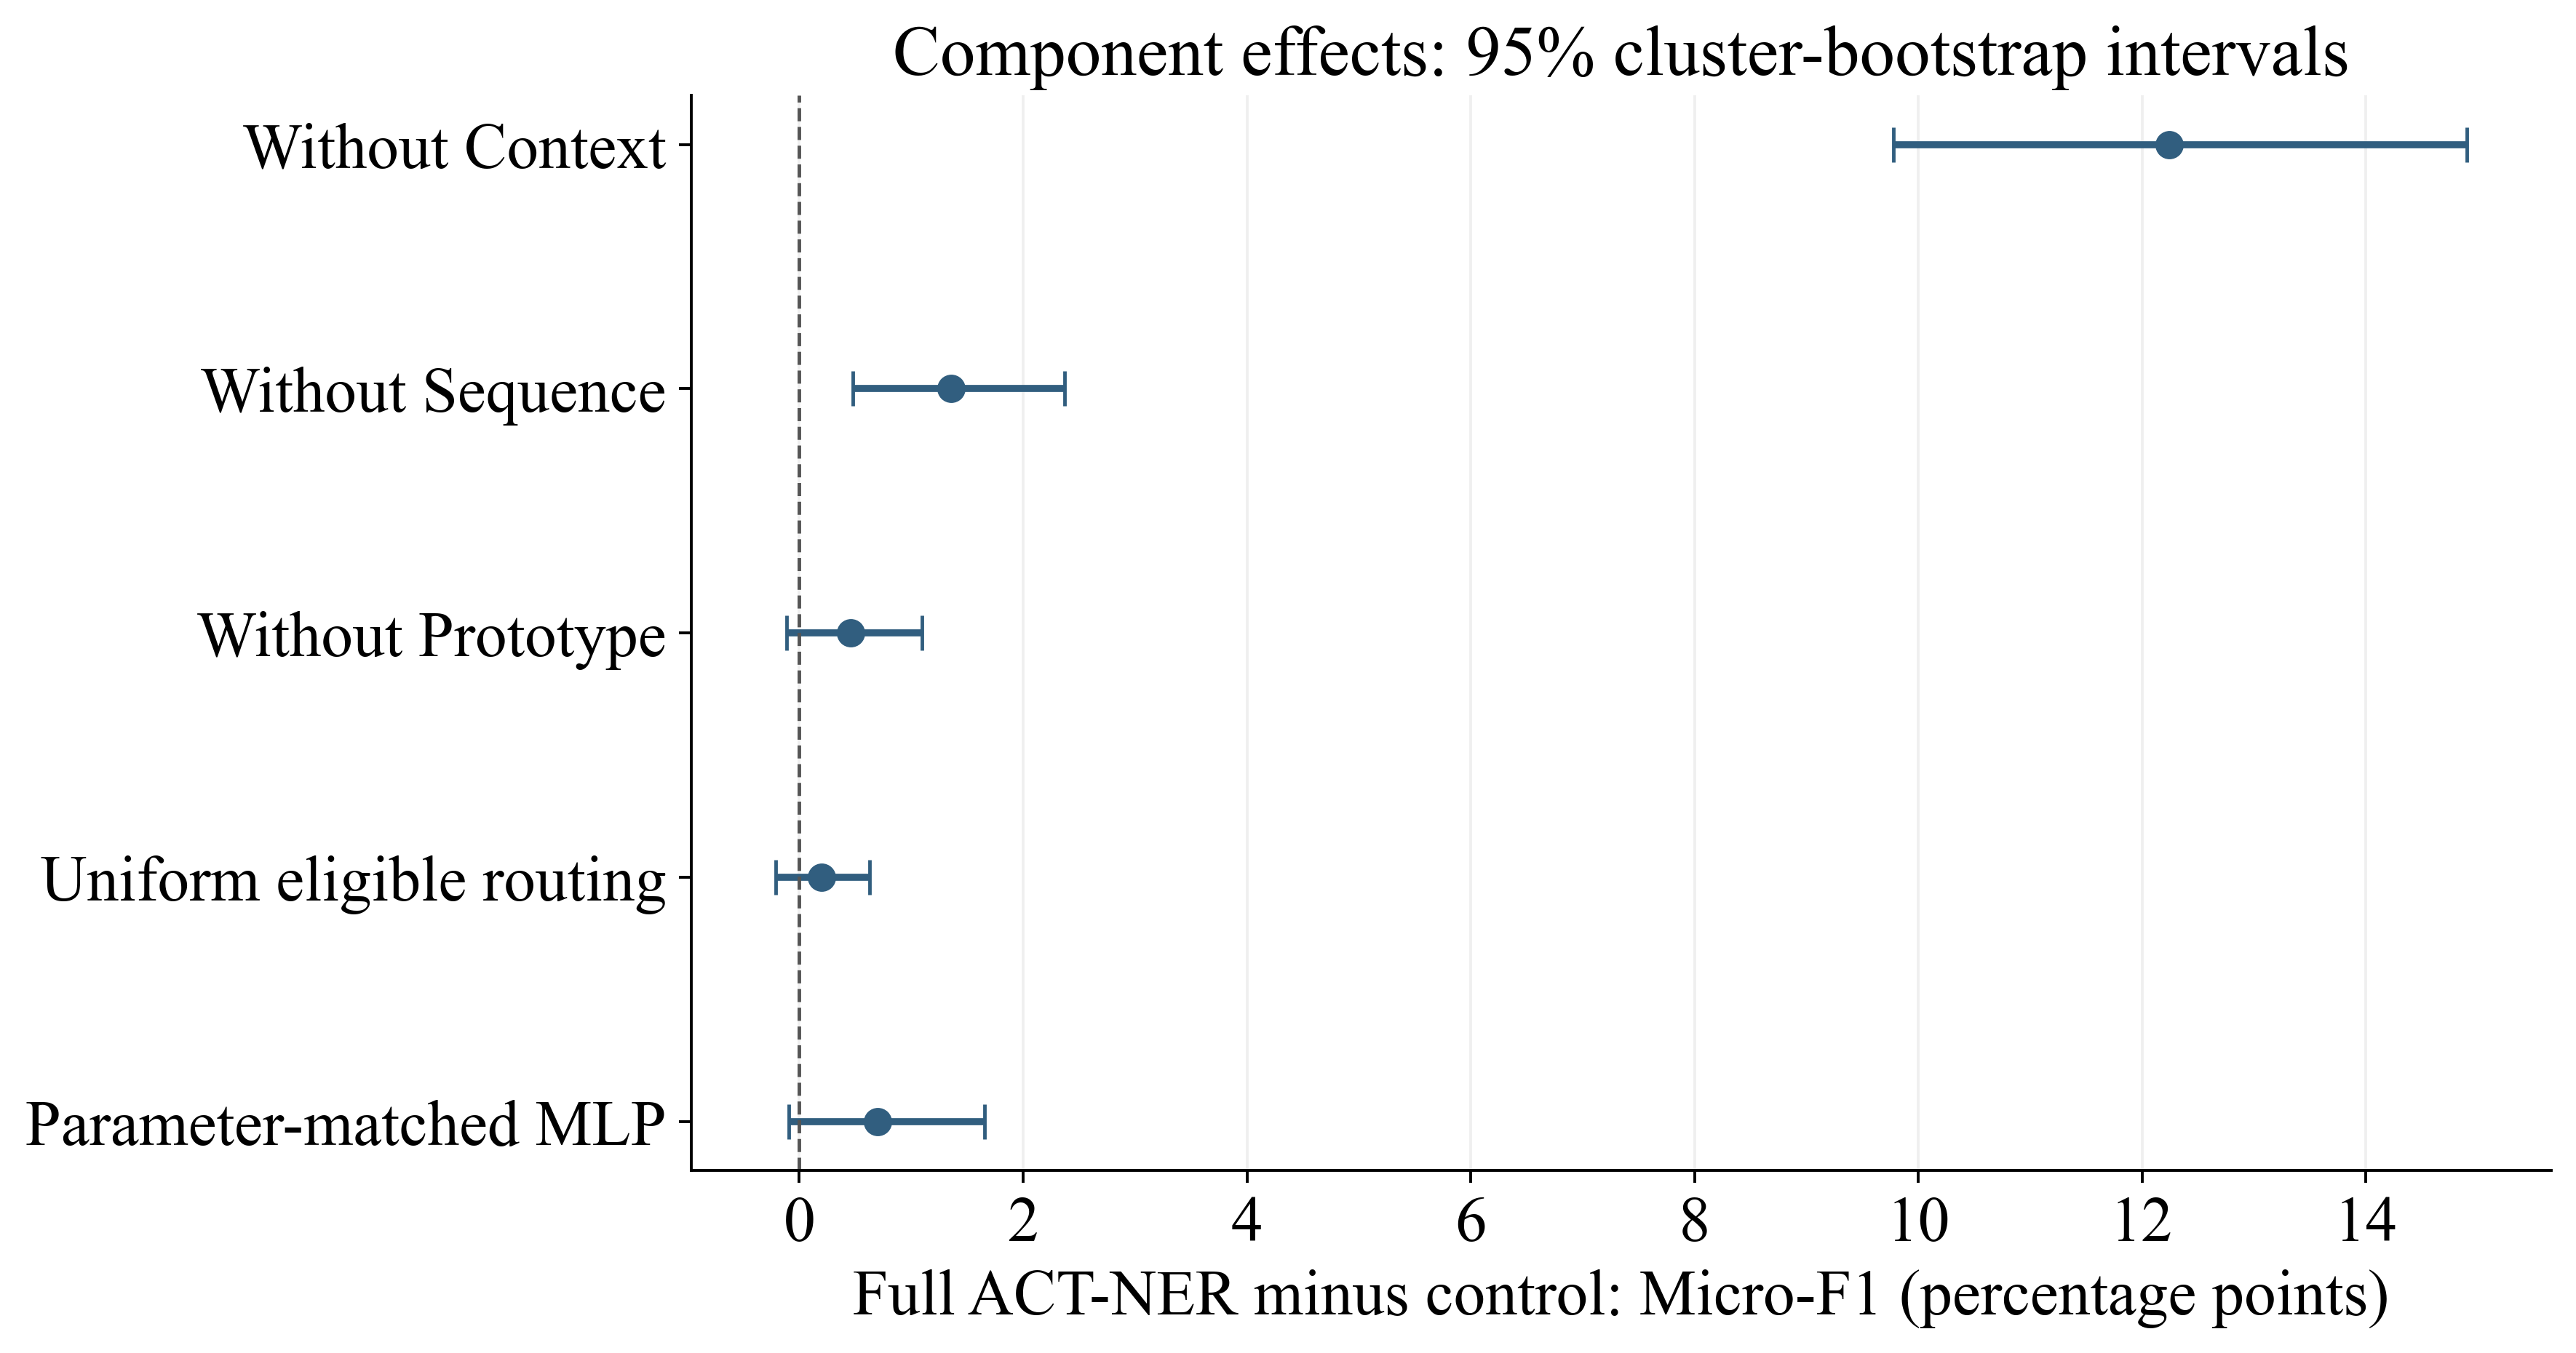

In [4]:
from PIL import Image as PILImage
plot_data = components["focus"].copy()
labels = ["Without Context", "Without Sequence", "Without Prototype",
          "Uniform eligible routing", "Parameter-matched MLP"]
effect = 100*plot_data["Micro-F1 difference"].to_numpy()
lower, upper = 100*plot_data["CI low"].to_numpy(), 100*plot_data["CI high"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 5.2), layout="constrained", dpi=350)
positions = np.arange(len(plot_data))
ax.errorbar(effect, positions, xerr=np.vstack([effect-lower, upper-effect]),
            fmt="o", capsize=5, color="#315E7F", markersize=7, linewidth=2)
ax.axvline(0, color="#555555", linestyle="--", linewidth=1)
ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.set_xlabel("Full ACT-NER minus control: Micro-F1 (percentage points)")
ax.set_title("Component effects: 95% cluster-bootstrap intervals")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=.2)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        assert label.get_fontfamily() == ["Times New Roman"]
figure_path = FIGURES/"r1_3_component_intervals.png"
fig.savefig(figure_path, dpi=350, bbox_inches="tight", pad_inches=.05)
with PILImage.open(figure_path) as exported:
    assert all(abs(value-350) < .02 for value in exported.info["dpi"])
plot_data.to_csv(TABLES/"r1_3_component_intervals_source.csv", index=False)
plt.show()
plt.close(fig)

## A04 – Statistical estimand and resampling protocol

Expose the executed statistical definitions, independence unit and seed aggregation.

In [5]:
show_table(components["protocol"])

Protocol element,Verified implementation
Population,142 Validation documents; 2915 eligible entities
Resampling unit,140 substantial-exact-text document dependency clusters
Document universe,"Explicit membership, including zero-gold and zero-prediction documents"
Strict typed match,"Same sentence ID, half-open character start/end and entity type"
Gold eligibility,Contiguous and offset_valid; raw entity rows are not the denominator
Corpus Micro-F1,2 * sum(TP) / (sum(gold) + sum(predictions)); not mean fold F1
Optimizer seed aggregation,"Compute corpus F1 separately at seeds17,29,43, then average the paired differences"
Partition repetition,"One fixed five-fold partition, seed1701; optimizer seeds are not new partitions"
Confidence interval,5000 cluster bootstrap replicates; shared resample across models and seeds; 2.5/97.5 percentiles
Primary p value,"5000 paired cluster label swaps, shared across seeds; two-sided (1 + exceedances) /5001"


**Interpretation.** Strict corpus Micro-F1 is calculated from pooled TP/gold/prediction counts within each seed, then paired differences are averaged across seeds. The same dependency-cluster draws and swap masks are shared across models and seeds. These intervals condition on fitted predictions; they do not resample the full training procedure.

## A05 – Stronger biomedical backbone: pinned provenance

Acquire a base-size biomedical encoder from its original publisher without modifying existing checkpoints.

In [6]:
from base_backbone import MODEL, REVISION, acquire_backbone, preflight
display(Markdown("**Acquisition:** BiomedBERT-base; publisher Microsoft; MIT model license. "
                 ""))
base_directory = acquire_backbone(ROOT)
base_provenance = pd.DataFrame([{"Model":MODEL, "Revision":REVISION,
    "Role":"Stronger biomedical encoder candidate", "Status":"Downloaded; not trained"}])
base_provenance.to_csv(TABLES/"stronger_backbone_provenance.csv", index=False)
show_table(base_provenance)

**Acquisition:** BiomedBERT-base; publisher Microsoft; MIT model license. 

Model,Revision,Role,Status
microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext,e1354b7a3a09615f6aba48dfad4b7a613eef7062,Stronger biomedical encoder candidate,Downloaded; not trained


**Rationale.** BiomedBERT-base is pretrained on PubMed abstracts and PMC full text. Availability and larger parameter count do not establish stronger downstream performance. [Publisher model card](https://huggingface.co/microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext).

## A06 – Independent-corpus selection and acquisition

Select a corpus with identifiable official splits and verifiable research-use rights.

In [7]:
import external_data as external_data
corpus_options = external_data.corpus_selection_evidence()
show_table(corpus_options)
display(Markdown("**Acquisition:** downloading the pinned BC5CDR archive; "
                 "the archive rights notice is retained with the original bytes."))
external_provenance = external_data.acquire_bc5cdr(ROOT)
external_provenance.to_csv(TABLES/"external_provenance.csv", index=False)
corpus_options.to_csv(TABLES/"external_corpus_selection.csv", index=False)
show_table(external_provenance[["Corpus","Official partitions","Rights evidence","Status"]])

Corpus,Annotation scope,Availability / rights,Decision,Source
BC5CDR,Chemical / Disease; 500/500/500 documents,Pinned public mirror; archive NCBI public-domain notice,Selected: manageable two-type architecture-transfer benchmark,https://pmc.ncbi.nlm.nih.gov/articles/PMC4860626/
CHEMDNER,Seven chemical mention-form classes; 10000 abstracts,Official corpus endpoint returned HTTP 403; no downloaded archive license verified,Considered; chemical-form classes do not equal DDI drug subtypes,https://pubmed.ncbi.nlm.nih.gov/25810773/
GutBrainIE 2025,13 entity types; multiple annotation-quality tiers,Public Zenodo; API CC-BY-4.0 vs rendered MIT metadata need reconciliation,Considered; broader schema/tier protocol would require a separate adaptation,https://zenodo.org/records/16845409


**Acquisition:** downloading the pinned BC5CDR archive; the archive rights notice is retained with the original bytes.

Corpus,Official partitions,Rights evidence,Status
BC5CDR,500 / 500 / 500,Archive NCBI public-domain notice,VERIFIED


## A07 – External annotation and official-split integrity

Retain Chemical/Disease labels and original half-open offsets without relabelling them as DDI subtypes.

In [8]:
external_integrity = external_data.prepare_bc5cdr(ROOT)
for name, frame in external_integrity.items():
    frame.to_csv(TABLES/f"external_{name}.csv", index=False)
    show_table(frame)

Split,Documents,Gold mentions,Overlapping gold pairs,Composite mention rows,Use
train,500,9385,0,89,Model development
validation,500,9591,0,89,Model development
test,500,9809,0,57,Final evaluation only


Split,Check,Observed,Expected,Status
train,Official document count,500,500,PASS
train,Unique PMID,500,500,PASS
train,Valid exact half-open offsets,9385,9385,PASS
train,Gold categories unchanged,"Chemical, Disease","Chemical, Disease",PASS
train,Duplicate typed spans,0,0,PASS
validation,Official document count,500,500,PASS
validation,Unique PMID,500,500,PASS
validation,Valid exact half-open offsets,9591,9591,PASS
validation,Gold categories unchanged,"Chemical, Disease","Chemical, Disease",PASS
validation,Duplicate typed spans,0,0,PASS


Corpus label,DDI equivalence,Reason,Protocol
Chemical,No one-to-one equivalence,Chemical scope is broader; drug/brand/group/drug_n are not supplied,Retain Chemical in an explicitly adapted output head
Disease,Outside original DDI label space,Original ACT-NER has no Disease class,Retain Disease; retrain applicable heads/experts on external Train only


## A08 – External independence and overlap checks

Check PMID and normalized text identity across official partitions and the entire local DDI corpus.

In [9]:
external_overlap = external_data.external_overlap_audit(ROOT)
for name, frame in external_overlap.items():
    frame.to_csv(TABLES/f"external_{name}.csv", index=False)
    if len(frame):
        show_table(frame)
    else:
        display(Markdown(f"**{name}:** no matching records under the declared checks."))

Split,Check,Observed,Expected,Status
train/validation,Cross-split PMID overlap,0,0,PASS
train/validation,Cross-split normalized document overlap,0,0,PASS
train/test,Cross-split PMID overlap,0,0,PASS
train/test,Cross-split normalized document overlap,0,0,PASS
validation/test,Cross-split PMID overlap,0,0,PASS
validation/test,Cross-split normalized document overlap,0,0,PASS
train,CDR documents matching DDI identity/text,0,0,PASS
validation,CDR documents matching DDI identity/text,0,0,PASS
test,CDR documents matching DDI identity/text,0,0,PASS


**overlap_reasons:** no matching records under the declared checks.

DDI documents checked,DDI PMID available,DDI PMID unavailable,Text rule,Limitation
1017,233,784,NFKC + casefold + whitespace; sentence containment >=40 chars and >=6 tokens,No claim of fuzzy-semantic or pretraining-corpus independence


## A09 – Independent biaffine NER: protocol and software checks

Freeze the annotation, fitting, selection and evaluation rules before the first new comparative fit.

In [10]:
import biaffine_span as span
software_checks = span.selftest()
show_table(software_checks)
span_protocol = span.freeze_protocol(ROOT)
span_corpus = span._corpus(str(ROOT))
span_coverage = pd.DataFrame([
    span.coverage(span_corpus, span_corpus.train_documents, "Original Train"),
    span.coverage(span_corpus, span_corpus.validation_documents, "Validation")])
span_coverage.to_csv(TABLES/"r1_4_span_coverage.csv", index=False)
show_table(span_coverage)
show_table(pd.DataFrame([{
    "Model": span.MODEL, "Seeds": "17, 29, 43", "Outer folds": 5,
    "Fitting": "Original Train + innerTrain", "Selection": "innerSelection only",
    "Candidate space": "All contiguous token spans; none + four types",
    "Head parameters": sum(p.numel() for p in span.BiaffineSpanNER().parameters()),
    "Status": "Protocol frozen"}]))

Synthetic software test,Status
Biaffine equals direct matrix products,PASS
All contiguous spans exactly once,PASS
None rejection and flat overlap decoding,PASS
Threshold rejection,PASS
Five-class differentiable loss,PASS
Cached all-span scoring equals pairwise forward,PASS
Inference independent of gold labels,PASS


Role,Documents,Sentences,Candidate spans,Gold entities,Representable gold,Unrepresentable gold retained,Candidate typed coverage
Original Train,572,5510,2668763,11812,11791,21,0.99822
Validation,142,1466,587126,2915,2906,9,0.99691


Model,Seeds,Outer folds,Fitting,Selection,Candidate space,Head parameters,Status
Independent biaffine NER (frozen backbone),"17, 29, 43",5,Original Train + innerTrain,innerSelection only,All contiguous token spans; none + four types,181765,Protocol frozen


**Comparison scope.** This model implements independent exhaustive span enumeration and class-specific biaffine boundary scoring, following the span-classification principle of [Yu et al. (ACL 2020)](https://aclanthology.org/2020.acl-main.577/). It is a controlled frozen-backbone variant, not a full reproduction of that paper. The head additionally uses original Train, whereas ACT-NER refinement uses innerTrain. Both inherit historical backbone-selection exposure to Validation. All unrepresentable gold spans remain in metric denominators.

## A10 – Biaffine fit – fold 1/5, seed 17

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [11]:
progress_view = display(Markdown("Preparing biaffine fold 1/5, seed 17."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=0, seed=17, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=0 · seed=17

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),1,17,1,0.40000,0.85581,0.82047,0.83776,0.87626,0.76451,Completed


## A11 – Biaffine fit – fold 1/5, seed 29

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [12]:
progress_view = display(Markdown("Preparing biaffine fold 1/5, seed 29."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=0, seed=29, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=0 · seed=29

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),1,29,2,0.50000,0.86705,0.80790,0.83643,0.87175,0.76303,Completed


## A12 – Biaffine fit – fold 1/5, seed 43

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [13]:
progress_view = display(Markdown("Preparing biaffine fold 1/5, seed 43."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=0, seed=43, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=0 · seed=43

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),1,43,3,0.40000,0.88148,0.85458,0.86782,0.89517,0.80810,Completed


## A13 – Biaffine fit – fold 2/5, seed 17

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [14]:
progress_view = display(Markdown("Preparing biaffine fold 2/5, seed 17."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=1, seed=17, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=1 · seed=17

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),2,17,6,0.40000,0.84701,0.80639,0.82621,0.89900,0.78165,Completed


## A14 – Biaffine fit – fold 2/5, seed 29

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [15]:
progress_view = display(Markdown("Preparing biaffine fold 2/5, seed 29."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=1, seed=29, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=1 · seed=29

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),2,29,1,0.40000,0.77757,0.75133,0.76423,0.85818,0.69048,Completed


## A15 – Biaffine fit – fold 2/5, seed 43

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [16]:
progress_view = display(Markdown("Preparing biaffine fold 2/5, seed 43."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=1, seed=43, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=1 · seed=43

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),2,43,6,0.25000,0.85178,0.80639,0.82847,0.90328,0.78719,Completed


## A16 – Biaffine fit – fold 3/5, seed 17

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [17]:
progress_view = display(Markdown("Preparing biaffine fold 3/5, seed 17."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=2, seed=17, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=2 · seed=17

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),3,17,6,0.40000,0.88300,0.86810,0.87548,0.90333,0.72675,Completed


## A17 – Biaffine fit – fold 3/5, seed 29

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [18]:
progress_view = display(Markdown("Preparing biaffine fold 3/5, seed 29."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=2, seed=29, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=2 · seed=29

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),3,29,3,0.25000,0.87421,0.85276,0.86335,0.90528,0.70695,Completed


## A18 – Biaffine fit – fold 3/5, seed 43

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [19]:
progress_view = display(Markdown("Preparing biaffine fold 3/5, seed 43."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=2, seed=43, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=2 · seed=43

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),3,43,1,0.40000,0.88889,0.82209,0.85418,0.87649,0.70292,Completed


## A19 – Biaffine fit – fold 4/5, seed 17

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [20]:
progress_view = display(Markdown("Preparing biaffine fold 4/5, seed 17."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=3, seed=17, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=3 · seed=17

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),4,17,6,0.40000,0.81888,0.79064,0.80451,0.85714,0.60683,Completed


## A20 – Biaffine fit – fold 4/5, seed 29

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [21]:
progress_view = display(Markdown("Preparing biaffine fold 4/5, seed 29."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=3, seed=29, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=3 · seed=29

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),4,29,6,0.50000,0.85224,0.79557,0.82293,0.85605,0.59900,Completed


## A21 – Biaffine fit – fold 4/5, seed 43

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [22]:
progress_view = display(Markdown("Preparing biaffine fold 4/5, seed 43."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=3, seed=43, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=3 · seed=43

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),4,43,4,0.40000,0.80344,0.80542,0.80443,0.87085,0.60381,Completed


## A22 – Biaffine fit – fold 5/5, seed 17

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [23]:
progress_view = display(Markdown("Preparing biaffine fold 5/5, seed 17."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=4, seed=17, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=4 · seed=17

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),5,17,4,0.50000,0.89692,0.79104,0.84066,0.87671,0.76161,Completed


## A23 – Biaffine fit – fold 5/5, seed 29

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [24]:
progress_view = display(Markdown("Preparing biaffine fold 5/5, seed 29."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=4, seed=29, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=4 · seed=29

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),5,29,4,0.50000,0.88175,0.81954,0.84951,0.88186,0.80014,Completed


## A24 – Biaffine fit – fold 5/5, seed 43

Train a new independent span model; choose epoch and threshold only on the permitted innerSelection documents.

In [25]:
progress_view = display(Markdown("Preparing biaffine fold 5/5, seed 43."), display_id=True)
def span_progress(event):
    stage = event["stage"]
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key, value in event.items()
        if key not in {"model", "stage"})
    progress_view.update(Markdown(f"**{event['model']} – {stage}**  \n{detail}"))
span_result = span.oneunit(ROOT, fold=4, seed=43, progress=span_progress)
show_table(pd.DataFrame([{
    "Model": span_result["model"], "Fold": span_result["fold"] + 1,
    "Seed": span_result["seed"], "Selected epoch": span_result["selected_epoch"],
    "Threshold": span_result["threshold"],
    "Typed Precision": span_result["metrics"]["typed_precision"],
    "Typed Recall": span_result["metrics"]["typed_recall"],
    "Typed F1": span_result["metrics"]["typed_f1"],
    "Boundary F1": span_result["metrics"]["boundary_f1"],
    "Macro-F1": span_result["metrics"]["macro_f1"], "Status": "Completed"}]))

**Independent biaffine NER (frozen backbone) – existing unit**  
fold=4 · seed=43

Model,Fold,Seed,Selected epoch,Threshold,Typed Precision,Typed Recall,Typed F1,Boundary F1,Macro-F1,Status
Independent biaffine NER (frozen backbone),5,43,4,0.50000,0.88358,0.80326,0.84151,0.88131,0.79158,Completed


## A25 – Independent span comparison: pooled evidence

Combine disjoint outer-fold predictions for each seed and recompute paired document-cluster comparisons without treating seeds as independent documents.

In [26]:
span_tables = span.aggregate(ROOT)
for name, frame in span_tables.items():
    frame.to_csv(TABLES/f"r1_4_span_{name}.csv", index=False)
quality = span_tables["summary"]
show_table(quality[["Model", "N documents", "Clusters", "N gold", "Seeds",
                   "Typed F1 mean", "Typed F1 SD", "Typed F1 CI low", "Typed F1 CI high"]])
show_table(quality[["Model", "Boundary F1 mean", "Boundary F1 SD", "Macro-F1 mean", "Macro-F1 SD"]])
class_results = span_tables["classwise"].groupby(["Model", "Type"]).F1.agg(["mean", "std"]).reset_index()
show_table(class_results.rename(columns={"mean":"F1 mean", "std":"F1 SD"}))
show_table(span_tables["statistics"].drop(columns=["Mean cluster F1 difference", "Wilcoxon p", "Rank-biserial effect", "Wilcoxon Holm p"], errors="ignore"))
efficiency = span_tables["units"].groupby("model").agg(
    Fits=("seed", "size"), Training_seconds=("training_seconds_including_selection", "sum"),
    Head_inference_seconds=("head_inference_seconds_including_decode", "sum"),
    Trainable_parameters=("trainable_parameters", "max")).reset_index()
show_table(efficiency)

Model,N documents,Clusters,N gold,Seeds,Typed F1 mean,Typed F1 SD,Typed F1 CI low,Typed F1 CI high
Independent biaffine NER (frozen backbone),142,140,2915,3,0.83720,0.00638,0.81232,0.85880
Full ACT-NER,142,140,2915,3,0.90932,0.00257,0.88580,0.92908
Parameter-matched span MLP,142,140,2915,3,0.90229,0.00383,0.87743,0.92341


Model,Boundary F1 mean,Boundary F1 SD,Macro-F1 mean,Macro-F1 SD
Independent biaffine NER (frozen backbone),0.88234,0.00461,0.75653,0.01775
Full ACT-NER,0.94343,0.00173,0.82207,0.00999
Parameter-matched span MLP,0.94441,0.00060,0.80720,0.00847


Model,Type,F1 mean,F1 SD
Full ACT-NER,brand_f1,0.91030,0.01266
Full ACT-NER,drug_f1,0.93981,0.00163
Full ACT-NER,drug_n_f1,0.57045,0.06052
Full ACT-NER,group_f1,0.86770,0.01256
Independent biaffine NER (frozen backbone),brand_f1,0.83103,0.03796
Independent biaffine NER (frozen backbone),drug_f1,0.86893,0.00336
Independent biaffine NER (frozen backbone),drug_n_f1,0.52514,0.03094
Independent biaffine NER (frozen backbone),group_f1,0.80104,0.01307
Parameter-matched span MLP,brand_f1,0.88756,0.01652
Parameter-matched span MLP,drug_f1,0.93601,0.00317


Comparison,N documents,Clusters,Micro-F1 difference,CI low,CI high,Paired randomization p,Mean cluster-F1 difference,Micro-F1 Holm p
Full ACT-NER − Independent biaffine NER (frozen backbone),142,140,0.07212,0.05551,0.09077,0.00020,0.07364,0.00040
Parameter-matched span MLP − Independent biaffine NER (frozen backbone),142,140,0.06509,0.04442,0.08683,0.00020,0.06909,0.00040


model,Fits,Training_seconds,Head_inference_seconds,Trainable_parameters
Independent biaffine NER (frozen backbone),15,512.76093,5.33712,181765


## A26 – Independent span comparison: effect intervals

Visualize the paired typed Micro-F1 differences on their original statistical scale.

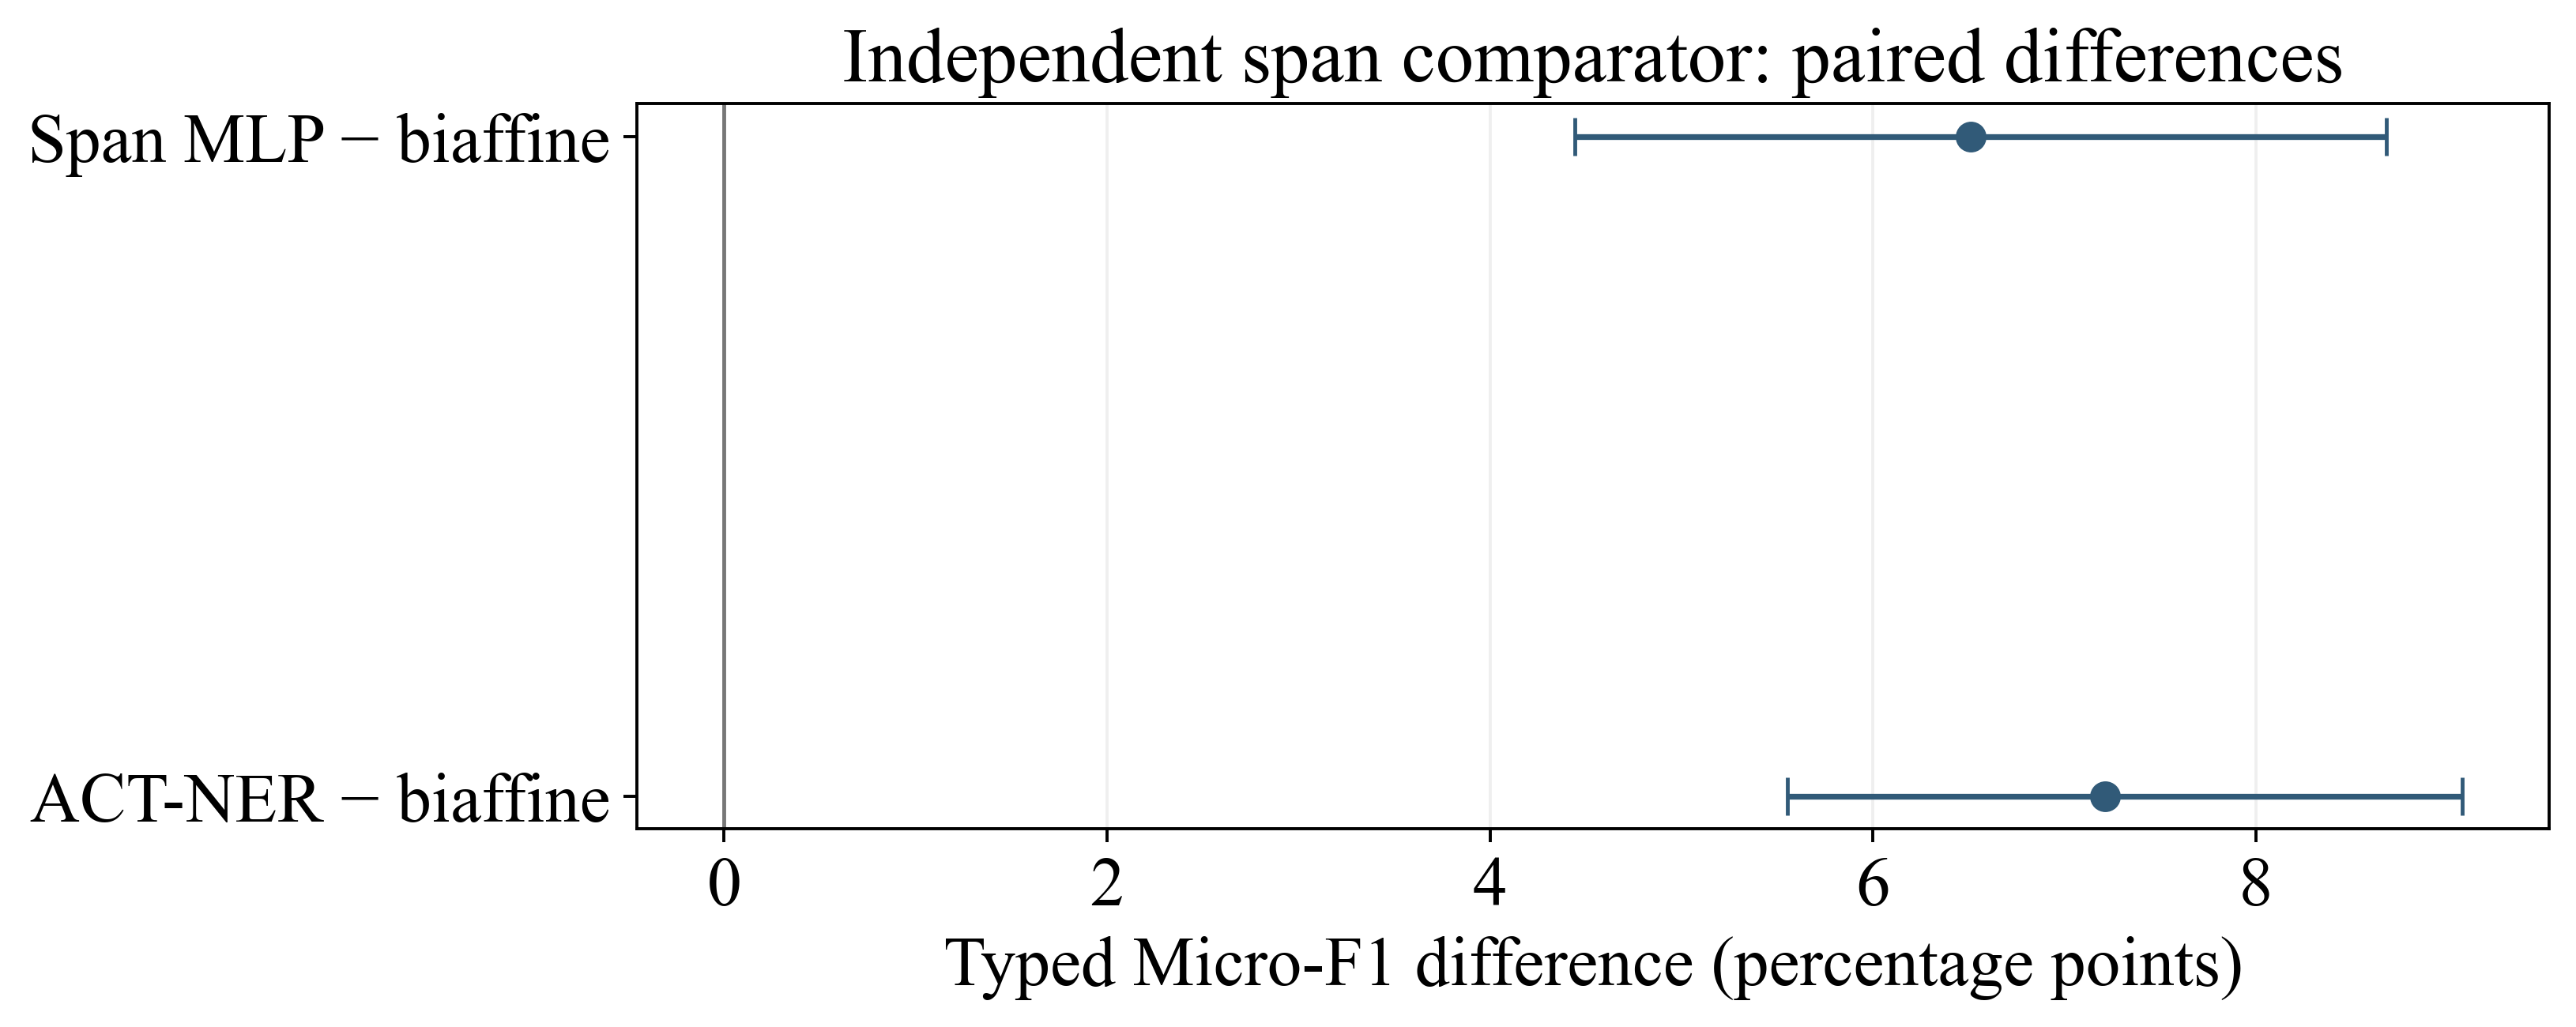

**Interpretation.** The paired conditional comparison supports a positive ACT-NER effect. This evidence is limited to the specified frozen-backbone variant and this Validation protocol; it is not a universal comparison against all span-based NER systems.

In [27]:
effect = span_tables["statistics"].copy()
effect.to_csv(TABLES/"figure_r1_4_span_effects_data.csv", index=False)
fig, ax = plt.subplots(figsize=(9.2, 3.6), layout="constrained")
values = effect["Micro-F1 difference"].to_numpy() * 100
low, high = effect["CI low"].to_numpy()*100, effect["CI high"].to_numpy()*100
positions = np.arange(len(effect))
ax.errorbar(values, positions, xerr=np.vstack([values-low, high-values]),
            fmt="o", color="#315a78", capsize=5, markersize=7)
ax.axvline(0, color="#777777", linewidth=1)
ax.set_yticks(positions, ["ACT-NER − biaffine", "Span MLP − biaffine"])
ax.set_xlabel("Typed Micro-F1 difference (percentage points)")
ax.set_title("Independent span comparator: paired differences")
ax.grid(axis="x", alpha=.2)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        assert label.get_fontfamily() == ["Times New Roman"]
fig.savefig(FIGURES/"r1_4_span_effects.png", dpi=350, facecolor="white")
fig.savefig(FIGURES/"r1_4_span_effects.pdf", dpi=350, facecolor="white")
plt.show()
comparison = effect.iloc[0]
positive = comparison["CI low"] > 0 and comparison["Micro-F1 Holm p"] < .05
display(Markdown("**Interpretation.** " +
    ("The paired conditional comparison supports a positive ACT-NER effect." if positive else
     "A positive ACT-NER effect is not established by this paired conditional comparison.") +
    " This evidence is limited to the specified frozen-backbone variant and this Validation protocol; it is not a universal comparison against all span-based NER systems."))

## A27 – External architecture transfer: roles and frozen protocol

Register the two-type experiment after label-free cross-split sentence screening and before any fitting.

In [28]:
import external_model as external
from external_checks import selftest as external_software_checks
from IPython.display import HTML
display(HTML("<style>table[id^='T_']{width:100%;}table[id^='T_'] th,table[id^='T_'] td{padding:2px 3px!important;overflow-wrap:anywhere;}</style>"))
def show_table(frame, precision=5):
    identifiers = [c for c in ("Model", "Reference", "Comment", "Role", "Seed", "Fold") if c in frame][:2]
    remaining = [c for c in frame if c not in identifiers]
    groups = [remaining[i:i+5] for i in range(0, len(remaining), 5)] or [[]]
    for columns in groups:
        display(frame[identifiers+columns].style.format(precision=precision, na_rep="Not available")
            .hide(axis="index").set_properties(**{"font-family":"Times New Roman", "font-size":"18px",
                "white-space":"normal", "text-align":"left"})
            .set_table_styles([{"selector":"th", "props":[("font-family","Times New Roman"),
                ("font-size","18px"),("text-align","left")]}]))
checks = external_software_checks()
show_table(checks)
external_protocol, external_roles = external.prepare_external_protocol(ROOT)
external_roles.to_csv(TABLES/"r1_2_adaptive_roles.csv", index=False)
quarantine = pd.DataFrame(external_protocol["development_exclusions"])
quarantine.to_csv(TABLES/"r1_2_development_quarantine.csv", index=False)
show_table(external_roles)
show_table(quarantine)
assert {k:len(v) for k,v in external_protocol["roles"].items()} == {"train":500,"selection":249,"calibration":250}
display(Markdown("**Adaptation scope.** " + external_protocol["architecture_adaptation"] +
    " The original four-type ACT-NER is not refitted. Shared contextual features remain frozen. "
    "The official Test population is unchanged; its labels do not enter training, selection or calibration."))

Check,Status,Evidence type
Candidate features independent of evaluation gold,PASS,Synthetic software invariant; not biomedical performance
Trainable router receives gradient,PASS,Synthetic software invariant; not biomedical performance
Trainable prototypes receive gradient,PASS,Synthetic software invariant; not biomedical performance
Context gradient remains finite,PASS,Synthetic software invariant; not biomedical performance
Sparse routing has at most two active experts,PASS,Synthetic software invariant; not biomedical performance
Sparse weights sum to one,PASS,Synthetic software invariant; not biomedical performance
Easy spans mask the prototype route,PASS,Synthetic software invariant; not biomedical performance
Expert membership never overrides the learned verifier,PASS,Synthetic software invariant; not biomedical performance
Exact-boundary flat ceiling retains full gold denominator,PASS,Synthetic software invariant; not biomedical performance
Zero-gold documents remain independent resampling units,PASS,Synthetic software invariant; not biomedical performance


Role,Documents
train,500
selection,249
calibration,250
Development quarantined from adaptive roles,1
Official external Test (not used for selection),500


document_id,dependency_group,Official split,Excluded roles,Reason
19370593,16034922,validation,Selection and Calibration,Shared substantial exact sentence component with Test


**Adaptation scope.** New Chemical/Disease BIOES-9 contextual head and CRF; 1920-to-128 context projection; conditional two-prototype contrastive expert; top-2 span router; residual verifier/type heads. No DrugBank/MedLine domain embedding, continual adapter, or inherited four-type head is transferred. The original four-type ACT-NER is not refitted. Shared contextual features remain frozen. The official Test population is unchanged; its labels do not enter training, selection or calibration.

## A28 – Frozen context representations – train

Compute shared frozen biomedical representations with overlapping windows, preserving original offsets and all gold spans.

In [29]:
external_progress_view = display(Markdown("Preparing external train context."), display_id=True)
def external_progress(event):
    details = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key,value in event.items() if key != "stage")
    external_progress_view.update(Markdown(f"**{event['stage']}**  \n{details}"))
external_train_features = external.prepare_external_features(ROOT, "train", progress=external_progress)
_, external_gold = external._load_split(ROOT, "train", annotations=True)
representation = external.external_representation_audit(external_train_features, external_gold)
representation.to_csv(TABLES/"r1_2_train_representation.csv", index=False)
show_table(pd.DataFrame([{"Split":"train", "Documents":len(representation),
    **{column:int(representation[column].sum()) for column in ("Gold entities", "Exact token-boundary entities",
        "Maximum flat aligned entities", "Tokens", "Zero-gold document")}}]))

**Frozen biomedical features**  
split=train · completed=500 · total=500

Split,Documents,Gold entities,Exact token-boundary entities,Maximum flat aligned entities
train,500,9385,9385,9385


Tokens,Zero-gold document
125899,0


## A29 – Frozen context representations – validation

Compute shared frozen biomedical representations with overlapping windows, preserving original offsets and all gold spans.

In [30]:
external_progress_view = display(Markdown("Preparing external validation context."), display_id=True)
def external_progress(event):
    details = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key,value in event.items() if key != "stage")
    external_progress_view.update(Markdown(f"**{event['stage']}**  \n{details}"))
external_dev_features = external.prepare_external_features(ROOT, "validation", progress=external_progress)
_, external_gold = external._load_split(ROOT, "validation", annotations=True)
representation = external.external_representation_audit(external_dev_features, external_gold)
representation.to_csv(TABLES/"r1_2_validation_representation.csv", index=False)
show_table(pd.DataFrame([{"Split":"validation", "Documents":len(representation),
    **{column:int(representation[column].sum()) for column in ("Gold entities", "Exact token-boundary entities",
        "Maximum flat aligned entities", "Tokens", "Zero-gold document")}}]))

**Frozen biomedical features**  
split=validation · completed=500 · total=500

Split,Documents,Gold entities,Exact token-boundary entities,Maximum flat aligned entities
validation,500,9591,9589,9589


Tokens,Zero-gold document
125326,0


## A30 – External contextual and sequence experts – OOF fold 1/3

Fit new Chemical/Disease experts on the registered Train documents; use Selection only for contextual-head early stopping.

In [31]:
external_progress_view = display(Markdown("Preparing OOF fold 1/3."), display_id=True)
expert_record, expert_history = external.fit_external_expert_unit(ROOT,
    external_train_features, external_dev_features, fold=0, progress=external_progress)
show_table(expert_history)
show_table(pd.DataFrame([{"Model":"External contextual head + Linear-chain CRF", "Fold":"OOF fold 1/3",
    "Seed":expert_record["seed"], "Fit documents":len(expert_record["fit_documents"]),
    "Selection documents":len(expert_record["selection_documents"]),
    "Contextual parameters":expert_record["contextual_parameters"], "CRF parameters":expert_record["crf_parameters"],
    "Training seconds":expert_record["training_seconds"], "Status":"Completed and sealed"}]))

**External CRF fitting**  
model=crossfit_0 · seed=17 · fold=0 · documents=333

Epoch,Loss,Selection Typed F1
1,2.60557,0.44853
2,0.83725,0.56891
3,0.59899,0.62357
4,0.50368,0.64874
5,0.45046,0.66767
6,0.41516,0.67763
7,0.39067,0.69212
8,0.37151,0.68178
9,0.35600,0.70258
10,0.34259,0.69792


Model,Seed,Fold,Fit documents,Selection documents,Contextual parameters,CRF parameters
External contextual head + Linear-chain CRF,17,OOF fold 1/3,333,249,3465,21016


Model,Seed,Training seconds,Status
External contextual head + Linear-chain CRF,17,7.29995,Completed and sealed


## A31 – External contextual and sequence experts – OOF fold 2/3

Fit new Chemical/Disease experts on the registered Train documents; use Selection only for contextual-head early stopping.

In [32]:
external_progress_view = display(Markdown("Preparing OOF fold 2/3."), display_id=True)
expert_record, expert_history = external.fit_external_expert_unit(ROOT,
    external_train_features, external_dev_features, fold=1, progress=external_progress)
show_table(expert_history)
show_table(pd.DataFrame([{"Model":"External contextual head + Linear-chain CRF", "Fold":"OOF fold 2/3",
    "Seed":expert_record["seed"], "Fit documents":len(expert_record["fit_documents"]),
    "Selection documents":len(expert_record["selection_documents"]),
    "Contextual parameters":expert_record["contextual_parameters"], "CRF parameters":expert_record["crf_parameters"],
    "Training seconds":expert_record["training_seconds"], "Status":"Completed and sealed"}]))

**External CRF fitting**  
model=crossfit_1 · seed=17 · fold=1 · documents=333

Epoch,Loss,Selection Typed F1
1,2.59030,0.42832
2,0.84075,0.56437
3,0.62027,0.62092
4,0.53565,0.64382
5,0.48222,0.66572
6,0.45120,0.67160
7,0.42185,0.68550
8,0.40595,0.68571
9,0.39069,0.69872
10,0.37141,0.69654


Model,Seed,Fold,Fit documents,Selection documents,Contextual parameters,CRF parameters
External contextual head + Linear-chain CRF,17,OOF fold 2/3,333,249,3465,21626


Model,Seed,Training seconds,Status
External contextual head + Linear-chain CRF,17,7.30571,Completed and sealed


## A32 – External contextual and sequence experts – OOF fold 3/3

Fit new Chemical/Disease experts on the registered Train documents; use Selection only for contextual-head early stopping.

In [33]:
external_progress_view = display(Markdown("Preparing OOF fold 3/3."), display_id=True)
expert_record, expert_history = external.fit_external_expert_unit(ROOT,
    external_train_features, external_dev_features, fold=2, progress=external_progress)
show_table(expert_history)
show_table(pd.DataFrame([{"Model":"External contextual head + Linear-chain CRF", "Fold":"OOF fold 3/3",
    "Seed":expert_record["seed"], "Fit documents":len(expert_record["fit_documents"]),
    "Selection documents":len(expert_record["selection_documents"]),
    "Contextual parameters":expert_record["contextual_parameters"], "CRF parameters":expert_record["crf_parameters"],
    "Training seconds":expert_record["training_seconds"], "Status":"Completed and sealed"}]))

**External CRF fitting**  
model=crossfit_2 · seed=17 · fold=2 · documents=334

Epoch,Loss,Selection Typed F1
1,2.59523,0.42723
2,0.83790,0.57621
3,0.61068,0.61644
4,0.51840,0.64457
5,0.46169,0.66465
6,0.42655,0.67388
7,0.40093,0.68566
8,0.38050,0.68243
9,0.36677,0.69393
10,0.35196,0.69354


Model,Seed,Fold,Fit documents,Selection documents,Contextual parameters,CRF parameters
External contextual head + Linear-chain CRF,17,OOF fold 3/3,334,249,3465,21509


Model,Seed,Training seconds,Status
External contextual head + Linear-chain CRF,17,7.67322,Completed and sealed


## A33 – External contextual and sequence experts – full official Train

Fit new Chemical/Disease experts on the registered Train documents; use Selection only for contextual-head early stopping.

In [34]:
external_progress_view = display(Markdown("Preparing full official Train."), display_id=True)
expert_record, expert_history = external.fit_external_expert_unit(ROOT,
    external_train_features, external_dev_features, fold=None, progress=external_progress)
show_table(expert_history)
show_table(pd.DataFrame([{"Model":"External contextual head + Linear-chain CRF", "Fold":"full official Train",
    "Seed":expert_record["seed"], "Fit documents":len(expert_record["fit_documents"]),
    "Selection documents":len(expert_record["selection_documents"]),
    "Contextual parameters":expert_record["contextual_parameters"], "CRF parameters":expert_record["crf_parameters"],
    "Training seconds":expert_record["training_seconds"], "Status":"Completed and sealed"}]))

**External CRF fitting**  
model=full · seed=17 · fold=None · documents=500

Epoch,Loss,Selection Typed F1
1,2.06507,0.56281
2,0.65410,0.61750
3,0.50505,0.65671
4,0.44142,0.67491
5,0.40290,0.68790
6,0.37819,0.68690
7,0.35969,0.70058
8,0.34497,0.70102
9,0.33314,0.69826
10,0.32291,0.70833


Model,Seed,Fold,Fit documents,Selection documents,Contextual parameters,CRF parameters
External contextual head + Linear-chain CRF,17,full official Train,500,249,3465,27046


Model,Seed,Training seconds,Status
External contextual head + Linear-chain CRF,17,11.60305,Completed and sealed


## A34 – Cross-fitted external candidate evidence

Build ACT-NER training candidates using experts that did not fit the candidate document; derive lexical reliability only from the corresponding fold-training labels.

In [35]:
external_progress_view = display(Markdown("Constructing external OOF candidates."), display_id=True)
external_candidates, external_coverage = external.prepare_external_candidate_sets(
    ROOT, external_train_features, external_dev_features, progress=external_progress)
external_coverage.to_csv(TABLES/"r1_2_candidate_coverage.csv", index=False)
show_table(external_coverage)
for role, group in external_coverage.groupby("Role"):
    union = group.loc[group.Source.eq("Candidate union"), "Candidate recall"].iloc[0]
    assert union >= group["Candidate recall"].max() - 1e-12
display(Markdown("**Note:** the candidate union retains all expert boundaries; no gold-only candidate is injected."))

**External OOF candidate construction**  
fold=2 · completed=3 · total=3

Role,Source,Gold boundaries,Candidates,Candidate recall
train,Transformer candidates,9385,12720,0.80810
train,CRF candidates,9385,7285,0.65093
train,Candidate union,9385,81228,0.94331
selection,Transformer candidates,4826,6676,0.85454
selection,CRF candidates,4826,4081,0.74264
selection,Candidate union,4826,42284,0.96726
calibration,Transformer candidates,4740,6698,0.83629
calibration,CRF candidates,4740,3978,0.70907
calibration,Candidate union,4740,42846,0.95549


**Note:** the candidate union retains all expert boundaries; no gold-only candidate is injected.

## A35 – Fit the two-type conditional ACT-NER and freeze

Fit the verifier, type classifier, conditional experts and sparse router on cross-fitted Train candidates; select on Selection and calibrate only after freezing predictive weights.

In [36]:
external_progress_view = display(Markdown("Training the external ACT-NER adaptation."), display_id=True)
external_history, external_freeze_table = external.fit_external_act(
    ROOT, external_candidates, progress=external_progress)
external_history.to_csv(TABLES/"r1_2_act_learning.csv", index=False)
external_freeze_table.to_csv(TABLES/"r1_2_freeze_summary.csv", index=False)
show_table(external_history)
show_table(external_freeze_table)
external_seal = external.verify_external_freeze(ROOT)
assert not external_seal["test_used_for_selection"]

**External ACT-NER architecture transfer**  
seed=17 · epoch=6 · typed_f1=0.85233

Epoch,Loss,Selection Typed F1,Threshold
1,0.48079,0.86182,0.60000
2,0.30592,0.86545,0.70000
3,0.28513,0.87390,0.50000
4,0.27682,0.86983,0.70000
5,0.26607,0.86426,0.70000
6,0.25672,0.85233,0.50000


Model,Seed,Threshold,Temperature,Trainable parameters,Status
ACT-NER (two-type architecture transfer),17,0.50000,1.22039,353290,Frozen before external Test


## A36 – Frozen external Test encoding

Open Test text for frozen inference only after verifying the model, threshold and calibrator seal.

In [37]:
external.verify_external_freeze(ROOT)
external_progress_view = display(Markdown("Frozen Test inference: encoding official BC5CDR Test."), display_id=True)
external_test_features = external.prepare_external_features(ROOT, "test", progress=external_progress)
show_table(pd.DataFrame([{"Split":"Official BC5CDR Test", "Documents":len(external_test_features),
    "Encoded tokens":sum(len(v["offsets"]) for v in external_test_features.values()),
    "Parameter updates":0, "Status":"Frozen encoding complete"}]))

**Frozen biomedical features**  
split=test · completed=500 · total=500

Split,Documents,Encoded tokens,Parameter updates,Status
Official BC5CDR Test,500,133107,0,Frozen encoding complete


## A37 – Independent corpus: frozen recognition results

Generate predictions with all three frozen systems before scoring against official Test gold.

In [38]:
external_progress_view = display(Markdown("Evaluating frozen external systems."), display_id=True)
external_result = external.evaluate_external_frozen(ROOT, external_test_features, progress=external_progress)
for name in ("metrics", "coverage", "representation"):
    external_result[name].to_csv(TABLES/f"r1_2_test_{name}.csv", index=False)
show_table(external_result["metrics"])
show_table(external_result["coverage"])
representation = external_result["representation"]
show_table(pd.DataFrame([{"Split":"Official Test", "Documents":len(representation),
    **{column:int(representation[column].sum()) for column in ("Gold entities", "Exact token-boundary entities",
        "Maximum flat aligned entities", "Zero-gold document")}}]))
display(Markdown("**Evaluation scope.** Chemical/Disease architecture transfer, one prespecified optimizer seed. "
    "The full official Test gold denominator is retained. These are not zero-shot four-type DDI scores."))

**External frozen evaluation complete**  
seed=17 · documents=500 · models=3

Model,Seed,Gold entities,Predicted entities,Typed precision,Typed recall,Typed F1
ACT-NER architecture transfer,17,9809,9520,0.86113,0.83576,0.84826
Contextual BIOES,17,9809,14121,0.57893,0.83342,0.68324
Linear-chain CRF,17,9809,8183,0.84639,0.70609,0.76990


Model,Seed,Boundary F1,Macro-F1,Chemical F1,Disease F1
ACT-NER architecture transfer,17,0.85167,0.84100,0.90255,0.77945
Contextual BIOES,17,0.68934,0.68166,0.79967,0.56366
Linear-chain CRF,17,0.77390,0.76774,0.79481,0.74067


Source,Gold boundaries,Candidate recall
Transformer,9809,0.84086
CRF,9809,0.70976
Candidate union,9809,0.96259


Split,Documents,Gold entities,Exact token-boundary entities,Maximum flat aligned entities
Official Test,500,9809,9805,9805


Zero-gold document
0


**Evaluation scope.** Chemical/Disease architecture transfer, one prespecified optimizer seed. The full official Test gold denominator is retained. These are not zero-shot four-type DDI scores.

## A38 – External corpus: paired cluster inference

Estimate Test uncertainty and compare adapted ACT-NER with its independently trained contextual and CRF baselines using the same document clusters.

In [39]:
external_statistics = external.external_cluster_statistics(external_result)
for name, frame in external_statistics.items():
    frame.to_csv(TABLES/f"r1_2_{name}.csv", index=False)
    show_table(frame)
supported = external_statistics["comparisons"]["Statistically supported ACT gain"].sum()
display(Markdown(f"**Result:** a positive adapted ACT-NER gain is statistically supported in {supported} "
    "of the two prespecified comparisons. The intervals quantify Test-cluster sampling uncertainty conditional on seed 17; "
    "they do not establish optimizer-seed stability."))

Model,Metric,Estimate,CI lower,CI upper,Documents
ACT-NER architecture transfer,Typed F1,0.84826,0.83740,0.85880,500
ACT-NER architecture transfer,Boundary F1,0.85167,0.84093,0.86199,500
Contextual BIOES,Typed F1,0.68324,0.66906,0.69724,500
Contextual BIOES,Boundary F1,0.68934,0.67558,0.70287,500
Linear-chain CRF,Typed F1,0.76990,0.75532,0.78420,500
Linear-chain CRF,Boundary F1,0.77390,0.75953,0.78803,500


Model,Independent clusters
ACT-NER architecture transfer,499
ACT-NER architecture transfer,499
Contextual BIOES,499
Contextual BIOES,499
Linear-chain CRF,499
Linear-chain CRF,499


Reference,Comparator,Delta Typed F1,CI lower,CI upper,Paired p
ACT-NER architecture transfer,Contextual BIOES,0.16502,0.15490,0.17528,0.00020
ACT-NER architecture transfer,Linear-chain CRF,0.07836,0.06547,0.09159,0.00020


Reference,Holm p (2 comparisons),Statistically supported ACT gain
ACT-NER architecture transfer,0.00040,True
ACT-NER architecture transfer,0.00040,True


Resampling unit,Documents,Clusters,Optimizer seeds,Resampling random seed
Transitive substantial-exact-text document cluster,500,499,1,9017


Bootstrap,Paired test,Multiplicity,Metric,Inference scope
5000 paired cluster draws; percentile 95% CI,5000 within-cluster model swaps; two-sided add-one p,Holm family of 2 ACT-versus-expert comparisons,2*sum(TP)/(sum(gold)+sum(predicted)),Conditional on one fitted seed; no optimizer-seed stability claim


**Result:** a positive adapted ACT-NER gain is statistically supported in 2 of the two prespecified comparisons. The intervals quantify Test-cluster sampling uncertainty conditional on seed 17; they do not establish optimizer-seed stability.

## A39 – External recognition quality with uncertainty

Show the pattern of Test typed F1 and document-cluster uncertainty without hiding unfavorable results.

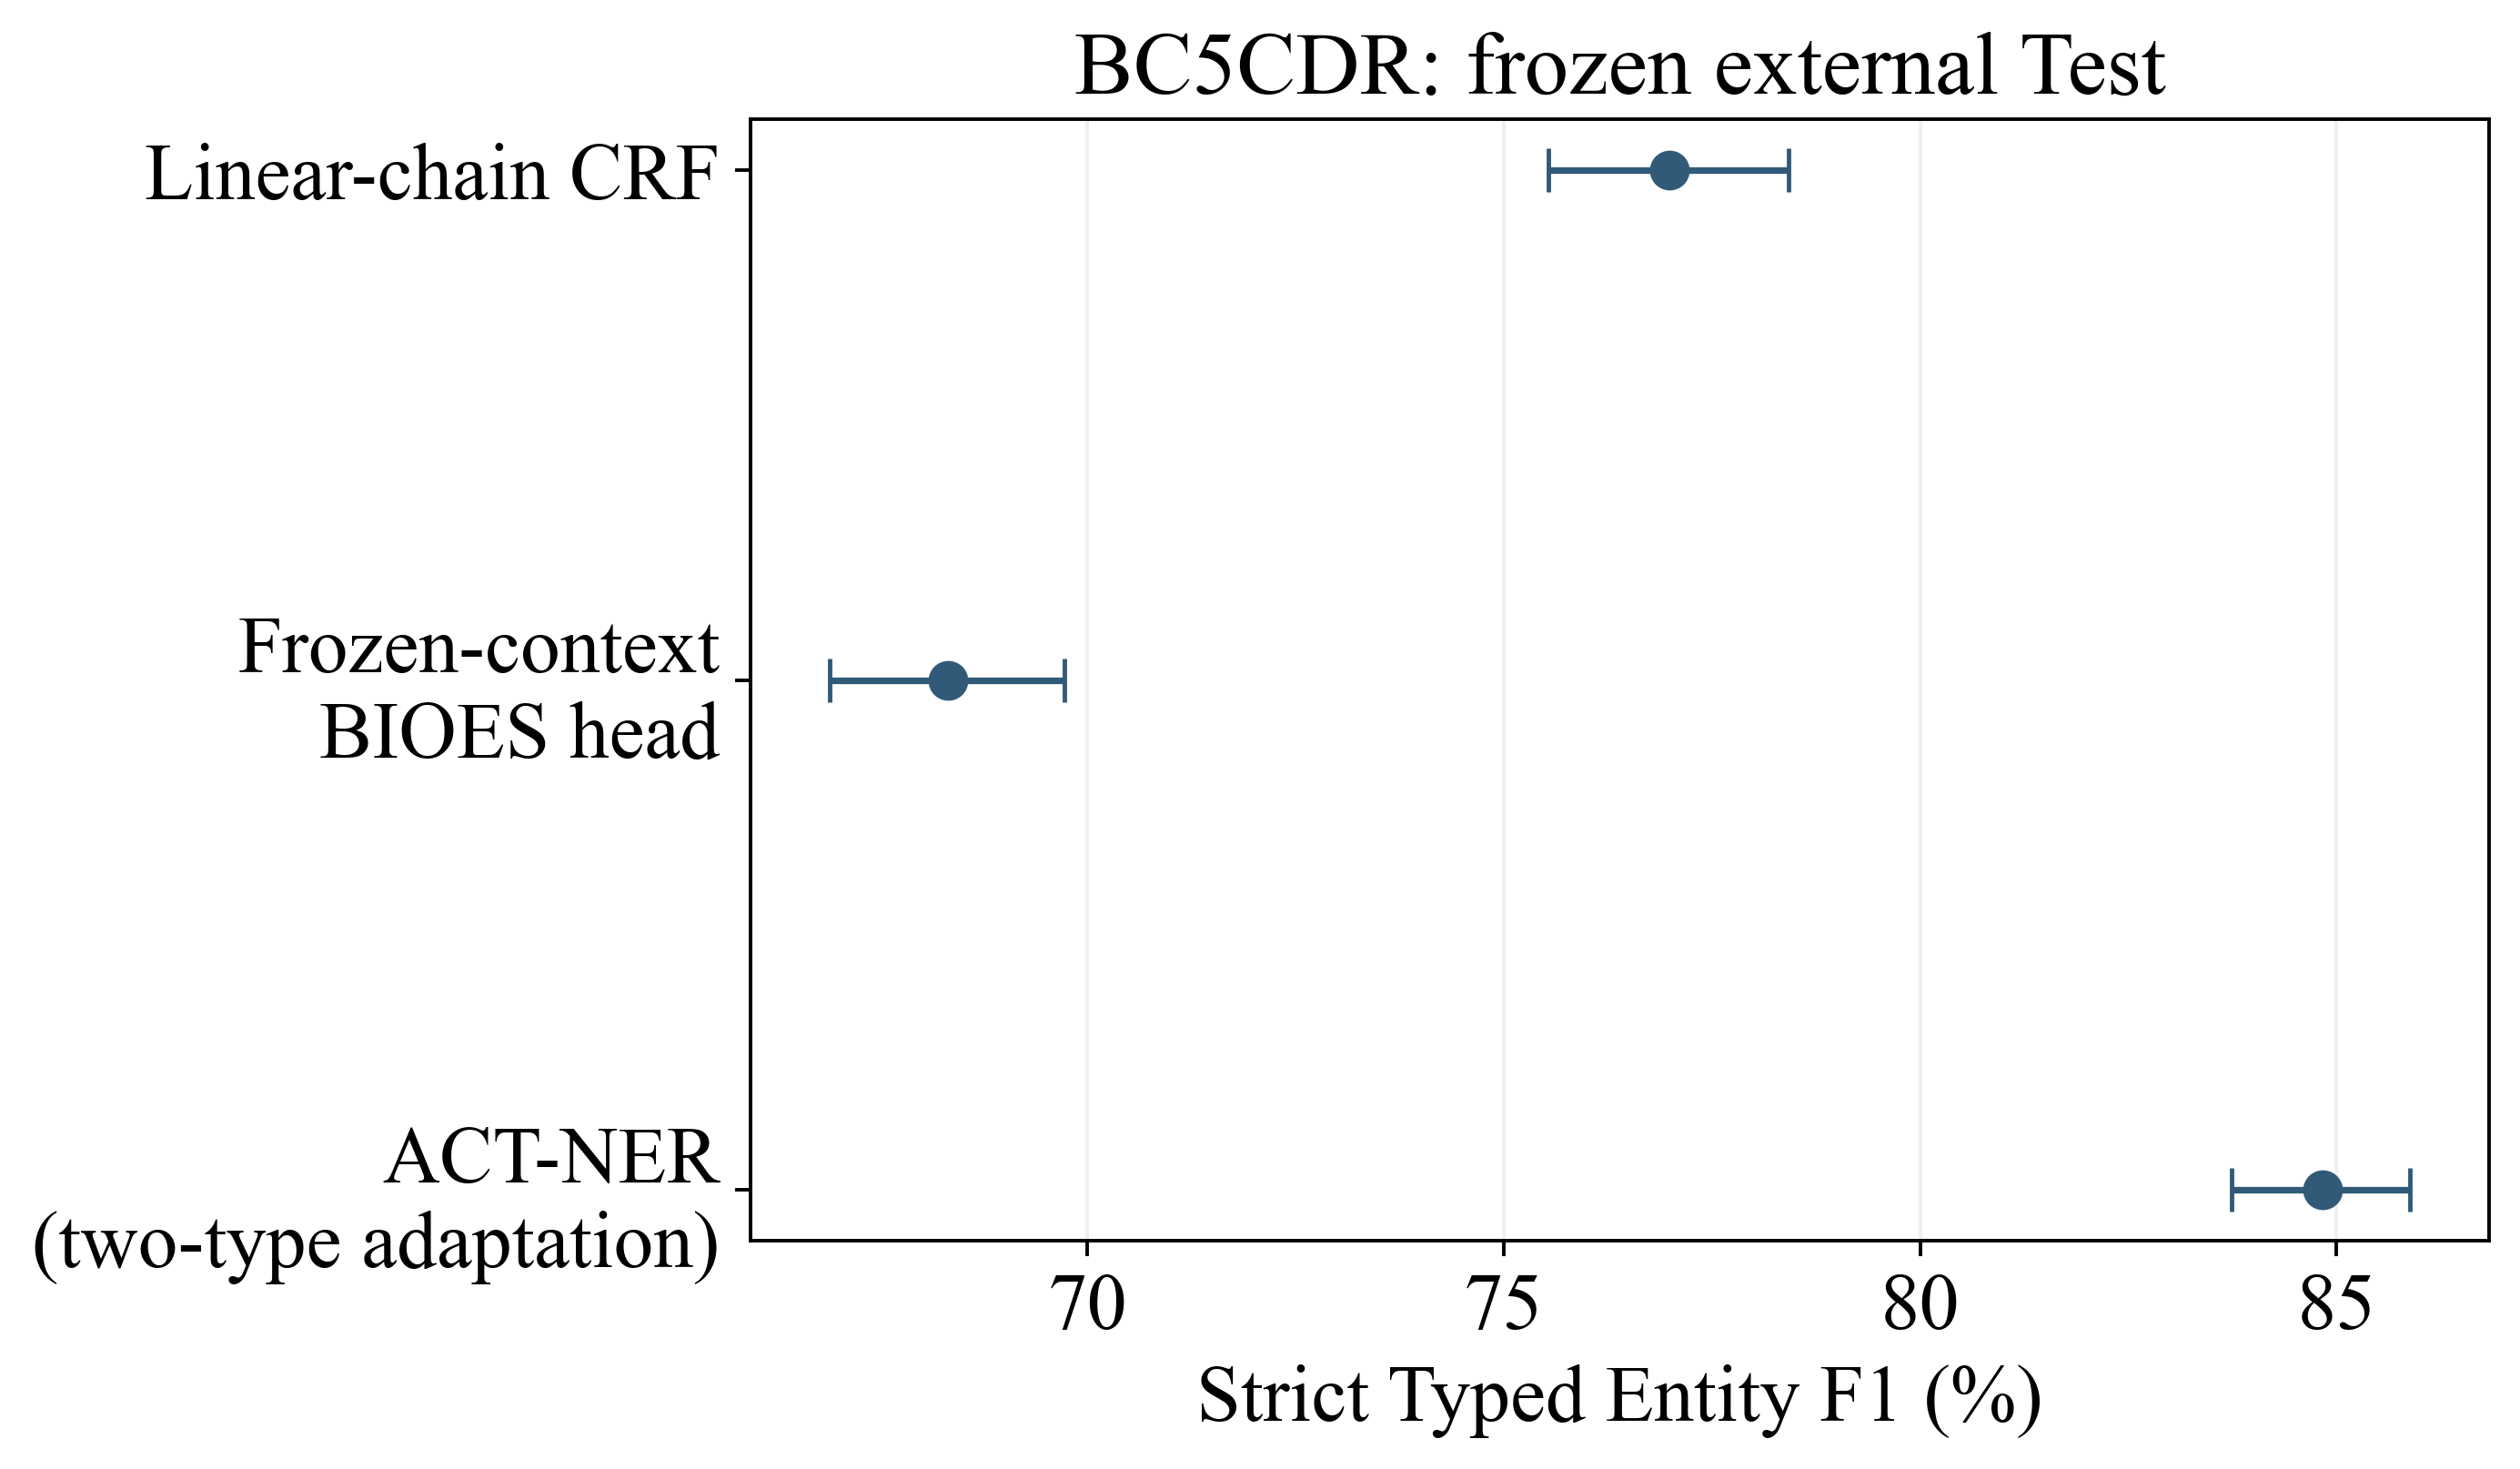

In [40]:
plot_data = external_statistics["metric_intervals"].query("Metric == 'Typed F1'").copy()
plot_data.to_csv(TABLES/"figure_r1_2_external_f1_data.csv", index=False)
names = {"ACT-NER architecture transfer":"ACT-NER\n(two-type adaptation)",
         "Contextual BIOES":"Frozen-context\nBIOES head", "Linear-chain CRF":"Linear-chain CRF"}
fig, ax = plt.subplots(figsize=(7.8, 4.5), layout="constrained")
x = plot_data.Estimate.to_numpy()*100
ax.errorbar(x, np.arange(len(x)), xerr=np.vstack([x-plot_data["CI lower"].to_numpy()*100,
    plot_data["CI upper"].to_numpy()*100-x]), fmt="o", color="#315a78", capsize=5, markersize=8)
ax.set_yticks(np.arange(len(x)), plot_data.Model.map(names))
ax.set_xlabel("Strict Typed Entity F1 (%)")
ax.set_title("BC5CDR: frozen external Test")
ax.grid(axis="x", alpha=.2)
fig.canvas.draw()
for text in fig.findobj(mpl.text.Text):
    if text.get_visible() and text.get_text().strip():
        assert 18 <= text.get_fontsize() <= 20 and text.get_fontfamily() == ["Times New Roman"]
fig.savefig(FIGURES/"r1_2_external_f1.png", dpi=350, facecolor="white")
fig.savefig(FIGURES/"r1_2_external_f1.pdf", dpi=350, facecolor="white")
plt.show()

## A40 – Text-screened Validation: a versioned sensitivity cohort

Exclude entire Validation dependency components connected to original Train under the exact-text rule, without changing any historical split or choosing cases by model performance.

In [41]:
from paired_statistics import upstream_overlap_and_legacy_oof, load_crossfit_predictions
from prospective_data import dependency_components
shared = ROOT/"dataset/Processed"
train_sentences = pd.read_parquet(shared/"train_sentences.parquet")
validation_sentences = pd.read_parquet(shared/"validation_sentences.parquet")
validation_entities = pd.read_parquet(shared/"validation_entities.parquet")
membership = pd.read_csv(ROOT/"Reports/refinement_20260907/membership.csv")
components = dependency_components(pd.concat([train_sentences, validation_sentences], ignore_index=True))
train_components = {components[d] for d in train_sentences.document_id.unique()}
cohort = membership.copy()
cohort["Train-connected component"] = cohort.document_id.map(components)
cohort["Included"] = ~cohort["Train-connected component"].isin(train_components)
cohort["Reason"] = np.where(cohort.Included, "No substantial exact-text connection to original Train",
                            "Direct or transitive exact-text connection to original Train")
cohort.to_csv(TABLES/"r1_5_text_screened_validation_manifest.csv", index=False)
retained = set(cohort.loc[cohort.Included, "document_id"])
assert len(retained) == 127 and not {components[d] for d in retained} & train_components
show_table(cohort.groupby(["Included", "Reason"], sort=False).agg(
    Documents=("document_id", "size"), Dependency_clusters=("dependency_group", "nunique")).reset_index())
display(Markdown("**Scope.** This is an evaluation-only sensitivity cohort, not a replacement split or a newly untouched test. Historical full-Validation model selection cannot be undone by filtering predictions. No model, epoch, threshold or calibrator is changed."))

Included,Reason,Documents,Dependency_clusters
True,No substantial exact-text connection to original Train,127,126
False,Direct or transitive exact-text connection to original Train,15,14


**Scope.** This is an evaluation-only sensitivity cohort, not a replacement split or a newly untouched test. Historical full-Validation model selection cannot be undone by filtering predictions. No model, epoch, threshold or calibrator is changed.

## A41 – Shared-text sensitivity: recomputed paired effects

Quantify whether the conditional ACT-NER comparisons are materially changed by the text-screened cohort, using saved entity predictions only.

In [42]:
from prospective_model import strict_metrics
from refinement_analysis import paired_evidence
existing = load_crossfit_predictions(ROOT)
predictions = {name: existing[name] for name in ("Full ACT-NER", "Parameter-matched span MLP")}
for name, slug in (("Linear-chain CRF", "linear_chain_crf"), ("Biomedical Transformer", "biomedical_transformer")):
    predictions[name] = {0: pd.read_parquet(ROOT/"Predictions/Validation"/f"{slug}.parquet")}
screened = {name: {seed: frame.loc[frame.document_id.isin(retained)].copy()
            for seed, frame in repeats.items()} for name, repeats in predictions.items()}
sentences = validation_sentences.loc[validation_sentences.document_id.isin(retained)]
entities = validation_entities.loc[validation_entities.document_id.isin(retained)]
documents = membership.loc[membership.document_id.isin(retained)].copy()
scores = pd.DataFrame([{"Model": name, "Seed": seed, **strict_metrics(entities, frame)}
    for name, repeats in screened.items() for seed, frame in repeats.items()])
scores.to_csv(TABLES/"r1_5_text_screened_metrics.csv", index=False)
show_table(scores[["Model", "Seed", "N", "typed_precision", "typed_recall", "typed_f1", "boundary_f1", "macro_f1"]])
comparisons = [("Full ACT-NER", name) for name in screened if name != "Full ACT-NER"]
evidence = paired_evidence(screened, sentences, entities, documents, comparisons, replicates=5000)
evidence.to_csv(TABLES/"r1_5_text_screened_statistics.csv", index=False)
show_table(evidence[["Comparison", "N documents", "Clusters", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]])
display(Markdown("**Interpretation.** These results assess sensitivity to the observed text overlap. They do not eliminate upstream model-selection dependence and are not used to revise the frozen ACT-NER. The separate BC5CDR experiment addresses cross-corpus applicability under its own prespecified protocol."))

Model,Seed,N,typed_precision,typed_recall,typed_f1,boundary_f1
Full ACT-NER,17,2509,0.91860,0.88601,0.90201,0.93934
Full ACT-NER,29,2509,0.91230,0.89558,0.90386,0.94047
Full ACT-NER,43,2509,0.91522,0.88202,0.89832,0.93688
Parameter-matched span MLP,17,2509,0.90533,0.88043,0.89271,0.94039
Parameter-matched span MLP,29,2509,0.90573,0.88840,0.89698,0.93883
Parameter-matched span MLP,43,2509,0.90156,0.87605,0.88862,0.93996
Linear-chain CRF,0,2509,0.88348,0.82503,0.85326,0.88706
Biomedical Transformer,0,2509,0.82930,0.87326,0.85071,0.90196


Model,Seed,macro_f1
Full ACT-NER,17,0.80285
Full ACT-NER,29,0.81675
Full ACT-NER,43,0.82108
Parameter-matched span MLP,17,0.79716
Parameter-matched span MLP,29,0.80591
Parameter-matched span MLP,43,0.78860
Linear-chain CRF,0,0.71409
Biomedical Transformer,0,0.67511


Comparison,N documents,Clusters,Micro-F1 difference,CI low
Full ACT-NER − Parameter-matched span MLP,127,126,0.00863,-0.00028
Full ACT-NER − Linear-chain CRF,127,126,0.04814,0.02650
Full ACT-NER − Biomedical Transformer,127,126,0.05069,0.03215


CI high,Micro-F1 Holm p
0.01941,0.08738
0.07417,0.00080
0.07255,0.00060


**Interpretation.** These results assess sensitivity to the observed text overlap. They do not eliminate upstream model-selection dependence and are not used to revise the frozen ACT-NER. The separate BC5CDR experiment addresses cross-corpus applicability under its own prespecified protocol.

## A42 – BiomedBERT-base: registered comparative protocol

Freeze the pinned full-fine-tuning configuration and final three-comparison Holm family before training.

In [43]:
import base_transformer_memorysafe as base
show_table(base.selftest())
base_protocol = base.freeze_protocol(ROOT)
try:
    verified_pilot = base._passed_pilot(ROOT)
except AssertionError:
    resource_check = base.resource_pilot(ROOT)
    show_table(resource_check['summary'])
    verified_pilot = base._passed_pilot(ROOT)
base_alignment = base.input_audit(ROOT)
base_alignment.to_csv(TABLES/"r1_4_base_alignment.csv", index=False)
show_table(base_alignment)
show_table(pd.DataFrame([{"Model":base.MODEL, "Pretrained revision":base.REVISION,
    "Training trajectories":3, "Seeds":"17, 29, 43", "Epochs per trajectory":5,
    "Optimization data":"Original Train: 572 documents", "Validation updates":0,
    "Epoch selection":"Five existing innerSelection sets; outer gold not scored until all choices are locked"}]))
display(Markdown("**Design.** Three Train-only trajectories produce five checkpoints each. "
    "Each outer fold selects an epoch using only its innerSelection groups. These are not fifteen independent refits. "
    "This isolates a stronger biomedical backbone while retaining the original BIOES argmax/repair decoder. "
    "ACT-NER additionally uses innerTrain labels; original Train–Validation text dependence remains disclosed."))

Synthetic software test,Status
Fixed two-row shapes and safe dummy labels,PASS
Every real sentence exactly once,PASS
Seed/epoch determinism,PASS
9GB memory abort,PASS
Token-weighted accumulation matches full-batch loss,PASS


Split,Documents,Sentences,Tokenized sentences
train,572,5510,5474
validation,142,1466,1431


WordPieces,Maximum input including specials,Strict gold,Exact boundary representable
144714,258,11812,11791
34857,126,2915,2906


Nonexact gold retained,Truncated sentences
21,0
9,0


Model,Pretrained revision,Training trajectories,Seeds,Epochs per trajectory
BiomedBERT-base (full fine-tuning),e1354b7a3a09615f6aba48dfad4b7a613eef7062,3,"17, 29, 43",5


Model,Optimization data,Validation updates,Epoch selection
BiomedBERT-base (full fine-tuning),Original Train: 572 documents,0,Five existing innerSelection sets; outer gold not scored until all choices are locked


**Design.** Three Train-only trajectories produce five checkpoints each. Each outer fold selects an epoch using only its innerSelection groups. These are not fifteen independent refits. This isolates a stronger biomedical backbone while retaining the original BIOES argmax/repair decoder. ACT-NER additionally uses innerTrain labels; original Train–Validation text dependence remains disclosed.

## A43 – Full BiomedBERT-base fine-tuning – seed 17

Train all backbone and classifier parameters using only original Train; save every fixed-budget epoch without scoring outer labels.

In [44]:
base_progress_view = display(Markdown("Preparing BiomedBERT-base seed 17."), display_id=True)
def base_progress(event):
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key,value in event.items() if key not in {"model","stage"})
    base_progress_view.update(Markdown(f"**{event.get('model', base.MODEL)} – {event['stage']}**  \n{detail}"))
base_result = base.train_seed(ROOT, 17, progress=base_progress)
show_table(pd.read_csv(base._paths(ROOT, 17)[2]/"learning.csv"))
show_table(pd.DataFrame([{key:base_result[key] for key in ("model", "seed", "epochs",
    "trainable_parameters", "device", "training_documents", "validation_gradient_updates", "training_seconds")}]))

**BiomedBERT-base (full fine-tuning) – completed seed**  
seed=17 · attempt=biomedbert_base_memorysafe_20261016

Epoch,Train token CE,Optimizer updates,Training seconds
1,0.70048,229,496.09196
2,0.09102,229,487.08710
3,0.06118,229,474.62096
4,0.04474,229,504.22016
5,0.03793,229,513.84097


Inference seconds,Peak allocated GB,Emitted Validation entities (unscored)
22.09667,3.79950,3106
20.38904,3.80350,3012
23.08966,3.84125,2991
20.73587,3.84125,3002
22.45560,3.84125,3002


model,seed,epochs,trainable_parameters
BiomedBERT-base (full fine-tuning),17,5,108904721


device,training_documents,validation_gradient_updates,training_seconds
mps,572,0,2475.86115


## A44 – Full BiomedBERT-base fine-tuning – seed 29

Train all backbone and classifier parameters using only original Train; save every fixed-budget epoch without scoring outer labels.

In [45]:
base_progress_view = display(Markdown("Preparing BiomedBERT-base seed 29."), display_id=True)
def base_progress(event):
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key,value in event.items() if key not in {"model","stage"})
    base_progress_view.update(Markdown(f"**{event.get('model', base.MODEL)} – {event['stage']}**  \n{detail}"))
base_result = base.train_seed(ROOT, 29, progress=base_progress)
show_table(pd.read_csv(base._paths(ROOT, 29)[2]/"learning.csv"))
show_table(pd.DataFrame([{key:base_result[key] for key in ("model", "seed", "epochs",
    "trainable_parameters", "device", "training_documents", "validation_gradient_updates", "training_seconds")}]))

**BiomedBERT-base (full fine-tuning) – complete trajectory**  
seed=29 · attempt=biomedbert_base_memorysafe_20261016 · epochs=5

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch,Train token CE,Optimizer updates,Training seconds
1,0.67423,229,540.68865
2,0.09039,229,551.86025
3,0.05717,229,521.97551
4,0.04461,229,586.01888
5,0.03480,229,519.40596


Inference seconds,Peak allocated GB,Emitted Validation entities (unscored)
21.73665,3.52248,3091
21.49533,3.52248,3000
22.46349,3.52248,2991
21.70492,3.57910,2958
19.28513,3.58120,2969


model,seed,epochs,trainable_parameters
BiomedBERT-base (full fine-tuning),29,5,108904721


device,training_documents,validation_gradient_updates,training_seconds
mps,572,0,2719.94923


## A45 – Full BiomedBERT-base fine-tuning – seed 43

Train all backbone and classifier parameters using only original Train; save every fixed-budget epoch without scoring outer labels.

In [46]:
base_progress_view = display(Markdown("Preparing BiomedBERT-base seed 43."), display_id=True)
def base_progress(event):
    detail = " · ".join(f"{key}={value:.5f}" if isinstance(value, float)
        else f"{key}={value}" for key,value in event.items() if key not in {"model","stage"})
    base_progress_view.update(Markdown(f"**{event.get('model', base.MODEL)} – {event['stage']}**  \n{detail}"))
base_result = base.train_seed(ROOT, 43, progress=base_progress)
show_table(pd.read_csv(base._paths(ROOT, 43)[2]/"learning.csv"))
show_table(pd.DataFrame([{key:base_result[key] for key in ("model", "seed", "epochs",
    "trainable_parameters", "device", "training_documents", "validation_gradient_updates", "training_seconds")}]))

**BiomedBERT-base (full fine-tuning) – complete trajectory**  
seed=43 · attempt=biomedbert_base_memorysafe_20261016 · epochs=5

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch,Train token CE,Optimizer updates,Training seconds
1,0.79596,229,467.03384
2,0.09193,229,463.38986
3,0.05791,229,486.25278
4,0.04367,229,492.43835
5,0.03610,229,531.55368


Inference seconds,Peak allocated GB,Emitted Validation entities (unscored)
19.05537,3.75946,3063
21.94909,3.82447,2959
20.65154,3.82447,2977
20.73705,3.82447,2974
21.55384,3.82447,2986


model,seed,epochs,trainable_parameters
BiomedBERT-base (full fine-tuning),43,5,108904721


device,training_documents,validation_gradient_updates,training_seconds
mps,572,0,2440.66852


## A46 – Final stronger-comparator evidence

Lock all fold-specific epoch choices before scoring outer folds; compare ACT-NER, independent biaffine NER, stronger Transformer and the internal matched-capacity control.

In [47]:
base_tables = base.aggregate(ROOT)
for name, frame in base_tables.items():
    frame.to_csv(TABLES/f"r1_4_final_{name}.csv", index=False)
show_table(base_tables["summary"])
subtype = base_tables["classwise"].groupby(["Model", "Type"]).F1.agg(["mean","std"]).reset_index()
show_table(subtype.rename(columns={"mean":"F1 mean", "std":"F1 SD"}))
show_table(base_tables["statistics"][["Comparison","N documents","Clusters","Micro-F1 difference",
    "CI low","CI high","Paired randomization p","Micro-F1 Holm p"]])
show_table(base_tables["trajectories"][["model","seed","epochs","trainable_parameters","training_seconds","validation_inference_seconds"]])
supported = base_tables["statistics"].loc[lambda f:f.Comparison.str.startswith("Full ACT-NER")]
count = ((supported["CI low"]>0) & (supported["Micro-F1 Holm p"]<.05)).sum()
display(Markdown(f"**Result.** A positive ACT-NER effect is supported in {count} of the two "
    "new-model comparisons under the final Holm family. This remains a conditional development comparison, "
    "with the fitting-support differences and prior Validation use documented above."))

Model,Documents,Clusters,Gold,Seeds
BiomedBERT-base (full fine-tuning),142,140,2915,3
Full ACT-NER,142,140,2915,3
Parameter-matched span MLP,142,140,2915,3
Independent biaffine NER (frozen backbone),142,140,2915,3
Frozen biomedbert-small,142,140,2915,1


Model,Typed F1 CI low,Typed F1 CI high,typed_f1 mean,typed_f1 SD
BiomedBERT-base (full fine-tuning),0.88179,0.92834,0.90669,0.00251
Full ACT-NER,0.88580,0.92908,0.90932,0.00257
Parameter-matched span MLP,0.87743,0.92341,0.90229,0.00383
Independent biaffine NER (frozen backbone),0.81232,0.85880,0.83720,0.00638
Frozen biomedbert-small,0.82548,0.88061,0.85537,Not available


Model,boundary_f1 mean,boundary_f1 SD,macro_f1 mean,macro_f1 SD
BiomedBERT-base (full fine-tuning),0.94673,0.00291,0.79147,0.00832
Full ACT-NER,0.94343,0.00173,0.82207,0.00999
Parameter-matched span MLP,0.94441,0.00060,0.80720,0.00847
Independent biaffine NER (frozen backbone),0.88234,0.00461,0.75653,0.01775
Frozen biomedbert-small,0.90967,Not available,0.67621,Not available


Model,typed_precision mean,typed_precision SD,typed_recall mean,typed_recall SD
BiomedBERT-base (full fine-tuning),0.89686,0.00077,0.91675,0.00547
Full ACT-NER,0.92289,0.00269,0.89617,0.00687
Parameter-matched span MLP,0.91301,0.00243,0.89182,0.00555
Independent biaffine NER (frozen backbone),0.86130,0.00749,0.81441,0.00539
Frozen biomedbert-small,0.83617,Not available,0.87547,Not available


Model,Type,F1 mean,F1 SD
BiomedBERT-base (full fine-tuning),brand_f1,0.86006,0.00760
BiomedBERT-base (full fine-tuning),drug_f1,0.93892,0.00076
BiomedBERT-base (full fine-tuning),drug_n_f1,0.47971,0.02069
BiomedBERT-base (full fine-tuning),group_f1,0.88717,0.00575
Frozen biomedbert-small,brand_f1,0.76030,Not available
Frozen biomedbert-small,drug_f1,0.90429,Not available
Frozen biomedbert-small,drug_n_f1,0.21118,Not available
Frozen biomedbert-small,group_f1,0.82909,Not available
Full ACT-NER,brand_f1,0.91030,0.01266
Full ACT-NER,drug_f1,0.93981,0.00163


Comparison,N documents,Clusters,Micro-F1 difference,CI low
Full ACT-NER − Independent biaffine NER (frozen backbone),142,140,0.07212,0.05551
Full ACT-NER − BiomedBERT-base (full fine-tuning),142,140,0.00263,-0.01411
Parameter-matched span MLP − Independent biaffine NER (frozen backbone),142,140,0.06509,0.04442


Comparison,CI high,Paired randomization p,Micro-F1 Holm p
Full ACT-NER − Independent biaffine NER (frozen backbone),0.09077,0.00020,0.00060
Full ACT-NER − BiomedBERT-base (full fine-tuning),0.02135,0.77065,0.77065
Parameter-matched span MLP − Independent biaffine NER (frozen backbone),0.08683,0.00020,0.00060


model,seed,epochs,trainable_parameters
BiomedBERT-base (full fine-tuning),17,5,108904721
BiomedBERT-base (full fine-tuning),29,5,108904721
BiomedBERT-base (full fine-tuning),43,5,108904721


training_seconds,validation_inference_seconds
2475.86115,108.76685
2719.94923,106.68552
2440.66852,103.94688


**Result.** A positive ACT-NER effect is supported in 1 of the two new-model comparisons under the final Holm family. This remains a conditional development comparison, with the fitting-support differences and prior Validation use documented above.

## A47 – New comparator quality with cluster uncertainty

Display the recognition ranking actually obtained, retaining all controls and their uncertainty.

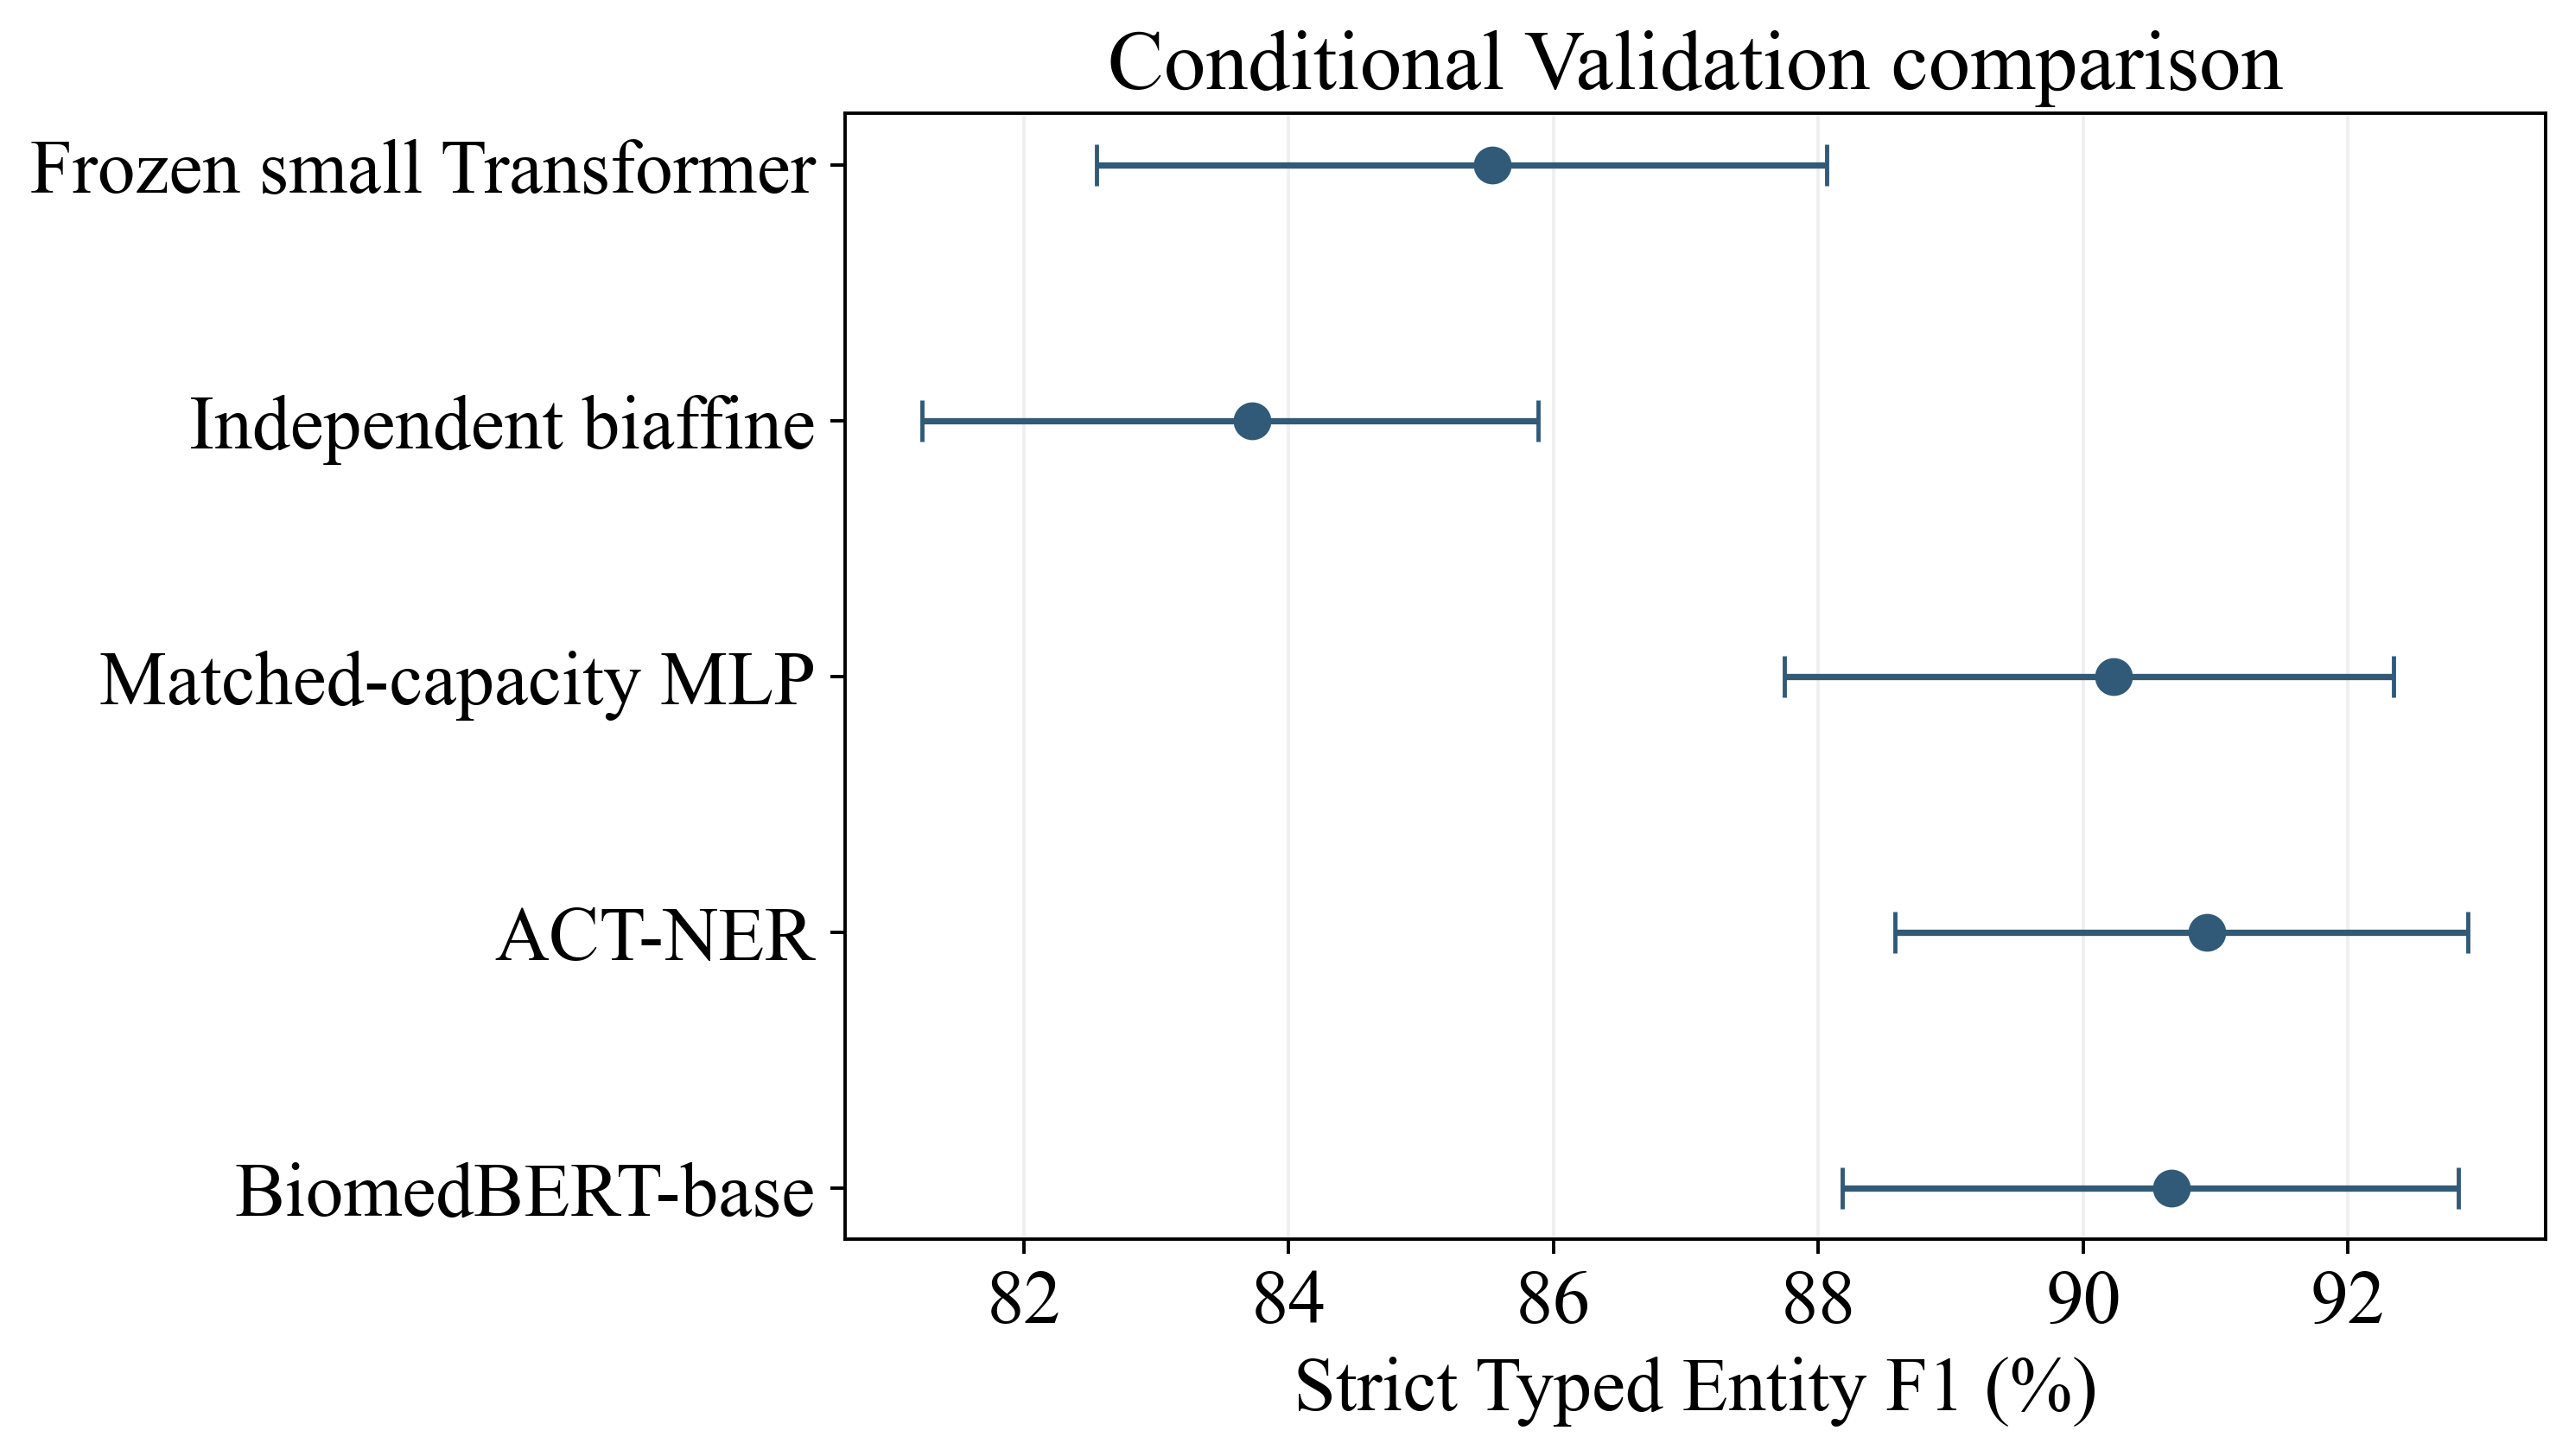

In [48]:
plot_data = base_tables["summary"].copy()
plot_data.to_csv(TABLES/"figure_r1_4_final_f1_data.csv", index=False)
names = {base.MODEL:"BiomedBERT-base", base.SPAN_MODEL:"Independent biaffine",
    "Full ACT-NER":"ACT-NER", "Parameter-matched span MLP":"Matched-capacity MLP",
    "Frozen biomedbert-small":"Frozen small Transformer"}
fig, ax = plt.subplots(figsize=(8.4, 4.7), layout="constrained")
x = plot_data["typed_f1 mean"].to_numpy()*100
ax.errorbar(x, np.arange(len(x)), xerr=np.vstack([x-plot_data["Typed F1 CI low"].to_numpy()*100,
    plot_data["Typed F1 CI high"].to_numpy()*100-x]), fmt="o", color="#315a78", capsize=5, markersize=8)
ax.set_yticks(np.arange(len(x)), plot_data.Model.map(names))
ax.set_xlabel("Strict Typed Entity F1 (%)")
ax.set_title("Conditional Validation comparison")
ax.grid(axis="x", alpha=.2)
fig.canvas.draw()
for text in fig.findobj(mpl.text.Text):
    if text.get_visible() and text.get_text().strip():
        assert 18 <= text.get_fontsize() <= 20 and text.get_fontfamily() == ["Times New Roman"]
fig.savefig(FIGURES/"r1_4_final_f1.png", dpi=350, facecolor="white")
fig.savefig(FIGURES/"r1_4_final_f1.pdf", dpi=350, facecolor="white")
plt.show()

# Part B – Stacking protocol and extended evaluation

**Goal.** Evaluate ACT-NER when every model receives the same labelled documents, report all systems on the official DrugNER test set overall and per source, and compare with a base-size biomedical encoder and span-based models.

**Data.** DDIExtraction 2013: Train (572 documents), Validation (142), official DrugNER test (112) and the reserved relation-task documents (191, of which 176 are text-disjoint); BC5CDR for the external experiment.

**Requires.** Artifacts produced by notebooks 01–06 and by Part A. They are read, never rewritten.

**Evaluation populations.** The official DrugNER test set and the reserved documents are used for frozen evaluation only: nothing is fitted, selected or calibrated on them.

This part starts from its own setup cells and does not depend on the kernel state of Part A.

## B01 – Environment, display rules and reproducibility settings

Fix the paths of this run, the random seeds, the complete-table display and the figure standard (Matplotlib, Times New Roman, 18–20 pt, 350 dpi) before any computation.

In [49]:
from __future__ import annotations

import contextlib
import gc
import hashlib
import io
import json
import math
import os
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")          # pinned local model files only
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# Bound the Metal allocator: cached GPU buffers are released instead of pushing the system into swap.
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "1.0")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.7")

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from matplotlib import font_manager
from matplotlib.text import Text
from PIL import Image as PILImage
from scipy import stats
from torch import nn
from torch.nn import functional as F


def find_project_root(start: Path | None = None) -> Path:
    """Return the nearest parent directory that contains PROJECT_REQUIREMENTS.md."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "PROJECT_REQUIREMENTS.md").is_file():
            return candidate
    raise FileNotFoundError("PROJECT_REQUIREMENTS.md not found above the working directory")


PROJECT = find_project_root()
SHARED = PROJECT / "dataset"            # read-only in this part
if str(PROJECT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT / "src"))

STACKING_RUN = "stacking_20261114"
RUN_TABLES = PROJECT / "artifacts" / STACKING_RUN
RUN_FIG_PNG = PROJECT / "figures" / STACKING_RUN / "PNG"
RUN_FIG_PDF = PROJECT / "figures" / STACKING_RUN / "PDF"
RUN_MODELS = PROJECT / "Models" / "Stacking" / STACKING_RUN
RUN_PREDICTIONS = PROJECT / "Predictions" / "Stacking" / STACKING_RUN
RUN_REPORTS = PROJECT / "Reports" / STACKING_RUN
for directory in (RUN_TABLES, RUN_FIG_PNG, RUN_FIG_PDF, RUN_MODELS, RUN_PREDICTIONS, RUN_REPORTS):
    directory.mkdir(parents=True, exist_ok=True)

EXPERIMENT = json.loads((PROJECT / "src" / "experiment.json").read_text())
SEEDS = tuple(EXPERIMENT["full_model_seeds"])         # optimizer seeds 17, 29, 43
REFERENCE_SEED = EXPERIMENT["reference_seed"]         # predeclared reference seed 17
STAT_SEED = 9017                                      # resampling seed used throughout the project
N_RESAMPLES = 5000
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

random.seed(REFERENCE_SEED)
np.random.seed(REFERENCE_SEED)
_ = torch.manual_seed(REFERENCE_SEED)

In [50]:
# Tables: default pandas rendering, nothing truncated; numbers formatted in a display copy only.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

MINUS = "−"


def fmt_num(x: float, digits: int = 4) -> str:
    """Fixed-point number with a typographic minus; negative zero is suppressed."""
    if not np.isfinite(x):
        raise ValueError(f"non-finite value cannot be displayed: {x}")
    text = f"{x:.{digits}f}"
    if float(text) == 0.0:
        text = f"{0.0:.{digits}f}"
    return text.replace("-", MINUS)


def fmt_signed(x: float, digits: int = 4) -> str:
    """Signed difference: '+0.0120', '−0.0340', '0.0000'."""
    text = fmt_num(x, digits)
    if text.startswith(MINUS) or float(text.replace(MINUS, "-")) == 0.0:
        return text
    return "+" + text


def fmt_p(p: float) -> str:
    """p-value for display: never 'p = 0'."""
    if not 0.0 <= p <= 1.0:
        raise ValueError(f"p-value out of range: {p}")
    if p < 0.001:
        return "< 0.001"
    if p > 0.999:
        return "> 0.999"
    return f"{p:.3f}"


def fmt_interval(estimate: float, low: float, high: float, digits: int = 4, signed: bool = False) -> str:
    """Point estimate with its 95 % interval in square brackets."""
    head = fmt_signed(estimate, digits) if signed else fmt_num(estimate, digits)
    return f"{head} [{fmt_num(low, digits)}, {fmt_num(high, digits)}]"


def format_for_display(df: pd.DataFrame, digits: int = 4, signed: tuple[str, ...] = (),
                       pvalues: tuple[str, ...] = (), counts: tuple[str, ...] = ()) -> pd.DataFrame:
    """Display copy of a table; the numeric original is what goes to CSV."""
    out = df.copy()
    for col in out.columns:
        if col in counts or pd.api.types.is_integer_dtype(out[col]):
            out[col] = out[col].map(lambda v: f"{int(v):d}")
        elif col in pvalues:
            out[col] = out[col].map(fmt_p)
        elif col in signed:
            out[col] = out[col].map(lambda v: fmt_signed(v, digits))
        elif pd.api.types.is_float_dtype(out[col]):
            out[col] = out[col].map(lambda v: fmt_num(v, digits))
    return out


def display_table(df: pd.DataFrame, caption: str, index: str | list[str] | None = None, digits: int = 4,
                  signed: tuple[str, ...] = (), pvalues: tuple[str, ...] = (),
                  counts: tuple[str, ...] = ()) -> None:
    """Show one complete table under its caption after integrity checks."""
    if df.isna().any().any():
        raise ValueError("table contains missing values: restructure it or mark them with a reason")
    shown = format_for_display(df, digits, signed, pvalues, counts)
    if shown.astype(str).apply(lambda s: s.str.contains("…|\\.\\.\\.", regex=True)).any().any():
        raise ValueError("table contains an ellipsis")
    display(Markdown(f"**{caption}**"))
    display(shown.set_index(index) if index is not None else shown)


def save_table(df: pd.DataFrame, name: str, digits: int = 4) -> None:
    """Store the numeric table as CSV and as a booktabs LaTeX table (negative numbers in math mode)."""
    df.to_csv(RUN_TABLES / f"{name}.csv", index=False)
    latex = df.to_latex(index=False, escape=True, float_format=lambda value: f"${value:.{digits}f}$")
    (RUN_TABLES / f"{name}.tex").write_text(latex, encoding="utf-8")


def note(text: str) -> None:
    """Interpretation written from the numbers computed in the same cell."""
    display(Markdown(text))

In [51]:
# Figures: Matplotlib only, Times New Roman, 18–20 pt, 350 dpi, PNG and vector PDF.
font_manager.findfont(font_manager.FontProperties(family="Times New Roman"),
                      fallback_to_default=False)      # stops here if the font is missing
FONT_MIN_PT, FONT_MAX_PT, DPI = 18, 20, 350
OKABE_ITO = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000", "#F0E442"]
mpl.rcParams.update({
    "font.family": "Times New Roman", "font.size": 18,
    "axes.titlesize": 20, "axes.labelsize": 20,
    "xtick.labelsize": 18, "ytick.labelsize": 18,
    "legend.fontsize": 18, "legend.title_fontsize": 18,
    "figure.titlesize": 20, "figure.labelsize": 20,
    "mathtext.fontset": "custom", "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic", "mathtext.bf": "Times New Roman:bold",
    "axes.unicode_minus": True,
    "axes.prop_cycle": mpl.cycler(color=OKABE_ITO),
    "figure.dpi": DPI, "savefig.dpi": DPI,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "figure.constrained_layout.use": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


def label_panels(axes) -> None:
    """Put (a), (b), (c), ... below each panel as an extra line of its x-axis label."""
    for i, ax in enumerate(np.ravel(axes)):
        letter = f"({chr(ord('a') + i)})"
        current = ax.get_xlabel()
        ax.set_xlabel(f"{current}\n{letter}" if current else letter)


def annotate_matrix(ax, values: np.ndarray, image, digits: int = 2) -> None:
    """Write cell values with a typographic minus; text colour follows the background."""
    for (i, j), v in np.ndenumerate(values):
        r, g, b, _ = image.cmap(image.norm(v))
        luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
        ax.text(j, i, fmt_num(v, digits), ha="center", va="center", fontsize=FONT_MIN_PT,
                color="black" if luminance > 0.5 else "white")


def _undrawn_tick_labels(fig) -> set[int]:
    """Tick labels outside the view interval exist as objects but are not drawn."""
    undrawn = set()
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            lo, hi = sorted(axis.get_view_interval())
            tol = 1e-9 * max(1.0, abs(hi - lo))
            for tick in axis.get_major_ticks() + axis.get_minor_ticks():
                loc = tick.get_loc()
                if loc is None or not lo - tol <= loc <= hi + tol:
                    undrawn.update({id(tick.label1), id(tick.label2)})
    return undrawn


def check_figure(fig) -> None:
    """Stop if drawn text is outside 18–20 pt, not Times New Roman, or overlapping."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    undrawn = _undrawn_tick_labels(fig)
    texts = [t for t in fig.findobj(Text)
             if t.get_visible() and t.get_text().strip() and id(t) not in undrawn]
    problems = [f"{t.get_text()[:30]!r}: {t.get_fontsize():.1f} pt, {t.get_fontname()}"
                for t in texts
                if not FONT_MIN_PT <= t.get_fontsize() <= FONT_MAX_PT
                or t.get_fontname() != "Times New Roman"]
    boxes = [(t.get_text()[:30], t.get_window_extent(renderer)) for t in texts]
    problems += [f"overlap: {a!r} / {b!r}"
                 for i, (a, box_a) in enumerate(boxes)
                 for b, box_b in boxes[i + 1:] if box_a.overlaps(box_b)]
    if problems:
        raise ValueError("figure violates the standard:\n" + "\n".join(problems))


def save_and_show(fig, name: str) -> None:
    """Check, save PNG and PDF at 350 dpi, close, and show the saved PNG once at physical size."""
    check_figure(fig)
    png = RUN_FIG_PNG / f"{name}.png"
    fig.savefig(png, dpi=DPI)
    fig.savefig(RUN_FIG_PDF / f"{name}.pdf")
    plt.close(fig)
    with PILImage.open(png) as im:
        width_px = im.width
    display(Image(filename=str(png), width=round(width_px / DPI * 96)))

## B02 – Evaluation populations and partition manifest

**Question.** What exactly are the four evaluation populations, how many documents, sentences and eligible gold entities does each source contribute, and which documents belong to each partition?

**Method.** Populations are rebuilt from the immutable processed corpus. Eligible gold follows the contiguous exact-span estimand of the study (discontinuous annotations are counted separately). Dependency clusters join documents that share an exact normalized sentence of at least 40 characters and six words; they are the resampling unit of every interval below. The document identifiers of all partitions, including the 176 text-disjoint reserved documents, are exported to `artifacts/stacking_20261114/partition_manifest.csv`.

In [52]:
# Project components reused unchanged (modules in src/).
from core import ENTITY_TYPES, TYPED_TAGS, gold_for_metrics, load_processed, normalize_surface
from prospective_data import dependency_components
from prospective_model import strict_metrics
from refinement_analysis import f1_counts, holm, paired_evidence
from refinement_experiment import role_partition

KEY = ["sentence_id", "char_start", "char_end"]
REFINEMENT = "refinement_20260907"                    # run that produced the original ACT-NER
EXTENDED_RUN = "extended_20261016"                    # run of the sections above


@dataclass(frozen=True)
class Population:
    """One document population with its annotations and dependency clusters."""
    name: str
    sentences: pd.DataFrame
    entities: pd.DataFrame       # every annotation, including discontinuous ones
    tokens: pd.DataFrame
    documents: pd.DataFrame      # document_id, source, dependency_group

    @property
    def gold(self) -> pd.DataFrame:
        """Eligible gold entities of the contiguous exact-span estimand."""
        return gold_for_metrics(self.entities)

    def subset(self, document_ids, name: str) -> "Population":
        keep = set(document_ids)
        return Population(name, *(frame.loc[frame.document_id.isin(keep)].reset_index(drop=True)
                                  for frame in (self.sentences, self.entities, self.tokens, self.documents)))


def document_table(sentences: pd.DataFrame) -> pd.DataFrame:
    """Documents with their source and exact-text dependency cluster."""
    documents = (sentences[["document_id", "source"]].drop_duplicates()
                 .sort_values("document_id").reset_index(drop=True))
    documents["dependency_group"] = documents.document_id.map(dependency_components(sentences))
    return documents


def load_population(name: str, split: str) -> Population:
    sentences, entities, tokens = load_processed(PROJECT, split)
    return Population(name, sentences, entities, tokens, document_table(sentences))


train = load_population("Train", "train")
validation = load_population("Validation", "validation")
# The five outer folds of the original cross-fit are part of the Validation document table.
validation_membership = pd.read_csv(PROJECT / "Reports" / REFINEMENT / "membership.csv")
validation = Population("Validation", validation.sentences, validation.entities, validation.tokens,
                        validation_membership)
test = load_population("Official DrugNER test", "locked_test")

reserve_directory = SHARED / "Interim" / REFINEMENT / "additional_holdout"
reserve_frames = {name: pd.read_parquet(reserve_directory / f"{name}.parquet")
                  for name in ("sentences", "entities", "tokens", "documents")}
reserve_all = Population("Reserve (all relation-task test documents)", reserve_frames["sentences"],
                         reserve_frames["entities"], reserve_frames["tokens"],
                         document_table(reserve_frames["sentences"]))
reserve_eligible = set(reserve_frames["documents"].query("eligible_independent_text").document_id)
reserve = reserve_all.subset(reserve_eligible, "Reserve (text-disjoint)")

assert [len(p.documents) for p in (train, validation, test, reserve_all, reserve)] == [572, 142, 112, 191, 176]
assert validation.documents.dependency_group.nunique() == 140
POPULATIONS = (train, validation, test, reserve_all, reserve)

In [53]:
def counts_per_cluster(documents: pd.DataFrame, gold: pd.DataFrame, prediction: pd.DataFrame,
                       typed: bool = True) -> np.ndarray:
    """TP, gold and predicted entity counts per dependency cluster (clusters × 3).

    A prediction is correct when sentence, character span and, for typed matching, entity type agree.
    """
    gold_columns = KEY + (["entity_type"] if typed else [])
    g = gold[["document_id"] + gold_columns].drop_duplicates(gold_columns)
    p = prediction[["document_id"] + KEY + (["predicted_type"] if typed else [])]
    p = p.rename(columns={"predicted_type": "entity_type"}).drop_duplicates(gold_columns)
    hits = g.merge(p, on=["document_id"] + gold_columns)
    cluster_of = documents.set_index("document_id").dependency_group
    assert set(p.document_id) <= set(cluster_of.index), "prediction outside the evaluated population"
    clusters = np.sort(cluster_of.unique())

    def per_cluster(frame: pd.DataFrame) -> np.ndarray:
        return (frame.document_id.map(cluster_of).value_counts()
                .reindex(clusters, fill_value=0).to_numpy(float))

    return np.column_stack([per_cluster(hits), per_cluster(g), per_cluster(p)])


def stacked_counts(population: Population, repeats: dict[int, pd.DataFrame],
                   gold: pd.DataFrame | None = None, typed: bool = True) -> np.ndarray:
    """Counts for every optimizer seed of one model (seeds × clusters × 3)."""
    gold = population.gold if gold is None else gold
    return np.stack([counts_per_cluster(population.documents, gold, frame, typed)
                     for frame in repeats.values()])


def resampling_weights(n_clusters: int) -> np.ndarray:
    """Multinomial cluster-bootstrap weights, shared by every model of one population."""
    rng = np.random.default_rng(STAT_SEED)
    return rng.multinomial(n_clusters, np.full(n_clusters, 1 / n_clusters), size=N_RESAMPLES)


def f1_with_interval(counts: np.ndarray, weights: np.ndarray) -> tuple[float, float, float]:
    """Seed-averaged corpus F1 = 2TP / (gold + predicted) with a percentile 95 % cluster-bootstrap interval."""
    estimate = float(f1_counts(counts.sum(axis=1)).mean())
    replicates = f1_counts(np.einsum("bg,sgc->bsc", weights, counts)).mean(axis=1)
    low, high = np.quantile(replicates, [0.025, 0.975])
    return estimate, float(low), float(high)


def macro_f1_with_interval(counts_by_type: list[np.ndarray], weights: np.ndarray) -> tuple[float, float, float]:
    """Unweighted mean of the four type-specific F1 values, resampled jointly over clusters."""
    estimate = float(np.mean([f1_counts(c.sum(axis=1)) for c in counts_by_type], axis=0).mean())
    replicates = np.mean([f1_counts(np.einsum("bg,sgc->bsc", weights, c)) for c in counts_by_type],
                         axis=0).mean(axis=1)
    low, high = np.quantile(replicates, [0.025, 0.975])
    return estimate, float(low), float(high)


def by_type(repeats: dict[int, pd.DataFrame], entity_type: str) -> dict[int, pd.DataFrame]:
    return {seed: frame.loc[frame.predicted_type == entity_type] for seed, frame in repeats.items()}


def by_source(population: Population, repeats: dict[int, pd.DataFrame], source: str) -> dict[int, pd.DataFrame]:
    source_of = population.sentences.set_index("sentence_id").source
    return {seed: frame.loc[frame.sentence_id.map(source_of).eq(source).to_numpy(bool)]
            for seed, frame in repeats.items()}

In [54]:
def alignment_summary(population: Population) -> tuple[int, float]:
    """Gold spans whose edges coincide with token edges, and the share of tokens inside gold spans."""
    gold = population.gold
    starts = {sid: set(part.char_start) for sid, part in population.tokens.groupby("sentence_id")}
    ends = {sid: set(part.char_end) for sid, part in population.tokens.groupby("sentence_id")}
    exact = sum(row.char_start in starts.get(row.sentence_id, ()) and row.char_end in ends.get(row.sentence_id, ())
                for row in gold.itertuples(index=False))
    spans = {sid: part[["char_start", "char_end"]].to_numpy() for sid, part in gold.groupby("sentence_id")}
    inside = 0
    for sid, part in population.tokens.groupby("sentence_id"):
        if sid in spans:
            s, e = part.char_start.to_numpy()[:, None], part.char_end.to_numpy()[:, None]
            inside += int(((e > spans[sid][:, 0]) & (s < spans[sid][:, 1])).any(axis=1).sum())
    return exact, inside / len(population.tokens)


population_rows, type_rows = [], []
for population in POPULATIONS:
    for source in ("DrugBank", "MedLine", "All"):
        keep = population.documents if source == "All" else population.documents.query("source == @source")
        part = population.subset(keep.document_id, population.name)
        population_rows.append({
            "Population": population.name, "Source": source, "Documents": len(part.documents),
            "Dependency clusters": part.documents.dependency_group.nunique(),
            "Sentences": len(part.sentences), "Annotated entities": len(part.entities),
            "Discontinuous": int(part.entities.discontinuous.sum()), "Eligible gold": len(part.gold)})
    exact, token_share = alignment_summary(population)
    type_counts = population.gold.entity_type.value_counts().reindex(ENTITY_TYPES, fill_value=0)
    type_rows.append({"Population": population.name, **{t: int(type_counts[t]) for t in ENTITY_TYPES},
                      "Exact token-edge gold": exact, "Entity-token share": token_share})
population_table, type_table = pd.DataFrame(population_rows), pd.DataFrame(type_rows)
assert (population_table["Annotated entities"]
        == population_table["Discontinuous"] + population_table["Eligible gold"]).all()

manifest = pd.concat([
    train.documents.assign(partition="Train"),
    validation.documents[["document_id", "source", "dependency_group", "outer_fold"]].assign(partition="Validation"),
    test.documents.assign(partition="Official DrugNER test"),
    reserve_all.documents.assign(partition=lambda f: np.where(
        f.document_id.isin(reserve_eligible), "Reserve (text-disjoint)", "Reserve (excluded: shared text)")),
], ignore_index=True)
manifest["validation_outer_fold"] = manifest.outer_fold.map(lambda v: "" if pd.isna(v) else str(int(v) + 1))
manifest = manifest[["document_id", "source", "partition", "dependency_group", "validation_outer_fold"]]
assert manifest.document_id.is_unique and len(manifest) == 572 + 142 + 112 + 191
manifest.to_csv(RUN_TABLES / "partition_manifest.csv", index=False)

save_table(population_table, "table_7_01_populations")
save_table(type_table, "table_7_02_population_types")
display_table(population_table, "Table 7.1. Evaluation populations of DDIExtraction 2013 by source: documents, "
              "exact-text dependency clusters, sentences, annotated entities, discontinuous annotations and "
              "eligible gold entities of the contiguous exact-span estimand.", index=["Population", "Source"])
display_table(type_table, "Table 7.2. Eligible gold entities by type, gold spans whose character edges coincide "
              "with WordPiece token edges, and the share of tokens inside gold spans, for each population.",
              index="Population")
row = population_table.set_index(["Population", "Source"])
test_all, test_med = row.loc[(test.name, "All")], row.loc[(test.name, "MedLine")]
val_all, val_med = row.loc[(validation.name, "All")], row.loc[(validation.name, "MedLine")]
excluded = reserve_all.documents.loc[~reserve_all.documents.document_id.isin(reserve_eligible)]
note(f"**Interpretation.** The official DrugNER test set holds {int(test_all['Eligible gold'])} eligible gold entities "
     f"({int(test_all['Discontinuous'])} discontinuous annotations are excluded from the estimand), and MedLine supplies "
     f"{int(test_med['Eligible gold'])} of them ({test_med['Eligible gold'] / test_all['Eligible gold']:.1%}). In Validation "
     f"MedLine supplies only {int(val_med['Eligible gold'])} of {int(val_all['Eligible gold'])} "
     f"({val_med['Eligible gold'] / val_all['Eligible gold']:.1%}). The two populations therefore weight the sources very "
     f"differently, which is why per-source results are reported for every model below. The reserve consists of "
     f"{len(reserve_all.documents)} relation-task test documents; {len(excluded)} of them "
     f"({', '.join(f'{n} {s}' for s, n in excluded.source.value_counts().items())}) share an exact sentence with a "
     f"development or test document and are excluded, leaving {len(reserve.documents)}.")

**Table 7.1. Evaluation populations of DDIExtraction 2013 by source: documents, exact-text dependency clusters, sentences, annotated entities, discontinuous annotations and eligible gold entities of the contiguous exact-span estimand.**

Documents  \
Population                                 Source               
Train                                      DrugBank       458   
                                           MedLine        114   
                                           All            572   
Validation                                 DrugBank       114   
                                           MedLine         28   
                                           All            142   
Official DrugNER test                      DrugBank        54   
                                           MedLine         58   
                                           All            112   
Reserve (all relation-task test documents) DrugBank       158   
                                           MedLine         33   
                                           All            191   
Reserve (text-disjoint)                    DrugBank       143   
                                           MedLine         33   
                                           All            176   

                                                    Dependency clusters  \
Population                                 Source                         
Train                                      DrugBank                 423   
                                           MedLine                  114   
                                           All                      537   
Validation                                 DrugBank                 112   
                                           MedLine                   28   
                                           All                      140   
Official DrugNER test                      DrugBank                  53   
                                           MedLine                   58   
                                           All                      111   
Reserve (all relation-task test documents) DrugBank                 152   
                                           MedLine                   33   
                                           All                      185   
Reserve (text-disjoint)                    DrugBank                 139   
                                           MedLine                   33   
                                           All                      172   

                                                    Sentences  \
Population                                 Source               
Train                                      DrugBank      4452   
                                           MedLine       1058   
                                           All           5510   
Validation                                 DrugBank      1223   
                                           MedLine        243   
                                           All           1466   
Official DrugNER test                      DrugBank       145   
                                           MedLine        520   
                                           All            665   
Reserve (all relation-task test documents) DrugBank       973   
                                           MedLine        326   
                                           All           1299   
Reserve (text-disjoint)                    DrugBank       848   
                                           MedLine        326   
                                           All           1174   

                                                    Annotated entities  \
Population                                 Source                        
Train                                      DrugBank              10376   
                                           MedLine                1465   
                                           All                   11841   
Validation                                 DrugBank               2553   
                                           MedLine                 371   
                                           All

**Table 7.2. Eligible gold entities by type, gold spans whose character edges coincide with WordPiece token edges, and the share of tokens inside gold spans, for each population.**

,drug,brand,group,drug_n,Exact token-edge gold,Entity-token share
Population,,,,,,
Train,7560,1154,2698,400,11791,0.1934
Validation,1858,283,671,103,2906,0.1956
Official DrugNER test,350,59,154,121,684,0.0968
Reserve (all relation-task test documents),1857,369,665,140,3031,0.2103
Reserve (text-disjoint),1684,346,548,139,2717,0.2106


**Interpretation.** The official DrugNER test set holds 684 eligible gold entities (2 discontinuous annotations are excluded from the estimand), and MedLine supplies 381 of them (55.7%). In Validation MedLine supplies only 371 of 2915 (12.7%). The two populations therefore weight the sources very differently, which is why per-source results are reported for every model below. The reserve consists of 191 relation-task test documents; 15 of them (15 DrugBank) share an exact sentence with a development or test document and are excluded, leaving 176.

## B03 – Which documents each component was fitted, selected and evaluated on

**Question.** In the original protocol, which labelled documents did each model use for fitting, for selection and for calibration, and on which documents was it scored?

**Method.** Roles are recomputed from the frozen split manifests and from the role partition of the original cross-fit (five outer Validation folds; inside the remaining four folds a train, a selection and a calibration role). No model is fitted.

In [55]:
BASELINE_FILES = {"O-only": "o_only", "Longest-match lexicon": "longest_match_lexicon",
                  "Logistic Regression": "logistic_regression", "Linear-chain CRF": "linear_chain_crf",
                  "BiLSTM-CRF": "bilstm_crf", "Biomedical Transformer": "biomedical_transformer"}
ACT = "ACT-NER"
SPAN_MLP = "Parameter-matched span MLP"
BASE = "BiomedBERT-base (full fine-tuning)"
BIAFFINE = "Biaffine span NER (frozen encoder)"


def read_repeats(directory: Path, seeds: tuple[int, ...] = SEEDS) -> dict[int, pd.DataFrame]:
    """Entity-level predictions of one model, one frame per optimizer seed."""
    return {seed: pd.read_parquet(directory / f"seed_{seed}.parquet") for seed in seeds}


# Entity-level Validation predictions of the original protocol (read-only artifacts).
original_crossfit = PROJECT / "Predictions" / "Refinement" / REFINEMENT / "Validation_CrossFit"
extended_predictions = PROJECT / "Predictions" / "Extended" / EXTENDED_RUN
original_validation = {name: {0: pd.read_parquet(PROJECT / "Predictions" / "Validation" / f"{slug}.parquet")}
                        for name, slug in BASELINE_FILES.items()}
original_validation[BASE] = read_repeats(
    extended_predictions / "biomedbert_base_memorysafe_20261016" / "Validation_CrossFit")
original_validation[BIAFFINE] = read_repeats(extended_predictions / "biaffine" / "Validation_CrossFit")
original_validation[SPAN_MLP] = read_repeats(original_crossfit / "parameter-matched_span_mlp")
original_validation[ACT] = read_repeats(original_crossfit / "full_act-ner")
validation_ids = set(validation.documents.document_id)
for repeats in original_validation.values():
    for frame in repeats.values():
        assert set(frame.document_id) <= validation_ids
        assert not frame.duplicated(KEY).any()

In [56]:
def count_range(values: list[int]) -> str:
    """One number, or an en-dash range when the folds differ."""
    return str(min(values)) if min(values) == max(values) else f"{min(values)}–{max(values)}"


fold_roles = [role_partition(validation.documents, fold) for fold in range(5)]
final_roles = role_partition(validation.documents, -1)
n_train, n_validation = len(train.documents), len(validation.documents)
crossfit_row = {role: count_range([len(roles[role]) for roles in fold_roles])
                for role in ("train", "selection", "calibration", "outer")}
selection_rule = json.loads((PROJECT / "src" / "baseline_selection.json").read_text())
comparator_rule = json.loads((PROJECT / "src" / "comparator_selection.json").read_text())
assert selection_rule["selection_split"] == comparator_rule["selection_split"] == "Validation"

data_flow = pd.DataFrame([
    {"Component": "Linear-chain CRF (baseline and sequence expert)",
     "Train documents fitted": str(n_train), "Validation documents fitted": "0",
     "Validation documents for selection": str(n_validation), "Validation documents for calibration": "0",
     "Scored on": f"all {n_validation} Validation documents"},
    {"Component": "Biomedical Transformer (baseline and context expert)",
     "Train documents fitted": str(n_train), "Validation documents fitted": "0",
     "Validation documents for selection": str(n_validation), "Validation documents for calibration": "0",
     "Scored on": f"all {n_validation} Validation documents"},
    {"Component": "ACT-NER span head, each of 5 cross-fit folds",
     "Train documents fitted": "0", "Validation documents fitted": crossfit_row["train"],
     "Validation documents for selection": crossfit_row["selection"],
     "Validation documents for calibration": crossfit_row["calibration"],
     "Scored on": f"held-out fold, {crossfit_row['outer']} documents"},
    {"Component": "ACT-NER span head, final fit used for test and reserve",
     "Train documents fitted": "0", "Validation documents fitted": str(len(final_roles["train"])),
     "Validation documents for selection": str(len(final_roles["selection"])),
     "Validation documents for calibration": str(len(final_roles["calibration"])),
     "Scored on": "official DrugNER test; reserve"},
    {"Component": "Biaffine span NER (sections above), each fold",
     "Train documents fitted": str(n_train), "Validation documents fitted": crossfit_row["train"],
     "Validation documents for selection": crossfit_row["selection"], "Validation documents for calibration": "0",
     "Scored on": f"held-out fold, {crossfit_row['outer']} documents"},
    {"Component": "BiomedBERT-base (sections above)",
     "Train documents fitted": str(n_train), "Validation documents fitted": "0",
     "Validation documents for selection": crossfit_row["selection"], "Validation documents for calibration": "0",
     "Scored on": f"held-out fold, {crossfit_row['outer']} documents"},
])
save_table(data_flow, "table_7_03_data_flow_original_protocol")
display_table(data_flow, "Table 7.3. Labelled documents used by each component of the original protocol: documents "
              "used for parameter fitting, for selection (hyper-parameters, epoch, threshold) and for confidence "
              "calibration, and the documents on which the component was scored. Ranges cover the five cross-fit folds.",
              index="Component")
fitted_low = min(len(r["train"]) for r in fold_roles)
labelled_low = min(len(r["train"]) + len(r["selection"]) + len(r["calibration"]) for r in fold_roles)
note(f"**Interpretation.** The two baselines never fit a Validation label, "
     f"whereas each cross-fit ACT-NER head fits {crossfit_row['train']} Validation documents and uses "
     f"{labelled_low} or more labelled Validation documents in total, drawn from the same distribution as its held-out "
     f"fold. In addition, both baselines were selected on the same {n_validation} Validation documents on which they are "
     f"scored. The original Validation comparison therefore mixes an architectural effect with additional in-distribution "
     f"supervision. Sections B12–B14 remove this difference in two ways: baselines refitted with the same "
     f"Validation folds, and an ACT-NER head trained only on out-of-fold expert predictions over Train.")

**Table 7.3. Labelled documents used by each component of the original protocol: documents used for parameter fitting, for selection (hyper-parameters, epoch, threshold) and for confidence calibration, and the documents on which the component was scored. Ranges cover the five cross-fit folds.**

,Train documents fitted,Validation documents fitted,Validation documents for selection,Validation documents for calibration,Scored on
Component,,,,,
Linear-chain CRF (baseline and sequence expert),572,0,142,0,all 142 Validation documents
Biomedical Transformer (baseline and context expert),572,0,142,0,all 142 Validation documents
"ACT-NER span head, each of 5 cross-fit folds",0,72,18–19,22–23,"held-out fold, 28–29 documents"
"ACT-NER span head, final fit used for test and reserve",0,90,23,29,official DrugNER test; reserve
"Biaffine span NER (sections above), each fold",572,72,18–19,0,"held-out fold, 28–29 documents"
BiomedBERT-base (sections above),572,0,18–19,0,"held-out fold, 28–29 documents"


**Interpretation.** The two baselines never fit a Validation label, whereas each cross-fit ACT-NER head fits 72 Validation documents and uses 113 or more labelled Validation documents in total, drawn from the same distribution as its held-out fold. In addition, both baselines were selected on the same 142 Validation documents on which they are scored. The original Validation comparison therefore mixes an architectural effect with additional in-distribution supervision. Sections B12–B14 remove this difference in two ways: baselines refitted with the same Validation folds, and an ACT-NER head trained only on out-of-fold expert predictions over Train.

## B04 – Seen and unseen mentions relative to the labels each model saw

**Question.** "Unseen" mentions are defined against the Train lexicon. How many of these mentions occur in the other Validation folds that the cross-fit ACT-NER head was trained on, and what remains of the ACT-NER advantage on mentions that no label seen by any model contains?

**Method.** A mention is *unseen (Train reference)* when its normalized surface form is absent from the Train annotations, and *unseen (supervision reference)* when it is also absent from the gold mentions of the other four Validation folds. Subgroup F1 uses gold and predicted mentions with the same flag; intervals resample dependency clusters (5000 draws).

In [57]:
fold_of = validation.documents.set_index("document_id").outer_fold
train_forms = set(train.entities.entity_text.map(normalize_surface))
validation_gold = validation.gold.copy()
validation_gold["form"] = validation_gold.entity_text.map(normalize_surface)
validation_gold["fold"] = validation_gold.document_id.map(fold_of)
other_fold_forms = {fold: set(validation_gold.loc[validation_gold.fold != fold, "form"]) for fold in range(5)}


def novelty_flags(frame: pd.DataFrame) -> pd.DataFrame:
    """Flag mentions unseen against Train, and against Train plus the other four Validation folds."""
    forms = frame.entity_text.map(normalize_surface)
    folds = frame.document_id.map(fold_of)
    in_train = forms.isin(train_forms).to_numpy(bool)
    in_other = np.array([form in other_fold_forms[fold] for form, fold in zip(forms, folds)], dtype=bool)
    return frame.assign(unseen_train=~in_train, unseen_supervision=~(in_train | in_other))


gold_flags = novelty_flags(validation_gold)
novelty = (gold_flags.groupby("entity_type")
           .agg(**{"Gold mentions": ("form", "size"), "Unseen (Train reference)": ("unseen_train", "sum"),
                   "Unseen (supervision reference)": ("unseen_supervision", "sum")})
           .reindex(ENTITY_TYPES).reset_index().rename(columns={"entity_type": "Entity type"}))
novelty.loc[len(novelty)] = ["All types", *novelty.iloc[:, 1:].sum().tolist()]
novelty["Present in the other four folds"] = (novelty["Unseen (Train reference)"]
                                              - novelty["Unseen (supervision reference)"])
novelty["Share of Train-unseen mentions"] = (novelty["Present in the other four folds"]
                                             / novelty["Unseen (Train reference)"])
for column in novelty.columns[1:5]:
    novelty[column] = novelty[column].astype(int)
save_table(novelty, "table_7_04_lexical_novelty_references")
display_table(novelty, "Table 7.4. Validation gold mentions that are unseen relative to the Train annotations, and "
              "relative to Train plus the gold mentions of the other four Validation folds (the labels available to a "
              "cross-fit ACT-NER head). The last two columns give the mentions that only the second reference contains.",
              index="Entity type")

**Table 7.4. Validation gold mentions that are unseen relative to the Train annotations, and relative to Train plus the gold mentions of the other four Validation folds (the labels available to a cross-fit ACT-NER head). The last two columns give the mentions that only the second reference contains.**

,Gold mentions,Unseen (Train reference),Unseen (supervision reference),Present in the other four folds,Share of Train-unseen mentions
Entity type,,,,,
drug,1858,321,318,3,0.0093
brand,283,191,191,0,0.0000
group,671,117,112,5,0.0427
drug_n,103,78,77,1,0.0128
All types,2915,707,698,9,0.0127


In [58]:
validation_weights = resampling_weights(validation.documents.dependency_group.nunique())
NOVELTY_MODELS = (ACT, SPAN_MLP, BIAFFINE, BASE, "Biomedical Transformer", "Linear-chain CRF")
NOVELTY_GROUPS = (("Seen (Train reference)", "unseen_train", False),
                  ("Unseen (Train reference)", "unseen_train", True),
                  ("Seen (supervision reference)", "unseen_supervision", False),
                  ("Unseen (supervision reference)", "unseen_supervision", True))
flagged_predictions = {name: {seed: novelty_flags(frame) for seed, frame in original_validation[name].items()}
                       for name in NOVELTY_MODELS}

novelty_long = []
for name in NOVELTY_MODELS:
    for label, column, value in NOVELTY_GROUPS:
        gold_part = gold_flags.loc[gold_flags[column] == value]
        parts = {seed: frame.loc[frame[column] == value] for seed, frame in flagged_predictions[name].items()}
        estimate, low, high = f1_with_interval(stacked_counts(validation, parts, gold_part), validation_weights)
        novelty_long.append({"Model": name, "Subgroup": label, "Gold mentions": len(gold_part),
                             "Typed F1": estimate, "CI low": low, "CI high": high})
novelty_long = pd.DataFrame(novelty_long)
save_table(novelty_long, "table_7_05_novelty_typed_f1")
novelty_wide = (novelty_long.assign(cell=[fmt_interval(*values) for values in
                                          novelty_long[["Typed F1", "CI low", "CI high"]].itertuples(index=False)])
                .pivot(index="Model", columns="Subgroup", values="cell")
                .reindex(index=NOVELTY_MODELS, columns=[g[0] for g in NOVELTY_GROUPS]).reset_index())
group_sizes = novelty_long.drop_duplicates("Subgroup").set_index("Subgroup")["Gold mentions"]
display_table(novelty_wide, "Table 7.5. Strict typed F1 [95 % cluster-bootstrap interval] on Validation mentions that "
              "are seen or unseen under the two references of Table 7.4. Gold mentions per subgroup: "
              + "; ".join(f"{label} n = {int(group_sizes[label])}" for label, _, _ in NOVELTY_GROUPS)
              + ". ACT-NER, the span MLP and the biaffine model are means of three seeds.", index="Model")

# Paired evidence restricted to mentions unseen under both references.
strict_unseen_gold = gold_flags.loc[gold_flags.unseen_supervision]
strict_unseen = {name: {seed: frame.loc[frame.unseen_supervision] for seed, frame in repeats.items()}
                 for name, repeats in flagged_predictions.items()}
unseen_evidence = paired_evidence(strict_unseen, validation.sentences, strict_unseen_gold, validation.documents,
                                  [(ACT, name) for name in ("Linear-chain CRF", "Biomedical Transformer", BASE, SPAN_MLP)],
                                  replicates=N_RESAMPLES)
unseen_table = unseen_evidence[["Comparison", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
    columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p"})
save_table(unseen_table, "table_7_06_strictly_unseen_paired")
display_table(unseen_table, "Table 7.6. Paired differences in strict typed F1 on Validation mentions unseen under the "
              f"supervision reference (n = {len(strict_unseen_gold)} gold mentions): 95 % paired cluster-bootstrap "
              "interval and Holm-adjusted paired-randomization p (family of four comparisons).",
              index="Comparison", signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
total = novelty.set_index("Entity type").loc["All types"]
cell = novelty_long.set_index(["Model", "Subgroup"])["Typed F1"]
supported = unseen_table.loc[(unseen_table["CI low"] > 0) & (unseen_table["Holm-adjusted p"] < 0.05), "Comparison"]
note(f"**Interpretation.** Of the {int(total['Unseen (Train reference)'])} Validation mentions that are unseen relative "
     f"to Train, {int(total['Present in the other four folds'])} ({total['Share of Train-unseen mentions']:.1%}) occur "
     f"in the other four Validation folds, so the cross-fit ACT-NER head could have seen their labels. On the "
     f"{int(total['Unseen (supervision reference)'])} mentions unseen under both references ACT-NER reaches "
     f"{cell[(ACT, 'Unseen (supervision reference)')]:.4f}, against "
     f"{cell[('Biomedical Transformer', 'Unseen (supervision reference)')]:.4f} for the Biomedical Transformer and "
     f"{cell[('Linear-chain CRF', 'Unseen (supervision reference)')]:.4f} for the CRF; under the Train reference the "
     f"corresponding ACT-NER value is {cell[(ACT, 'Unseen (Train reference)')]:.4f}. A positive ACT-NER difference with "
     f"an interval above zero and Holm-adjusted p < 0.05 holds for {len(supported)} of {len(unseen_table)} comparisons"
     + (f" ({'; '.join(supported)})." if len(supported) else ".")
     + " Lexical exposure through the other folds is thus too rare to explain the gain on unseen mentions; whether the "
       "additional Validation supervision acts through context and type distribution is tested directly in sections "
       "B12–B14. The gain over the two original baselines on unseen mentions is retained, but ACT-NER is not "
       "better than BiomedBERT-base on them.")

**Table 7.5. Strict typed F1 [95 % cluster-bootstrap interval] on Validation mentions that are seen or unseen under the two references of Table 7.4. Gold mentions per subgroup: Seen (Train reference) n = 2208; Unseen (Train reference) n = 707; Seen (supervision reference) n = 2217; Unseen (supervision reference) n = 698. ACT-NER, the span MLP and the biaffine model are means of three seeds.**

Subgroup,Seen (Train reference),Unseen (Train reference),Seen (supervision reference),Unseen (supervision reference)
Model,,,,
ACT-NER,"0.9531 [0.9371, 0.9659]","0.7682 [0.6987, 0.8247]","0.9514 [0.9352, 0.9644]","0.7715 [0.7026, 0.8285]"
Parameter-matched span MLP,"0.9527 [0.9368, 0.9654]","0.7401 [0.6817, 0.7948]","0.9510 [0.9348, 0.9640]","0.7433 [0.6835, 0.7982]"
Biaffine span NER (frozen encoder),"0.8868 [0.8652, 0.9069]","0.6976 [0.6350, 0.7504]","0.8844 [0.8628, 0.9047]","0.7017 [0.6391, 0.7542]"
BiomedBERT-base (full fine-tuning),"0.9519 [0.9325, 0.9671]","0.7716 [0.7017, 0.8326]","0.9508 [0.9314, 0.9660]","0.7726 [0.7017, 0.8341]"
Biomedical Transformer,"0.9240 [0.8995, 0.9464]","0.6633 [0.5823, 0.7330]","0.9232 [0.8988, 0.9452]","0.6628 [0.5814, 0.7329]"
Linear-chain CRF,"0.9458 [0.9280, 0.9603]","0.5986 [0.5171, 0.6771]","0.9449 [0.9269, 0.9593]","0.5978 [0.5143, 0.6768]"


**Table 7.6. Paired differences in strict typed F1 on Validation mentions unseen under the supervision reference (n = 698 gold mentions): 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of four comparisons).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
ACT-NER − Linear-chain CRF,+0.1737,0.0958,0.2532,0.001
ACT-NER − Biomedical Transformer,+0.1087,0.0605,0.1629,< 0.001
ACT-NER − BiomedBERT-base (full fine-tuning),−0.0012,−0.0583,0.0631,0.974
ACT-NER − Parameter-matched span MLP,+0.0282,−0.0035,0.0619,0.246


**Interpretation.** Of the 707 Validation mentions that are unseen relative to Train, 9 (1.3%) occur in the other four Validation folds, so the cross-fit ACT-NER head could have seen their labels. On the 698 mentions unseen under both references ACT-NER reaches 0.7715, against 0.6628 for the Biomedical Transformer and 0.5978 for the CRF; under the Train reference the corresponding ACT-NER value is 0.7682. A positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 holds for 2 of 4 comparisons (ACT-NER − Linear-chain CRF; ACT-NER − Biomedical Transformer). Lexical exposure through the other folds is thus too rare to explain the gain on unseen mentions; whether the additional Validation supervision acts through context and type distribution is tested directly in sections B12–B14. The gain over the two original baselines on unseen mentions is retained, but ACT-NER is not better than BiomedBERT-base on them.

## B05 – Statistical protocol behind the paired comparisons

**Question.** Which test, resampling unit and number of resamples produced the adjusted p-values of the original protocol, and why do several of them coincide exactly?

**Method.** The protocol is read from the executed implementation (`refinement_analysis.paired_evidence`). The smallest attainable p-value of a randomization test with $R$ resamples is $1/(R+1)$; a Holm family of $m$ comparisons multiplies the smallest raw value by $m$. These floors are compared with the smallest adjusted p-values stored for the corresponding comparison families.

In [59]:
floor_p = 1 / (N_RESAMPLES + 1)
stored = {
    "ACT-NER vs CRF, Transformer (Validation)":
        (pd.read_csv(PROJECT / "artifacts" / "refinement_05_statistics.csv"), validation),
    "13 component controls (Validation)":
        (pd.read_csv(PROJECT / "artifacts" / "refinement_05_component_statistics.csv"), validation),
    "ACT-NER vs CRF, Transformer (text-disjoint reserve)":
        (pd.read_csv(PROJECT / "artifacts" / "refinement_06_additional_statistics.csv"), reserve),
}
protocol_rows = []
for label, (table, population) in stored.items():
    family = len(table)
    assert int(table["Clusters"].iloc[0]) == population.documents.dependency_group.nunique()
    protocol_rows.append({
        "Comparison family": label, "Documents": len(population.documents),
        "Resampling units (dependency clusters)": population.documents.dependency_group.nunique(),
        "Holm family size": family, "Resamples": N_RESAMPLES, "Smallest attainable raw p": floor_p,
        "Smallest attainable Holm-adjusted p": min(1.0, family * floor_p),
        "Smallest stored Holm-adjusted p": float(table["Micro-F1 Holm p"].min()),
        "Comparisons at the floor": int(np.isclose(table["Paired randomization p"], floor_p).sum())})
protocol_table = pd.DataFrame(protocol_rows)
assert np.allclose(protocol_table["Smallest attainable Holm-adjusted p"], protocol_table["Smallest stored Holm-adjusted p"])
design = pd.DataFrame([
    {"Element": "Estimand", "Executed definition": "Strict typed corpus micro-F1 = 2TP / (gold + predicted), pooled over documents"},
    {"Element": "Pairing", "Executed definition": "Both models are scored on the same documents; every resample is shared by the two models"},
    {"Element": "Resampling unit", "Executed definition": "Dependency cluster: documents joined by an exact normalized sentence (at least 40 characters and 6 words)"},
    {"Element": "Confidence interval", "Executed definition": f"Percentile 95 % interval of {N_RESAMPLES} paired cluster-bootstrap replicates"},
    {"Element": "Test", "Executed definition": f"Two-sided paired randomization: {N_RESAMPLES} random swaps of the two models within clusters, p = (1 + exceedances) / ({N_RESAMPLES} + 1)"},
    {"Element": "Optimizer seeds", "Executed definition": "F1 is computed per seed (17, 29, 43) and the paired difference is averaged over seeds inside every replicate; seeds are not treated as additional documents"},
    {"Element": "Multiplicity", "Executed definition": "Holm step-down adjustment within each table"},
    {"Element": "Secondary statistic", "Executed definition": "Mean cluster-level F1 difference with Wilcoxon signed-rank test and rank-biserial effect size"},
    {"Element": "Random seed of resampling", "Executed definition": str(STAT_SEED)},
])
save_table(design, "table_7_07_statistical_design")
save_table(protocol_table, "table_7_08_p_value_floor", digits=6)
display_table(design, "Table 7.7. Executed statistical design of the paired model comparisons."
              "", index="Element")
display_table(protocol_table, "Table 7.8. Resampling units and attainable p-values of three comparison families of the original protocol. "
              "The smallest stored Holm-adjusted p equals the floor of the randomization test multiplied by the family "
              "size.", index="Comparison family", digits=5)
note(f"**Interpretation.** The identical adjusted values are the floor of the procedure, not a coincidence of effects: "
     f"with {N_RESAMPLES} randomization resamples the smallest attainable raw p is {floor_p:.5f}, which becomes "
     f"{2 * floor_p:.4f} in a family of two and {13 * floor_p:.4f} in the family of thirteen. "
     f"Such entries should be reported as p < {2 * floor_p:.4f} and p < {13 * floor_p:.4f} respectively, "
     f"together with the number of resamples.")

**Table 7.7. Executed statistical design of the paired model comparisons.**

,Executed definition
Element,
Estimand,"Strict typed corpus micro-F1 = 2TP / (gold + predicted), pooled over documents"
Pairing,Both models are scored on the same documents; every resample is shared by the two models
Resampling unit,Dependency cluster: documents joined by an exact normalized sentence (at least 40 characters and 6 words)
Confidence interval,Percentile 95 % interval of 5000 paired cluster-bootstrap replicates
Test,"Two-sided paired randomization: 5000 random swaps of the two models within clusters, p = (1 + exceedances) / (5000 + 1)"
Optimizer seeds,"F1 is computed per seed (17, 29, 43) and the paired difference is averaged over seeds inside every replicate; seeds are not treated as additional documents"
Multiplicity,Holm step-down adjustment within each table
Secondary statistic,Mean cluster-level F1 difference with Wilcoxon signed-rank test and rank-biserial effect size
Random seed of resampling,9017


**Table 7.8. Resampling units and attainable p-values of three comparison families of the original protocol. The smallest stored Holm-adjusted p equals the floor of the randomization test multiplied by the family size.**

,Documents,Resampling units (dependency clusters),Holm family size,Resamples,Smallest attainable raw p,Smallest attainable Holm-adjusted p,Smallest stored Holm-adjusted p,Comparisons at the floor
Comparison family,,,,,,,,
"ACT-NER vs CRF, Transformer (Validation)",142,140,2,5000,0.00020,0.00040,0.00040,2
13 component controls (Validation),142,140,13,5000,0.00020,0.00260,0.00260,1
"ACT-NER vs CRF, Transformer (text-disjoint reserve)",176,172,2,5000,0.00020,0.00040,0.00040,2


**Interpretation.** The identical adjusted values are the floor of the procedure, not a coincidence of effects: with 5000 randomization resamples the smallest attainable raw p is 0.00020, which becomes 0.0004 in a family of two and 0.0026 in the family of thirteen. Such entries should be reported as p < 0.0004 and p < 0.0026 respectively, together with the number of resamples.

## B06 – Document-cluster confidence intervals for the Validation metrics

**Question.** What is the sampling uncertainty of the Validation metrics of the original protocol when documents, not seeds, are resampled – in particular for MedLine, which has 28 Validation documents?

**Method.** For every model the entity-level predictions of the original protocol are rescored. Intervals are percentile 95 % intervals over 5000 dependency-cluster bootstrap replicates; for models with three seeds the metric is averaged over seeds inside each replicate. Macro-F1 is the unweighted mean of the four type-specific F1 values.

In [60]:
INTERVAL_MODELS = (*BASELINE_FILES, BASE, BIAFFINE, SPAN_MLP, ACT)


def metric_intervals(population: Population, predictions: dict[str, dict[int, pd.DataFrame]],
                     models: tuple[str, ...]) -> pd.DataFrame:
    """Long table of metrics with cluster-bootstrap intervals for one population."""
    weights = resampling_weights(population.documents.dependency_group.nunique())
    gold = population.gold
    sources = sorted(population.documents.source.unique())
    rows = []
    for name in models:
        repeats = predictions[name]
        typed_counts = [stacked_counts(population, by_type(repeats, t), gold.loc[gold.entity_type == t])
                        for t in ENTITY_TYPES]
        values = {"Typed F1": f1_with_interval(stacked_counts(population, repeats, gold), weights),
                  "Boundary F1": f1_with_interval(stacked_counts(population, repeats, gold, typed=False), weights),
                  "Macro-F1": macro_f1_with_interval(typed_counts, weights)}
        values.update({f"{t} F1": f1_with_interval(c, weights) for t, c in zip(ENTITY_TYPES, typed_counts)})
        for source in sources:
            source_gold = gold.loc[gold.source == source]
            values[f"{source} typed F1"] = f1_with_interval(
                stacked_counts(population, by_source(population, repeats, source), source_gold), weights)
        rows += [{"Model": name, "Seeds": len(repeats), "Metric": metric, "Estimate": e, "CI low": lo, "CI high": hi}
                 for metric, (e, lo, hi) in values.items()]
    return pd.DataFrame(rows)


def interval_view(long: pd.DataFrame, metrics: list[str], models: tuple[str, ...]) -> pd.DataFrame:
    """Wide display copy: one 'estimate [low, high]' cell per model and metric."""
    cells = long.assign(cell=[fmt_interval(*v) for v in long[["Estimate", "CI low", "CI high"]].itertuples(index=False)])
    return (cells.pivot(index="Model", columns="Metric", values="cell")
            .reindex(index=list(models), columns=metrics).reset_index())


validation_intervals = metric_intervals(validation, original_validation, INTERVAL_MODELS)
save_table(validation_intervals, "table_7_09_validation_metric_intervals")

In [61]:
display_table(interval_view(validation_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], INTERVAL_MODELS),
              "Table 7.9. Validation (142 documents, 140 dependency clusters, 2915 eligible gold entities), original "
              "protocol: strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals. BiomedBERT-base, "
              "the biaffine model, the span MLP and ACT-NER are means of three seeds.", index="Model")
display_table(interval_view(validation_intervals, [f"{t} F1" for t in ENTITY_TYPES], INTERVAL_MODELS),
              "Table 7.10. Validation, original protocol: type-specific strict F1 with 95 % cluster-bootstrap intervals "
              f"(gold entities: {', '.join(f'{t} {int((validation.gold.entity_type == t).sum())}' for t in ENTITY_TYPES)}).",
              index="Model")
source_gold = validation.gold.source.value_counts()
source_docs = validation.documents.source.value_counts()
display_table(interval_view(validation_intervals, ["DrugBank typed F1", "MedLine typed F1"], INTERVAL_MODELS),
              "Table 7.11. Validation, original protocol: strict typed F1 by source with 95 % cluster-bootstrap intervals "
              f"(DrugBank: {int(source_docs['DrugBank'])} documents, {int(source_gold['DrugBank'])} gold entities; "
              f"MedLine: {int(source_docs['MedLine'])} documents, {int(source_gold['MedLine'])} gold entities).",
              index="Model")
view = validation_intervals.set_index(["Model", "Metric"])
width = lambda model, metric: view.loc[(model, metric), "CI high"] - view.loc[(model, metric), "CI low"]
note(f"**Interpretation.** Document resampling gives much wider uncertainty than the spread over seeds. "
     f"For ACT-NER the typed-F1 interval is "
     f"{fmt_interval(*view.loc[(ACT, 'Typed F1'), ['Estimate', 'CI low', 'CI high']])} (width "
     f"{width(ACT, 'Typed F1'):.4f}), while the standard deviation over three seeds was 0.0026. On MedLine the interval "
     f"is {fmt_interval(*view.loc[(ACT, 'MedLine typed F1'), ['Estimate', 'CI low', 'CI high']])} (width "
     f"{width(ACT, 'MedLine typed F1'):.4f}) and for drug_n "
     f"{fmt_interval(*view.loc[(ACT, 'drug_n F1'), ['Estimate', 'CI low', 'CI high']])}. The ACT-NER and BiomedBERT-base "
     f"typed-F1 intervals overlap almost completely "
     f"({fmt_interval(*view.loc[(BASE, 'Typed F1'), ['Estimate', 'CI low', 'CI high']])} for BiomedBERT-base). Unpaired "
     f"intervals describe each model; model differences are tested with the paired procedure of Table 7.7.")

**Table 7.9. Validation (142 documents, 140 dependency clusters, 2915 eligible gold entities), original protocol: strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals. BiomedBERT-base, the biaffine model, the span MLP and ACT-NER are means of three seeds.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
O-only,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]"
Longest-match lexicon,"0.7524 [0.7123, 0.7881]","0.7628 [0.7238, 0.7972]","0.6011 [0.4873, 0.6843]"
Logistic Regression,"0.6234 [0.5780, 0.6635]","0.6409 [0.5965, 0.6798]","0.4704 [0.4162, 0.5195]"
Linear-chain CRF,"0.8678 [0.8355, 0.8956]","0.8978 [0.8721, 0.9208]","0.7301 [0.6520, 0.7967]"
BiLSTM-CRF,"0.8298 [0.7978, 0.8596]","0.8965 [0.8734, 0.9167]","0.6167 [0.5483, 0.6772]"
Biomedical Transformer,"0.8554 [0.8255, 0.8806]","0.9097 [0.8885, 0.9272]","0.6762 [0.6282, 0.7266]"
BiomedBERT-base (full fine-tuning),"0.9067 [0.8818, 0.9283]","0.9467 [0.9311, 0.9596]","0.7915 [0.7360, 0.8311]"
Biaffine span NER (frozen encoder),"0.8372 [0.8123, 0.8588]","0.8823 [0.8630, 0.8989]","0.7565 [0.7002, 0.8006]"
Parameter-matched span MLP,"0.9023 [0.8774, 0.9234]","0.9444 [0.9282, 0.9583]","0.8072 [0.7460, 0.8511]"


**Table 7.10. Validation, original protocol: type-specific strict F1 with 95 % cluster-bootstrap intervals (gold entities: drug 1858, brand 283, group 671, drug_n 103).**

Metric,drug F1,brand F1,group F1,drug_n F1
Model,,,,
O-only,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]"
Longest-match lexicon,"0.7760 [0.7321, 0.8119]","0.4866 [0.2320, 0.6725]","0.7985 [0.7601, 0.8329]","0.3433 [0.0000, 0.6049]"
Logistic Regression,"0.7189 [0.6701, 0.7608]","0.4601 [0.3295, 0.5737]","0.5906 [0.5397, 0.6348]","0.1119 [0.0000, 0.2455]"
Linear-chain CRF,"0.8952 [0.8653, 0.9200]","0.8394 [0.7375, 0.9117]","0.8550 [0.8186, 0.8904]","0.3307 [0.0426, 0.5667]"
BiLSTM-CRF,"0.8832 [0.8548, 0.9081]","0.4562 [0.3153, 0.5931]","0.8589 [0.8233, 0.8927]","0.2687 [0.0571, 0.4516]"
Biomedical Transformer,"0.9043 [0.8773, 0.9252]","0.7603 [0.6581, 0.8491]","0.8291 [0.7922, 0.8633]","0.2112 [0.0552, 0.3824]"
BiomedBERT-base (full fine-tuning),"0.9389 [0.9188, 0.9550]","0.8601 [0.7752, 0.9229]","0.8872 [0.8580, 0.9156]","0.4797 [0.2877, 0.6017]"
Biaffine span NER (frozen encoder),"0.8689 [0.8454, 0.8897]","0.8310 [0.7563, 0.8945]","0.8010 [0.7652, 0.8337]","0.5251 [0.3362, 0.6634]"
Parameter-matched span MLP,"0.9360 [0.9166, 0.9524]","0.8876 [0.8166, 0.9366]","0.8716 [0.8390, 0.9012]","0.5336 [0.3161, 0.6836]"


**Table 7.11. Validation, original protocol: strict typed F1 by source with 95 % cluster-bootstrap intervals (DrugBank: 114 documents, 2544 gold entities; MedLine: 28 documents, 371 gold entities).**

Metric,DrugBank typed F1,MedLine typed F1
Model,,
O-only,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]"
Longest-match lexicon,"0.7533 [0.7078, 0.7919]","0.7456 [0.6606, 0.8148]"
Logistic Regression,"0.6507 [0.6031, 0.6921]","0.4718 [0.3732, 0.5606]"
Linear-chain CRF,"0.8841 [0.8518, 0.9111]","0.7463 [0.6502, 0.8291]"
BiLSTM-CRF,"0.8399 [0.8053, 0.8705]","0.7541 [0.6455, 0.8408]"
Biomedical Transformer,"0.8778 [0.8521, 0.9003]","0.7017 [0.5860, 0.8097]"
BiomedBERT-base (full fine-tuning),"0.9184 [0.8940, 0.9393]","0.8248 [0.7343, 0.9008]"
Biaffine span NER (frozen encoder),"0.8487 [0.8247, 0.8704]","0.7569 [0.6723, 0.8314]"
Parameter-matched span MLP,"0.9131 [0.8884, 0.9340]","0.8252 [0.7502, 0.8869]"


**Interpretation.** Document resampling gives much wider uncertainty than the spread over seeds. For ACT-NER the typed-F1 interval is 0.9093 [0.8858, 0.9291] (width 0.0433), while the standard deviation over three seeds was 0.0026. On MedLine the interval is 0.8259 [0.7299, 0.9041] (width 0.1742) and for drug_n 0.5704 [0.3105, 0.7454]. The ACT-NER and BiomedBERT-base typed-F1 intervals overlap almost completely (0.9067 [0.8818, 0.9283] for BiomedBERT-base). Unpaired intervals describe each model; model differences are tested with the paired procedure of Table 7.7.

## B07 – Calibration on accepted predictions and on a common candidate set

**Question.** With which binning was the expected calibration error (ECE) computed, and how do the models compare when calibration is measured on one common set of candidate spans instead of on each model's own accepted predictions?

**Method.** ECE uses 10 equal-width confidence bins on [0, 1]: $\mathrm{ECE}=\sum_{b}\frac{n_b}{n}\,|\mathrm{acc}_b-\mathrm{conf}_b|$. The Brier score is the mean squared difference between confidence and correctness. *Accepted predictions*: each model's emitted entities with its stored confidence; correctness is a strict typed match. *Common candidate set*: the 16 912 candidate spans of the Validation union, scored by every model; for ACT-NER the held-out entity probability (raw and after the fold-specific post-hoc map), for the two frozen experts the product of their mean span evidence and type probability, which is a token-evidence proxy and not a trained span probability. Intervals resample dependency clusters (5000 draws); three-seed models are averaged over seeds.

In [62]:
N_BINS = 10


def calibration_with_interval(confidence: np.ndarray, correct: np.ndarray, cluster_index: np.ndarray,
                              weights: np.ndarray, block: int = 250) -> dict[str, np.ndarray]:
    """ECE (10 equal-width bins) and Brier score: point values and cluster-bootstrap replicates."""
    confidence, correct = np.asarray(confidence, float), np.asarray(correct, float)
    bins = np.minimum((confidence * N_BINS).astype(int), N_BINS - 1)
    onehot = np.eye(N_BINS)[bins]
    squared = (confidence - correct) ** 2
    gap = np.abs((correct[:, None] * onehot).sum(0) - (confidence[:, None] * onehot).sum(0)).sum() / len(confidence)
    ece_rep, brier_rep = [], []
    for start in range(0, len(weights), block):                      # blocks bound the memory of the weight matrix
        w = weights[start:start + block][:, cluster_index].astype(float)
        mass = w.sum(axis=1)
        ece_rep.append(np.abs((w * correct) @ onehot - (w * confidence) @ onehot).sum(axis=1) / mass)
        brier_rep.append((w * squared).sum(axis=1) / mass)
    return {"ece": gap, "brier": float(squared.mean()),
            "ece_replicates": np.concatenate(ece_rep), "brier_replicates": np.concatenate(brier_rep)}


def summarize_calibration(parts: list[dict[str, np.ndarray]]) -> dict[str, float]:
    """Average seeds, then take percentile intervals of the seed-averaged replicates."""
    row = {}
    for metric in ("ece", "brier"):
        replicates = np.mean([part[f"{metric}_replicates"] for part in parts], axis=0)
        low, high = np.quantile(replicates, [0.025, 0.975])
        row.update({metric: float(np.mean([part[metric] for part in parts])), f"{metric}_low": low, f"{metric}_high": high})
    return row


cluster_position = {group: position for position, group in
                    enumerate(np.sort(validation.documents.dependency_group.unique()))}
document_cluster = validation.documents.set_index("document_id").dependency_group.map(cluster_position)
validation_truth = set(validation.gold[KEY + ["entity_type"]].itertuples(index=False, name=None))


def typed_correct(frame: pd.DataFrame) -> np.ndarray:
    return np.array([key in validation_truth for key in
                     frame[KEY + ["predicted_type"]].itertuples(index=False, name=None)], dtype=float)

In [63]:
accepted_rows, accepted_bins = [], []
for name in INTERVAL_MODELS:
    repeats = original_validation[name]
    if not len(next(iter(repeats.values()))):
        continue                                           # O-only emits no entity: calibration is undefined
    parts = []
    for seed, frame in repeats.items():
        confidence, correct = frame.calibrated_confidence.to_numpy(float), typed_correct(frame)
        parts.append(calibration_with_interval(confidence, correct, frame.document_id.map(document_cluster).to_numpy(int),
                                               validation_weights))
        if seed in (0, REFERENCE_SEED):
            bins = np.minimum((confidence * N_BINS).astype(int), N_BINS - 1)
            accepted_bins += [{"Set": "Accepted predictions", "Model": name, "Bin": int(b), "N": int((bins == b).sum()),
                               "Mean confidence": confidence[bins == b].mean(), "Observed precision": correct[bins == b].mean()}
                              for b in range(N_BINS) if (bins == b).any()]
    summary = summarize_calibration(parts)
    accepted_rows.append({"Model": name, "Seeds": len(repeats),
                          "Accepted predictions": float(np.mean([len(f) for f in repeats.values()])),
                          "ECE": summary["ece"], "ECE CI low": summary["ece_low"], "ECE CI high": summary["ece_high"],
                          "Brier": summary["brier"], "Brier CI low": summary["brier_low"], "Brier CI high": summary["brier_high"]})
accepted_table = pd.DataFrame(accepted_rows)
save_table(accepted_table, "table_7_12_accepted_prediction_calibration")
accepted_view = pd.DataFrame({
    "Model": accepted_table.Model, "Seeds": accepted_table.Seeds,
    "Accepted predictions (mean)": accepted_table["Accepted predictions"].map(lambda v: fmt_num(v, 1)),
    "ECE": [fmt_interval(*v) for v in accepted_table[["ECE", "ECE CI low", "ECE CI high"]].itertuples(index=False)],
    "Brier score": [fmt_interval(*v) for v in accepted_table[["Brier", "Brier CI low", "Brier CI high"]].itertuples(index=False)]})
display_table(accepted_view, "Table 7.12. Calibration of accepted predictions on Validation (original protocol): ECE with "
              "10 equal-width bins and Brier score, each with a 95 % cluster-bootstrap interval. Confidence is the stored "
              "model confidence: the fold-specific post-hoc map for ACT-NER and the span MLP, the uncalibrated geometric "
              "mean of boundary and type scores for the other models. O-only emits no entity and is omitted. The models "
              "accept different sets of spans, so the rows are not directly comparable.", index="Model")

**Table 7.12. Calibration of accepted predictions on Validation (original protocol): ECE with 10 equal-width bins and Brier score, each with a 95 % cluster-bootstrap interval. Confidence is the stored model confidence: the fold-specific post-hoc map for ACT-NER and the span MLP, the uncalibrated geometric mean of boundary and type scores for the other models. O-only emits no entity and is omitted. The models accept different sets of spans, so the rows are not directly comparable.**

,Seeds,Accepted predictions (mean),ECE,Brier score
Model,,,,
Longest-match lexicon,1,2840.0,"0.0966 [0.0722, 0.1248]","0.1682 [0.1501, 0.1892]"
Logistic Regression,1,4656.0,"0.3472 [0.3140, 0.3837]","0.2974 [0.2706, 0.3268]"
Linear-chain CRF,1,2750.0,"0.0349 [0.0198, 0.0601]","0.0784 [0.0631, 0.0973]"
BiLSTM-CRF,1,2689.0,"0.3010 [0.2734, 0.3310]","0.2293 [0.2092, 0.2514]"
Biomedical Transformer,1,3052.0,"0.0887 [0.0692, 0.1117]","0.1007 [0.0842, 0.1203]"
BiomedBERT-base (full fine-tuning),3,2979.7,"0.0665 [0.0485, 0.0881]","0.0767 [0.0598, 0.0964]"
Biaffine span NER (frozen encoder),3,2756.3,"0.0544 [0.0438, 0.0703]","0.1141 [0.1019, 0.1277]"
Parameter-matched span MLP,3,2847.3,"0.0483 [0.0398, 0.0637]","0.0767 [0.0638, 0.0919]"
ACT-NER,3,2830.7,"0.0434 [0.0333, 0.0594]","0.0711 [0.0579, 0.0866]"


In [64]:
# Held-out candidate scores of the original cross-fit: one frame per seed, all five outer folds.
unit_tables = pd.concat([pd.read_csv(PROJECT / "Reports" / REFINEMENT / f"fold_{fold}.csv") for fold in range(5)],
                        ignore_index=True)
full_units = unit_tables.loc[unit_tables.configuration == "Full ACT-NER"]
assert len(full_units) == 15


def unit_directory(configuration: str, fold: int, seed: int) -> Path:
    row = unit_tables.query("configuration == @configuration and fold == @fold and seed == @seed").iloc[0]
    return (PROJECT / row.checkpoint).parent


def candidate_scores(configuration: str, seed: int, calibrated: bool = True) -> pd.DataFrame:
    """Held-out scores of every Validation candidate for one configuration and seed."""
    parts = []
    for fold in range(5):
        directory = unit_directory(configuration, fold, seed)
        scores = pd.read_parquet(directory / "scores.parquet")
        if calibrated:
            mapping = joblib.load(directory / "calibrator.joblib")
            scores["calibrated_probability"] = mapping["maps"]["entity"].predict(scores.entity_probability.to_numpy(float))
        parts.append(scores)
    return pd.concat(parts, ignore_index=True)


act_candidates = {seed: candidate_scores("Full ACT-NER", seed) for seed in SEEDS}
reference_candidates = act_candidates[REFERENCE_SEED]
assert all(len(frame) == 16912 for frame in act_candidates.values())
gold_type = dict(zip(validation.gold[KEY].itertuples(index=False, name=None), validation.gold.entity_type))


def candidate_target(frame: pd.DataFrame, type_column: str) -> np.ndarray:
    labels = [gold_type.get(key) for key in frame[KEY].itertuples(index=False, name=None)]
    return np.array([label == predicted for label, predicted in zip(labels, frame[type_column])], dtype=float)


channels = {
    (ACT, "Raw entity probability"): [(f.entity_probability.to_numpy(float), candidate_target(f, "predicted_type"), f)
                                      for f in act_candidates.values()],
    (ACT, "Post-hoc calibrated"): [(f.calibrated_probability.to_numpy(float), candidate_target(f, "predicted_type"), f)
                                   for f in act_candidates.values()],
    ("Biomedical Transformer", "Token-evidence proxy"): [(
        (reference_candidates.transformer_span_score * reference_candidates.transformer_type_probability).to_numpy(float),
        candidate_target(reference_candidates, "transformer_predicted_type"), reference_candidates)],
    ("Linear-chain CRF", "Token-evidence proxy"): [(
        (reference_candidates.crf_span_score * reference_candidates.crf_type_probability).to_numpy(float),
        candidate_target(reference_candidates, "crf_predicted_type"), reference_candidates)],
}
common_rows, common_bins = [], []
for (name, policy), repeats in channels.items():
    parts = [calibration_with_interval(confidence, target, frame.document_id.map(document_cluster).to_numpy(int),
                                       validation_weights) for confidence, target, frame in repeats]
    summary = summarize_calibration(parts)
    common_rows.append({"Model": name, "Confidence": policy, "Seeds": len(repeats), "Candidates": len(repeats[0][2]),
                        "ECE": summary["ece"], "ECE CI low": summary["ece_low"], "ECE CI high": summary["ece_high"],
                        "Brier": summary["brier"], "Brier CI low": summary["brier_low"], "Brier CI high": summary["brier_high"]})
    confidence, target, _ = repeats[0]
    bins = np.minimum((confidence * N_BINS).astype(int), N_BINS - 1)
    common_bins += [{"Set": "Common candidate set", "Model": f"{name} ({policy.lower()})", "Bin": int(b),
                     "N": int((bins == b).sum()), "Mean confidence": confidence[bins == b].mean(),
                     "Observed precision": target[bins == b].mean()} for b in range(N_BINS) if (bins == b).any()]
common_table = pd.DataFrame(common_rows)
save_table(common_table, "table_7_13_common_candidate_calibration")
common_view = pd.DataFrame({
    "Model": common_table.Model, "Confidence": common_table.Confidence, "Seeds": common_table.Seeds,
    "Candidates": common_table.Candidates,
    "ECE": [fmt_interval(*v) for v in common_table[["ECE", "ECE CI low", "ECE CI high"]].itertuples(index=False)],
    "Brier score": [fmt_interval(*v) for v in common_table[["Brier", "Brier CI low", "Brier CI high"]].itertuples(index=False)]})
display_table(common_view, "Table 7.13. Calibration on the common candidate set of Validation (16 912 candidate spans of "
              "the expert union, original protocol): ECE with 10 equal-width bins and Brier score with 95 % "
              "cluster-bootstrap intervals. The target is a strict typed match of the candidate with its predicted type. "
              "ACT-NER rows are held-out scores averaged over three seeds; the expert rows are token-evidence proxies.",
              index=["Model", "Confidence"])

**Table 7.13. Calibration on the common candidate set of Validation (16 912 candidate spans of the expert union, original protocol): ECE with 10 equal-width bins and Brier score with 95 % cluster-bootstrap intervals. The target is a strict typed match of the candidate with its predicted type. ACT-NER rows are held-out scores averaged over three seeds; the expert rows are token-evidence proxies.**

Seeds Candidates  \
Model                  Confidence                                
ACT-NER                Raw entity probability     3      16912   
                       Post-hoc calibrated        3      16912   
Biomedical Transformer Token-evidence proxy       1      16912   
Linear-chain CRF       Token-evidence proxy       1      16912   

                                                                   ECE  \
Model                  Confidence                                        
ACT-NER                Raw entity probability  0.0121 [0.0094, 0.0162]   
                       Post-hoc calibrated     0.0090 [0.0072, 0.0121]   
Biomedical Transformer Token-evidence proxy    0.5782 [0.5633, 0.5920]   
Linear-chain CRF       Token-evidence proxy    0.5240 [0.4998, 0.5463]   

                                                           Brier score  
Model                  Confidence                                       
ACT-NER                Raw entity probability  0.0184 [0.0155, 0.0218]  
                       Post-hoc calibrated     0.0182 [0.0152, 0.0216]  
Biomedical Transformer Token-evidence proxy    0.4573 [0.4394, 0.4740]  
Linear-chain CRF       Token-evidence proxy    0.4168 [0.3935, 0.4392]

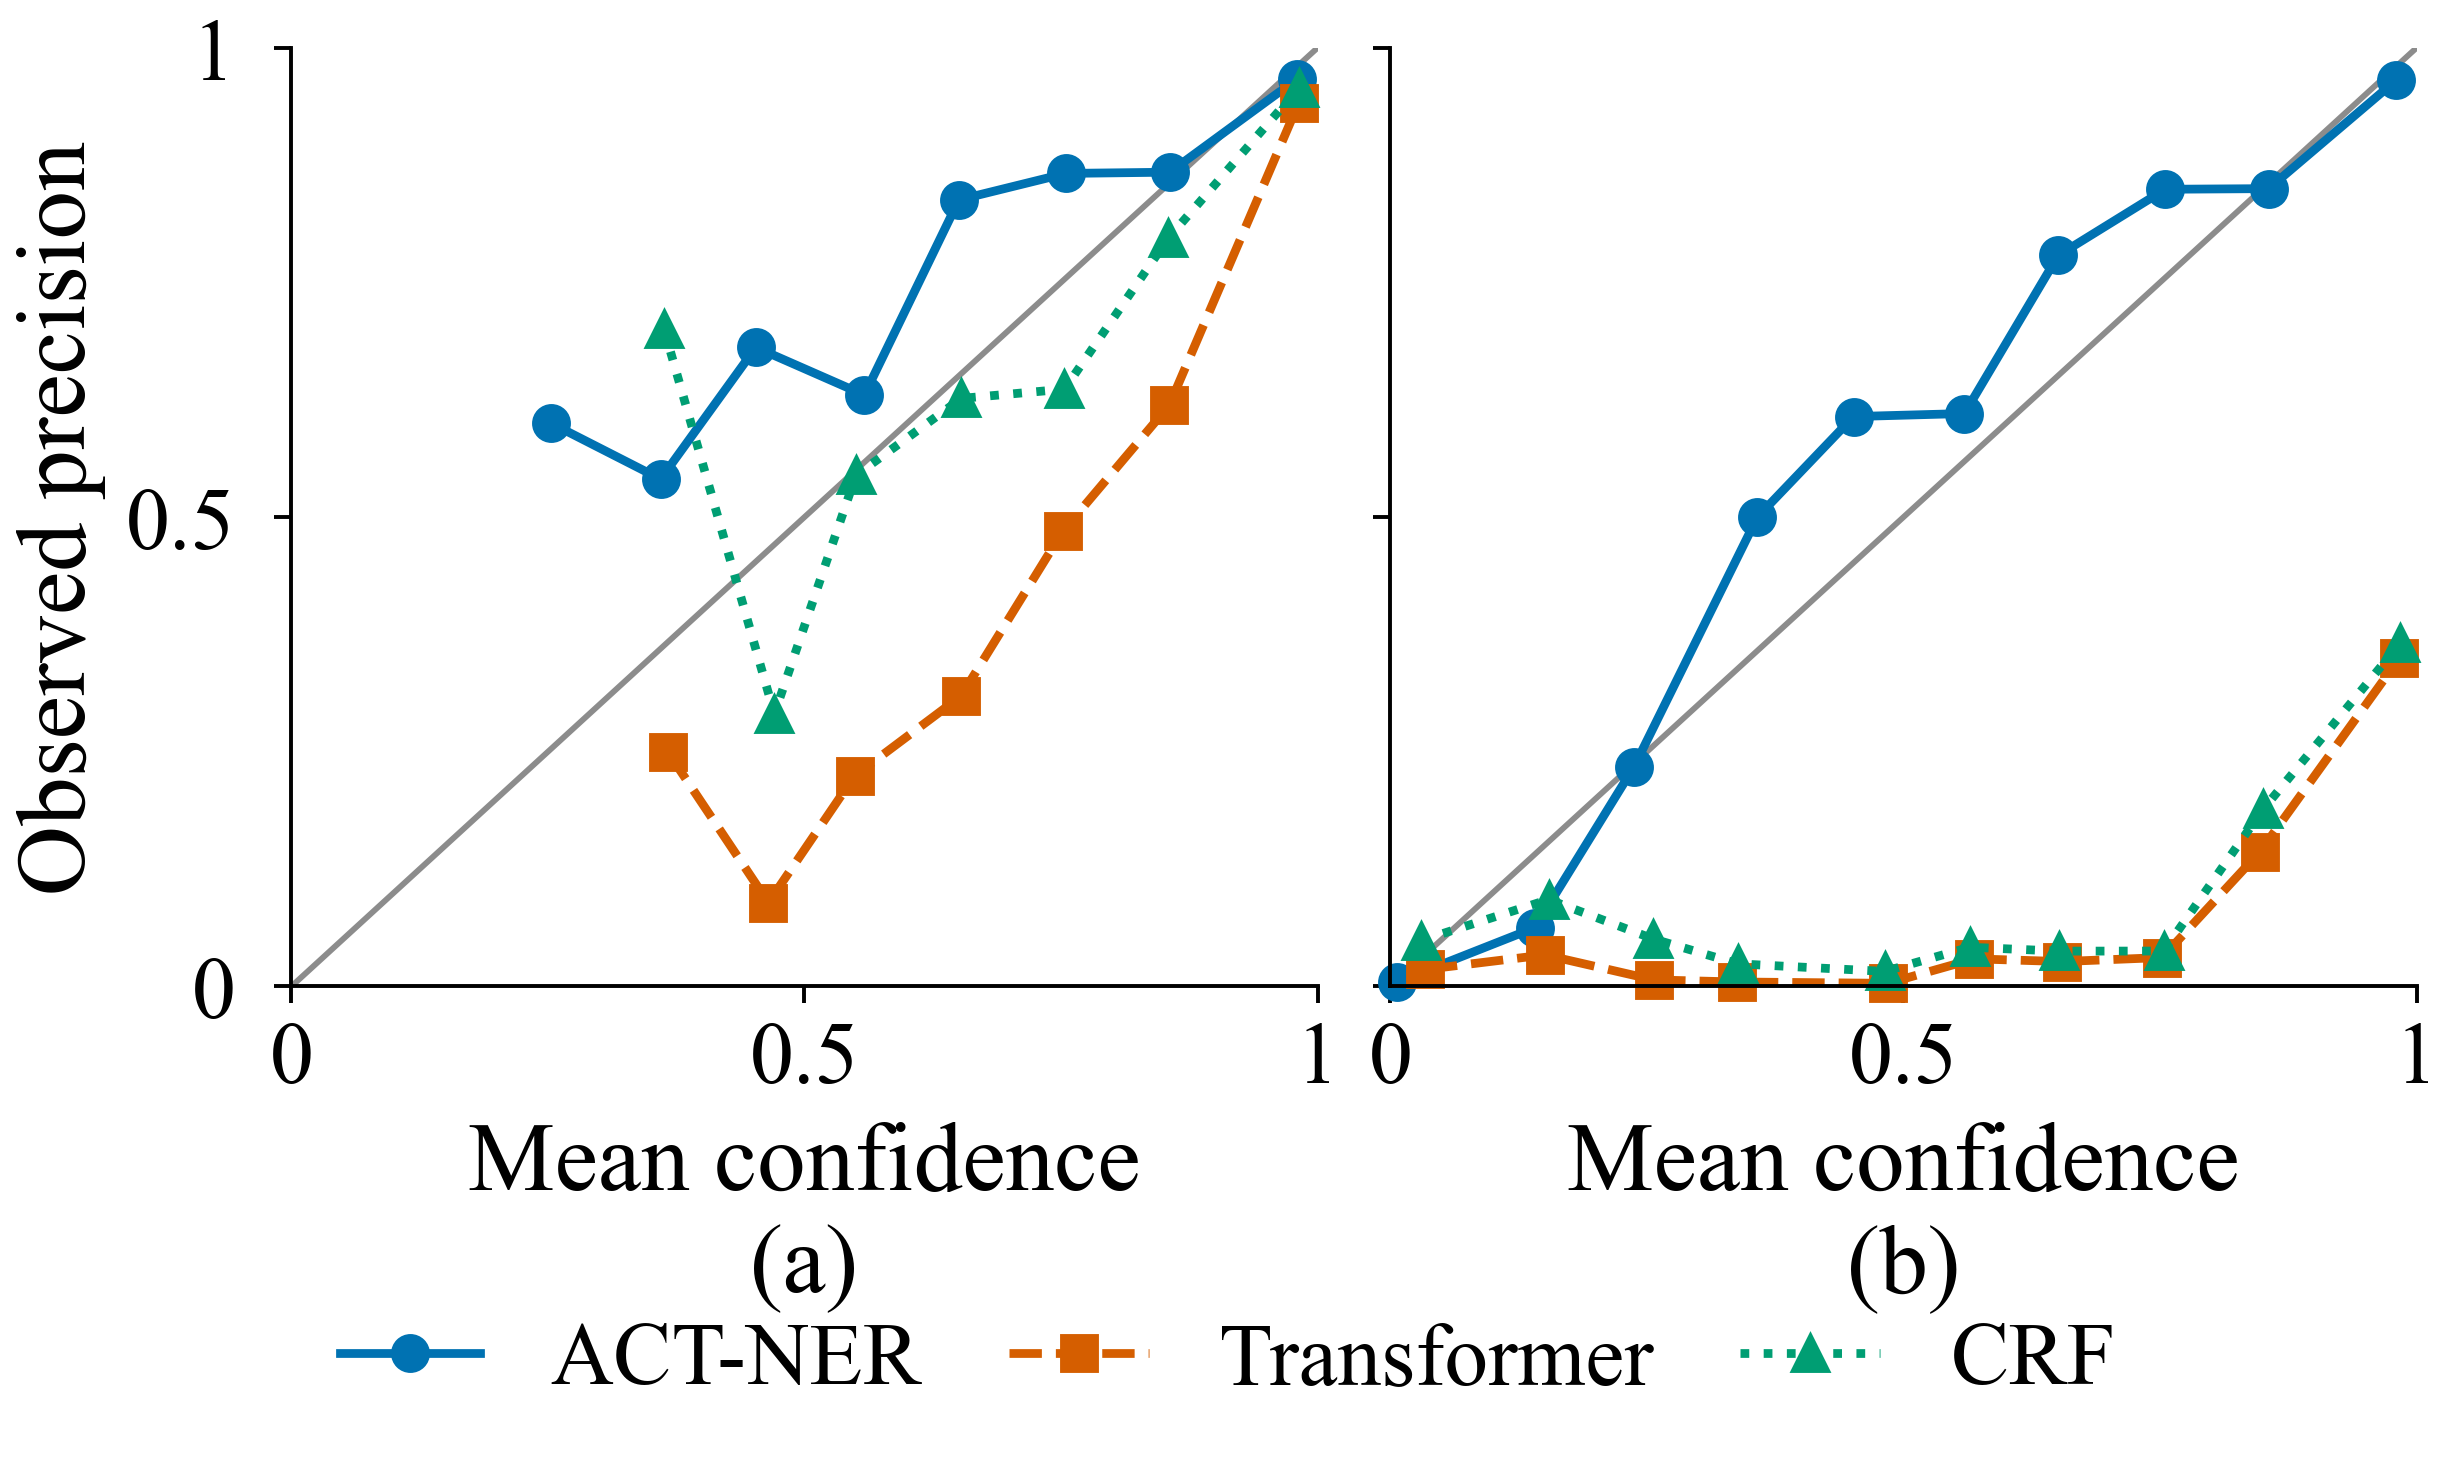

**Figure 7.1.** Reliability diagrams on Validation (original protocol), 10 equal-width confidence bins; bins with fewer than 10 spans are not drawn and the grey diagonal marks perfect calibration. (a) Accepted predictions of each model with its stored confidence (ACT-NER: reference seed 17). (b) Common candidate set of 16 912 spans: ACT-NER held-out entity probability after the post-hoc map (seed 17) and token-evidence proxies of the two frozen experts.

**Interpretation.** On accepted predictions the CRF has the lower ECE (0.0349 against 0.0434 for ACT-NER) and ACT-NER the lower Brier score (0.0711 against 0.0784); the ECE intervals are [0.0198, 0.0601] and [0.0333, 0.0594]. The statement that ACT-NER attains both the lowest Brier score and the lowest ECE is therefore not supported. On the common candidate set the calibrated ACT-NER probability has ECE 0.0090, while the expert proxies have 0.5782 and 0.5240; this difference reflects that the experts provide token evidence rather than trained span probabilities, and it must not be read as a like-for-like calibration contest.

In [65]:
reliability = pd.concat([pd.DataFrame(accepted_bins), pd.DataFrame(common_bins)], ignore_index=True)
save_table(reliability, "figure_7_01_reliability_source")
panel_models = {
    "Accepted predictions": [(ACT, "ACT-NER", "o", "-"), ("Biomedical Transformer", "Transformer", "s", "--"),
                             ("Linear-chain CRF", "CRF", "^", ":")],
    "Common candidate set": [(f"{ACT} (post-hoc calibrated)", "ACT-NER", "o", "-"),
                             ("Biomedical Transformer (token-evidence proxy)", "Transformer", "s", "--"),
                             ("Linear-chain CRF (token-evidence proxy)", "CRF", "^", ":")],
}
fig, axes = plt.subplots(1, 2, figsize=(7.0, 4.3), sharey=True)
for ax, (panel, models) in zip(axes, panel_models.items()):
    ax.plot([0, 1], [0, 1], color="0.55", linewidth=1.2)
    for (model, label, marker, style), color in zip(models, OKABE_ITO):
        part = reliability.query("Set == @panel and Model == @model and N >= 10")
        ax.plot(part["Mean confidence"], part["Observed precision"], marker=marker, linestyle=style,
                color=color, linewidth=1.8, markersize=7, label=label, clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
    ax.tick_params(axis="y", pad=8)                        # keeps the two origin labels apart
    ax.set_xlabel("Mean confidence")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Observed precision")
label_panels(axes)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, handlelength=1.6, columnspacing=1.0)
save_and_show(fig, "figure_7_01_reliability")
display(Markdown("**Figure 7.1.** Reliability diagrams on Validation (original protocol), 10 equal-width confidence "
                 "bins; bins with fewer than 10 spans are not drawn and the grey diagonal marks perfect calibration. "
                 "(a) Accepted predictions of each model with its stored confidence (ACT-NER: reference seed 17). "
                 "(b) Common candidate set of 16 912 spans: ACT-NER held-out entity probability after the post-hoc map "
                 "(seed 17) and token-evidence proxies of the two frozen experts."))
acc = accepted_table.set_index("Model")
com = common_table.set_index(["Model", "Confidence"])
note(f"**Interpretation.** On accepted predictions the CRF has the lower ECE "
     f"({acc.loc['Linear-chain CRF', 'ECE']:.4f} against {acc.loc[ACT, 'ECE']:.4f} for ACT-NER) and ACT-NER the lower "
     f"Brier score ({acc.loc[ACT, 'Brier']:.4f} against {acc.loc['Linear-chain CRF', 'Brier']:.4f}); the ECE intervals "
     f"are [{acc.loc['Linear-chain CRF', 'ECE CI low']:.4f}, {acc.loc['Linear-chain CRF', 'ECE CI high']:.4f}] and "
     f"[{acc.loc[ACT, 'ECE CI low']:.4f}, {acc.loc[ACT, 'ECE CI high']:.4f}]. The statement that ACT-NER attains both the "
     f"lowest Brier score and the lowest ECE is therefore not supported. On the common candidate set the calibrated "
     f"ACT-NER probability has ECE {com.loc[(ACT, 'Post-hoc calibrated'), 'ECE']:.4f}, while the expert proxies have "
     f"{com.loc[('Biomedical Transformer', 'Token-evidence proxy'), 'ECE']:.4f} and "
     f"{com.loc[('Linear-chain CRF', 'Token-evidence proxy'), 'ECE']:.4f}; this difference reflects that the experts "
     f"provide token evidence rather than trained span probabilities, and it must not be read as a like-for-like "
     f"calibration contest.")

## B08 – Why removing the context expert falls below both frozen experts

**Question.** The configuration without the context expert reaches a typed F1 of about 0.79, below the CRF (0.87) and the Transformer (0.86) on their own. Which gold entities does it lose?

**Method.** In this control the contextual span vector and the Transformer evidence are set to zero, while the candidate set stays the full expert union; no candidate is accepted automatically, so the head must verify and type every span from CRF marginal summaries, orthographic and lexical inputs only, after fitting on about 72 documents. Gold entities are grouped by how the candidate set contains them, and strict typed recall is computed per group from the saved held-out predictions (three seeds averaged for the two heads).

In [66]:
candidates = pd.read_parquet(SHARED / "Interim" / REFINEMENT / "validation" / "candidates.parquet")
origin = candidates.set_index(KEY)[["origin_crf", "origin_transformer"]]
gold_origin = validation.gold[KEY + ["entity_type", "document_id"]].join(origin, on=KEY)
gold_origin["Candidate origin"] = np.select(
    [gold_origin.origin_crf.isna(), gold_origin.origin_crf.eq(True),
     gold_origin.origin_transformer.eq(True)],
    ["Outside the candidate union", "Decoded by the CRF", "Decoded by the Transformer only"],
    default="Marginal run or one-token correction only")
ORIGIN_ORDER = ["Decoded by the CRF", "Decoded by the Transformer only",
                "Marginal run or one-token correction only", "Outside the candidate union"]
NO_CONTEXT = "Without Context Expert"
context_systems = {
    "Linear-chain CRF": original_validation["Linear-chain CRF"],
    "Biomedical Transformer": original_validation["Biomedical Transformer"],
    ACT: original_validation[ACT],
    NO_CONTEXT: read_repeats(original_crossfit / "without_context_expert"),
}


def recalled(frame: pd.DataFrame) -> np.ndarray:
    """For every gold entity: 1 if the predictions contain it with the correct type."""
    emitted = set(frame[KEY + ["predicted_type"]].itertuples(index=False, name=None))
    return np.array([key in emitted for key in gold_origin[KEY + ["entity_type"]].itertuples(index=False, name=None)])


origin_rows = []
for label in [*ORIGIN_ORDER, "All gold entities"]:
    mask = np.ones(len(gold_origin), bool) if label == "All gold entities" else gold_origin["Candidate origin"].eq(label).to_numpy()
    row = {"Gold entities by candidate origin": label, "Gold entities": int(mask.sum())}
    for name, repeats in context_systems.items():
        row[f"{name} typed recall"] = float(np.mean([recalled(frame)[mask].mean() for frame in repeats.values()]))
    origin_rows.append(row)
origin_table = pd.DataFrame(origin_rows)

crf_spans = set(original_validation["Linear-chain CRF"][0][KEY].itertuples(index=False, name=None))
emission_rows = []
for name, repeats in context_systems.items():
    emitted = [len(frame) for frame in repeats.values()]
    correct = [typed_correct(frame).sum() for frame in repeats.values()]
    shared = [np.mean([key in crf_spans for key in frame[KEY].itertuples(index=False, name=None)]) for frame in repeats.values()]
    kept = [len(crf_spans & set(frame[KEY].itertuples(index=False, name=None))) / len(crf_spans) for frame in repeats.values()]
    emission_rows.append({"Model": name, "Emitted entities (mean)": float(np.mean(emitted)),
                          "Typed precision": float(np.sum(correct) / np.sum(emitted)),
                          "Share of emitted spans also decoded by the CRF": float(np.mean(shared)),
                          "Share of CRF-decoded spans emitted": float(np.mean(kept))})
emission_table = pd.DataFrame(emission_rows)
save_table(origin_table, "table_7_14_context_control_recall_by_origin")
save_table(emission_table, "table_7_15_context_control_emissions")
display_table(origin_table, "Table 7.14. Strict typed recall on Validation by the way the candidate union contains each "
              "gold entity (original protocol; held-out predictions; the two span heads are means of three seeds).",
              index="Gold entities by candidate origin")
display_table(emission_table, "Table 7.15. Emitted entities, typed precision and overlap with the spans decoded by the "
              "frozen CRF for the same four systems on Validation.", index="Model", digits=4)
by_origin = origin_table.set_index("Gold entities by candidate origin")
emit = emission_table.set_index("Model")
note(f"**Interpretation.** The control is not a CRF with fewer inputs; it is a small span classifier that must re-derive "
     f"every decision from token-marginal summaries. On the {int(by_origin.loc['Decoded by the CRF', 'Gold entities'])} "
     f"gold entities that the CRF decodes, its typed recall is "
     f"{by_origin.loc['Decoded by the CRF', f'{NO_CONTEXT} typed recall']:.4f}, below the "
     f"{by_origin.loc['Decoded by the CRF', 'Linear-chain CRF typed recall']:.4f} of the CRF itself: it re-emits only "
     f"{emit.loc[NO_CONTEXT, 'Share of CRF-decoded spans emitted']:.1%} of the CRF-decoded spans. On the "
     f"{int(by_origin.loc['Decoded by the Transformer only', 'Gold entities'])} gold entities decoded only by the "
     f"Transformer it recovers {by_origin.loc['Decoded by the Transformer only', f'{NO_CONTEXT} typed recall']:.4f}, "
     f"against {by_origin.loc['Decoded by the Transformer only', 'Biomedical Transformer typed recall']:.4f} for the "
     f"Transformer and {by_origin.loc['Decoded by the Transformer only', f'{ACT} typed recall']:.4f} for the full model, "
     f"because without contextual states nothing identifies these spans. Its typed precision "
     f"({emit.loc[NO_CONTEXT, 'Typed precision']:.4f}) is also below that of the CRF "
     f"({emit.loc['Linear-chain CRF', 'Typed precision']:.4f}). The drop therefore measures the loss of the contextual "
     f"span representation in a head that still has to verify all candidates, not the value of a frozen expert on its own.")

**Table 7.14. Strict typed recall on Validation by the way the candidate union contains each gold entity (original protocol; held-out predictions; the two span heads are means of three seeds).**

,Gold entities,Linear-chain CRF typed recall,Biomedical Transformer typed recall,ACT-NER typed recall,Without Context Expert typed recall
Gold entities by candidate origin,,,,,
Decoded by the CRF,2543,0.9666,0.9229,0.9536,0.8592
Decoded by the Transformer only,263,0.0000,0.7795,0.7085,0.0773
Marginal run or one-token correction only,17,0.0000,0.0000,0.0588,0.0000
Outside the candidate union,92,0.0000,0.0000,0.0000,0.0000
All gold entities,2915,0.8432,0.8755,0.8962,0.7565


**Table 7.15. Emitted entities, typed precision and overlap with the spans decoded by the frozen CRF for the same four systems on Validation.**

,Emitted entities (mean),Typed precision,Share of emitted spans also decoded by the CRF,Share of CRF-decoded spans emitted
Model,,,,
Linear-chain CRF,2750.0000,0.8938,1.0000,1.0000
Biomedical Transformer,3052.0000,0.8362,0.8319,0.9233
ACT-NER,2830.6667,0.9229,0.9058,0.9324
Without Context Expert,2689.3333,0.8200,0.9199,0.8996


**Interpretation.** The control is not a CRF with fewer inputs; it is a small span classifier that must re-derive every decision from token-marginal summaries. On the 2543 gold entities that the CRF decodes, its typed recall is 0.8592, below the 0.9666 of the CRF itself: it re-emits only 90.0% of the CRF-decoded spans. On the 263 gold entities decoded only by the Transformer it recovers 0.0773, against 0.7795 for the Transformer and 0.7085 for the full model, because without contextual states nothing identifies these spans. Its typed precision (0.8200) is also below that of the CRF (0.8938). The drop therefore measures the loss of the contextual span representation in a head that still has to verify all candidates, not the value of a frozen expert on its own.

## B09 – Definition of the span-level inputs

**Question.** What exactly are the 14 orthographic features, the seven lexical reliability features, the five complexity indicators and the evidence vectors $\mathbf{e}_T$ and $\mathbf{e}_C$ that enter the router and the heads?

**Method.** The definitions are listed in the order of the executed implementation (`act_ner.build_candidate_bundle` and `prospective_model.ACTNER.forward`). Their dimensions are checked against the stored candidate tensors of Validation, and the mean of every input over the 16 912 Validation candidates is reported so that each row is tied to computed data.

In [67]:
features = torch.load(SHARED / "Interim" / REFINEMENT / "validation" / "features.pt", map_location="cpu",
                      weights_only=False)
TYPE_NAMES = [f"type probability: {t}" for t in ENTITY_TYPES]
definitions = {
    "Transformer evidence vector e_T (10 inputs)": (features["transformer"].numpy(), [
        ("span decoded by the Transformer", "1 if the BIOES argmax decoding of the Transformer emits exactly this span"),
        ("mean entity probability", "mean over span tokens of 1 − P(O)"),
        ("minimum entity probability", "minimum over span tokens of 1 − P(O)"),
        ("maximum entity probability", "maximum over span tokens of 1 − P(O)"),
        ("entity probability, first token", "1 − P(O) of the first span token"),
        ("entity probability, last token", "1 − P(O) of the last span token"),
        *[(name, "normalized sum over BIOES positions of the mean token probability of this type") for name in TYPE_NAMES]]),
    "CRF evidence vector e_C (12 inputs)": (features["crf"].numpy(), [
        ("span decoded by the CRF", "1 if Viterbi decoding of the CRF emits exactly this span"),
        ("mean entity marginal", "mean over span tokens of 1 − marginal P(O)"),
        ("minimum entity marginal", "minimum over span tokens of 1 − marginal P(O)"),
        ("maximum entity marginal", "maximum over span tokens of 1 − marginal P(O)"),
        ("entity marginal, first token", "1 − marginal P(O) of the first span token"),
        ("entity marginal, last token", "1 − marginal P(O) of the last span token"),
        ("sequence probability", "probability of the Viterbi label sequence of the sentence"),
        ("transition confidence", "mean marginal probability of the Viterbi labels of the sentence"),
        *[(name, "normalized sum over BIOES positions of the mean token marginal of this type") for name in TYPE_NAMES]]),
    "Orthographic features (14 inputs)": (features["orthographic"].numpy(), [
        ("character length", "min(characters, 80) / 80"),
        ("token length", "min(WordPiece tokens, 12) / 12"),
        ("multi-token", "1 if the span has more than one token"),
        ("all upper case", "1 if every letter is upper case"),
        ("initial capital", "1 if the first character is upper case"),
        ("contains digit", "1 if any character is a digit"),
        ("contains hyphen", "1 if the span contains '-'"),
        ("contains punctuation", "1 if any character is neither alphanumeric nor white space"),
        ("contains Greek letter", "1 if any character lies in α–ω"),
        ("drug-like suffix", "1 if the span ends in cillin, mycin, mab, vir, azole, pril, sartan or olol"),
        ("contains slash", "1 if the span contains '/'"),
        ("contains parenthesis", "1 if the span contains '(' or ')'"),
        ("source is DrugBank", "1 if the document source is DrugBank"),
        ("source is MedLine", "1 if the document source is MedLine")]),
    "Lexical reliability features (7 inputs)": (features["lexical"].numpy(), [
        ("in training lexicon", "1 if the normalized surface form occurs in the fold-training lexicon"),
        ("log frequency", "log(1 + frequency) / log(1 + maximum frequency) in the lexicon"),
        ("type entropy", "entropy of the lexicon type distribution of the form, divided by log 4"),
        ("ambiguity score", "normalized type entropy stored with the lexicon entry"),
        ("in training lexicon (repeated)", "identical to the first input; kept as implemented"),
        ("dominant type probability", "largest lexicon type probability of the form"),
        ("matches representative form", "1 if the form equals the normalized representative surface of the entry")]),
}
signal_columns = [("expert_agreement", "expert agreement", "1 if both experts decode the span and agree on its type"),
                  ("weak_signal", "weak-signal flag", "1 if type entropy of an expert > 0.85, or the experts disagree, or "
                   "the form is unseen, or a rare-type probability > 0.25, or the source is MedLine, or the span is "
                   "multi-token, or both mean entity scores are < 0.72"),
                  ("seen_in_train", "seen in training lexicon", "1 if the normalized surface form occurs in the lexicon"),
                  ("multi_token", "multi-token", "1 if the span has more than one token"),
                  ("rare_signal_probability", "rare-type probability", "largest of the brand and drug_n type "
                   "probabilities of the two experts")]
definitions["Complexity indicators of the router (5 inputs)"] = (
    candidates[[column for column, _, _ in signal_columns]].to_numpy(float),
    [(name, text) for _, name, text in signal_columns])
assert [values.shape[1] for values, _ in definitions.values()] == [10, 12, 14, 7, 5]
assert all(len(values) == len(candidates) == 16912 and values.shape[1] == len(rows) for values, rows in definitions.values())

input_table = pd.concat([pd.DataFrame({"Input group": group, "Position": np.arange(1, len(rows) + 1),
                                       "Input": [name for name, _ in rows], "Definition": [text for _, text in rows],
                                       "Mean over Validation candidates": values.mean(axis=0)})
                         for group, (values, rows) in definitions.items()], ignore_index=True)
save_table(input_table, "table_7_16_span_input_definitions")
for number, group in enumerate(definitions):
    display_table(input_table.loc[input_table["Input group"] == group].drop(columns="Input group"),
                  f"Table 7.16{'abcde'[number]}. {group}: executed definition and mean over the 16 912 Validation "
                  "candidate spans.", index="Position")
weak_share = float(candidates.weak_signal.mean())
note(f"**Interpretation.** The groups have 10, 12, 14, 7 and 5 inputs. Three properties are "
     f"worth noting: the document source enters twice as an orthographic one-hot input and once more through "
     f"the weak-signal flag; the lexical group contains the lexicon-membership indicator twice; and the weak-signal flag "
     f"is active for {weak_share:.1%} of the Validation candidates, so the prototype branch is available for most "
     f"candidates rather than for a small set of difficult ones.")

**Table 7.16a. Transformer evidence vector e_T (10 inputs): executed definition and mean over the 16 912 Validation candidate spans.**

,Input,Definition,Mean over Validation candidates
Position,,,
1,span decoded by the Transformer,1 if the BIOES argmax decoding of the Transformer emits exactly this span,0.1760
2,mean entity probability,mean over span tokens of 1 − P(O),0.7711
3,minimum entity probability,minimum over span tokens of 1 − P(O),0.4728
4,maximum entity probability,maximum over span tokens of 1 − P(O),0.9724
5,"entity probability, first token",1 − P(O) of the first span token,0.6563
6,"entity probability, last token",1 − P(O) of the last span token,0.6373
7,type probability: drug,normalized sum over BIOES positions of the mean token probability of this type,0.6340
8,type probability: brand,normalized sum over BIOES positions of the mean token probability of this type,0.0930
9,type probability: group,normalized sum over BIOES positions of the mean token probability of this type,0.2430


**Table 7.16b. CRF evidence vector e_C (12 inputs): executed definition and mean over the 16 912 Validation candidate spans.**

,Input,Definition,Mean over Validation candidates
Position,,,
1,span decoded by the CRF,1 if Viterbi decoding of the CRF emits exactly this span,0.1626
2,mean entity marginal,mean over span tokens of 1 − marginal P(O),0.6998
3,minimum entity marginal,minimum over span tokens of 1 − marginal P(O),0.4278
4,maximum entity marginal,maximum over span tokens of 1 − marginal P(O),0.8892
5,"entity marginal, first token",1 − marginal P(O) of the first span token,0.5949
6,"entity marginal, last token",1 − marginal P(O) of the last span token,0.5797
7,sequence probability,probability of the Viterbi label sequence of the sentence,0.6803
8,transition confidence,mean marginal probability of the Viterbi labels of the sentence,0.9704
9,type probability: drug,normalized sum over BIOES positions of the mean token marginal of this type,0.6214


**Table 7.16c. Orthographic features (14 inputs): executed definition and mean over the 16 912 Validation candidate spans.**

,Input,Definition,Mean over Validation candidates
Position,,,
1,character length,"min(characters, 80) / 80",0.1640
2,token length,"min(WordPiece tokens, 12) / 12",0.2440
3,multi-token,1 if the span has more than one token,0.8114
4,all upper case,1 if every letter is upper case,0.0618
5,initial capital,1 if the first character is upper case,0.1721
6,contains digit,1 if any character is a digit,0.0228
7,contains hyphen,1 if the span contains '-',0.0709
8,contains punctuation,1 if any character is neither alphanumeric nor white space,0.2507
9,contains Greek letter,1 if any character lies in α–ω,0.0000


**Table 7.16d. Lexical reliability features (7 inputs): executed definition and mean over the 16 912 Validation candidate spans.**

,Input,Definition,Mean over Validation candidates
Position,,,
1,in training lexicon,1 if the normalized surface form occurs in the fold-training lexicon,0.1520
2,log frequency,log(1 + frequency) / log(1 + maximum frequency) in the lexicon,0.0758
3,type entropy,"entropy of the lexicon type distribution of the form, divided by log 4",0.0028
4,ambiguity score,normalized type entropy stored with the lexicon entry,0.0028
5,in training lexicon (repeated),identical to the first input; kept as implemented,0.1520
6,dominant type probability,largest lexicon type probability of the form,0.1504
7,matches representative form,1 if the form equals the normalized representative surface of the entry,0.1520


**Table 7.16e. Complexity indicators of the router (5 inputs): executed definition and mean over the 16 912 Validation candidate spans.**

,Input,Definition,Mean over Validation candidates
Position,,,
1,expert agreement,1 if both experts decode the span and agree on its type,0.1432
2,weak-signal flag,"1 if type entropy of an expert > 0.85, or the experts disagree, or the form is unseen, or a rare-type probability > 0.25, or the source is MedLine, or the span is multi-token, or both mean entity scores are < 0.72",0.9414
3,seen in training lexicon,1 if the normalized surface form occurs in the lexicon,0.1520
4,multi-token,1 if the span has more than one token,0.8114
5,rare-type probability,largest of the brand and drug_n type probabilities of the two experts,0.1588


**Interpretation.** The groups have 10, 12, 14, 7 and 5 inputs. Three properties are worth noting: the document source enters twice as an orthographic one-hot input and once more through the weak-signal flag; the lexical group contains the lexicon-membership indicator twice; and the weak-signal flag is active for 94.1% of the Validation candidates, so the prototype branch is available for most candidates rather than for a small set of difficult ones.

## B10 – Origin and sensitivity of the 0.72 marginal threshold

**Question.** Where does the 0.72 threshold of the marginal candidate runs come from, and do coverage and candidate volume depend on it?

**Method.** The threshold is a fixed design constant of the implementation (`ACTNERConfig.marginal_threshold`); it was not tuned on any split. Its effect is measured by rebuilding the Validation candidate union from the same frozen expert outputs for five threshold values, without gold labels, and scoring boundary coverage afterwards.

In [68]:
from act_ner import ACTNERConfig, build_candidate_bundle, extract_frozen_expert_evidence

assert ACTNERConfig().marginal_threshold == 0.72
progress = display(Markdown("Frozen expert inference on Validation."), display_id=True)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    frozen_evidence = extract_frozen_expert_evidence(PROJECT, validation.tokens)
gold_boundaries = set(validation.gold[KEY].itertuples(index=False, name=None))
threshold_rows = []
for threshold in (0.50, 0.60, 0.72, 0.80, 0.90):
    progress.update(Markdown(f"Building the candidate union for marginal threshold {threshold:.2f}."))
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bundle, _, _ = build_candidate_bundle(PROJECT, validation.sentences, validation.entities.iloc[:0],
                                              validation.tokens, threshold, expert_evidence=frozen_evidence)
    frame = bundle.frame
    boundaries = set(frame[KEY].itertuples(index=False, name=None))
    marginal_only = ~frame[["origin_transformer", "origin_crf"]].any(axis=1)
    threshold_rows.append({"Marginal threshold": threshold, "Candidate spans": len(boundaries),
                           "Candidates not decoded by either expert": int(marginal_only.sum()),
                           "Boundary recall of the union": len(boundaries & gold_boundaries) / len(gold_boundaries),
                           "Candidates per gold entity": len(boundaries) / len(gold_boundaries)})
progress.update(Markdown("Candidate unions rebuilt for five thresholds from one set of frozen expert outputs."))
threshold_table = pd.DataFrame(threshold_rows)
reference = threshold_table.set_index("Marginal threshold").loc[0.72]
assert int(reference["Candidate spans"]) == 16912
save_table(threshold_table, "table_7_17_marginal_threshold_sensitivity")
display_table(threshold_table, "Table 7.17. Validation candidate union rebuilt for five values of the marginal-run "
              "threshold (2915 gold entities; frozen experts of the original protocol; no gold label enters candidate "
              "generation). The original value is 0.72.", index="Marginal threshold", digits=4)
spread = threshold_table["Boundary recall of the union"].max() - threshold_table["Boundary recall of the union"].min()
note(f"**Interpretation.** The value 0.72 is a fixed constant, not a tuned quantity. Between 0.50 and 0.90 the boundary "
     f"recall of the union changes by {spread:.4f} (from {threshold_table['Boundary recall of the union'].min():.4f} to "
     f"{threshold_table['Boundary recall of the union'].max():.4f}) and the number of candidates between "
     f"{int(threshold_table['Candidate spans'].min())} and {int(threshold_table['Candidate spans'].max())}; at 0.72 the "
     f"union holds {int(reference['Candidate spans'])} spans with recall {reference['Boundary recall of the union']:.4f}. "
     f"Coverage is driven by the decoded spans of the two experts and their one-token corrections, so the threshold is "
     f"not a sensitive design choice.")

Candidate unions rebuilt for five thresholds from one set of frozen expert outputs.

**Table 7.17. Validation candidate union rebuilt for five values of the marginal-run threshold (2915 gold entities; frozen experts of the original protocol; no gold label enters candidate generation). The original value is 0.72.**

,Candidate spans,Candidates not decoded by either expert,Boundary recall of the union,Candidates per gold entity
Marginal threshold,,,,
0.5000,16898,13746,0.9695,5.7969
0.6000,16862,13710,0.9681,5.7846
0.7200,16912,13760,0.9684,5.8017
0.8000,17007,13855,0.9684,5.8343
0.9000,17119,13967,0.9688,5.8727


**Interpretation.** The value 0.72 is a fixed constant, not a tuned quantity. Between 0.50 and 0.90 the boundary recall of the union changes by 0.0014 (from 0.9681 to 0.9695) and the number of candidates between 16862 and 17119; at 0.72 the union holds 16912 spans with recall 0.9684. Coverage is driven by the decoded spans of the two experts and their one-token corrections, so the threshold is not a sensitive design choice.

## B11 – Annotation audit: the four text/offset mismatches

**Question.** The annotation check finds four text/offset mismatches besides the 38 discontinuous entities. How are the four mismatches related to them?

**Method.** For every development annotation the text attribute of the XML is compared with the text reconstructed from its character offsets (fragments joined by a space for discontinuous annotations).

In [69]:
development_entities = pd.concat([train.entities, validation.entities], ignore_index=True)
sentence_text = pd.concat([train.sentences, validation.sentences]).set_index("sentence_id").text


def reconstructed_text(row) -> str:
    """Text addressed by the inclusive XML offsets, fragments joined by a space."""
    fragments = [tuple(int(v) for v in part.split("-")) for part in row.char_offset_xml.split(";")]
    return " ".join(sentence_text[row.sentence_id][start:end + 1] for start, end in fragments)


mismatches = development_entities.loc[~development_entities.text_exact].copy()
mismatches["Text addressed by the offsets"] = [reconstructed_text(row) for row in mismatches.itertuples(index=False)]
mismatch_table = mismatches[["entity_id", "split", "entity_type", "char_offset_xml", "entity_text",
                             "Text addressed by the offsets", "discontinuous"]].rename(columns={
    "entity_id": "Entity", "split": "Split", "entity_type": "Type", "char_offset_xml": "XML offsets",
    "entity_text": "XML text attribute", "discontinuous": "Discontinuous"})
mismatch_table["Discontinuous"] = mismatch_table["Discontinuous"].map({True: "yes", False: "no"})
save_table(mismatch_table, "table_7_18_text_offset_mismatches")
display_table(mismatch_table, "Table 7.18. Development annotations whose XML text attribute differs from the text "
              "addressed by their character offsets.", index="Entity")
n_discontinuous = int(development_entities.discontinuous.sum())
inside = int(mismatches.discontinuous.sum())
squeeze = lambda text: "".join(text.split())
joining_only = int(sum(squeeze(a) == squeeze(b) for a, b in
                       zip(mismatches.entity_text, mismatches["Text addressed by the offsets"])))
note(f"**Interpretation.** The development corpus has {len(development_entities)} annotations, {n_discontinuous} of them "
     f"discontinuous. All {len(mismatches)} mismatches concern discontinuous annotations ({inside} of {len(mismatches)}). "
     f"For {joining_only} of them the two texts are identical once white space is removed, so the difference only reflects "
     f"how the fragments are joined; for the remaining {len(mismatches) - joining_only} the offsets of the second fragment "
     f"address shifted characters. The mismatches are therefore part of the {n_discontinuous} discontinuous annotations "
     f"excluded from the contiguous estimand, not an additional exclusion, and no annotation was edited.")

**Table 7.18. Development annotations whose XML text attribute differs from the text addressed by their character offsets.**

,Split,Type,XML offsets,XML text attribute,Text addressed by the offsets,Discontinuous
Entity,,,,,,
DDI-DrugBank.d325.s6.e1,train,group,80-85;95-120,alpha-adrenergic blocking agents,alpha- adrenergic blocking agents,yes
DDI-DrugBank.d216.s16.e2,train,drug,95-98;107-114,(R)-warfarin,(R) -warfari,yes
DDI-MedLine.d75.s3.e0,train,group,44-46;70-86,mu-selective opioids,mu- selective opioids,yes
DDI-MedLine.d75.s3.e1,train,group,49-57;70-86,delta(1)-selective opioids,delta(1)- selective opioids,yes


**Interpretation.** The development corpus has 14765 annotations, 38 of them discontinuous. All 4 mismatches concern discontinuous annotations (4 of 4). For 3 of them the two texts are identical once white space is removed, so the difference only reflects how the fragments are joined; for the remaining 1 the offsets of the second fragment address shifted characters. The mismatches are therefore part of the 38 discontinuous annotations excluded from the contiguous estimand, not an additional exclusion, and no annotation was edited.

## B12 – Baselines refitted with the same Validation folds as ACT-NER

**Question.** How much of the Validation advantage of the original ACT-NER remains when the two baselines receive the same additional in-distribution labels?

**Method.** For each of the five outer Validation folds of the original cross-fit, a new linear-chain CRF and a new Biomedical Transformer are fitted on the 572 Train documents plus the Validation documents that the ACT-NER head of that fold used for fitting, with model selection (CRF regularization, Transformer early stopping) on the Validation documents that the head used for selection, and are scored on the held-out fold. The recipes are the registered ones of the project (Transformer: `NeuML/biomedbert-small`, all layers fine-tuned, at most 5 epochs, patience 2, learning rate 5 × 10⁻⁵, batch 24; CRF: three (c1, c2) candidates, 120 L-BFGS iterations). The Transformer is refitted for three seeds. The original ACT-NER predictions are not changed.

In [70]:
from transformers import AutoTokenizer

from models import (build_transformer_model, predict_linear_crf, predict_transformer, train_linear_crf,
                    train_transformer_comparator)
from prospective_data import (candidate_evidence, concatenate_bundles, group_folds, load_development,
                              split_group_holdout)
from prospective_experiments import annotate_candidates, load_bundle, save_bundle

EXPERT_PROTOCOL = json.loads((PROJECT / "src" / "prospective_protocol.json").read_text())
BACKBONE = EXPERT_PROTOCOL["transformer"]["backbone"]          # NeuML/biomedbert-small
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    small_tokenizer = AutoTokenizer.from_pretrained(BACKBONE, local_files_only=True)
development = load_development(PROJECT)                        # Train + Validation, 714 documents
train_ids = set(train.documents.document_id)


def sealed(directory: Path) -> dict | None:
    """Completion record of a finished fit unit, or None if the unit has not been fitted."""
    path = directory / "complete.json"
    return json.loads(path.read_text()) if path.exists() else None


def seal(directory: Path, record: dict) -> dict:
    with (directory / "complete.json").open("x", encoding="utf-8") as stream:
        json.dump(record, stream, indent=1)
    return record


def release_memory() -> None:
    """Collect unreachable Python objects first, then return cached GPU buffers to the system."""
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()


def fit_crf_unit(directory: Path, fit_ids: set[str], stop_ids: set[str]) -> dict:
    """Fit one linear-chain CRF; (c1, c2) are chosen on the stop documents from the registered grid."""
    record = sealed(directory)
    if record is not None:
        return record
    assert not fit_ids & stop_ids
    directory.mkdir(parents=True, exist_ok=True)
    training, stopping = development.subset(fit_ids), development.subset(stop_ids)
    started = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model, _, tuning = train_linear_crf(training.tokens, stopping.tokens, stopping.sentences, stopping.entities,
                                            candidates=[tuple(c) for c in EXPERT_PROTOCOL["crf"]["candidates"]])
    joblib.dump(model, directory / "crf.joblib")
    tuning.to_csv(directory / "selection.csv", index=False)
    best = tuning.sort_values(["Strict Typed Entity F1", "Strict Boundary F1", "c1", "c2"],
                              ascending=[False, False, True, True]).iloc[0]
    return seal(directory, {"model": "Linear-chain CRF", "fit_documents": len(fit_ids), "stop_documents": len(stop_ids),
                            "c1": float(best.c1), "c2": float(best.c2),
                            "stop_typed_f1": float(best["Strict Typed Entity F1"]),
                            "seconds": time.perf_counter() - started,
                            "fit_ids": sorted(fit_ids), "stop_ids": sorted(stop_ids)})


def fit_transformer_unit(directory: Path, fit_ids: set[str], stop_ids: set[str], seed: int, progress=None) -> dict:
    """Fine-tune one Biomedical Transformer; the epoch is chosen by early stopping on the stop documents."""
    record = sealed(directory)
    if record is not None:
        return record
    assert not fit_ids & stop_ids
    directory.mkdir(parents=True, exist_ok=True)
    training, stopping = development.subset(fit_ids), development.subset(stop_ids)
    settings = EXPERT_PROTOCOL["transformer"]

    def after_epoch(row: dict) -> None:
        release_memory()                                   # keeps the GPU allocation flat across epochs and fits
        if progress is not None:
            progress(row)

    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model, _, history, seconds, _ = train_transformer_comparator(
            BACKBONE, small_tokenizer, training.tokens, stopping.tokens, stopping.sentences, stopping.entities, seed,
            max_epochs=settings["max_epochs"], patience=settings["patience"],
            learning_rate=settings["learning_rate"], batch_size=settings["batch_size"], epoch_callback=after_epoch)
    # The membership block is the format read by prospective_data.expert_evidence (held-out check).
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
                "membership": {"fit_ids": sorted(fit_ids), "early_stop_ids": sorted(stop_ids), "seed": seed}},
               directory / "transformer.pt")
    history.to_csv(directory / "history.csv", index=False)
    best = history.sort_values(["Validation Strict Typed Entity F1", "Epoch"], ascending=[False, True]).iloc[0]
    del model
    release_memory()
    return seal(directory, {"model": "Biomedical Transformer", "seed": seed, "fit_documents": len(fit_ids),
                            "stop_documents": len(stop_ids), "epochs_run": int(history.Epoch.max()),
                            "selected_epoch": int(best.Epoch),
                            "stop_typed_f1": float(best["Validation Strict Typed Entity F1"]), "seconds": float(seconds)})


def crf_predictions(directory: Path, population, split: str) -> pd.DataFrame:
    return predict_linear_crf(joblib.load(directory / "crf.joblib"), population.tokens, population.sentences, split)


def transformer_predictions(directory: Path, population, split: str) -> pd.DataFrame:
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = build_transformer_model(BACKBONE)
    model.load_state_dict(torch.load(directory / "transformer.pt", map_location="cpu", weights_only=False)["state_dict"])
    prediction, _, _ = predict_transformer(model.to(DEVICE), population.tokens, population.sentences, small_tokenizer, split)
    del model
    release_memory()
    return prediction

In [71]:
EQUAL = RUN_MODELS / "equal_supervision"
EQUAL_PREDICTIONS = RUN_PREDICTIONS / "equal_supervision"
EQUAL_PREDICTIONS.mkdir(parents=True, exist_ok=True)
progress = display(Markdown("Equal-supervision baselines: starting."), display_id=True)
equal_units, equal_parts = [], {"Linear-chain CRF": {0: []}, "Biomedical Transformer": {seed: [] for seed in SEEDS}}
started = time.perf_counter()
for fold, roles in enumerate(fold_roles):
    fit_ids, stop_ids = train_ids | roles["train"], set(roles["selection"])
    held_out = validation.subset(roles["outer"], f"Validation fold {fold + 1}")
    progress.update(Markdown(f"Fold {fold + 1}/5 · linear-chain CRF on {len(fit_ids)} documents."))
    directory = EQUAL / f"fold_{fold}" / "crf"
    record = fit_crf_unit(directory, fit_ids, stop_ids)
    prediction = crf_predictions(directory, held_out, "Validation equal-supervision")
    equal_parts["Linear-chain CRF"][0].append(prediction)
    equal_units.append({"Model": "Linear-chain CRF", "Fold": fold + 1, "Seed": "n/a (deterministic)",
                        "Fit documents": record["fit_documents"], "Selection documents": record["stop_documents"],
                        "Selected setting": f"c1 = {record['c1']:g}, c2 = {record['c2']:g}",
                        "Selection typed F1": record["stop_typed_f1"],
                        "Held-out typed F1": strict_metrics(held_out.entities, prediction)["typed_f1"],
                        "Fit time (s)": record["seconds"]})
    for seed in SEEDS:
        def report(row, fold=fold, seed=seed):
            progress.update(Markdown(f"Fold {fold + 1}/5 · Biomedical Transformer, seed {seed} · epoch {int(row['Epoch'])}/"
                                     f"{EXPERT_PROTOCOL['transformer']['max_epochs']} · selection typed F1 "
                                     f"{row['Validation Strict Typed Entity F1']:.4f} · "
                                     f"{(time.perf_counter() - started) / 60:.1f} min elapsed"))
        directory = EQUAL / f"fold_{fold}" / f"transformer_seed_{seed}"
        record = fit_transformer_unit(directory, fit_ids, stop_ids, seed, report)
        prediction = transformer_predictions(directory, held_out, "Validation equal-supervision")
        equal_parts["Biomedical Transformer"][seed].append(prediction)
        equal_units.append({"Model": "Biomedical Transformer", "Fold": fold + 1, "Seed": str(seed),
                            "Fit documents": record["fit_documents"], "Selection documents": record["stop_documents"],
                            "Selected setting": f"epoch {record['selected_epoch']} of {record['epochs_run']}",
                            "Selection typed F1": record["stop_typed_f1"],
                            "Held-out typed F1": strict_metrics(held_out.entities, prediction)["typed_f1"],
                            "Fit time (s)": record["seconds"]})
CRF_EQUAL, TRANSFORMER_EQUAL = "Linear-chain CRF (Train + folds)", "Biomedical Transformer (Train + folds)"
equal_validation = {CRF_EQUAL: {0: pd.concat(equal_parts["Linear-chain CRF"][0], ignore_index=True)},
                    TRANSFORMER_EQUAL: {seed: pd.concat(parts, ignore_index=True)
                                        for seed, parts in equal_parts["Biomedical Transformer"].items()}}
for name, repeats in equal_validation.items():
    for seed, frame in repeats.items():
        assert set(frame.document_id) <= validation_ids and not frame.duplicated(KEY).any()
        frame.to_parquet(EQUAL_PREDICTIONS / f"{name.split(' (')[0].lower().replace(' ', '_').replace('-', '_')}_seed_{seed}.parquet",
                         index=False)
equal_unit_table = pd.DataFrame(equal_units)
progress.update(Markdown(f"Equal-supervision baselines: {len(equal_unit_table)} fit units over five folds "
                         f"({equal_unit_table['Fit time (s)'].sum() / 60:.1f} min of fitting)."))
save_table(equal_unit_table, "table_7_19_equal_supervision_units")
display_table(equal_unit_table, "Table 7.19. Fit units of the equal-supervision baselines: for each outer Validation fold "
              "the model is fitted on Train plus the fold's ACT-NER fitting documents, selected on the fold's ACT-NER "
              "selection documents and scored on the held-out fold.", index=["Model", "Fold", "Seed"], digits=4)

Equal-supervision baselines: 20 fit units over five folds (65.8 min of fitting).

**Table 7.19. Fit units of the equal-supervision baselines: for each outer Validation fold the model is fitted on Train plus the fold's ACT-NER fitting documents, selected on the fold's ACT-NER selection documents and scored on the held-out fold.**

Fit documents  \
Model                  Fold Seed                                
Linear-chain CRF       1    n/a (deterministic)           644   
Biomedical Transformer 1    17                            644   
                            29                            644   
                            43                            644   
Linear-chain CRF       2    n/a (deterministic)           644   
Biomedical Transformer 2    17                            644   
                            29                            644   
                            43                            644   
Linear-chain CRF       3    n/a (deterministic)           644   
Biomedical Transformer 3    17                            644   
                            29                            644   
                            43                            644   
Linear-chain CRF       4    n/a (deterministic)           644   
Biomedical Transformer 4    17                            644   
                            29                            644   
                            43                            644   
Linear-chain CRF       5    n/a (deterministic)           644   
Biomedical Transformer 5    17                            644   
                            29                            644   
                            43                            644   

                                                Selection documents  \
Model                  Fold Seed                                      
Linear-chain CRF       1    n/a (deterministic)                  19   
Biomedical Transformer 1    17                                   19   
                            29                                   19   
                            43                                   19   
Linear-chain CRF       2    n/a (deterministic)                  18   
Biomedical Transformer 2    17                                   18   
                            29                                   18   
                            43                                   18   
Linear-chain CRF       3    n/a (deterministic)                  19   
Biomedical Transformer 3    17                                   19   
                            29                                   19   
                            43                                   19   
Linear-chain CRF       4    n/a (deterministic)                  19   
Biomedical Transformer 4    17                                   19   
                            29                                   19   
                            43                                   19   
Linear-chain CRF       5    n/a (deterministic)                  19   
Biomedical Transformer 5    17                                   19   
                            29                                   19   
                            43                                   19   

                                                     Selected setting  \
Model                  Fold Seed                                        
Linear-chain CRF       1    n/a (deterministic)  c1 = 0.05, c2 = 0.05   
Biomedical Transformer 1    17                           epoch 5 of 5   
                            29                           epoch 5 of 5   
                            43                           epoch 5 of 5   
Linear-chain CRF       2    n/a (deterministic)  c1 = 0.05, c2 = 0.05   
Biomedical Transformer 2    17                           epoch 5 of 5   
                            29                           epoch 4 of 5   
                            43                           epoch 5 of 5   
Linear-chain CRF       3    n/a (deterministic)    c1 = 0.1, c2 = 0.1   
Biomedical Transformer 3    17                           epoch 5 of 5   
                            29                           epoch 4 of 5   
                            43                           epoch 5 of 5   
Linear-chain CRF       4    n/a 

In [72]:
equal_predictions = {ACT: original_validation[ACT], SPAN_MLP: original_validation[SPAN_MLP],
                     "Linear-chain CRF (Train only)": original_validation["Linear-chain CRF"], **{CRF_EQUAL: equal_validation[CRF_EQUAL]},
                     "Biomedical Transformer (Train only)": original_validation["Biomedical Transformer"],
                     TRANSFORMER_EQUAL: equal_validation[TRANSFORMER_EQUAL]}
EQUAL_MODELS = tuple(equal_predictions)
equal_intervals = metric_intervals(validation, equal_predictions, EQUAL_MODELS)
save_table(equal_intervals, "table_7_20_equal_supervision_intervals")
display_table(interval_view(equal_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], EQUAL_MODELS),
              "Table 7.20. Validation (142 documents, 2915 gold entities): strict typed F1, boundary F1 and macro-F1 with "
              "95 % cluster-bootstrap intervals for the original ACT-NER and span MLP (cross-fit heads), the original "
              "baselines (fitted on Train only) and the same baselines refitted with the Validation folds of ACT-NER.",
              index="Model")
display_table(interval_view(equal_intervals, ["brand F1", "drug_n F1", "DrugBank typed F1", "MedLine typed F1"], EQUAL_MODELS),
              "Table 7.21. Same systems: strict F1 of the two entity types with the highest lexical novelty and strict "
              "typed F1 by source, with 95 % cluster-bootstrap intervals.", index="Model")
equal_evidence = paired_evidence(equal_predictions, validation.sentences, validation.entities, validation.documents,
                                 [(ACT, CRF_EQUAL), (ACT, TRANSFORMER_EQUAL), (SPAN_MLP, CRF_EQUAL), (SPAN_MLP, TRANSFORMER_EQUAL)],
                                 replicates=N_RESAMPLES)
equal_paired = equal_evidence[["Comparison", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
    columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p"})
save_table(equal_paired, "table_7_22_equal_supervision_paired")
display_table(equal_paired, "Table 7.22. Paired differences in strict typed F1 on Validation against the equal-supervision "
              "baselines: 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of four).",
              index="Comparison", signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
value = equal_intervals.query("Metric == 'Typed F1'").set_index("Model").Estimate
gain_crf = value[CRF_EQUAL] - value["Linear-chain CRF (Train only)"]
gain_transformer = value[TRANSFORMER_EQUAL] - value["Biomedical Transformer (Train only)"]
remaining = equal_paired.set_index("Comparison")
old_gap = value[ACT] - max(value["Linear-chain CRF (Train only)"], value["Biomedical Transformer (Train only)"])
new_gap = value[ACT] - max(value[CRF_EQUAL], value[TRANSFORMER_EQUAL])
kept = remaining.loc[[f"{ACT} − {CRF_EQUAL}", f"{ACT} − {TRANSFORMER_EQUAL}"]]
n_supported = int(((kept["CI low"] > 0) & (kept["Holm-adjusted p"] < 0.05)).sum())
note(f"**Interpretation.** Adding the Validation folds changes the CRF by {fmt_signed(gain_crf)} typed F1 "
     f"({value['Linear-chain CRF (Train only)']:.4f} → {value[CRF_EQUAL]:.4f}) and the Biomedical Transformer by "
     f"{fmt_signed(gain_transformer)} ({value['Biomedical Transformer (Train only)']:.4f} → {value[TRANSFORMER_EQUAL]:.4f}). "
     f"The gap between ACT-NER ({value[ACT]:.4f}) and the stronger baseline moves from {fmt_signed(old_gap)} with "
     f"Train-only baselines to {fmt_signed(new_gap)} with equal supervision"
     + (f", that is, {(1 - new_gap / old_gap):.0%} of the original advantage is attributable to the additional "
        f"Validation labels. " if new_gap < old_gap else "; the advantage does not shrink under equal supervision. ")
     + f"A positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 remains for {n_supported} of "
     f"the 2 baseline comparisons (Table 7.22).")

**Table 7.20. Validation (142 documents, 2915 gold entities): strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals for the original ACT-NER and span MLP (cross-fit heads), the original baselines (fitted on Train only) and the same baselines refitted with the Validation folds of ACT-NER.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
ACT-NER,"0.9093 [0.8858, 0.9291]","0.9434 [0.9266, 0.9574]","0.8221 [0.7517, 0.8706]"
Parameter-matched span MLP,"0.9023 [0.8774, 0.9234]","0.9444 [0.9282, 0.9583]","0.8072 [0.7460, 0.8511]"
Linear-chain CRF (Train only),"0.8678 [0.8355, 0.8956]","0.8978 [0.8721, 0.9208]","0.7301 [0.6520, 0.7967]"
Linear-chain CRF (Train + folds),"0.8700 [0.8397, 0.8966]","0.9004 [0.8748, 0.9231]","0.7287 [0.6476, 0.7965]"
Biomedical Transformer (Train only),"0.8554 [0.8255, 0.8806]","0.9097 [0.8885, 0.9272]","0.6762 [0.6282, 0.7266]"
Biomedical Transformer (Train + folds),"0.8744 [0.8492, 0.8965]","0.9231 [0.9029, 0.9400]","0.7300 [0.6732, 0.7822]"


**Table 7.21. Same systems: strict F1 of the two entity types with the highest lexical novelty and strict typed F1 by source, with 95 % cluster-bootstrap intervals.**

Metric,brand F1,drug_n F1,DrugBank typed F1,MedLine typed F1
Model,,,,
ACT-NER,"0.9103 [0.8472, 0.9506]","0.5704 [0.3105, 0.7454]","0.9211 [0.8992, 0.9394]","0.8259 [0.7299, 0.9041]"
Parameter-matched span MLP,"0.8876 [0.8166, 0.9366]","0.5336 [0.3161, 0.6836]","0.9131 [0.8884, 0.9340]","0.8252 [0.7502, 0.8869]"
Linear-chain CRF (Train only),"0.8394 [0.7375, 0.9117]","0.3307 [0.0426, 0.5667]","0.8841 [0.8518, 0.9111]","0.7463 [0.6502, 0.8291]"
Linear-chain CRF (Train + folds),"0.8324 [0.7264, 0.9066]","0.3182 [0.0204, 0.5692]","0.8861 [0.8560, 0.9118]","0.7500 [0.6561, 0.8297]"
Biomedical Transformer (Train only),"0.7603 [0.6581, 0.8491]","0.2112 [0.0552, 0.3824]","0.8778 [0.8521, 0.9003]","0.7017 [0.5860, 0.8097]"
Biomedical Transformer (Train + folds),"0.7844 [0.6885, 0.8644]","0.3630 [0.1740, 0.5457]","0.8913 [0.8686, 0.9119]","0.7564 [0.6615, 0.8436]"


**Table 7.22. Paired differences in strict typed F1 on Validation against the equal-supervision baselines: 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of four).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
ACT-NER − Linear-chain CRF (Train + folds),+0.0394,0.0219,0.0599,< 0.001
ACT-NER − Biomedical Transformer (Train + folds),+0.0349,0.0176,0.0540,< 0.001
Parameter-matched span MLP − Linear-chain CRF (Train + folds),+0.0323,0.0171,0.0497,< 0.001
Parameter-matched span MLP − Biomedical Transformer (Train + folds),+0.0279,0.0056,0.0504,0.014


**Interpretation.** Adding the Validation folds changes the CRF by +0.0022 typed F1 (0.8678 → 0.8700) and the Biomedical Transformer by +0.0190 (0.8554 → 0.8744). The gap between ACT-NER (0.9093) and the stronger baseline moves from +0.0415 with Train-only baselines to +0.0349 with equal supervision, that is, 16% of the original advantage is attributable to the additional Validation labels. A positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 remains for 2 of the 2 baseline comparisons (Table 7.22).

## B13 – Stacking protocol: out-of-fold experts over Train

**Question.** Can the span head be trained without any Validation label for fitting, so that every model fits the same 572 Train documents?

**Method (registered before the first fit of this section).** The 572 Train documents are divided into five folds that keep exact-text dependency clusters together and stratify by source and rare types. For each fold a new CRF and a new Biomedical Transformer are fitted on the other four folds (seed 17), using an internal stop set of about one seventh of those documents for model selection, and produce evidence for the held-out fold. The union of the five held-out candidate sets gives out-of-fold training candidates for every Train document; lexical reliability inputs come from the fold-training lexicon only. The final experts are fitted on all Train documents with the same recipe and an internal stop set; the Transformer is fitted for seeds 17, 29 and 43 (seed 17 is the expert, all three are the Train-only baseline). No Validation, test or reserve document enters any expert. Candidate generation never reads gold labels; targets are attached afterwards.

In [73]:
STACK = RUN_MODELS / "stacking"
STACK_CANDIDATES = RUN_PREDICTIONS / "stacking" / "candidates"
STACK_PROTOCOL = {
    "run": STACKING_RUN, "expert_recipe": {"transformer": EXPERT_PROTOCOL["transformer"], "crf": EXPERT_PROTOCOL["crf"]},
    "oof_folds": 5, "oof_partition_seed": 1701, "expert_stop_fraction": EXPERT_PROTOCOL["expert_early_stop_fraction"],
    "expert_seed": REFERENCE_SEED, "baseline_transformer_seeds": list(SEEDS),
    "candidate_marginal_threshold": EXPERT_PROTOCOL["candidate_marginal_threshold"],
    "head_configuration": "Joint-A of the original model (dropout 0.10, router hidden size 128, effective-number type loss)",
    "head_optimisation": {"epochs": 8, "batch_size": 512, "learning_rate": 0.001, "gradient_clip": 1.0,
                          "threshold_grid": [0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]},
    "head_seeds": list(SEEDS),
    "validation_role": "Selection of epoch and threshold, and post-hoc confidence calibration; never parameter fitting",
    "validation_estimate": "Five outer folds of the original cross-fit; epoch, threshold and calibrator of fold k are "
                           "chosen on the other four folds",
    "frozen_model": "Epoch, threshold and calibrator chosen on all Validation documents (role partition of the "
                    "original final fit); then scored once on the official DrugNER test set and on the reserve",
    "test_and_reserve": "Frozen evaluation only; both populations were inspected by earlier model versions",
    "statistics": {"resamples": N_RESAMPLES, "seed": STAT_SEED, "unit": "exact-text dependency cluster"},
}
protocol_path = RUN_REPORTS / "stacking_protocol.json"
if protocol_path.exists():
    assert json.loads(protocol_path.read_text()) == STACK_PROTOCOL, "the registered protocol must not change"
else:
    protocol_path.write_text(json.dumps(STACK_PROTOCOL, indent=1), encoding="utf-8")

train_documents = development.documents.loc[development.documents.document_id.isin(train_ids)].reset_index(drop=True)
oof_fold = group_folds(train_documents, STACK_PROTOCOL["oof_folds"], STACK_PROTOCOL["oof_partition_seed"])
assert len(oof_fold) == len(train_ids)


def expert_roles(fold: int | None) -> tuple[set[str], set[str], set[str]]:
    """Fit, stop and held-out Train documents of one out-of-fold unit (fold None: final experts)."""
    held_out = set() if fold is None else set(oof_fold.index[oof_fold == fold])
    available = train_documents.loc[~train_documents.document_id.isin(held_out)]
    fit_ids, stop_ids = split_group_holdout(available, STACK_PROTOCOL["expert_stop_fraction"],
                                            STACK_PROTOCOL["oof_partition_seed"] + 100 * (0 if fold is None else fold + 1))
    assert not (fit_ids & stop_ids or fit_ids & held_out or stop_ids & held_out)
    return fit_ids, stop_ids, held_out


def fit_expert_pair(directory: Path, fit_ids: set[str], stop_ids: set[str], seed: int, progress=None) -> dict:
    """One CRF and one Transformer in the same directory, as read by prospective_data.candidate_evidence."""
    crf = fit_crf_unit(directory / "crf_unit", fit_ids, stop_ids)
    if not (directory / "crf.joblib").exists():
        joblib.dump(joblib.load(directory / "crf_unit" / "crf.joblib"), directory / "crf.joblib")
    transformer = fit_transformer_unit(directory, fit_ids, stop_ids, seed, progress)
    return {"crf": crf, "transformer": transformer}

In [74]:
progress = display(Markdown("Out-of-fold experts: starting."), display_id=True)
started = time.perf_counter()
expert_units, oof_bundles, oof_expert_predictions = [], [], {"Linear-chain CRF": [], "Biomedical Transformer": []}
for fold in range(STACK_PROTOCOL["oof_folds"]):
    fit_ids, stop_ids, held_out = expert_roles(fold)
    directory = STACK / "experts" / f"oof_fold_{fold}"

    def report(row, fold=fold):
        progress.update(Markdown(f"Out-of-fold experts, fold {fold + 1}/5 · Transformer epoch {int(row['Epoch'])} · stop typed F1 "
                                 f"{row['Validation Strict Typed Entity F1']:.4f} · {(time.perf_counter() - started) / 60:.1f} min elapsed"))
    progress.update(Markdown(f"Out-of-fold experts, fold {fold + 1}/5 · linear-chain CRF on {len(fit_ids)} documents."))
    record = fit_expert_pair(directory, fit_ids, stop_ids, STACK_PROTOCOL["expert_seed"], report)
    cache = STACK_CANDIDATES / f"train_oof_fold_{fold}"
    observed, fold_training = development.subset(held_out), development.subset(fit_ids | stop_ids)
    progress.update(Markdown(f"Out-of-fold experts, fold {fold + 1}/5 · held-out evidence for {len(held_out)} documents."))
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bundle, predictions, _ = candidate_evidence(PROJECT, observed, fold_training, directory, EXPERT_PROTOCOL,
                                                    include_gold_support=False)
    bundle = annotate_candidates(bundle, observed.entities)       # targets are attached after generation
    if not (cache / "complete.json").exists():
        save_bundle(bundle, cache)
    oof_bundles.append(bundle)
    for name, frame in predictions.items():
        oof_expert_predictions[name].append(frame)
    expert_units.append({"Unit": f"Out-of-fold {fold + 1}/5", "Fit documents": len(fit_ids), "Stop documents": len(stop_ids),
                         "Held-out documents": len(held_out), "CRF setting": f"c1 = {record['crf']['c1']:g}, c2 = {record['crf']['c2']:g}",
                         "Transformer epoch": f"{record['transformer']['selected_epoch']} of {record['transformer']['epochs_run']}",
                         "CRF held-out typed F1": strict_metrics(observed.entities, predictions["Linear-chain CRF"])["typed_f1"],
                         "Transformer held-out typed F1": strict_metrics(observed.entities, predictions["Biomedical Transformer"])["typed_f1"],
                         "Fit time (s)": record["crf"]["seconds"] + record["transformer"]["seconds"]})
train_oof = concatenate_bundles(oof_bundles)
assert set(train_oof.frame.document_id) <= train_ids and train_oof.frame.generated_candidate.all()

final_fit, final_stop, _ = expert_roles(None)
final_units = []
for seed in SEEDS:
    def report(row, seed=seed):
        progress.update(Markdown(f"Final experts on Train · Transformer seed {seed} · epoch {int(row['Epoch'])} · stop typed F1 "
                                 f"{row['Validation Strict Typed Entity F1']:.4f} · {(time.perf_counter() - started) / 60:.1f} min elapsed"))
    directory = STACK / "experts" / f"final_seed_{seed}"
    if seed == STACK_PROTOCOL["expert_seed"]:
        record = fit_expert_pair(directory, final_fit, final_stop, seed, report)
        final_units.append({"Unit": "Final CRF (all Train)", "Fit documents": len(final_fit), "Stop documents": len(final_stop),
                            "Selected setting": f"c1 = {record['crf']['c1']:g}, c2 = {record['crf']['c2']:g}",
                            "Stop typed F1": record["crf"]["stop_typed_f1"], "Fit time (s)": record["crf"]["seconds"]})
        record = record["transformer"]
    else:
        record = fit_transformer_unit(directory, final_fit, final_stop, seed, report)
    final_units.append({"Unit": f"Final Transformer (all Train), seed {seed}", "Fit documents": len(final_fit),
                        "Stop documents": len(final_stop),
                        "Selected setting": f"epoch {record['selected_epoch']} of {record['epochs_run']}",
                        "Stop typed F1": record["stop_typed_f1"], "Fit time (s)": record["seconds"]})
expert_unit_table, final_unit_table = pd.DataFrame(expert_units), pd.DataFrame(final_units)
progress.update(Markdown(f"Experts of the stacking protocol: 5 out-of-fold pairs and the final Train experts "
                         f"({(expert_unit_table['Fit time (s)'].sum() + final_unit_table['Fit time (s)'].sum()) / 60:.1f} min of fitting)."))
save_table(expert_unit_table, "table_7_23_stacking_oof_expert_units")
save_table(final_unit_table, "table_7_24_stacking_final_expert_units")
display_table(expert_unit_table, "Table 7.23. Out-of-fold expert pairs over Train: document roles, selected settings and strict "
              "typed F1 of each expert on its held-out Train fold (documents not used for fitting or selection).",
              index="Unit", digits=4)
display_table(final_unit_table, "Table 7.24. Final experts of the stacking protocol, fitted on Train with an internal stop set; "
              "the stop documents are part of Train, so the stop typed F1 is a selection value, not an evaluation.",
              index="Unit", digits=4)

Experts of the stacking protocol: 5 out-of-fold pairs and the final Train experts (30.4 min of fitting).

**Table 7.23. Out-of-fold expert pairs over Train: document roles, selected settings and strict typed F1 of each expert on its held-out Train fold (documents not used for fitting or selection).**

,Fit documents,Stop documents,Held-out documents,CRF setting,Transformer epoch,CRF held-out typed F1,Transformer held-out typed F1,Fit time (s)
Unit,,,,,,,,
Out-of-fold 1/5,391,66,115,"c1 = 0.05, c2 = 0.05",5 of 5,0.8249,0.8261,291.8982
Out-of-fold 2/5,391,66,115,"c1 = 0.1, c2 = 0.1",5 of 5,0.8718,0.8916,178.5494
Out-of-fold 3/5,393,65,114,"c1 = 0.1, c2 = 0.1",4 of 5,0.8179,0.8099,193.5627
Out-of-fold 4/5,392,66,114,"c1 = 0.05, c2 = 0.05",4 of 5,0.8233,0.8025,430.2480
Out-of-fold 5/5,392,66,114,"c1 = 0.1, c2 = 0.01",5 of 5,0.8740,0.8724,187.8363


**Table 7.24. Final experts of the stacking protocol, fitted on Train with an internal stop set; the stop documents are part of Train, so the stop typed F1 is a selection value, not an evaluation.**

,Fit documents,Stop documents,Selected setting,Stop typed F1,Fit time (s)
Unit,,,,,
Final CRF (all Train),490,82,"c1 = 0.1, c2 = 0.1",0.8611,54.8831
"Final Transformer (all Train), seed 17",490,82,epoch 4 of 5,0.8439,159.9059
"Final Transformer (all Train), seed 29",490,82,epoch 5 of 5,0.8408,182.8974
"Final Transformer (all Train), seed 43",490,82,epoch 5 of 5,0.8504,147.2168


## B14 – Stacking protocol: candidate evidence for every population

**Question.** Do the out-of-fold Train candidates resemble the candidates that the final experts produce on unseen documents, and how many gold boundaries does the candidate union cover in each population?

**Method.** The final experts (seed 17) produce candidate evidence for Validation, the official DrugNER test set and all reserved documents; lexical reliability inputs use the full Train lexicon. Coverage is the share of gold boundaries contained in the spans decoded by each expert and in the complete candidate union. Gold labels are attached only after candidate generation.

In [75]:
train_population = development.subset(train_ids)
final_experts = STACK / "experts" / f"final_seed_{STACK_PROTOCOL['expert_seed']}"
progress = display(Markdown("Candidate evidence of the final experts: starting."), display_id=True)
stack_bundles, final_expert_predictions = {"Train (out-of-fold)": train_oof}, {}
for population in (validation, test, reserve_all):
    progress.update(Markdown(f"Candidate evidence of the final experts · {population.name}."))
    cache = STACK_CANDIDATES / population.name.split(" (")[0].lower().replace(" ", "_")
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bundle, predictions, _ = candidate_evidence(PROJECT, population, train_population, final_experts, EXPERT_PROTOCOL,
                                                    include_gold_support=False)
    bundle = annotate_candidates(bundle, population.entities)
    if not (cache / "complete.json").exists():
        save_bundle(bundle, cache)
    stack_bundles[population.name] = bundle
    final_expert_predictions[population.name] = predictions
progress.update(Markdown("Candidate evidence built for Train (out-of-fold), Validation, the official test set and the reserve."))

coverage_rows = []
for name, bundle in stack_bundles.items():
    population = train if name.startswith("Train") else next(p for p in POPULATIONS if p.name == name)
    gold_boundaries = set(population.gold[KEY].itertuples(index=False, name=None))
    frame = bundle.frame
    covered = lambda mask: len(set(frame.loc[mask, KEY].itertuples(index=False, name=None)) & gold_boundaries) / len(gold_boundaries)
    coverage_rows.append({"Population": name, "Documents": len(population.documents), "Gold entities": len(gold_boundaries),
                          "Candidate spans": len(frame), "Candidates per gold entity": len(frame) / len(gold_boundaries),
                          "Boundary recall: Transformer-decoded": covered(frame.origin_transformer),
                          "Boundary recall: CRF-decoded": covered(frame.origin_crf),
                          "Boundary recall: candidate union": covered(frame.generated_candidate),
                          "Positive candidates": int(frame.span_label.sum())})
coverage_table = pd.DataFrame(coverage_rows)
save_table(coverage_table, "table_7_25_stacking_candidate_coverage")
display_table(coverage_table, "Table 7.25. Candidate evidence of the stacking protocol: candidate spans and boundary recall of the "
              "expert-decoded spans and of the complete union. Train candidates come from experts that did not fit the document "
              "(out-of-fold); the other populations use the final Train experts.", index="Population", digits=4)
cover = coverage_table.set_index("Population")
note(f"**Interpretation.** The out-of-fold union covers {cover.loc['Train (out-of-fold)', 'Boundary recall: candidate union']:.4f} "
     f"of the Train gold boundaries, against {cover.loc[validation.name, 'Boundary recall: candidate union']:.4f} on Validation, "
     f"{cover.loc[test.name, 'Boundary recall: candidate union']:.4f} on the official test set and "
     f"{cover.loc[reserve_all.name, 'Boundary recall: candidate union']:.4f} on the reserve. The head is thus trained on "
     f"candidates whose coverage is of the same order as at evaluation time rather than on in-sample expert output. The lower "
     f"coverage on the official test set bounds the recall of every system built on this candidate set, including ACT-NER.")

Candidate evidence built for Train (out-of-fold), Validation, the official test set and the reserve.

**Table 7.25. Candidate evidence of the stacking protocol: candidate spans and boundary recall of the expert-decoded spans and of the complete union. Train candidates come from experts that did not fit the document (out-of-fold); the other populations use the final Train experts.**

,Documents,Gold entities,Candidate spans,Candidates per gold entity,Boundary recall: Transformer-decoded,Boundary recall: CRF-decoded,Boundary recall: candidate union,Positive candidates
Population,,,,,,,,
Train (out-of-fold),572,11812,70832,5.9966,0.9510,0.8472,0.9759,11527
Validation,142,2915,16839,5.7767,0.9334,0.8707,0.9612,2802
Official DrugNER test,112,684,4526,6.6170,0.8626,0.7193,0.9254,633
Reserve (all relation-task test documents),191,3031,18684,6.1643,0.9393,0.8529,0.9693,2938


**Interpretation.** The out-of-fold union covers 0.9759 of the Train gold boundaries, against 0.9612 on Validation, 0.9254 on the official test set and 0.9693 on the reserve. The head is thus trained on candidates whose coverage is of the same order as at evaluation time rather than on in-sample expert output. The lower coverage on the official test set bounds the recall of every system built on this candidate set, including ACT-NER.

## B15 – Stacking protocol: span heads trained on out-of-fold Train candidates

**Question.** What does ACT-NER reach when its span head fits only out-of-fold expert evidence over Train, so that Validation labels are used for selection and calibration but never for fitting?

**Method.** The head has the configuration of the original model (Joint-A) and the optimisation step of the original head: the same candidate sampling weights, optimiser groups, composite loss and gradient clipping. It is fitted on the out-of-fold Train candidates for eight epochs and three seeds, and the state after every epoch is kept. Epoch and verifier threshold are then selected on Validation documents with the ordering of the original head (typed F1, boundary F1, typed recall, macro-F1; then the lower threshold and the earlier epoch), and the post-hoc confidence map is fitted on separate Validation documents. Two uses of this selection are reported: (i) a cross-fitted Validation estimate, in which epoch, threshold and map of each of the five outer folds are chosen on the other four folds; (ii) one frozen model per seed, selected on all Validation documents, which is scored once on the official DrugNER test set and on the reserve in section R2.1.

In [76]:
from act_ner import CandidateBundle
from core import finalize_prediction_frame
from models import set_seed
from prospective_calibration import apply_confidence, fit_confidence_bundle
from prospective_model import composite_loss, score, tensor_batch
from refinement_experiment import CALIBRATION, configurations
from refinement_model import ACTNER, component_ablations, decode, training_indices

HEAD = STACK_PROTOCOL["head_optimisation"]
JOINT_A = configurations()["Joint-A"]                 # configuration of the original final model
STACKED_ACT = "ACT-NER (stacking)"
STACKED_MLP = "Parameter-matched span MLP (stacking)"


@dataclass
class EvidenceSet:
    """Candidate bundles produced by one expert pair for the populations of a protocol."""
    name: str
    train: CandidateBundle          # out-of-fold candidates of the fitting documents
    validation: CandidateBundle
    test: CandidateBundle
    reserve: CandidateBundle

    @property
    def context_dim(self) -> int:
        return self.train.context.shape[1] // 5

    def transformed(self, function, name: str) -> "EvidenceSet":
        return EvidenceSet(name, *(function(b) for b in (self.train, self.validation, self.test, self.reserve)))


def slug(text: str) -> str:
    return "".join(ch if ch.isalnum() else "_" for ch in text.lower()).strip("_")


def train_trajectory(bundle: CandidateBundle, config, seed: int, progress=None):
    """Fit one span head on out-of-fold candidates and keep the state after every epoch.

    The optimisation step is the one of the original head (refinement_model.fit_model); only the early
    stopping on a selection set is replaced by a fixed number of epochs whose states are all kept.
    """
    set_seed(seed)
    model = ACTNER(config).to(DEVICE)
    positions = training_indices(bundle, set(bundle.frame.document_id), config, seed)
    rows = bundle.frame.iloc[positions]
    model.initialize_prototypes(bundle, positions, DEVICE)
    labels = rows.type_label.to_numpy(int)
    counts = torch.tensor(np.maximum(np.bincount(labels[labels >= 0], minlength=4), 1),
                          dtype=torch.float32, device=DEVICE)
    weights = 1 / rows.document_id.map(rows.document_id.value_counts()).to_numpy(float)
    if config.source_balancing == "balanced_sampler":
        per_source = rows[["document_id", "source"]].drop_duplicates().source.value_counts()
        weights /= rows.source.map(per_source).to_numpy(float)
    if config.class_balanced_type_loss:
        weights *= np.where(np.isin(labels, [1, 3]), 2.0, 1.0)          # brand and drug_n
    weights /= weights.sum()
    adapter = list(model.context_adapter.parameters())
    adapter_ids = {id(parameter) for parameter in adapter}
    other = [p for p in model.parameters() if p.requires_grad and id(p) not in adapter_ids]
    optimizer = torch.optim.AdamW([{"params": adapter, "lr": HEAD["learning_rate"] / 2},
                                   {"params": other, "lr": HEAD["learning_rate"]}], weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    states, history, started = [], [], time.perf_counter()
    for epoch in range(1, HEAD["epochs"] + 1):
        model.train()
        sampled = rng.choice(positions, len(positions), replace=True, p=weights)
        losses = []
        for start in range(0, len(sampled), HEAD["batch_size"]):
            batch = tensor_batch(bundle, sampled[start:start + HEAD["batch_size"]], DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss, _ = composite_loss(model, batch, model(batch), counts)
            assert torch.isfinite(loss)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), HEAD["gradient_clip"])
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        states.append({name: value.detach().cpu().clone() for name, value in model.state_dict().items()})
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses))})
        if progress is not None:
            progress(history[-1])
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    del model
    release_memory()
    return states, pd.DataFrame(history), parameters, time.perf_counter() - started

In [77]:
def greedy_non_overlapping(selected: pd.DataFrame) -> pd.DataFrame:
    """Keep spans in descending entity probability (ties: start, end) unless they overlap a kept span."""
    selected = selected.sort_values(["sentence_id", "entity_probability", "char_start", "char_end"],
                                    ascending=[True, False, True, True], kind="mergesort")
    sentence = selected.sentence_id.to_numpy()
    start, end = selected.char_start.to_numpy(), selected.char_end.to_numpy()
    keep, current, occupied = np.zeros(len(selected), dtype=bool), None, []
    for i in range(len(selected)):
        if sentence[i] != current:
            current, occupied = sentence[i], []
        if not any(start[i] < right and left < end[i] for left, right in occupied):
            occupied.append((start[i], end[i]))
            keep[i] = True
    return selected.loc[keep]


def fast_decode(scores: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Decision rule of refinement_model.decode without building the output table (used for selection only)."""
    mask = scores.generated_candidate.to_numpy(bool) & scores.span_probability.ge(threshold).to_numpy()
    return greedy_non_overlapping(scores.loc[mask])


def score_epochs(states: list[dict], config, bundle: CandidateBundle) -> list[pd.DataFrame]:
    """Candidate scores of one bundle after every epoch of a trajectory."""
    model, frames = ACTNER(config).to(DEVICE), []
    for state in states:
        model.load_state_dict(state)
        frames.append(score(model, bundle)[0])
    del model
    release_memory()
    return frames


def choose(table: pd.DataFrame) -> tuple[int, float]:
    """Ordering of the original head: best threshold per epoch, then the earliest epoch with the highest typed F1."""
    per_epoch = (table.sort_values(["typed_f1", "boundary_f1", "typed_recall", "macro_f1", "threshold"],
                                   ascending=[False, False, False, False, True]).groupby("epoch", sort=True).head(1))
    best = per_epoch.sort_values(["typed_f1", "epoch"], ascending=[False, True]).iloc[0]
    return int(best.epoch), float(best.threshold)


def selection_metrics(decoded: dict, entities: pd.DataFrame, document_ids: set[str]) -> pd.DataFrame:
    gold = entities.loc[entities.document_id.isin(document_ids)]
    return pd.DataFrame([{"epoch": epoch, "threshold": threshold,
                          **strict_metrics(gold, frame.loc[frame.document_id.isin(document_ids)])}
                         for (epoch, threshold), frame in decoded.items()])


def confidence_map(scores: pd.DataFrame, document_ids: set[str]):
    """Post-hoc confidence map fitted on the calibration documents only (frozen project routine)."""
    documents = validation.documents.loc[validation.documents.document_id.isin(document_ids)]
    mapping, _ = fit_confidence_bundle(scores.loc[scores.document_id.isin(document_ids)], documents, CALIBRATION)
    return mapping


FINAL_ROLES = {"selection": final_roles["train"] | final_roles["selection"], "calibration": final_roles["calibration"]}
FOLD_ROLES = [{"selection": r["train"] | r["selection"], "calibration": r["calibration"], "outer": r["outer"]}
              for r in fold_roles]
assert all(not (r["selection"] & r["outer"] or r["calibration"] & r["outer"] or r["selection"] & r["calibration"])
           for r in FOLD_ROLES)

In [78]:
def run_head(evidence: EvidenceSet, variant: str, config, seed: int, final_roles_: dict = None,
             fold_roles_: list | None = None, progress=None) -> dict:
    """Fit (or reload) one head, select it on Validation and write its predictions.

    Returns the unit record and the predictions for Validation (cross-fitted selection), the official test
    set and the reserve. A finished unit is reloaded from its sealed directory instead of being refitted.
    """
    final_roles_ = FINAL_ROLES if final_roles_ is None else final_roles_
    fold_roles_ = FOLD_ROLES if fold_roles_ is None else fold_roles_
    directory = STACK / "heads" / evidence.name / slug(variant) / f"seed_{seed}"
    output = RUN_PREDICTIONS / "stacking" / "predictions" / evidence.name / slug(variant) / f"seed_{seed}"
    record = sealed(directory)
    if record is None:
        directory.mkdir(parents=True, exist_ok=True)
        output.mkdir(parents=True, exist_ok=True)
        states, history, parameters, seconds = train_trajectory(evidence.train, config, seed, progress)
        torch.save({"states": states, "config": asdict(config), "seed": seed}, directory / "trajectory.pt")
        history.to_csv(directory / "history.csv", index=False)
        validation_scores = score_epochs(states, config, evidence.validation)
        decoded = {(epoch + 1, threshold): fast_decode(frame, threshold)
                   for epoch, frame in enumerate(validation_scores) for threshold in HEAD["threshold_grid"]}
        # (i) cross-fitted selection: each outer fold is decoded with choices made on the other folds
        parts, fold_choices = [], []
        for roles in fold_roles_:
            epoch, threshold = choose(selection_metrics(decoded, validation.entities, roles["selection"]))
            scores = validation_scores[epoch - 1]
            outer = scores.loc[scores.document_id.isin(roles["outer"])]
            sentences = validation.sentences.loc[validation.sentences.document_id.isin(roles["outer"])]
            parts.append(apply_confidence(decode(outer, sentences, config, threshold, seed, "Validation (stacking)"),
                                          confidence_map(scores, roles["calibration"])))
            fold_choices.append([epoch, threshold])
        if parts:
            pd.concat(parts, ignore_index=True).to_parquet(output / "validation.parquet", index=False)
        # (ii) frozen model: one choice on all Validation selection documents, then test and reserve
        table = selection_metrics(decoded, validation.entities, final_roles_["selection"])
        epoch, threshold = choose(table)
        table.to_csv(directory / "selection.csv", index=False)
        scores = validation_scores[epoch - 1]
        mapping = confidence_map(scores, final_roles_["calibration"])
        joblib.dump(mapping, directory / "calibrator.joblib")
        check = scores.loc[scores.document_id.isin(final_roles_["selection"])]
        sentences = validation.sentences.loc[validation.sentences.document_id.isin(final_roles_["selection"])]
        frozen = decode(check, sentences, config, threshold, seed, "Validation selection")
        assert (set(frozen[KEY + ["predicted_type"]].itertuples(index=False, name=None))
                == set(fast_decode(check, threshold)[KEY + ["predicted_type"]].itertuples(index=False, name=None)))
        model = ACTNER(config).to(DEVICE)
        model.load_state_dict(states[epoch - 1])
        inference = {}
        for name, population, bundle in (("test", test, evidence.test), ("reserve", reserve_all, evidence.reserve)):
            population_scores, inference[name] = score(model, bundle)
            prediction = apply_confidence(decode(population_scores, population.sentences, config, threshold, seed, name), mapping)
            prediction.to_parquet(output / f"{name}.parquet", index=False)
            population_scores.to_parquet(output / f"{name}_candidate_scores.parquet", index=False)
        del model
        release_memory()
        selected_row = table.query("epoch == @epoch and threshold == @threshold").iloc[0]
        record = seal(directory, {"evidence": evidence.name, "variant": variant, "seed": seed, "epoch": epoch,
                                  "threshold": threshold, "selection_typed_f1": float(selected_row.typed_f1),
                                  "fold_choices": fold_choices, "parameters": int(parameters), "fit_seconds": seconds,
                                  "head_seconds_test": inference["test"], "final_train_loss": float(history.train_loss.iloc[-1])})
    predictions = {name: pd.read_parquet(output / f"{name}.parquet") for name in ("validation", "test", "reserve")
                   if (output / f"{name}.parquet").exists()}
    return {"record": record, "predictions": predictions}


def run_variants(evidence: EvidenceSet, variants: dict, label: str) -> tuple[dict, pd.DataFrame]:
    """Run every variant for the three seeds with one updating progress line; return predictions and unit records."""
    progress = display(Markdown(f"{label}: starting."), display_id=True)
    started, results, records = time.perf_counter(), {}, []
    for position, (variant, config) in enumerate(variants.items(), 1):
        results[variant] = {}
        for seed in SEEDS:
            def report(row, variant=variant, seed=seed, position=position):
                progress.update(Markdown(f"{label} · {variant} ({position}/{len(variants)}) · seed {seed} · epoch "
                                         f"{row['epoch']}/{HEAD['epochs']} · train loss {row['train_loss']:.4f} · "
                                         f"{(time.perf_counter() - started) / 60:.1f} min elapsed"))
            unit = run_head(evidence, variant, config, seed, progress=report)
            results[variant][seed] = unit["predictions"]
            records.append(unit["record"])
    progress.update(Markdown(f"{label}: {len(records)} head fits ({sum(r['fit_seconds'] for r in records) / 60:.1f} min of fitting)."))
    return results, pd.DataFrame(records)


def unit_summary(records: pd.DataFrame) -> pd.DataFrame:
    """One row per variant: selected epochs and thresholds of the three seeds, size and cost."""
    rows = []
    for variant, part in records.groupby("variant", sort=False):
        part = part.sort_values("seed")
        rows.append({"Model": variant, "Seeds": len(part), "Trainable parameters": int(part.parameters.max()),
                     "Selected epoch (seed 17, 29, 43)": ", ".join(str(int(v)) for v in part.epoch),
                     "Selected threshold (seed 17, 29, 43)": ", ".join(f"{v:.2f}" for v in part.threshold),
                     "Selection typed F1 (mean)": float(part.selection_typed_f1.mean()),
                     "Fit time per seed (s)": float(part.fit_seconds.mean())})
    return pd.DataFrame(rows)

In [79]:
small_evidence = EvidenceSet("small_backbone", train_oof, stack_bundles[validation.name],
                             stack_bundles[test.name], stack_bundles[reserve_all.name])
primary_variants = {STACKED_ACT: JOINT_A,
                    STACKED_MLP: replace(JOINT_A, parameter_matched_control=True)}
primary_results, primary_records = run_variants(small_evidence, primary_variants, "Stacked span heads")
primary_units = unit_summary(primary_records)
save_table(primary_records.drop(columns="fold_choices"), "table_7_26_stacked_head_units")
display_table(primary_units, "Table 7.26. Span heads of the stacking protocol, fitted on out-of-fold Train candidates "
              f"({len(train_oof.frame)} candidate spans of 572 documents): epoch and verifier threshold selected on "
              f"{len(FINAL_ROLES['selection'])} Validation documents for the frozen model of each seed, typed F1 on these "
              "selection documents, trainable parameters and fitting time.", index="Model", digits=4)

Stacked span heads: 6 head fits (6.6 min of fitting).

**Table 7.26. Span heads of the stacking protocol, fitted on out-of-fold Train candidates (70832 candidate spans of 572 documents): epoch and verifier threshold selected on 113 Validation documents for the frozen model of each seed, typed F1 on these selection documents, trainable parameters and fitting time.**

,Seeds,Trainable parameters,"Selected epoch (seed 17, 29, 43)","Selected threshold (seed 17, 29, 43)",Selection typed F1 (mean),Fit time per seed (s)
Model,,,,,,
ACT-NER (stacking),3,363291,"3, 8, 3","0.25, 0.25, 0.25",0.9092,93.1294
Parameter-matched span MLP (stacking),3,363403,"7, 7, 8","0.25, 0.25, 0.25",0.9082,39.3908


## B16 – SpanNER-style combiner trained on the same candidates

**Question.** Does a plain span classifier used as a system combiner over the pooled Transformer and CRF spans reach the quality of ACT-NER?

**Method.** The combiner follows the span-prediction combination principle of Fu et al. (2021): a span classifier with boundary-token representations and a span-width embedding assigns one of five labels (no entity or one of the four types) to a span, and the final label of every span proposed by a base system is the label with the largest sum of classifier scores over the systems that voted for it; a system that did not propose the span votes for "no entity". Overlapping accepted spans are resolved in favour of the higher score. The classifier is trained on the out-of-fold Train candidates with the frozen expert states (the same inputs as the ACT-NER head, without expert confidences, router or prototypes), for the same eight epochs and three seeds; the epoch is selected on Validation exactly as for the heads. It is a controlled combiner on shared inputs, not a reproduction of the published SpanNER system.

In [80]:
SPANNER = "SpanNER-style combiner (stacking)"
MAX_WIDTH = 12
LABEL_INDEX = {entity_type: position + 1 for position, entity_type in enumerate(ENTITY_TYPES)}   # 0 = no entity


class SpanCombiner(nn.Module):
    """Span classifier over boundary-token states and a width embedding; one softmax over five labels."""

    def __init__(self, hidden: int, width_dim: int = 50, inner: int = 256, dropout: float = 0.1):
        super().__init__()
        self.width = nn.Embedding(MAX_WIDTH + 1, width_dim)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden + width_dim, inner), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(inner, len(ENTITY_TYPES) + 1))

    def forward(self, first, last, width):
        return self.classifier(torch.cat([first, last, self.width(width)], dim=-1))


def combiner_inputs(bundle: CandidateBundle):
    """First-token state, last-token state, clipped width and five-way target of every candidate."""
    hidden = bundle.context.shape[1] // 5
    width = torch.tensor((bundle.frame.token_end - bundle.frame.token_start).clip(1, MAX_WIDTH).to_numpy(), dtype=torch.long)
    target = torch.tensor(bundle.frame.type_label.to_numpy(int) + 1, dtype=torch.long)
    return bundle.context[:, 3 * hidden:4 * hidden], bundle.context[:, 4 * hidden:5 * hidden], width, target


def train_combiner(bundle: CandidateBundle, seed: int, progress=None):
    """Cross-entropy training on all out-of-fold candidates; the state after every epoch is kept."""
    set_seed(seed)
    first, last, width, target = combiner_inputs(bundle)
    model = SpanCombiner(first.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD["learning_rate"], weight_decay=1e-4)
    rng, states, history, started = np.random.default_rng(seed), [], [], time.perf_counter()
    for epoch in range(1, HEAD["epochs"] + 1):
        model.train()
        order, losses = rng.permutation(len(target)), []
        for start in range(0, len(order), HEAD["batch_size"]):
            index = torch.from_numpy(order[start:start + HEAD["batch_size"]])
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(first[index].to(DEVICE), last[index].to(DEVICE), width[index].to(DEVICE)),
                                   target[index].to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), HEAD["gradient_clip"])
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        states.append({name: value.detach().cpu().clone() for name, value in model.state_dict().items()})
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses))})
        if progress is not None:
            progress(history[-1])
    parameters = sum(p.numel() for p in model.parameters())
    del model
    release_memory()
    return states, pd.DataFrame(history), parameters, time.perf_counter() - started


def combiner_probabilities(state: dict, bundle: CandidateBundle) -> np.ndarray:
    first, last, width, _ = combiner_inputs(bundle)
    model = SpanCombiner(first.shape[1]).to(DEVICE).eval()
    model.load_state_dict(state)
    with torch.inference_mode():
        parts = [model(first[i:i + 4096].to(DEVICE), last[i:i + 4096].to(DEVICE), width[i:i + 4096].to(DEVICE)).softmax(-1).cpu()
                 for i in range(0, len(width), 4096)]
    del model
    return torch.cat(parts).numpy()


def combine(frame: pd.DataFrame, probability: np.ndarray, sentences: pd.DataFrame, seed: int, split: str) -> pd.DataFrame:
    """Span-score-weighted vote among the labels proposed by the two base systems for every proposed span."""
    rows = np.arange(len(frame))
    vote_transformer = np.where(frame.origin_transformer, frame.transformer_predicted_type.map(LABEL_INDEX), 0).astype(int)
    vote_crf = np.where(frame.origin_crf, frame.crf_predicted_type.map(LABEL_INDEX), 0).astype(int)
    total = np.zeros_like(probability)
    np.add.at(total, (rows, vote_transformer), probability[rows, vote_transformer])
    np.add.at(total, (rows, vote_crf), probability[rows, vote_crf])
    label = total.argmax(axis=1)
    proposed = (frame.origin_transformer | frame.origin_crf).to_numpy(bool) & (label > 0)
    accepted = frame.loc[proposed, ["document_id", "sentence_id", "char_start", "char_end", "token_start", "token_end"]].copy()
    accepted["predicted_type"] = [ENTITY_TYPES[value - 1] for value in label[proposed]]
    accepted["entity_probability"] = probability[rows[proposed], label[proposed]]
    accepted["boundary_probability"] = 1 - probability[proposed, 0]
    accepted["type_probability"] = accepted.entity_probability / accepted.boundary_probability.clip(lower=1e-8)
    kept = greedy_non_overlapping(accepted).drop(columns="entity_probability")
    return finalize_prediction_frame(kept.to_dict("records"), sentences, SPANNER, split, seed)


def run_combiner(evidence: EvidenceSet, seed: int, progress=None) -> dict:
    """Fit (or reload) one combiner, select its epoch on Validation and write its predictions."""
    directory = STACK / "heads" / evidence.name / slug(SPANNER) / f"seed_{seed}"
    output = RUN_PREDICTIONS / "stacking" / "predictions" / evidence.name / slug(SPANNER) / f"seed_{seed}"
    record = sealed(directory)
    if record is None:
        directory.mkdir(parents=True, exist_ok=True)
        output.mkdir(parents=True, exist_ok=True)
        states, history, parameters, seconds = train_combiner(evidence.train, seed, progress)
        torch.save({"states": states, "seed": seed}, directory / "trajectory.pt")
        history.to_csv(directory / "history.csv", index=False)
        frame = evidence.validation.frame
        by_epoch = [combine(frame, combiner_probabilities(state, evidence.validation), validation.sentences, seed,
                            "Validation (stacking)") for state in states]

        def best_epoch(document_ids: set[str]) -> int:
            gold = validation.entities.loc[validation.entities.document_id.isin(document_ids)]
            scores = [strict_metrics(gold, p.loc[p.document_id.isin(document_ids)])["typed_f1"] for p in by_epoch]
            return int(np.argmax(scores)) + 1                                  # earliest epoch with the highest typed F1

        parts = [by_epoch[best_epoch(r["selection"]) - 1].loc[lambda p, r=r: p.document_id.isin(r["outer"])] for r in FOLD_ROLES]
        pd.concat(parts, ignore_index=True).to_parquet(output / "validation.parquet", index=False)
        epoch = best_epoch(FINAL_ROLES["selection"])
        for name, population, bundle in (("test", test, evidence.test), ("reserve", reserve_all, evidence.reserve)):
            combine(bundle.frame, combiner_probabilities(states[epoch - 1], bundle), population.sentences, seed,
                    name).to_parquet(output / f"{name}.parquet", index=False)
        gold = validation.entities.loc[validation.entities.document_id.isin(FINAL_ROLES["selection"])]
        selection_f1 = strict_metrics(gold, by_epoch[epoch - 1].loc[lambda p: p.document_id.isin(FINAL_ROLES["selection"])])["typed_f1"]
        record = seal(directory, {"evidence": evidence.name, "variant": SPANNER, "seed": seed, "epoch": epoch,
                                  "threshold": float("nan"), "selection_typed_f1": float(selection_f1),
                                  "parameters": int(parameters), "fit_seconds": seconds,
                                  "final_train_loss": float(history.train_loss.iloc[-1])})
    return {"record": record,
            "predictions": {name: pd.read_parquet(output / f"{name}.parquet") for name in ("validation", "test", "reserve")}}

In [81]:
progress = display(Markdown("SpanNER-style combiner: starting."), display_id=True)
combiner_results, combiner_records = {SPANNER: {}}, []
for seed in SEEDS:
    unit = run_combiner(small_evidence, seed, lambda row, seed=seed: progress.update(Markdown(
        f"SpanNER-style combiner · seed {seed} · epoch {row['epoch']}/{HEAD['epochs']} · train loss {row['train_loss']:.4f}")))
    combiner_results[SPANNER][seed] = unit["predictions"]
    combiner_records.append(unit["record"])
combiner_records = pd.DataFrame(combiner_records)
progress.update(Markdown(f"SpanNER-style combiner: 3 fits ({combiner_records.fit_seconds.sum() / 60:.1f} min of fitting)."))
proposed_share = float((small_evidence.validation.frame.origin_transformer | small_evidence.validation.frame.origin_crf).mean())
combiner_units = pd.DataFrame([{"Model": SPANNER, "Seeds": len(combiner_records),
                                "Trainable parameters": int(combiner_records.parameters.max()),
                                "Selected epoch (seed 17, 29, 43)": ", ".join(str(int(v)) for v in combiner_records.epoch),
                                "Selection typed F1 (mean)": float(combiner_records.selection_typed_f1.mean()),
                                "Share of Validation candidates proposed by a base system": proposed_share,
                                "Fit time per seed (s)": float(combiner_records.fit_seconds.mean())}])
save_table(combiner_records.drop(columns="threshold"), "table_7_27_spanner_combiner_units")
display_table(combiner_units, "Table 7.27. SpanNER-style combiner fitted on the out-of-fold Train candidates: selected epoch "
              "per seed, typed F1 on the Validation selection documents, size and fitting time. The combiner has no verifier "
              "threshold; it votes only on spans decoded by the Transformer or the CRF.", index="Model", digits=4)

SpanNER-style combiner: 3 fits (0.5 min of fitting).

**Table 7.27. SpanNER-style combiner fitted on the out-of-fold Train candidates: selected epoch per seed, typed F1 on the Validation selection documents, size and fitting time. The combiner has no verifier threshold; it votes only on spans decoded by the Transformer or the CRF.**

,Seeds,Trainable parameters,"Selected epoch (seed 17, 29, 43)",Selection typed F1 (mean),Share of Validation candidates proposed by a base system,Fit time per seed (s)
Model,,,,,,
SpanNER-style combiner (stacking),3,211599,"7, 6, 5",0.9099,0.1862,9.6115


## B17 – Component controls refitted under the stacking protocol

**Question.** Which components contribute when every control is refitted on the same out-of-fold Train candidates, and how does the model behave when no input reveals the document source?

**Method.** The thirteen single-mechanism controls of the original ablation are refitted with identical data, seeds and selection (39 fits). One additional control removes every source-dependent input: the two source indicators among the orthographic features are set to zero, the MedLine clause is removed from the weak-signal flag and the source embedding is switched off ("No source inputs"). Every control keeps the same candidate set, so the comparisons measure learned evidence, not candidate coverage.

In [82]:
NO_SOURCE = "No source inputs"


def without_source(bundle: CandidateBundle) -> CandidateBundle:
    """Copy of a candidate bundle in which no input depends on the document source."""
    frame = bundle.frame.copy()
    frame["weak_signal"] = ((frame.uncertainty > 0.85) | frame.expert_disagreement.astype(bool)
                            | ~frame.seen_in_train.astype(bool) | (frame.rare_signal_probability > 0.25)
                            | frame.multi_token.astype(bool) | frame.low_boundary_margin.astype(bool))
    orthographic = bundle.orthographic.clone()
    orthographic[:, 12:14] = 0.0                                   # source is DrugBank / source is MedLine
    return CandidateBundle(frame, bundle.context, bundle.transformer, bundle.crf, orthographic, bundle.lexical,
                           bundle.transformer_type, bundle.crf_type)


control_variants = {name: config for name, config in component_ablations(JOINT_A).items()
                    if name != "Parameter-matched span MLP"}             # the span MLP was fitted above
control_results, control_records = run_variants(small_evidence, control_variants, "Component controls")
blind_evidence = small_evidence.transformed(without_source, small_evidence.name + "_no_source")
blind_results, blind_records = run_variants(blind_evidence, {NO_SOURCE: replace(JOINT_A, domain_adapter=False)},
                                            "Control without source inputs")
control_units = unit_summary(pd.concat([control_records, blind_records], ignore_index=True))
save_table(pd.concat([control_records, blind_records], ignore_index=True).drop(columns="fold_choices"),
           "table_7_28_stacked_control_units")
display_table(control_units, "Table 7.28. Component controls refitted on the out-of-fold Train candidates (three seeds "
              "each): selected epoch and verifier threshold of the frozen model of each seed, typed F1 on the Validation "
              "selection documents, trainable parameters and fitting time.", index="Model", digits=4)

Component controls: 36 head fits (44.2 min of fitting).

Control without source inputs: 3 head fits (3.5 min of fitting).

**Table 7.28. Component controls refitted on the out-of-fold Train candidates (three seeds each): selected epoch and verifier threshold of the frozen model of each seed, typed F1 on the Validation selection documents, trainable parameters and fitting time.**

,Seeds,Trainable parameters,"Selected epoch (seed 17, 29, 43)","Selected threshold (seed 17, 29, 43)",Selection typed F1 (mean),Fit time per seed (s)
Model,,,,,,
Without Context Expert,3,363291,"6, 5, 6","0.25, 0.50, 0.25",0.8238,91.1765
Without Sequence Expert,3,363291,"7, 5, 8","0.40, 0.25, 0.25",0.8951,95.0297
Without Prototype Expert,3,363291,"8, 6, 3","0.25, 0.40, 0.25",0.9075,54.7139
Static routing,3,363291,"7, 8, 4","0.25, 0.25, 0.25",0.9047,67.3308
Without orthographic residual,3,363291,"4, 6, 3","0.25, 0.25, 0.25",0.9034,68.4509
Without lexical reliability,3,363291,"8, 6, 3","0.25, 0.25, 0.25",0.9106,70.0817
Without weak-signal recovery,3,363291,"7, 7, 3","0.25, 0.25, 0.25",0.9052,66.6919
Without hard-negative mining,3,363291,"2, 8, 6","0.25, 0.25, 0.40",0.9098,78.6168
Without class balancing,3,363291,"1, 7, 6","0.25, 0.25, 0.25",0.9077,79.3875


## B18 – Validation results under the stacking protocol

**Question.** With identical fitting labels for every model, how large is the Validation advantage of ACT-NER over the Train-only baselines, the base-size encoder, the span MLP and the SpanNER-style combiner, and which component effects are supported?

**Method.** Validation predictions of the stacked systems use cross-fitted selection (section B15). The Train-only CRF and Biomedical Transformer are the final experts of the stacking protocol, which never saw a Validation document; BiomedBERT-base is the Train-only model of the sections above with its fold-wise epoch selection. The original ACT-NER, whose head fitted Validation folds, is shown for reference only and is not part of the paired family. Paired differences use the cluster bootstrap and the paired randomization test with Holm adjustment.

In [83]:
CRF_STACK, TRANSFORMER_STACK = "Linear-chain CRF (Train, internal selection)", "Biomedical Transformer (Train, internal selection)"
progress = display(Markdown("Train-only baselines of the stacking protocol: Validation predictions."), display_id=True)
stack_validation = {
    CRF_STACK: {0: crf_predictions(final_experts, validation, "Validation")},
    TRANSFORMER_STACK: {seed: transformer_predictions(STACK / "experts" / f"final_seed_{seed}", validation, "Validation")
                        for seed in SEEDS},
    BASE: original_validation[BASE],
    SPANNER: {seed: combiner_results[SPANNER][seed]["validation"] for seed in SEEDS},
    STACKED_MLP: {seed: primary_results[STACKED_MLP][seed]["validation"] for seed in SEEDS},
    STACKED_ACT: {seed: primary_results[STACKED_ACT][seed]["validation"] for seed in SEEDS},
    "ACT-NER (original; head fitted on Validation folds)": original_validation[ACT],
}
progress.update(Markdown("Validation predictions of every system of the stacking protocol are available."))
STACK_MODELS = tuple(stack_validation)
for repeats in stack_validation.values():
    for frame in repeats.values():
        assert set(frame.document_id) <= validation_ids and not frame.duplicated(KEY).any()
stack_intervals = metric_intervals(validation, stack_validation, STACK_MODELS)
save_table(stack_intervals, "table_7_29_stacking_validation_intervals")
display_table(interval_view(stack_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], STACK_MODELS),
              "Table 7.29. Validation (142 documents, 2915 gold entities) under the stacking protocol: strict typed F1, "
              "boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals. All models above the last row fit Train "
              "labels only; stacked systems use cross-fitted selection of epoch and threshold; three-seed models are seed "
              "means. The last row repeats the original ACT-NER for reference.", index="Model")
display_table(interval_view(stack_intervals, [f"{t} F1" for t in ENTITY_TYPES], STACK_MODELS),
              "Table 7.30. Same systems: type-specific strict F1 with 95 % cluster-bootstrap intervals.", index="Model")
display_table(interval_view(stack_intervals, ["DrugBank typed F1", "MedLine typed F1"], STACK_MODELS),
              "Table 7.31. Same systems: strict typed F1 by source with 95 % cluster-bootstrap intervals.", index="Model")
stack_comparisons = [(STACKED_ACT, name) for name in (CRF_STACK, TRANSFORMER_STACK, BASE, SPANNER, STACKED_MLP)]
stack_evidence = paired_evidence({name: stack_validation[name] for name in STACK_MODELS[:-1]}, validation.sentences,
                                 validation.entities, validation.documents, stack_comparisons, replicates=N_RESAMPLES)
stack_paired = stack_evidence[["Comparison", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
    columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p"})
save_table(stack_paired, "table_7_32_stacking_validation_paired")
display_table(stack_paired, "Table 7.32. Paired differences in strict typed F1 on Validation under the stacking protocol: "
              "95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of five).",
              index="Comparison", signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
typed = stack_intervals.query("Metric == 'Typed F1'").set_index("Model").Estimate
paired = stack_paired.set_index("Comparison")
supported = [c for c in paired.index if paired.loc[c, "CI low"] > 0 and paired.loc[c, "Holm-adjusted p"] < 0.05]
original_name = STACK_MODELS[-1]
note(f"**Interpretation.** Trained on out-of-fold Train evidence only, ACT-NER reaches a Validation typed F1 of "
     f"{typed[STACKED_ACT]:.4f}, against {typed[original_name]:.4f} for the original head that fitted Validation folds "
     f"({fmt_signed(typed[STACKED_ACT] - typed[original_name])}). Under identical fitting labels the Train-only CRF reaches "
     f"{typed[CRF_STACK]:.4f}, the Train-only Biomedical Transformer {typed[TRANSFORMER_STACK]:.4f}, BiomedBERT-base "
     f"{typed[BASE]:.4f}, the SpanNER-style combiner {typed[SPANNER]:.4f} and the span MLP {typed[STACKED_MLP]:.4f}. "
     f"A positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 holds for {len(supported)} of "
     f"{len(paired)} comparisons" + (f": {'; '.join(supported)}." if supported else ".")
     + " The frozen evaluation on the official test set and on the reserve follows in section R2.1.")

Validation predictions of every system of the stacking protocol are available.

**Table 7.29. Validation (142 documents, 2915 gold entities) under the stacking protocol: strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals. All models above the last row fit Train labels only; stacked systems use cross-fitted selection of epoch and threshold; three-seed models are seed means. The last row repeats the original ACT-NER for reference.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
"Linear-chain CRF (Train, internal selection)","0.8643 [0.8320, 0.8922]","0.8957 [0.8708, 0.9178]","0.7216 [0.6476, 0.7835]"
"Biomedical Transformer (Train, internal selection)","0.8620 [0.8341, 0.8863]","0.9144 [0.8933, 0.9316]","0.6864 [0.6441, 0.7256]"
BiomedBERT-base (full fine-tuning),"0.9067 [0.8818, 0.9283]","0.9467 [0.9311, 0.9596]","0.7915 [0.7360, 0.8311]"
SpanNER-style combiner (stacking),"0.9037 [0.8794, 0.9236]","0.9393 [0.9203, 0.9550]","0.7535 [0.7031, 0.7979]"
Parameter-matched span MLP (stacking),"0.8994 [0.8745, 0.9211]","0.9406 [0.9230, 0.9552]","0.7876 [0.7388, 0.8226]"
ACT-NER (stacking),"0.9032 [0.8788, 0.9240]","0.9404 [0.9224, 0.9551]","0.8044 [0.7556, 0.8414]"
ACT-NER (original; head fitted on Validation folds),"0.9093 [0.8858, 0.9291]","0.9434 [0.9266, 0.9574]","0.8221 [0.7517, 0.8706]"


**Table 7.30. Same systems: type-specific strict F1 with 95 % cluster-bootstrap intervals.**

Metric,drug F1,brand F1,group F1,drug_n F1
Model,,,,
"Linear-chain CRF (Train, internal selection)","0.8960 [0.8661, 0.9211]","0.8345 [0.7290, 0.9094]","0.8448 [0.8030, 0.8845]","0.3111 [0.0441, 0.5317]"
"Biomedical Transformer (Train, internal selection)","0.9112 [0.8880, 0.9299]","0.7811 [0.6850, 0.8651]","0.8299 [0.7904, 0.8671]","0.2235 [0.0940, 0.3412]"
BiomedBERT-base (full fine-tuning),"0.9389 [0.9188, 0.9550]","0.8601 [0.7752, 0.9229]","0.8872 [0.8580, 0.9156]","0.4797 [0.2877, 0.6017]"
SpanNER-style combiner (stacking),"0.9376 [0.9178, 0.9529]","0.9035 [0.8518, 0.9406]","0.8707 [0.8347, 0.9031]","0.3021 [0.1226, 0.4675]"
Parameter-matched span MLP (stacking),"0.9348 [0.9136, 0.9517]","0.9065 [0.8410, 0.9492]","0.8633 [0.8281, 0.8973]","0.4460 [0.2741, 0.5627]"
ACT-NER (stacking),"0.9363 [0.9156, 0.9527]","0.9121 [0.8515, 0.9509]","0.8648 [0.8289, 0.8990]","0.5043 [0.3400, 0.6286]"
ACT-NER (original; head fitted on Validation folds),"0.9398 [0.9197, 0.9556]","0.9103 [0.8472, 0.9506]","0.8677 [0.8355, 0.8983]","0.5704 [0.3105, 0.7454]"


**Table 7.31. Same systems: strict typed F1 by source with 95 % cluster-bootstrap intervals.**

Metric,DrugBank typed F1,MedLine typed F1
Model,,
"Linear-chain CRF (Train, internal selection)","0.8798 [0.8461, 0.9080]","0.7504 [0.6656, 0.8222]"
"Biomedical Transformer (Train, internal selection)","0.8841 [0.8605, 0.9056]","0.7085 [0.5957, 0.8135]"
BiomedBERT-base (full fine-tuning),"0.9184 [0.8940, 0.9393]","0.8248 [0.7343, 0.9008]"
SpanNER-style combiner (stacking),"0.9207 [0.8993, 0.9381]","0.7760 [0.6765, 0.8604]"
Parameter-matched span MLP (stacking),"0.9164 [0.8922, 0.9360]","0.7748 [0.6999, 0.8443]"
ACT-NER (stacking),"0.9173 [0.8937, 0.9363]","0.8004 [0.7231, 0.8697]"
ACT-NER (original; head fitted on Validation folds),"0.9211 [0.8992, 0.9394]","0.8259 [0.7299, 0.9041]"


**Table 7.32. Paired differences in strict typed F1 on Validation under the stacking protocol: 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of five).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
"ACT-NER (stacking) − Linear-chain CRF (Train, internal selection)",+0.0389,0.0198,0.0603,0.002
"ACT-NER (stacking) − Biomedical Transformer (Train, internal selection)",+0.0412,0.0230,0.0613,< 0.001
ACT-NER (stacking) − BiomedBERT-base (full fine-tuning),−0.0035,−0.0190,0.0123,> 0.999
ACT-NER (stacking) − SpanNER-style combiner (stacking),−0.0005,−0.0091,0.0076,> 0.999
ACT-NER (stacking) − Parameter-matched span MLP (stacking),+0.0038,−0.0018,0.0098,0.656


**Interpretation.** Trained on out-of-fold Train evidence only, ACT-NER reaches a Validation typed F1 of 0.9032, against 0.9093 for the original head that fitted Validation folds (−0.0061). Under identical fitting labels the Train-only CRF reaches 0.8643, the Train-only Biomedical Transformer 0.8620, BiomedBERT-base 0.9067, the SpanNER-style combiner 0.9037 and the span MLP 0.8994. A positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 holds for 2 of 5 comparisons: ACT-NER (stacking) − Linear-chain CRF (Train, internal selection); ACT-NER (stacking) − Biomedical Transformer (Train, internal selection). The frozen evaluation on the official test set and on the reserve follows in section R2.1.

**Table 7.33. Component controls under the stacking protocol on Validation (cross-fitted selection). Full ACT-NER: typed F1 0.9032 ± 0.0052 (SD, 3 seeds), 363291 trainable parameters. Δ > 0 means that the full model is better; 95 % paired cluster-bootstrap interval; Holm adjustment over the 15 comparisons.**

,Typed F1 (mean of 3 seeds),SD over seeds,Δ typed F1 (full − control),CI low,CI high,Holm-adjusted p,Seeds with full model better,Trainable parameters
Control,,,,,,,,
Without Context Expert,0.8156,0.0059,+0.0876,0.0621,0.1166,0.003,3/3,363291
Without Sequence Expert,0.8939,0.0047,+0.0093,0.0013,0.0176,0.412,3/3,363291
Without Prototype Expert,0.9035,0.0046,−0.0004,−0.0055,0.0053,> 0.999,2/3,363291
Static routing,0.8987,0.0032,+0.0045,−0.0015,0.0111,> 0.999,2/3,363291
Without orthographic residual,0.9023,0.0033,+0.0009,−0.0041,0.0058,> 0.999,2/3,363291
Without lexical reliability,0.9068,0.0032,−0.0037,−0.0081,0.0005,> 0.999,0/3,363291
Without weak-signal recovery,0.8986,0.0030,+0.0046,−0.0014,0.0105,> 0.999,2/3,363291
Without hard-negative mining,0.9062,0.0042,−0.0030,−0.0083,0.0020,> 0.999,0/3,363291
Without class balancing,0.9039,0.0004,−0.0007,−0.0060,0.0040,> 0.999,1/3,363291


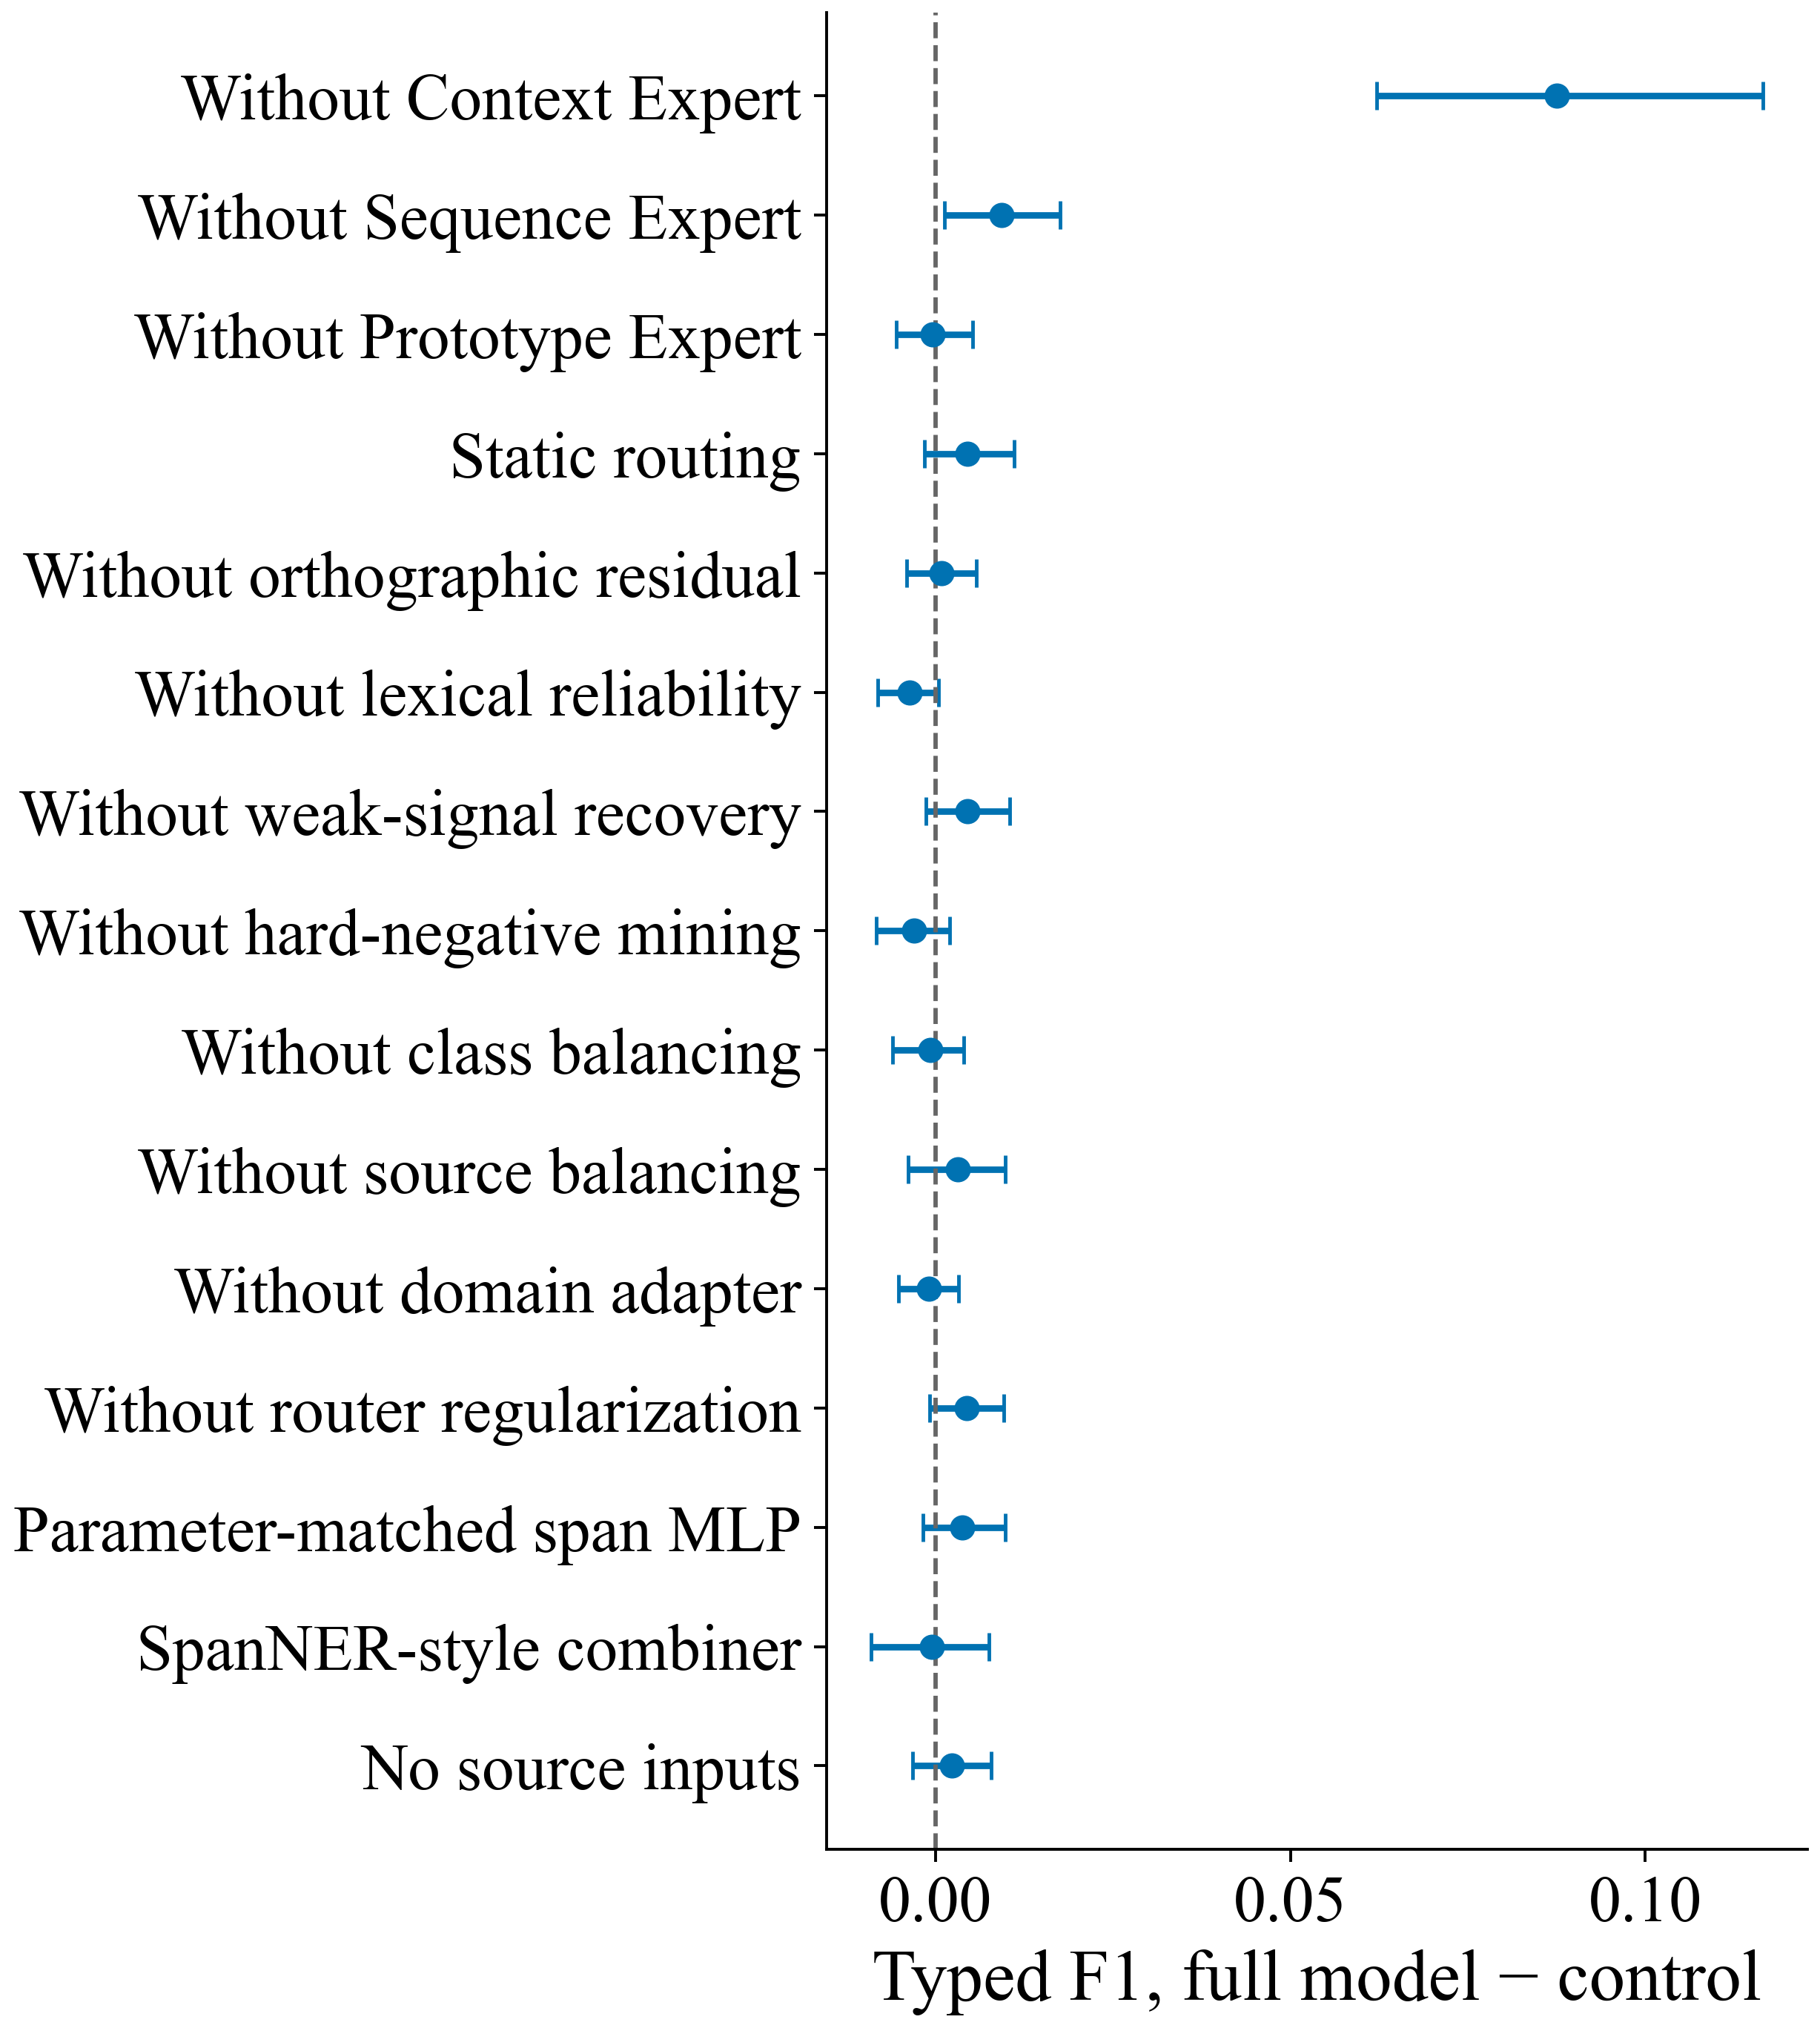

**Figure 7.2.** Difference in strict typed F1 between the full ACT-NER and each control on Validation under the stacking protocol (points) with 95 % paired cluster-bootstrap intervals (bars); the dashed line marks no difference. Values right of the line favour the full model.

**Interpretation.** Under identical out-of-fold training evidence, a contribution of the full model with an interval above zero and Holm-adjusted p < 0.05 is supported for 1 of 15 controls: Without Context Expert. The difference from static routing is +0.0045 [−0.0015, 0.0111], from the control without the prototype expert −0.0004 [−0.0055, 0.0053], from the parameter-matched span MLP +0.0038 [−0.0018, 0.0098] and from the SpanNER-style combiner −0.0005 [−0.0091, 0.0076]. Removing every source input changes typed F1 by −0.0023. 6 control(s) have a higher point estimate than the full model (Without Prototype Expert; Without lexical reliability; Without hard-negative mining; Without class balancing; Without domain adapter; SpanNER-style combiner (stacking)); they are reported as obtained and do not trigger a re-selection of the architecture.

In [84]:
ablation_validation = {STACKED_ACT: stack_validation[STACKED_ACT], STACKED_MLP: stack_validation[STACKED_MLP],
                       SPANNER: stack_validation[SPANNER],
                       **{name: {seed: control_results[name][seed]["validation"] for seed in SEEDS} for name in control_variants},
                       NO_SOURCE: {seed: blind_results[NO_SOURCE][seed]["validation"] for seed in SEEDS}}
CONTROL_ORDER = [*control_variants, STACKED_MLP, SPANNER, NO_SOURCE]
ablation_evidence = paired_evidence(ablation_validation, validation.sentences, validation.entities, validation.documents,
                                    [(STACKED_ACT, name) for name in CONTROL_ORDER], replicates=N_RESAMPLES)
seed_f1 = {name: np.array([strict_metrics(validation.entities, frame)["typed_f1"] for frame in repeats.values()])
           for name, repeats in ablation_validation.items()}
records_all = pd.concat([primary_records, control_records, blind_records, combiner_records], ignore_index=True)
size = records_all.groupby("variant").parameters.max()
ablation_table = pd.DataFrame({
    "Control": CONTROL_ORDER,
    "Typed F1 (mean of 3 seeds)": [seed_f1[name].mean() for name in CONTROL_ORDER],
    "SD over seeds": [seed_f1[name].std(ddof=1) for name in CONTROL_ORDER],
    "Δ typed F1 (full − control)": ablation_evidence["Micro-F1 difference"].to_numpy(),
    "CI low": ablation_evidence["CI low"].to_numpy(), "CI high": ablation_evidence["CI high"].to_numpy(),
    "Holm-adjusted p": ablation_evidence["Micro-F1 Holm p"].to_numpy(),
    "Seeds with full model better": [f"{int((seed_f1[STACKED_ACT] > seed_f1[name]).sum())}/{len(SEEDS)}" for name in CONTROL_ORDER],
    "Trainable parameters": [int(size[name]) for name in CONTROL_ORDER]})
save_table(ablation_table, "table_7_33_stacking_component_controls")
display_table(ablation_table, "Table 7.33. Component controls under the stacking protocol on Validation (cross-fitted "
              f"selection). Full ACT-NER: typed F1 {seed_f1[STACKED_ACT].mean():.4f} ± {seed_f1[STACKED_ACT].std(ddof=1):.4f} "
              f"(SD, 3 seeds), {int(size[STACKED_ACT])} trainable parameters. Δ > 0 means that the full model is better; "
              f"95 % paired cluster-bootstrap interval; Holm adjustment over the {len(CONTROL_ORDER)} comparisons.",
              index="Control", signed=("Δ typed F1 (full − control)",), pvalues=("Holm-adjusted p",))

forest = ablation_table.iloc[::-1]
SHORT = {"Parameter-matched span MLP (stacking)": "Parameter-matched span MLP", SPANNER: "SpanNER-style combiner"}
fig, ax = plt.subplots(figsize=(7.0, 0.42 * len(forest) + 1.5))
estimate = forest["Δ typed F1 (full − control)"].to_numpy()
ax.errorbar(estimate, np.arange(len(forest)), xerr=np.vstack([estimate - forest["CI low"].to_numpy(),
                                                              forest["CI high"].to_numpy() - estimate]),
            fmt="o", color=OKABE_ITO[0], capsize=4, markersize=6, linewidth=1.8)
ax.axvline(0, color="0.4", linewidth=1.2, linestyle="--")
ax.set_yticks(np.arange(len(forest)), [SHORT.get(name, name) for name in forest.Control])
ax.set_xlabel("Typed F1, full model − control")
ax.spines[["top", "right"]].set_visible(False)
save_and_show(fig, "figure_7_02_stacking_component_effects")
display(Markdown("**Figure 7.2.** Difference in strict typed F1 between the full ACT-NER and each control on Validation under "
                 "the stacking protocol (points) with 95 % paired cluster-bootstrap intervals (bars); the dashed line marks "
                 "no difference. Values right of the line favour the full model."))
table = ablation_table.set_index("Control")
significant = [c for c in CONTROL_ORDER if table.loc[c, "CI low"] > 0 and table.loc[c, "Holm-adjusted p"] < 0.05]
better = [c for c in CONTROL_ORDER if table.loc[c, "Δ typed F1 (full − control)"] < 0]
note(f"**Interpretation.** Under identical out-of-fold training evidence, a contribution of the full model with an interval "
     f"above zero and Holm-adjusted p < 0.05 is supported for {len(significant)} of {len(CONTROL_ORDER)} controls"
     + (f": {'; '.join(significant)}." if significant else ".")
     + f" The difference from static routing is {fmt_signed(table.loc['Static routing', 'Δ typed F1 (full − control)'])} "
       f"[{fmt_num(table.loc['Static routing', 'CI low'])}, {fmt_num(table.loc['Static routing', 'CI high'])}], from the control "
       f"without the prototype expert {fmt_signed(table.loc['Without Prototype Expert', 'Δ typed F1 (full − control)'])} "
       f"[{fmt_num(table.loc['Without Prototype Expert', 'CI low'])}, {fmt_num(table.loc['Without Prototype Expert', 'CI high'])}], "
       f"from the parameter-matched span MLP {fmt_signed(table.loc[STACKED_MLP, 'Δ typed F1 (full − control)'])} "
       f"[{fmt_num(table.loc[STACKED_MLP, 'CI low'])}, {fmt_num(table.loc[STACKED_MLP, 'CI high'])}] and from the SpanNER-style "
       f"combiner {fmt_signed(table.loc[SPANNER, 'Δ typed F1 (full − control)'])} "
       f"[{fmt_num(table.loc[SPANNER, 'CI low'])}, {fmt_num(table.loc[SPANNER, 'CI high'])}]. Removing every source input changes "
       f"typed F1 by {fmt_signed(-table.loc[NO_SOURCE, 'Δ typed F1 (full − control)'])}. "
     + (f"{len(better)} control(s) have a higher point estimate than the full model ({'; '.join(better)}); they are reported as "
        f"obtained and do not trigger a re-selection of the architecture." if better else ""))

## B19 – Identity and fine-tuning settings of the Transformer comparators

**Question.** Which checkpoints are the Transformer comparators exactly, and how were they fine-tuned?

**Method.** Identifier, pinned revision, depth, width and parameter count are read from the local model files; optimisation settings are read from the executed configuration of each model. No model is fitted in this section.

In [85]:
import base_transformer as base_data
import base_transformer_memorysafe as base_fit
from torch.utils.data import DataLoader
from transformers import AutoConfig, AutoModel, AutoModelForTokenClassification

from act_ner import build_candidate_bundle
from core import build_training_lexicon, predictions_from_tag_sequences, tokenize_split
from models import TransformerSequenceDataset, _boundary_spans_from_tags, feature_sequences, transformer_collate

BASE_SETTINGS = dict(base_fit.SETTINGS)               # frozen recipe of the base-size encoder
BASE_DIRECTORY = base_data._pretrained(PROJECT)
small_config = AutoConfig.from_pretrained(BACKBONE, local_files_only=True)
base_config = AutoConfig.from_pretrained(BASE_DIRECTORY, local_files_only=True)


def count_parameters(config, token_classifier: bool = True) -> int:
    """Parameters of the encoder with a 17-way token classifier, built from the configuration only."""
    config = AutoConfig.from_pretrained(config._name_or_path, local_files_only=True, num_labels=len(TYPED_TAGS))
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = AutoModelForTokenClassification.from_config(config)
    return sum(p.numel() for p in model.parameters())


small_recipe = EXPERT_PROTOCOL["transformer"]
identity = pd.DataFrame([
    {"Model": "Biomedical Transformer (original comparator and context expert)",
     "Checkpoint": BACKBONE, "Pinned revision": str(getattr(small_config, "_commit_hash", "")),
     "Layers": small_config.num_hidden_layers, "Hidden size": small_config.hidden_size,
     "Parameters with 17-tag classifier": count_parameters(small_config)},
    {"Model": "BiomedBERT-base (stronger comparator)",
     "Checkpoint": base_fit.MODEL_ID, "Pinned revision": base_fit.REVISION,
     "Layers": base_config.num_hidden_layers, "Hidden size": base_config.hidden_size,
     "Parameters with 17-tag classifier": count_parameters(base_config)},
])
assert identity["Pinned revision"].str.len().gt(0).all()
recipes = pd.DataFrame([
    {"Model": "Biomedical Transformer", "Fine-tuned parameters": "all layers", "Optimiser": "AdamW, weight decay 0.01",
     "Learning rate": small_recipe["learning_rate"], "Batch size": small_recipe["batch_size"],
     "Epochs": f"at most {small_recipe['max_epochs']}, patience {small_recipe['patience']}",
     "Schedule": "constant learning rate", "Epoch selection": "strict typed F1 on the stop documents",
     "Decoder": "17 BIOES token logits, argmax, deterministic BIOES repair"},
    {"Model": "BiomedBERT-base", "Fine-tuned parameters": "all layers", "Optimiser": f"AdamW, weight decay {BASE_SETTINGS['weight_decay']}",
     "Learning rate": BASE_SETTINGS["learning_rate"],
     "Batch size": BASE_SETTINGS["microbatch_size"] * BASE_SETTINGS["gradient_accumulation"],
     "Epochs": f"{BASE_SETTINGS['epochs']} (fixed)",
     "Schedule": f"linear warm-up over {BASE_SETTINGS['warmup_fraction']:.0%} of the updates, then linear decay",
     "Epoch selection": "strict typed F1 on Validation selection documents",
     "Decoder": "17 BIOES token logits, argmax, deterministic BIOES repair"},
])
save_table(identity, "table_7_34_transformer_identity")
save_table(recipes, "table_7_35_transformer_recipes", digits=6)
display_table(identity, "Table 7.34. Identity of the two Transformer encoders: hub identifier, pinned revision of the local "
              "files, depth, width and parameter count with a 17-tag token classifier.", index="Model")
display_table(recipes, "Table 7.35. Executed fine-tuning recipes of the two Transformer encoders.", index="Model", digits=5)
note(f"**Interpretation.** The original comparator is the community checkpoint `{BACKBONE}` ({small_config.num_hidden_layers} "
     f"layers, hidden size {small_config.hidden_size}), not one of the base-size BiomedBERT models."
     f"The stronger comparator is `{base_fit.MODEL_ID}` ({base_config.num_hidden_layers} layers, "
     f"hidden size {base_config.hidden_size}). Both use a token-level softmax; a span head on the base-size encoder is added "
     f"in section B22 and the base-size encoder is used as the frozen context expert in section B21.")

**Table 7.34. Identity of the two Transformer encoders: hub identifier, pinned revision of the local files, depth, width and parameter count with a 17-tag token classifier.**

,Checkpoint,Pinned revision,Layers,Hidden size,Parameters with 17-tag classifier
Model,,,,,
Biomedical Transformer (original comparator and context expert),NeuML/biomedbert-small,03666b41a5f7dd3ab0c128fa782fbfd96849e3ff,6,384,22571921
BiomedBERT-base (stronger comparator),microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext,e1354b7a3a09615f6aba48dfad4b7a613eef7062,12,768,108904721


**Table 7.35. Executed fine-tuning recipes of the two Transformer encoders.**

,Fine-tuned parameters,Optimiser,Learning rate,Batch size,Epochs,Schedule,Epoch selection,Decoder
Model,,,,,,,,
Biomedical Transformer,all layers,"AdamW, weight decay 0.01",0.00005,24,"at most 5, patience 2",constant learning rate,strict typed F1 on the stop documents,"17 BIOES token logits, argmax, deterministic BIOES repair"
BiomedBERT-base,all layers,"AdamW, weight decay 0.01",0.00002,24,5 (fixed),"linear warm-up over 10% of the updates, then linear decay",strict typed F1 on Validation selection documents,"17 BIOES token logits, argmax, deterministic BIOES repair"


**Interpretation.** The original comparator is the community checkpoint `NeuML/biomedbert-small` (6 layers, hidden size 384), not one of the base-size BiomedBERT models.The stronger comparator is `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext` (12 layers, hidden size 768). Both use a token-level softmax; a span head on the base-size encoder is added in section B22 and the base-size encoder is used as the frozen context expert in section B21.

## B20 – Out-of-fold BiomedBERT-base experts over Train

**Question.** What does ACT-NER reach when the frozen context expert is a base-size biomedical encoder?

**Method.** The stacking protocol of section B13 is repeated with BiomedBERT-base as the context expert. For each of the same five Train folds the encoder is fully fine-tuned on the other four folds with its frozen recipe (five epochs, no selection data) and a CRF is fitted on the same documents with the tokenization of this encoder; both produce evidence for the held-out fold. The final context expert is the existing seed-17 model fine-tuned on all Train documents for five epochs; the final CRF is fitted on all Train documents with an internal stop set. No Validation, test or reserve document enters an expert.

In [86]:
base_corpus = base_data._data(str(PROJECT))           # BiomedBERT-base tokenization of Train and Validation
base_tokenizer = base_corpus["tokenizer"]


def with_tokens(population: Population, tokens: pd.DataFrame) -> Population:
    """Same documents and annotations with the tokenization of another encoder."""
    return Population(population.name, population.sentences, population.entities, tokens, population.documents)


base_train = with_tokens(train, base_corpus["train"]["tokens"])
base_validation = with_tokens(validation, base_corpus["validation"]["tokens"])
base_test = with_tokens(test, tokenize_split(test.sentences, test.entities.iloc[:0], base_tokenizer)[0])
base_reserve = with_tokens(reserve_all, tokenize_split(reserve_all.sentences, reserve_all.entities.iloc[:0], base_tokenizer)[0])
assert max(p.tokens.groupby("sentence_id").size().max() for p in (base_train, base_validation, base_test, base_reserve)) + 2 <= 512


def memory_guard(phase: str, step: int = 0) -> None:
    """Stop a fit that exceeds the registered memory limit of the base-size recipe."""
    base_fit.enforce_memory(base_fit.memory_snapshot(DEVICE, phase, step))


def linear_schedule(optimizer, n_microbatches: int):
    updates = math.ceil(n_microbatches / BASE_SETTINGS["gradient_accumulation"]) * BASE_SETTINGS["epochs"]
    warmup = max(1, round(updates * BASE_SETTINGS["warmup_fraction"]))
    return torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: min(step / warmup, max(0, (updates - step) / max(1, updates - warmup))))


def load_base_tagger(state_dict: dict):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = AutoModelForTokenClassification.from_pretrained(BASE_DIRECTORY, local_files_only=True, num_labels=len(TYPED_TAGS))
    model.load_state_dict(state_dict)
    return model.to(DEVICE).eval()


def fit_base_tagger(directory: Path, fit_ids: set[str], seed: int, progress=None) -> dict:
    """Full fine-tuning of BiomedBERT-base on the given Train documents (frozen recipe, final epoch kept)."""
    record = sealed(directory)
    if record is not None:
        return record
    directory.mkdir(parents=True, exist_ok=True)
    tokens = base_train.tokens.loc[base_train.tokens.document_id.isin(fit_ids)]
    dataset = TransformerSequenceDataset(tokens, base_tokenizer.cls_token_id, base_tokenizer.sep_token_id)
    lengths = [len(record_["input_ids"]) for record_ in dataset.records]
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = base_fit._new_model(PROJECT, seed, DEVICE)
    optimizer = base_fit._optimizer(model)
    scheduler = linear_schedule(optimizer, len(base_fit.bucket_batches(lengths, seed, 1)))
    started, losses = time.perf_counter(), []
    for epoch in range(1, BASE_SETTINGS["epochs"] + 1):
        loss, _ = base_fit._optimize(model, optimizer, scheduler, dataset, base_tokenizer,
                                     base_fit.bucket_batches(lengths, seed, epoch), DEVICE, memory_guard,
                                     progress or (lambda row: None), epoch)
        losses.append(loss)
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
                "seed": seed, "fit_ids": sorted(fit_ids)}, directory / "model.pt")
    del model, optimizer, scheduler
    base_fit._clear(DEVICE)
    return seal(directory, {"model": base_fit.MODEL, "seed": seed, "fit_documents": len(fit_ids),
                            "epochs": BASE_SETTINGS["epochs"], "train_loss": losses, "seconds": time.perf_counter() - started})


def base_tagger_rows(model, tokens: pd.DataFrame) -> dict:
    """Token probabilities, final hidden states and argmax tags per sentence (structure of expert_evidence)."""
    dataset = TransformerSequenceDataset(tokens, base_tokenizer.cls_token_id, base_tokenizer.sep_token_id)
    loader = DataLoader(dataset, batch_size=8, shuffle=False,
                        collate_fn=lambda rows: transformer_collate(rows, base_tokenizer.pad_token_id))
    rows = {}
    with torch.inference_mode():
        for batch in loader:
            result = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE),
                           output_hidden_states=True)
            for index, sentence in enumerate(batch["sentence_ids"]):
                length = int(batch["attention_mask"][index].sum()) - 2
                probabilities = result.logits[index, 1:length + 1].softmax(-1).cpu()
                rows[sentence] = {"probabilities": probabilities,
                                  "hidden": result.hidden_states[-1][index, 1:length + 1].cpu(),
                                  "tags": [TYPED_TAGS[i] for i in probabilities.argmax(-1).tolist()]}
            del result
    release_memory()
    return rows


def crf_rows(model, tokens: pd.DataFrame) -> dict:
    """Viterbi tags, token marginals and sequence confidence of a linear-chain CRF (structure of expert_evidence)."""
    sequences, _, identifiers = feature_sequences(tokens)
    rows = {}
    for sentence, features in zip(identifiers, sequences):
        tags, marginals = model.predict_single(features), model.predict_marginals_single(features)
        model.tagger_.set(features)
        rows[sentence] = {"tags": list(tags),
                          "probabilities": torch.tensor([[row.get(tag, 0.0) for tag in TYPED_TAGS] for row in marginals]),
                          "sequence_probability": float(model.tagger_.probability(tags)),
                          "transition_confidence": float(np.mean([row.get(tag, 0.0) for row, tag in zip(marginals, tags)]))}
    return rows


def fit_crf_on(directory: Path, fit: Population, stop: Population) -> dict:
    """Linear-chain CRF on an arbitrary tokenization; (c1, c2) chosen on the stop documents."""
    record = sealed(directory)
    if record is not None:
        return record
    directory.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model, _, tuning = train_linear_crf(fit.tokens, stop.tokens, stop.sentences, stop.entities,
                                            candidates=[tuple(c) for c in EXPERT_PROTOCOL["crf"]["candidates"]])
    joblib.dump(model, directory / "crf.joblib")
    best = tuning.sort_values(["Strict Typed Entity F1", "Strict Boundary F1", "c1", "c2"],
                              ascending=[False, False, True, True]).iloc[0]
    return seal(directory, {"model": "Linear-chain CRF", "fit_documents": len(fit.documents), "stop_documents": len(stop.documents),
                            "c1": float(best.c1), "c2": float(best.c2), "stop_typed_f1": float(best["Strict Typed Entity F1"]),
                            "seconds": time.perf_counter() - started})


def tagger_predictions(rows: dict, population: Population, name: str, split: str, seed: int | None = None) -> pd.DataFrame:
    return predictions_from_tag_sequences(population.tokens, population.sentences,
                                          {sid: row["tags"] for sid, row in rows.items()},
                                          {sid: row["probabilities"].max(-1).values.tolist() for sid, row in rows.items()},
                                          name, split, seed)


def evidence_bundle(population: Population, transformer_rows: dict, crf_model, lexicon_entities: pd.DataFrame) -> CandidateBundle:
    """Candidate union of one population from the two experts; targets are attached after generation."""
    lexicon = build_training_lexicon(gold_for_metrics(lexicon_entities).assign(split="train"))
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bundle, _, _ = build_candidate_bundle(PROJECT, population.sentences, population.entities.iloc[:0], population.tokens,
                                              STACK_PROTOCOL["candidate_marginal_threshold"],
                                              expert_evidence=(transformer_rows, crf_rows(crf_model, population.tokens), 0.0),
                                              training_lexicon=lexicon)
    assert bundle.frame.generated_candidate.all()
    return annotate_candidates(bundle, population.entities)

In [87]:
BASE_STACK = STACK / "base_experts"
BASE_CANDIDATES = RUN_PREDICTIONS / "stacking" / "candidates_base"
progress = display(Markdown("Out-of-fold BiomedBERT-base experts: starting."), display_id=True)
started, base_units, base_oof_bundles, base_oof_predictions = time.perf_counter(), [], [], []
for fold in range(STACK_PROTOCOL["oof_folds"]):
    fit_ids, stop_ids, held_out = expert_roles(fold)
    directory = BASE_STACK / f"oof_fold_{fold}"
    cache = BASE_CANDIDATES / f"train_oof_fold_{fold}"

    def report(row, fold=fold):
        progress.update(Markdown(f"Out-of-fold BiomedBERT-base, fold {fold + 1}/5 · epoch {row['epoch']}/{BASE_SETTINGS['epochs']} · "
                                 f"step {row['microstep']}/{row['microsteps']} · train loss {row['train_token_ce']:.4f} · "
                                 f"{(time.perf_counter() - started) / 60:.1f} min elapsed"))
    tagger = fit_base_tagger(directory / "tagger", fit_ids | stop_ids, STACK_PROTOCOL["expert_seed"], report)
    crf = fit_crf_on(directory / "crf", base_train.subset(fit_ids, "fit"), base_train.subset(stop_ids, "stop"))
    observed = base_train.subset(held_out, f"Train fold {fold + 1}")
    if (cache / "complete.json").exists():
        bundle = load_bundle(cache)
        prediction = pd.read_parquet(cache / "tagger_predictions.parquet")
    else:
        progress.update(Markdown(f"Out-of-fold BiomedBERT-base, fold {fold + 1}/5 · held-out evidence for {len(held_out)} documents."))
        model = load_base_tagger(torch.load(directory / "tagger" / "model.pt", map_location="cpu", weights_only=False)["state_dict"])
        rows = base_tagger_rows(model, observed.tokens)
        del model
        release_memory()
        bundle = evidence_bundle(observed, rows, joblib.load(directory / "crf" / "crf.joblib"),
                                 base_train.subset(fit_ids | stop_ids, "fold training").entities)
        prediction = tagger_predictions(rows, observed, BASE, "Train out-of-fold")
        save_bundle(bundle, cache)
        prediction.to_parquet(cache / "tagger_predictions.parquet", index=False)
    base_oof_bundles.append(bundle)
    base_oof_predictions.append(prediction)
    base_units.append({"Unit": f"Out-of-fold {fold + 1}/5", "Tagger fit documents": tagger["fit_documents"],
                       "Held-out documents": len(held_out), "Final training loss": tagger["train_loss"][-1],
                       "CRF setting": f"c1 = {crf['c1']:g}, c2 = {crf['c2']:g}",
                       "BiomedBERT-base held-out typed F1": strict_metrics(observed.entities, prediction)["typed_f1"],
                       "Fit time (min)": (tagger["seconds"] + crf["seconds"]) / 60})
base_train_oof = concatenate_bundles(base_oof_bundles)
base_unit_table = pd.DataFrame(base_units)
progress.update(Markdown(f"Out-of-fold BiomedBERT-base experts: 5 folds ({base_unit_table['Fit time (min)'].sum():.0f} min of fitting)."))
save_table(base_unit_table, "table_7_36_base_oof_expert_units")
display_table(base_unit_table, "Table 7.36. Out-of-fold BiomedBERT-base experts over Train (seed 17, five epochs, no selection "
              "data): document roles, final training loss, CRF setting on the tokenization of this encoder and strict typed "
              "F1 of the tagger on its held-out Train fold.", index="Unit", digits=4)

Out-of-fold BiomedBERT-base experts: 5 folds (175 min of fitting).

**Table 7.36. Out-of-fold BiomedBERT-base experts over Train (seed 17, five epochs, no selection data): document roles, final training loss, CRF setting on the tokenization of this encoder and strict typed F1 of the tagger on its held-out Train fold.**

,Tagger fit documents,Held-out documents,Final training loss,CRF setting,BiomedBERT-base held-out typed F1,Fit time (min)
Unit,,,,,,
Out-of-fold 1/5,457,115,0.0400,"c1 = 0.05, c2 = 0.05",0.8809,35.3711
Out-of-fold 2/5,457,115,0.0460,"c1 = 0.05, c2 = 0.05",0.9273,33.8550
Out-of-fold 3/5,458,114,0.0382,"c1 = 0.1, c2 = 0.1",0.8688,35.6236
Out-of-fold 4/5,458,114,0.0387,"c1 = 0.1, c2 = 0.1",0.8635,34.1371
Out-of-fold 5/5,458,114,0.0417,"c1 = 0.05, c2 = 0.05",0.9072,35.5839


In [88]:
BASE_RUN = base_fit.ATTEMPT
base_checkpoints = PROJECT / "Models" / "Extended" / EXTENDED_RUN / BASE_RUN
base_epoch_predictions = PROJECT / "Predictions" / "Extended" / EXTENDED_RUN / BASE_RUN
EXPERT_EPOCH = BASE_SETTINGS["epochs"]                 # the expert is the final epoch of the fixed budget
progress = display(Markdown("Final BiomedBERT-base expert: candidate evidence."), display_id=True)
final_fit_population, final_stop_population = base_train.subset(final_fit, "fit"), base_train.subset(final_stop, "stop")
base_final_crf = fit_crf_on(BASE_STACK / "final_crf", final_fit_population, final_stop_population)
base_crf_model = joblib.load(BASE_STACK / "final_crf" / "crf.joblib")
base_bundles = {"Train (out-of-fold)": base_train_oof}
if all((BASE_CANDIDATES / key / "complete.json").exists() for key in ("validation", "test", "reserve")):
    for key, population in (("validation", base_validation), ("test", base_test), ("reserve", base_reserve)):
        base_bundles[population.name] = load_bundle(BASE_CANDIDATES / key)
else:
    state = torch.load(base_checkpoints / f"seed_{STACK_PROTOCOL['expert_seed']}" / f"epoch_{EXPERT_EPOCH:02d}.pt",
                       map_location="cpu", weights_only=False)["state_dict"]
    model = load_base_tagger(state)
    for key, population in (("validation", base_validation), ("test", base_test), ("reserve", base_reserve)):
        progress.update(Markdown(f"Final BiomedBERT-base expert · candidate evidence for {population.name}."))
        bundle = evidence_bundle(population, base_tagger_rows(model, population.tokens), base_crf_model, base_train.entities)
        save_bundle(bundle, BASE_CANDIDATES / key)
        base_bundles[population.name] = bundle
    del model, state
    release_memory()
progress.update(Markdown("Candidate evidence of the BiomedBERT-base expert pair built for all populations."))

base_coverage = []
for name, bundle in base_bundles.items():
    population = train if name.startswith("Train") else next(p for p in POPULATIONS if p.name == name)
    gold_boundaries = set(population.gold[KEY].itertuples(index=False, name=None))
    frame = bundle.frame
    covered = lambda mask: len(set(frame.loc[mask, KEY].itertuples(index=False, name=None)) & gold_boundaries) / len(gold_boundaries)
    base_coverage.append({"Population": name, "Gold entities": len(gold_boundaries), "Candidate spans": len(frame),
                          "Boundary recall: BiomedBERT-base-decoded": covered(frame.origin_transformer),
                          "Boundary recall: CRF-decoded": covered(frame.origin_crf),
                          "Boundary recall: candidate union": covered(frame.generated_candidate)})
base_coverage = pd.DataFrame(base_coverage)
save_table(base_coverage, "table_7_37_base_candidate_coverage")
display_table(base_coverage, "Table 7.37. Candidate evidence with BiomedBERT-base as context expert: candidate spans and "
              "boundary recall of the expert-decoded spans and of the union (Train: out-of-fold experts; other populations: "
              "final Train experts).", index="Population", digits=4)

Candidate evidence of the BiomedBERT-base expert pair built for all populations.

**Table 7.37. Candidate evidence with BiomedBERT-base as context expert: candidate spans and boundary recall of the expert-decoded spans and of the union (Train: out-of-fold experts; other populations: final Train experts).**

,Gold entities,Candidate spans,Boundary recall: BiomedBERT-base-decoded,Boundary recall: CRF-decoded,Boundary recall: candidate union
Population,,,,,
Train (out-of-fold),11812,72063,0.9604,0.8512,0.9778
Validation,2915,17538,0.9678,0.8734,0.9780
Official DrugNER test,684,4889,0.9284,0.7383,0.9576
Reserve (all relation-task test documents),3031,19235,0.9687,0.8515,0.9822


## B21 – ACT-NER with the base-size encoder as frozen context expert

**Method.** The span head, the parameter-matched span MLP and the SpanNER-style combiner are fitted on the out-of-fold candidates of the BiomedBERT-base expert pair with the procedure of sections B15 and B16 (three seeds, eight epochs, selection on Validation). Only the width of the contextual input changes (768 instead of 384 per state). BiomedBERT-base itself is the Train-only baseline: for each of its three seeds the epoch is selected on the same Validation selection documents as the heads, and the selected model is scored on the official test set and on the reserve.

In [89]:
BASE_ACT = "ACT-NER, BiomedBERT-base expert (stacking)"
BASE_MLP = "Span MLP, BiomedBERT-base expert (stacking)"
base_evidence = EvidenceSet("base_backbone", base_train_oof, base_bundles[validation.name], base_bundles[test.name],
                            base_bundles[reserve_all.name])
BASE_JOINT = replace(JOINT_A, context_dim=base_evidence.context_dim)
assert base_evidence.context_dim == base_config.hidden_size
base_results, base_records = run_variants(base_evidence, {BASE_ACT: BASE_JOINT,
                                                          BASE_MLP: replace(BASE_JOINT, parameter_matched_control=True)},
                                          "Span heads on the BiomedBERT-base expert")
progress = display(Markdown("SpanNER-style combiner on the BiomedBERT-base expert: starting."), display_id=True)
base_combiner, base_combiner_records = {}, []
for seed in SEEDS:
    unit = run_combiner(base_evidence, seed, lambda row, seed=seed: progress.update(Markdown(
        f"SpanNER-style combiner on the BiomedBERT-base expert · seed {seed} · epoch {row['epoch']}/{HEAD['epochs']}")))
    base_combiner[seed] = unit["predictions"]
    base_combiner_records.append(unit["record"])
base_combiner_records = pd.DataFrame(base_combiner_records)
progress.update(Markdown("SpanNER-style combiner on the BiomedBERT-base expert: 3 fits."))
BASE_SPANNER = "SpanNER-style combiner, BiomedBERT-base expert (stacking)"
base_head_units = pd.concat([unit_summary(base_records),
                             unit_summary(base_combiner_records.assign(variant=BASE_SPANNER))], ignore_index=True)
base_head_units["Selected threshold (seed 17, 29, 43)"] = base_head_units["Selected threshold (seed 17, 29, 43)"].replace(
    "nan, nan, nan", "n/a (vote, no threshold)")
save_table(pd.concat([base_records.drop(columns="fold_choices"), base_combiner_records], ignore_index=True),
           "table_7_38_base_head_units")
display_table(base_head_units, "Table 7.38. Span heads and combiner fitted on the out-of-fold candidates of the BiomedBERT-base "
              "expert pair: selected epoch and verifier threshold of the frozen model of each seed, typed F1 on the Validation "
              "selection documents, trainable parameters and fitting time.", index="Model", digits=4)

Span heads on the BiomedBERT-base expert: 6 head fits (5.5 min of fitting).

SpanNER-style combiner on the BiomedBERT-base expert: 3 fits.

**Table 7.38. Span heads and combiner fitted on the out-of-fold candidates of the BiomedBERT-base expert pair: selected epoch and verifier threshold of the frozen model of each seed, typed F1 on the Validation selection documents, trainable parameters and fitting time.**

,Seeds,Trainable parameters,"Selected epoch (seed 17, 29, 43)","Selected threshold (seed 17, 29, 43)",Selection typed F1 (mean),Fit time per seed (s)
Model,,,,,,
"ACT-NER, BiomedBERT-base expert (stacking)",3,609051,"7, 8, 5","0.25, 0.25, 0.25",0.9318,74.2274
"Span MLP, BiomedBERT-base expert (stacking)",3,609163,"6, 8, 6","0.40, 0.50, 0.25",0.9271,35.6526
"SpanNER-style combiner, BiomedBERT-base expert (stacking)",3,408207,"5, 6, 8","n/a (vote, no threshold)",0.9317,9.9405


In [90]:
# BiomedBERT-base as Train-only baseline: epoch selection on the Validation selection documents, then frozen scoring.
progress = display(Markdown("BiomedBERT-base baseline: frozen scoring."), display_id=True)
selection_gold = validation.entities.loc[validation.entities.document_id.isin(FINAL_ROLES["selection"])]
base_baseline, base_selection_rows = {"test": {}, "reserve": {}, "validation_selected_epoch": {}}, []
BASE_OUTPUT = RUN_PREDICTIONS / "base_baseline"
for seed in SEEDS:
    epoch_frames = {epoch: pd.read_parquet(base_epoch_predictions / f"seed_{seed}" / f"epoch_{epoch:02d}.parquet")
                    for epoch in range(1, BASE_SETTINGS["epochs"] + 1)}
    epoch_f1 = {epoch: strict_metrics(selection_gold, frame.loc[frame.document_id.isin(FINAL_ROLES["selection"])])["typed_f1"]
                for epoch, frame in epoch_frames.items()}
    epoch = min(e for e, value in epoch_f1.items() if value >= max(epoch_f1.values()) - 1e-12)   # earliest best epoch
    output = BASE_OUTPUT / f"seed_{seed}"
    if not (output / "reserve.parquet").exists():
        output.mkdir(parents=True, exist_ok=True)
        progress.update(Markdown(f"BiomedBERT-base baseline · seed {seed} · scoring the test set and the reserve with epoch {epoch}."))
        model = load_base_tagger(torch.load(base_checkpoints / f"seed_{seed}" / f"epoch_{epoch:02d}.pt", map_location="cpu",
                                            weights_only=False)["state_dict"])
        for key, population in (("test", base_test), ("reserve", base_reserve)):
            tagger_predictions(base_tagger_rows(model, population.tokens), population, BASE, key, seed).to_parquet(
                output / f"{key}.parquet", index=False)
        del model
        release_memory()
    for key in ("test", "reserve"):
        base_baseline[key][seed] = pd.read_parquet(output / f"{key}.parquet")
    base_baseline["validation_selected_epoch"][seed] = epoch_frames[epoch]
    base_selection_rows.append({"Seed": seed, "Selected epoch": epoch, "Selection typed F1": epoch_f1[epoch],
                                **{f"Epoch {e} selection typed F1": value for e, value in epoch_f1.items()}})
progress.update(Markdown("BiomedBERT-base baseline: epoch selected per seed on Validation; test set and reserve scored once."))
base_selection_table = pd.DataFrame(base_selection_rows)
save_table(base_selection_table, "table_7_39_base_baseline_epoch_selection")
display_table(base_selection_table, f"Table 7.39. BiomedBERT-base baseline (fitted on Train only): strict typed F1 on the "
              f"{len(FINAL_ROLES['selection'])} Validation selection documents after each of the five epochs and the selected "
              "epoch of each seed, which is the model scored on the official test set and on the reserve.", index="Seed", digits=4)

BiomedBERT-base baseline: epoch selected per seed on Validation; test set and reserve scored once.

**Table 7.39. BiomedBERT-base baseline (fitted on Train only): strict typed F1 on the 113 Validation selection documents after each of the five epochs and the selected epoch of each seed, which is the model scored on the official test set and on the reserve.**

,Selected epoch,Selection typed F1,Epoch 1 selection typed F1,Epoch 2 selection typed F1,Epoch 3 selection typed F1,Epoch 4 selection typed F1,Epoch 5 selection typed F1
Seed,,,,,,,
17,5,0.9132,0.8395,0.8927,0.9106,0.9085,0.9132
29,4,0.9089,0.8602,0.8853,0.8969,0.9089,0.9067
43,3,0.9112,0.8512,0.8899,0.9112,0.9080,0.9110


## B22 – Base-size encoder with a span head (fully fine-tuned span model)

**Question.** How does ACT-NER compare with a competitive span-based model in which a base-size biomedical encoder is fine-tuned end to end with a span head?

**Method.** BiomedBERT-base is fine-tuned jointly with a span classification head in the manner of SpanNER (Fu et al., 2021): every span of at most `W` WordPiece tokens is represented by its two boundary states and a width embedding and classified into "no entity" or one of the four types with cross-entropy over all enumerated spans; decoding keeps predicted entities in descending probability and discards overlapping ones. `W` is the smallest width that covers at least 99.5 % of the Train gold spans; longer gold spans remain in every denominator. The optimisation recipe is the one of the token-classification model (five epochs, effective batch 24, linear warm-up and decay, encoder learning rate 2 × 10⁻⁵), with a head learning rate of 10⁻³. The model fits Train only; three seeds; the epoch is selected on the Validation selection documents, as for every other model. It is a controlled implementation on this corpus, not a reproduction of a published system.

In [91]:
SPAN_MODEL = "BiomedBERT-base + span head (full fine-tuning)"
train_widths = pd.Series([end - start for _, part in base_train.tokens.groupby("sentence_id", sort=False)
                          for start, end in _boundary_spans_from_tags(part.sort_values("token_index").typed_tag.tolist())])
SPAN_WIDTH = int(np.ceil(train_widths.quantile(0.995)))
SPAN_HEAD_LR = 1e-3
TAG_TYPE = {index: (ENTITY_TYPES.index(tag.split("-", 1)[1]) + 1 if "-" in tag else 0) for index, tag in enumerate(TYPED_TAGS)}


class SpanTagger(nn.Module):
    """BiomedBERT-base encoder with a span head: boundary states, width embedding, five-way softmax."""

    def __init__(self, width_dim: int = 50, inner: int = 256, dropout: float = 0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(BASE_DIRECTORY, local_files_only=True, add_pooling_layer=False)
        self.encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        hidden = self.encoder.config.hidden_size
        self.width = nn.Embedding(SPAN_WIDTH + 1, width_dim)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden + width_dim, inner), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(inner, len(ENTITY_TYPES) + 1))

    @staticmethod
    def enumerate_spans(n_tokens: int, device) -> tuple[torch.Tensor, torch.Tensor]:
        """Start and inclusive end of every span of at most SPAN_WIDTH tokens."""
        start = torch.arange(n_tokens, device=device).repeat_interleave(SPAN_WIDTH)
        end = start + torch.arange(SPAN_WIDTH, device=device).repeat(n_tokens)
        keep = end < n_tokens
        return start[keep], end[keep]

    def span_logits(self, states: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        start, end = self.enumerate_spans(states.shape[0], states.device)
        logits = self.head(torch.cat([states[start], states[end], self.width(end - start + 1)], dim=-1))
        return logits, start, end

    def forward(self, input_ids, attention_mask, labels=None):
        states = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        outputs, losses, count = [], [], 0
        for row in range(states.shape[0]):
            n_tokens = int(attention_mask[row].sum()) - 2
            if n_tokens <= 0:
                outputs.append(None)
                continue
            logits, start, end = self.span_logits(states[row, 1:n_tokens + 1])
            outputs.append((logits, start, end))
            if labels is not None and bool(labels[row].ne(-100).any()):
                tags = [TYPED_TAGS[i] for i in labels[row, 1:n_tokens + 1].tolist()]
                target = torch.zeros(len(start), dtype=torch.long, device=logits.device)
                position = {(int(s), int(e)): i for i, (s, e) in enumerate(zip(start.tolist(), end.tolist()))}
                for span_start, span_end in _boundary_spans_from_tags(tags):
                    if (span_start, span_end - 1) in position:      # wider gold spans cannot be proposed
                        target[position[(span_start, span_end - 1)]] = TAG_TYPE[TYPED_TAGS.index(tags[span_start])]
                losses.append(F.cross_entropy(logits, target, reduction="sum"))
                count += len(target)
        loss = torch.stack(losses).sum() / max(count, 1) if losses else None
        return type("SpanOutput", (), {"loss": loss, "spans": outputs})()


def span_tagger_predictions(model: SpanTagger, population: Population, split: str, seed: int) -> pd.DataFrame:
    """Decode every sentence: predicted entities in descending probability, overlapping spans discarded."""
    dataset = TransformerSequenceDataset(population.tokens, base_tokenizer.cls_token_id, base_tokenizer.sep_token_id)
    loader = DataLoader(dataset, batch_size=8, shuffle=False,
                        collate_fn=lambda rows: transformer_collate(rows, base_tokenizer.pad_token_id))
    offsets = {sid: part.sort_values("token_index")[["char_start", "char_end"]].to_numpy()
               for sid, part in population.tokens.groupby("sentence_id", sort=False)}
    document_of = population.sentences.set_index("sentence_id").document_id
    spans = []
    model.eval()
    with torch.inference_mode():
        for batch in loader:
            output = model(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
            for sentence, item in zip(batch["sentence_ids"], output.spans):
                if item is None:
                    continue
                probability = item[0].softmax(-1).cpu().numpy()
                starts, ends = item[1].cpu().numpy(), item[2].cpu().numpy()
                label, confidence = probability.argmax(-1), probability.max(-1)
                proposed = np.flatnonzero(label > 0)
                occupied = []
                for index in proposed[np.argsort(-confidence[proposed], kind="stable")]:
                    start, end = int(starts[index]), int(ends[index])
                    if any(start <= right and left <= end for left, right in occupied):
                        continue
                    occupied.append((start, end))
                    boundary = float(1 - probability[index, 0])
                    spans.append({"document_id": document_of[sentence], "sentence_id": sentence,
                                  "char_start": int(offsets[sentence][start, 0]), "char_end": int(offsets[sentence][end, 1]),
                                  "token_start": start, "token_end": end + 1,
                                  "predicted_type": ENTITY_TYPES[int(label[index]) - 1],
                                  "boundary_probability": boundary,
                                  "type_probability": float(confidence[index]) / max(boundary, 1e-8)})
            del output
    release_memory()
    return finalize_prediction_frame(spans, population.sentences, SPAN_MODEL, split, seed)


def fit_span_tagger(directory: Path, output: Path, seed: int, progress=None) -> dict:
    """Fine-tune encoder and span head on Train; after every epoch decode Validation, test and reserve."""
    record = sealed(directory)
    if record is not None:
        return record
    directory.mkdir(parents=True, exist_ok=True)
    output.mkdir(parents=True, exist_ok=True)
    dataset = TransformerSequenceDataset(base_train.tokens, base_tokenizer.cls_token_id, base_tokenizer.sep_token_id)
    lengths = [len(record_["input_ids"]) for record_ in dataset.records]
    base_fit._reset_seed(seed)
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = SpanTagger().to(DEVICE)
    head = [p for name, p in model.named_parameters() if not name.startswith("encoder.")]
    optimizer = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": BASE_SETTINGS["learning_rate"]},
                                   {"params": head, "lr": SPAN_HEAD_LR}], weight_decay=BASE_SETTINGS["weight_decay"])
    scheduler = linear_schedule(optimizer, len(base_fit.bucket_batches(lengths, seed, 1)))
    started, history = time.perf_counter(), []
    for epoch in range(1, BASE_SETTINGS["epochs"] + 1):
        loss, _ = base_fit._optimize(model, optimizer, scheduler, dataset, base_tokenizer,
                                     base_fit.bucket_batches(lengths, seed, epoch), DEVICE, memory_guard,
                                     progress or (lambda row: None), epoch)
        for key, population in (("validation", base_validation), ("test", base_test), ("reserve", base_reserve)):
            span_tagger_predictions(model, population, key, seed).to_parquet(output / f"{key}_epoch_{epoch:02d}.parquet", index=False)
        history.append({"epoch": epoch, "train_loss": loss})
    parameters = sum(p.numel() for p in model.parameters())
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()}, "seed": seed,
                "span_width": SPAN_WIDTH}, directory / "model_final_epoch.pt")
    pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
    del model, optimizer, scheduler
    base_fit._clear(DEVICE)
    return seal(directory, {"model": SPAN_MODEL, "seed": seed, "parameters": int(parameters), "span_width": SPAN_WIDTH,
                            "epochs": BASE_SETTINGS["epochs"], "train_loss": [row["train_loss"] for row in history],
                            "seconds": time.perf_counter() - started})

In [92]:
SPAN_STACK, SPAN_OUTPUT = RUN_MODELS / "span_tagger", RUN_PREDICTIONS / "span_tagger"
progress = display(Markdown("BiomedBERT-base with a span head: starting."), display_id=True)
started, span_units, span_tagger_results = time.perf_counter(), [], {"validation": {}, "test": {}, "reserve": {}}
for seed in SEEDS:
    def report(row, seed=seed):
        progress.update(Markdown(f"BiomedBERT-base with a span head · seed {seed} · epoch {row['epoch']}/{BASE_SETTINGS['epochs']} · "
                                 f"step {row['microstep']}/{row['microsteps']} · train loss {row['train_token_ce']:.4f} · "
                                 f"{(time.perf_counter() - started) / 60:.1f} min elapsed"))
    output = SPAN_OUTPUT / f"seed_{seed}"
    record = fit_span_tagger(SPAN_STACK / f"seed_{seed}", output, seed, report)
    by_epoch = {epoch: pd.read_parquet(output / f"validation_epoch_{epoch:02d}.parquet") for epoch in range(1, record["epochs"] + 1)}

    def best_epoch(document_ids: set[str]) -> int:
        gold = validation.entities.loc[validation.entities.document_id.isin(document_ids)]
        scores = [strict_metrics(gold, by_epoch[e].loc[by_epoch[e].document_id.isin(document_ids)])["typed_f1"] for e in sorted(by_epoch)]
        return int(np.argmax(scores)) + 1

    span_tagger_results["validation"][seed] = pd.concat(
        [by_epoch[best_epoch(r["selection"])].loc[lambda p, r=r: p.document_id.isin(r["outer"])] for r in FOLD_ROLES], ignore_index=True)
    epoch = best_epoch(FINAL_ROLES["selection"])
    for key in ("test", "reserve"):
        span_tagger_results[key][seed] = pd.read_parquet(output / f"{key}_epoch_{epoch:02d}.parquet")
    gold = validation.entities.loc[validation.entities.document_id.isin(FINAL_ROLES["selection"])]
    span_units.append({"Seed": seed, "Parameters": record["parameters"], "Maximum span width (tokens)": record["span_width"],
                       "Selected epoch": epoch,
                       "Selection typed F1": strict_metrics(gold, by_epoch[epoch].loc[lambda p: p.document_id.isin(FINAL_ROLES["selection"])])["typed_f1"],
                       "Final training loss": record["train_loss"][-1], "Fit time (min)": record["seconds"] / 60})
span_unit_table = pd.DataFrame(span_units)
progress.update(Markdown(f"BiomedBERT-base with a span head: 3 seeds ({span_unit_table['Fit time (min)'].sum():.0f} min of fitting)."))
coverage = float((train_widths <= SPAN_WIDTH).mean())
save_table(span_unit_table, "table_7_40_span_tagger_units")
display_table(span_unit_table, f"Table 7.40. BiomedBERT-base fine-tuned with a span head on Train (maximum span width "
              f"{SPAN_WIDTH} WordPiece tokens, covering {coverage:.2%} of the Train gold spans): size, epoch selected on the "
              "Validation selection documents, typed F1 on these documents, final training loss and fitting time per seed.",
              index="Seed", digits=4)

BiomedBERT-base with a span head: 3 seeds (153 min of fitting).

**Table 7.40. BiomedBERT-base fine-tuned with a span head on Train (maximum span width 7 WordPiece tokens, covering 99.52% of the Train gold spans): size, epoch selected on the Validation selection documents, typed F1 on these documents, final training loss and fitting time per seed.**

,Parameters,Maximum span width (tokens),Selected epoch,Selection typed F1,Final training loss,Fit time (min)
Seed,,,,,,
17,109299605,7,5,0.9295,0.0025,51.3674
29,109299605,7,2,0.9267,0.0025,50.7172
43,109299605,7,3,0.9295,0.0027,50.6579


## B23 – BiLSTM-CRF with character-level features and pretrained embeddings

**Question.** The original BiLSTM-CRF reaches a brand F1 of 0.4562. Does a standard BiLSTM-CRF with character-level features and pretrained embeddings close this gap?

**Method.** The original model embeds lower-cased WordPiece identifiers only (96-dimensional random initialization, hidden size 128), so it cannot see capitalization, which marks most brand names. The new baseline follows Lample et al. (2016): every token is represented by a WordPiece embedding initialised from the static input embeddings of the PubMed-pretrained encoder (384 dimensions, fine-tuned) concatenated with a character-level BiLSTM over the original-case surface string; a BiLSTM (200 units per direction) and a CRF with BIOES transition constraints follow. It fits Train only: about one seventh of the Train documents (the stop set of the final experts) is used for early stopping (at most 30 epochs, patience 5, Adam, learning rate 10⁻³, batch 32, dropout 0.3). The model is fitted on the CPU. Three seeds are fitted; this also gives the seed variance requested for the recurrent baseline.

In [93]:
import copy

from models import LinearChainCRF, typed_transition_mask
from torch.nn.utils.rnn import pad_sequence

CHAR_BILSTM = "BiLSTM-CRF with character features"
BILSTM_SETTINGS = {"char_dim": 30, "char_hidden": 30, "hidden": 200, "dropout": 0.3, "learning_rate": 1e-3,
                   "batch_size": 32, "max_epochs": 30, "patience": 5, "gradient_clip": 5.0, "max_characters": 24}
TAG_ID = {tag: index for index, tag in enumerate(TYPED_TAGS)}
# The recurrent model is fitted on the CPU: with variable-length batches the Metal backend compiles a new graph for
# every batch shape, and these cached graphs exhausted the GPU memory in a first attempt of this section.
BILSTM_DEVICE = torch.device("cpu")


class CharBiLSTMCRF(nn.Module):
    """Pretrained WordPiece embeddings + character BiLSTM -> BiLSTM -> CRF with BIOES constraints."""

    def __init__(self, word_vectors: torch.Tensor, n_characters: int):
        super().__init__()
        s = BILSTM_SETTINGS
        self.word = nn.Embedding.from_pretrained(word_vectors.clone(), freeze=False, padding_idx=0)
        self.character = nn.Embedding(n_characters, s["char_dim"], padding_idx=0)
        self.character_encoder = nn.LSTM(s["char_dim"], s["char_hidden"], batch_first=True, bidirectional=True)
        self.encoder = nn.LSTM(word_vectors.shape[1] + 2 * s["char_hidden"], s["hidden"], batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(s["dropout"])
        self.emission = nn.Linear(2 * s["hidden"], len(TYPED_TAGS))
        self.crf = LinearChainCRF(len(TYPED_TAGS), typed_transition_mask())

    def emissions(self, input_ids: torch.Tensor, characters: torch.Tensor) -> torch.Tensor:
        batch, length, width = characters.shape
        flat = characters.view(batch * length, width)
        encoded, _ = self.character_encoder(self.character(flat))
        present = flat.ne(0).unsqueeze(-1)
        pooled = encoded.masked_fill(~present, -1e4).max(dim=1).values          # max over the characters of a token
        pooled = torch.where(present.any(dim=1), pooled, torch.zeros_like(pooled)).view(batch, length, -1)
        states, _ = self.encoder(self.dropout(torch.cat([self.word(input_ids), pooled], dim=-1)))
        return self.emission(self.dropout(states))


def character_vocabulary(tokens: pd.DataFrame) -> dict[str, int]:
    """Characters of the fitting documents; 0 is padding and 1 an unseen character."""
    characters = sorted(set("".join(tokens.surface_text.astype(str))))
    return {character: index + 2 for index, character in enumerate(characters)}


def sequence_records(tokens: pd.DataFrame, vocabulary: dict[str, int]) -> list[dict]:
    limit = BILSTM_SETTINGS["max_characters"]
    records = []
    for sentence, part in tokens.sort_values(["sentence_id", "token_index"]).groupby("sentence_id", sort=False):
        characters = torch.zeros((len(part), limit), dtype=torch.long)
        for row, surface in enumerate(part.surface_text.astype(str)):
            codes = [vocabulary.get(character, 1) for character in surface[:limit]]
            characters[row, :len(codes)] = torch.tensor(codes, dtype=torch.long)
        records.append({"sentence_id": sentence, "input_ids": torch.tensor(part.input_id.to_numpy(), dtype=torch.long),
                        "characters": characters,
                        "labels": torch.tensor([TAG_ID[tag] for tag in part.typed_tag], dtype=torch.long)})
    return records


def sequence_batch(records: list[dict]) -> dict:
    lengths = torch.tensor([len(record["input_ids"]) for record in records])
    return {"sentence_ids": [record["sentence_id"] for record in records],
            "input_ids": pad_sequence([record["input_ids"] for record in records], batch_first=True),
            "characters": pad_sequence([record["characters"] for record in records], batch_first=True),
            "labels": pad_sequence([record["labels"] for record in records], batch_first=True),
            "mask": torch.arange(int(lengths.max())).unsqueeze(0) < lengths.unsqueeze(1)}


def bilstm_predictions(model: CharBiLSTMCRF, vocabulary: dict[str, int], population, split: str, seed: int) -> pd.DataFrame:
    records = sequence_records(population.tokens, vocabulary)
    tags, confidence = {}, {}
    decoder = copy.deepcopy(model.crf).cpu()               # Viterbi decoding on the CPU avoids per-token device transfers
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(records), 64):
            batch = sequence_batch(records[start:start + 64])
            emissions = model.emissions(batch["input_ids"].to(BILSTM_DEVICE), batch["characters"].to(BILSTM_DEVICE)).cpu()
            paths = decoder.decode(emissions, batch["mask"])
            probability = emissions.softmax(-1)
            for row, (sentence, path) in enumerate(zip(batch["sentence_ids"], paths)):
                tags[sentence] = [TYPED_TAGS[tag] for tag in path]
                confidence[sentence] = [float(probability[row, position, tag]) for position, tag in enumerate(path)]
    return predictions_from_tag_sequences(population.tokens, population.sentences, tags, confidence, CHAR_BILSTM, split, seed)


def fit_char_bilstm(directory: Path, fit: "Population", stop: "Population", seed: int, progress=None) -> dict:
    """Fit one model with early stopping on the stop documents; the best state is kept."""
    record = sealed(directory)
    if record is not None:
        return record
    directory.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    s = BILSTM_SETTINGS
    vocabulary = character_vocabulary(fit.tokens)
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        word_vectors = AutoModel.from_pretrained(BACKBONE, local_files_only=True).embeddings.word_embeddings.weight.detach().clone()
    model = CharBiLSTMCRF(word_vectors, len(vocabulary) + 2).to(BILSTM_DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=s["learning_rate"])
    records, rng = sequence_records(fit.tokens, vocabulary), np.random.default_rng(seed)
    best, best_state, stale, history, started = -1.0, None, 0, [], time.perf_counter()
    for epoch in range(1, s["max_epochs"] + 1):
        model.train()
        order, losses = rng.permutation(len(records)), []
        for start in range(0, len(order), s["batch_size"]):
            batch = sequence_batch([records[i] for i in order[start:start + s["batch_size"]]])
            optimizer.zero_grad(set_to_none=True)
            emissions = model.emissions(batch["input_ids"].to(BILSTM_DEVICE), batch["characters"].to(BILSTM_DEVICE))
            loss = -model.crf.log_likelihood(emissions, batch["labels"].to(BILSTM_DEVICE), batch["mask"].to(BILSTM_DEVICE)).mean()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), s["gradient_clip"])
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        metric = strict_metrics(stop.entities, bilstm_predictions(model, vocabulary, stop, "stop", seed))["typed_f1"]
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "stop_typed_f1": metric})
        if progress is not None:
            progress(history[-1])
        if metric > best + 1e-6:
            best, stale = metric, 0
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        else:
            stale += 1
        if stale >= s["patience"]:
            break
    torch.save({"state_dict": best_state, "vocabulary": vocabulary, "seed": seed}, directory / "model.pt")
    pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
    parameters = sum(p.numel() for p in model.parameters())
    del model
    release_memory()
    best_epoch = int(pd.DataFrame(history).sort_values(["stop_typed_f1", "epoch"], ascending=[False, True]).iloc[0].epoch)
    return seal(directory, {"model": CHAR_BILSTM, "seed": seed, "parameters": int(parameters), "epochs_run": len(history),
                            "selected_epoch": best_epoch, "stop_typed_f1": float(best), "seconds": time.perf_counter() - started})


def load_char_bilstm(directory: Path) -> tuple[CharBiLSTMCRF, dict[str, int]]:
    pack = torch.load(directory / "model.pt", map_location="cpu", weights_only=False)
    model = CharBiLSTMCRF(pack["state_dict"]["word.weight"], len(pack["vocabulary"]) + 2)
    model.load_state_dict(pack["state_dict"])
    return model.to(BILSTM_DEVICE), pack["vocabulary"]

In [94]:
BILSTM_MODELS, BILSTM_OUTPUT = RUN_MODELS / "char_bilstm_crf", RUN_PREDICTIONS / "char_bilstm_crf"
small_fit_population, small_stop_population = development.subset(final_fit), development.subset(final_stop)
progress = display(Markdown("BiLSTM-CRF with character features: starting."), display_id=True)
bilstm_units, bilstm_results = [], {"validation": {}, "test": {}, "reserve": {}}
for seed in SEEDS:
    directory, output = BILSTM_MODELS / f"seed_{seed}", BILSTM_OUTPUT / f"seed_{seed}"
    record = fit_char_bilstm(directory, small_fit_population, small_stop_population, seed,
                             lambda row, seed=seed: progress.update(Markdown(
                                 f"BiLSTM-CRF with character features · seed {seed} · epoch {row['epoch']} · train loss "
                                 f"{row['train_loss']:.3f} · stop typed F1 {row['stop_typed_f1']:.4f}")))
    if not (output / "reserve.parquet").exists():
        output.mkdir(parents=True, exist_ok=True)
        model, vocabulary = load_char_bilstm(directory)
        for key, population in (("validation", validation), ("test", test), ("reserve", reserve_all)):
            bilstm_predictions(model, vocabulary, population, key, seed).to_parquet(output / f"{key}.parquet", index=False)
        del model
        release_memory()
    for key in bilstm_results:
        bilstm_results[key][seed] = pd.read_parquet(output / f"{key}.parquet")
    bilstm_units.append({"Seed": seed, "Parameters": record["parameters"], "Epochs run": record["epochs_run"],
                         "Selected epoch": record["selected_epoch"], "Stop typed F1": record["stop_typed_f1"],
                         "Validation typed F1": strict_metrics(validation.entities, bilstm_results["validation"][seed])["typed_f1"],
                         "Validation brand F1": strict_metrics(validation.entities, bilstm_results["validation"][seed])["brand_f1"],
                         "Fit time (s)": record["seconds"]})
bilstm_unit_table = pd.DataFrame(bilstm_units)
progress.update(Markdown(f"BiLSTM-CRF with character features: 3 seeds ({bilstm_unit_table['Fit time (s)'].sum() / 60:.1f} min of fitting)."))
original_bilstm = strict_metrics(validation.entities, original_validation["BiLSTM-CRF"][0])
save_table(bilstm_unit_table, "table_7_41_char_bilstm_units")
display_table(bilstm_unit_table, "Table 7.41. BiLSTM-CRF with character-level features and pretrained WordPiece embeddings, "
              "fitted on Train with an internal stop set: size, epochs, typed F1 on the stop documents and strict typed and "
              "brand F1 on Validation (142 documents never used by this model) for each seed.", index="Seed", digits=4)
mean = bilstm_unit_table[["Validation typed F1", "Validation brand F1"]].mean()
sd = bilstm_unit_table[["Validation typed F1", "Validation brand F1"]].std(ddof=1)
note(f"**Interpretation.** With character-level features and pretrained embeddings the BiLSTM-CRF reaches a Validation typed "
     f"F1 of {mean['Validation typed F1']:.4f} ± {sd['Validation typed F1']:.4f} (SD, 3 seeds) and a brand F1 of "
     f"{mean['Validation brand F1']:.4f} ± {sd['Validation brand F1']:.4f}, against {original_bilstm['typed_f1']:.4f} and "
     f"{original_bilstm['brand_f1']:.4f} for the original BiLSTM-CRF. The low brand score of the original model was "
     f"therefore a property of its lower-cased, randomly initialised input and not of the recurrent architecture; the new "
     f"model replaces it as the recurrent baseline in the final tables.")

BiLSTM-CRF with character features: 3 seeds (23.7 min of fitting).

**Table 7.41. BiLSTM-CRF with character-level features and pretrained WordPiece embeddings, fitted on Train with an internal stop set: size, epochs, typed F1 on the stop documents and strict typed and brand F1 on Validation (142 documents never used by this model) for each seed.**

,Parameters,Epochs run,Selected epoch,Stop typed F1,Validation typed F1,Validation brand F1,Fit time (s)
Seed,,,,,,,
17,12778618,8,3,0.8675,0.8854,0.8609,400.0747
29,12778618,12,7,0.8690,0.8855,0.8366,610.1311
43,12778618,8,3,0.8743,0.8894,0.8550,409.7420


**Interpretation.** With character-level features and pretrained embeddings the BiLSTM-CRF reaches a Validation typed F1 of 0.8867 ± 0.0023 (SD, 3 seeds) and a brand F1 of 0.8508 ± 0.0127, against 0.8298 and 0.4562 for the original BiLSTM-CRF. The low brand score of the original model was therefore a property of its lower-cased, randomly initialised input and not of the recurrent architecture; the new model replaces it as the recurrent baseline in the final tables.

## B24 – Cross-source transfer between DrugBank and MedLine

**Question.** How do the models behave when one source is absent from training: fitted on DrugBank and scored on MedLine, and the reverse?

**Method.** For each direction every component uses documents of the training source only: the experts and their out-of-fold evidence come from the Train documents of that source (five folds, internal stop set), the span head is fitted on these out-of-fold candidates, and epoch, threshold and confidence map are chosen on the Validation documents of the same source. The models are then scored on the documents of the *other* source in the official test set and in the text-disjoint reserve; no label of the target source is used anywhere. Because the source is constant in training, ACT-NER is fitted without source inputs (section B17). BiomedBERT-base is fine-tuned on the training source with its frozen five-epoch recipe (seed 17). For reference, the same target documents are scored by the models of the stacking protocol that were trained on both sources.

In [95]:
CROSS = RUN_MODELS / "cross_source"
CROSS_CANDIDATES = RUN_PREDICTIONS / "cross_source" / "candidates"
SOURCES = ("DrugBank", "MedLine")
source_of_document = pd.concat([p.documents[["document_id", "source"]] for p in (train, validation, test, reserve_all)]
                               ).set_index("document_id").source


def source_evidence(source: str, progress) -> tuple[EvidenceSet, dict]:
    """Experts, out-of-fold candidates and candidate bundles when only one source is available for fitting."""
    documents = train_documents.loc[train_documents.source == source].reset_index(drop=True)
    folds = group_folds(documents, STACK_PROTOCOL["oof_folds"], STACK_PROTOCOL["oof_partition_seed"])
    bundles = []
    for fold in range(STACK_PROTOCOL["oof_folds"]):
        held_out = set(folds.index[folds == fold])
        available = documents.loc[~documents.document_id.isin(held_out)]
        fit_ids, stop_ids = split_group_holdout(available, STACK_PROTOCOL["expert_stop_fraction"],
                                                STACK_PROTOCOL["oof_partition_seed"] + 100 * (fold + 1))
        directory, cache = CROSS / source / f"oof_fold_{fold}", CROSS_CANDIDATES / source / f"train_oof_fold_{fold}"
        fit_expert_pair(directory, fit_ids, stop_ids, STACK_PROTOCOL["expert_seed"],
                        lambda row, fold=fold: progress.update(Markdown(
                            f"Training source {source} · out-of-fold experts {fold + 1}/5 · Transformer epoch {int(row['Epoch'])}")))
        if (cache / "complete.json").exists():
            bundle = load_bundle(cache)
        else:
            observed = development.subset(held_out)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                bundle, _, _ = candidate_evidence(PROJECT, observed, development.subset(fit_ids | stop_ids), directory,
                                                  EXPERT_PROTOCOL, include_gold_support=False)
            bundle = annotate_candidates(bundle, observed.entities)
            save_bundle(bundle, cache)
        bundles.append(bundle)
    fit_ids, stop_ids = split_group_holdout(documents, STACK_PROTOCOL["expert_stop_fraction"], STACK_PROTOCOL["oof_partition_seed"])
    final_directory = CROSS / source / "final"
    record = fit_expert_pair(final_directory, fit_ids, stop_ids, STACK_PROTOCOL["expert_seed"],
                             lambda row: progress.update(Markdown(
                                 f"Training source {source} · final experts · Transformer epoch {int(row['Epoch'])}")))
    source_training = development.subset(set(documents.document_id))
    evaluation = {}
    for key, population in (("validation", validation), ("test", test), ("reserve", reserve_all)):
        cache = CROSS_CANDIDATES / source / key
        if (cache / "complete.json").exists():
            evaluation[key] = load_bundle(cache)
            continue
        progress.update(Markdown(f"Training source {source} · candidate evidence for {population.name}."))
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            bundle, _, _ = candidate_evidence(PROJECT, population, source_training, final_directory, EXPERT_PROTOCOL,
                                              include_gold_support=False)
        evaluation[key] = annotate_candidates(bundle, population.entities)
        save_bundle(evaluation[key], cache)
    evidence = EvidenceSet(f"cross_source_{source.lower()}", concatenate_bundles(bundles), evaluation["validation"],
                           evaluation["test"], evaluation["reserve"]).transformed(without_source, f"cross_source_{source.lower()}")
    return evidence, {"directory": final_directory, "documents": len(documents), "record": record}

In [96]:
progress = display(Markdown("Cross-source experiment: starting."), display_id=True)
cross_predictions, cross_units = {}, []
CROSS_CONFIG = replace(JOINT_A, domain_adapter=False)
# BiomedBERT-base is fine-tuned first for both directions (seed 17, frozen five-epoch recipe): its registered memory
# limit needs a GPU allocation that has not been enlarged by fits of the small encoder in the same session.
base_cross = {}
for source in SOURCES:
    release_memory()
    base_cross[source] = fit_base_tagger(
        CROSS / source / "biomedbert_base", set(train_documents.loc[train_documents.source == source, "document_id"]),
        STACK_PROTOCOL["expert_seed"], lambda row, source=source: progress.update(Markdown(
            f"Training source {source} · BiomedBERT-base · epoch {row['epoch']}/{BASE_SETTINGS['epochs']} · step "
            f"{row['microstep']}/{row['microsteps']}")))
for source in SOURCES:
    target = next(s for s in SOURCES if s != source)
    evidence, experts = source_evidence(source, progress)
    in_source = lambda ids: {d for d in ids if source_of_document[d] == source}
    source_roles = {"selection": in_source(FINAL_ROLES["selection"]), "calibration": in_source(FINAL_ROLES["calibration"])}
    systems = {"Linear-chain CRF": {"test": {0: crf_predictions(experts["directory"], test, "test")},
                                    "reserve": {0: crf_predictions(experts["directory"], reserve_all, "reserve")}},
               "Biomedical Transformer": {"test": {STACK_PROTOCOL["expert_seed"]: transformer_predictions(experts["directory"], test, "test")},
                                          "reserve": {STACK_PROTOCOL["expert_seed"]: transformer_predictions(experts["directory"], reserve_all, "reserve")}},
               ACT: {"test": {}, "reserve": {}}}
    for seed in SEEDS:
        unit = run_head(evidence, ACT, CROSS_CONFIG, seed, final_roles_=source_roles, fold_roles_=[],
                        progress=lambda row, seed=seed: progress.update(Markdown(
                            f"Training source {source} · ACT-NER head, seed {seed} · epoch {row['epoch']}/{HEAD['epochs']}")))
        for key in ("test", "reserve"):
            systems[ACT][key][seed] = unit["predictions"][key]
    directory, output = CROSS / source / "biomedbert_base", RUN_PREDICTIONS / "cross_source" / "biomedbert_base" / source
    record = base_cross[source]
    if not (output / "reserve.parquet").exists():
        output.mkdir(parents=True, exist_ok=True)
        model = load_base_tagger(torch.load(directory / "model.pt", map_location="cpu", weights_only=False)["state_dict"])
        for key, population in (("test", base_test), ("reserve", base_reserve)):
            tagger_predictions(base_tagger_rows(model, population.tokens), population, BASE, key,
                               STACK_PROTOCOL["expert_seed"]).to_parquet(output / f"{key}.parquet", index=False)
        del model
        release_memory()
    systems[BASE] = {key: {STACK_PROTOCOL["expert_seed"]: pd.read_parquet(output / f"{key}.parquet")} for key in ("test", "reserve")}
    cross_predictions[(source, target)] = systems
    cross_units.append({"Training source": source, "Target source": target, "Train documents": experts["documents"],
                        "Validation selection documents": len(source_roles["selection"]),
                        "Validation calibration documents": len(source_roles["calibration"]),
                        "Out-of-fold candidate spans": len(evidence.train.frame),
                        "BiomedBERT-base fit time (min)": record["seconds"] / 60})
progress.update(Markdown("Cross-source experiment: both directions fitted and scored."))
cross_unit_table = pd.DataFrame(cross_units)
save_table(cross_unit_table, "table_7_42_cross_source_units")
display_table(cross_unit_table, "Table 7.42. Cross-source experiment: documents available for fitting, selection and "
              "calibration in each direction (all from the training source) and the number of out-of-fold candidate spans "
              "used to fit the ACT-NER head.", index=["Training source", "Target source"], digits=1)

Cross-source experiment: both directions fitted and scored.

**Table 7.42. Cross-source experiment: documents available for fitting, selection and calibration in each direction (all from the training source) and the number of out-of-fold candidate spans used to fit the ACT-NER head.**

,,Train documents,Validation selection documents,Validation calibration documents,Out-of-fold candidate spans,BiomedBERT-base fit time (min)
Training source,Target source,,,,,
DrugBank,MedLine,458,91,23,61373,33.9
MedLine,DrugBank,114,22,6,8887,8.2


In [97]:
from act_ner import ACTNERConfig


def restrict(repeats: dict[int, pd.DataFrame], population: Population) -> dict[int, pd.DataFrame]:
    """Predictions of the documents of one population only."""
    keep = set(population.documents.document_id)
    return {seed: frame.loc[frame.document_id.isin(keep)] for seed, frame in repeats.items()}


def source_part(population: Population, source: str) -> Population:
    return population.subset(population.documents.loc[population.documents.source == source, "document_id"],
                             f"{population.name}, {source}")


def typed_f1_cell(population: Population, repeats: dict[int, pd.DataFrame]) -> tuple[float, float, float]:
    weights = resampling_weights(population.documents.dependency_group.nunique())
    return f1_with_interval(stacked_counts(population, restrict(repeats, population)), weights)


def paired_table(population: Population, predictions: dict, comparisons: list[tuple[str, str]]) -> pd.DataFrame:
    """Paired typed-F1 differences on one population (cluster bootstrap, randomization test, Holm)."""
    names = sorted({name for pair in comparisons for name in pair})
    evidence = paired_evidence({name: restrict(predictions[name], population) for name in names}, population.sentences,
                               population.entities, population.documents, comparisons, replicates=N_RESAMPLES)
    return evidence[["Comparison", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
        columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p"})


def masked_source_predictions(evidence: EvidenceSet, variant: str, seed: int) -> dict[str, pd.DataFrame]:
    """Frozen head scored with every source input removed at inference; threshold and confidence map unchanged."""
    directory = STACK / "heads" / evidence.name / slug(variant) / f"seed_{seed}"
    record, pack = sealed(directory), torch.load(directory / "trajectory.pt", map_location="cpu", weights_only=False)
    config = replace(ACTNERConfig(**pack["config"]), domain_adapter=False)
    model = ACTNER(config).to(DEVICE)
    model.load_state_dict(pack["states"][record["epoch"] - 1])
    mapping, output = joblib.load(directory / "calibrator.joblib"), {}
    for key, population, bundle in (("test", test, without_source(evidence.test)),
                                    ("reserve", reserve_all, without_source(evidence.reserve))):
        output[key] = apply_confidence(decode(score(model, bundle)[0], population.sentences, config, record["threshold"],
                                              seed, key), mapping)
    del model
    release_memory()
    return output

In [98]:
reference_models = {CRF_STACK: {"test": {0: crf_predictions(final_experts, test, "test")},
                                "reserve": {0: crf_predictions(final_experts, reserve_all, "reserve")}},
                    TRANSFORMER_STACK: {key: {seed: transformer_predictions(STACK / "experts" / f"final_seed_{seed}", population, key)
                                              for seed in SEEDS} for key, population in (("test", test), ("reserve", reserve_all))},
                    BASE: {"test": base_baseline["test"], "reserve": base_baseline["reserve"]},
                    ACT: {key: {seed: blind_results[NO_SOURCE][seed][key] for seed in SEEDS} for key in ("test", "reserve")}}
cross_rows, cross_paired = [], []
for (source, target), systems in cross_predictions.items():
    targets = {"Official test": source_part(test, target), "Reserve": source_part(reserve, target)}
    for regime, group in ((f"{source} only", systems), ("DrugBank and MedLine", reference_models)):
        for name in ("Linear-chain CRF", "Biomedical Transformer", BASE, ACT):
            key_name = {"Linear-chain CRF": CRF_STACK, "Biomedical Transformer": TRANSFORMER_STACK}.get(name, name) \
                if regime.startswith("DrugBank and") else name
            row = {"Target source": target, "Training sources": regime,
                   "Model": name if name != ACT else "ACT-NER (no source inputs)", "Seeds": len(group[key_name]["test"])}
            for label, key in (("Official test", "test"), ("Reserve", "reserve")):
                estimate, low, high = typed_f1_cell(targets[label], group[key_name][key])
                row.update({f"{label} typed F1": estimate, f"{label} CI low": low, f"{label} CI high": high})
            cross_rows.append(row)
    for label, key in (("Official test", "test"), ("Reserve", "reserve")):
        table = paired_table(targets[label], {name: systems[name][key] for name in systems},
                             [(ACT, "Linear-chain CRF"), (ACT, "Biomedical Transformer"), (ACT, BASE)])
        cross_paired.append(table.assign(**{"Training source": source, "Target source": target, "Target documents": label}))
cross_table = pd.DataFrame(cross_rows)
cross_paired = pd.concat(cross_paired, ignore_index=True)[["Training source", "Target source", "Target documents", "Comparison",
                                                         "Δ typed F1", "CI low", "CI high", "Holm-adjusted p"]]
save_table(cross_table, "table_7_43_cross_source_typed_f1")
save_table(cross_paired, "table_7_44_cross_source_paired")
sizes = {(target, label): (len(part.documents), len(part.gold)) for target in SOURCES
         for label, part in (("official test", source_part(test, target)), ("reserve", source_part(reserve, target)))}
for number, target in zip("ab", SOURCES):
    part = cross_table.loc[cross_table["Target source"] == target]
    view = part[["Training sources", "Model", "Seeds"]].copy()
    for label in ("Official test", "Reserve"):
        view[f"{label} typed F1"] = [fmt_interval(*values) for values in
                                     part[[f"{label} typed F1", f"{label} CI low", f"{label} CI high"]].itertuples(index=False)]
    display_table(view, f"Table 7.43{number}. Strict typed F1 [95 % cluster-bootstrap interval] on {target} documents "
                  f"(official test: {sizes[(target, 'official test')][0]} documents, {sizes[(target, 'official test')][1]} gold "
                  f"entities; text-disjoint reserve: {sizes[(target, 'reserve')][0]} documents, {sizes[(target, 'reserve')][1]} "
                  f"gold entities) for models fitted without any {target} document and, for reference, for the models of the "
                  "stacking protocol fitted on both sources.", index=["Training sources", "Model"])
display_table(cross_paired, "Table 7.44. Cross-source setting: paired differences in strict typed F1 between ACT-NER and the "
              "three comparators fitted on the same single source, scored on documents of the other source (95 % paired "
              "cluster-bootstrap interval; Holm adjustment within each row group of three).",
              index=["Training source", "Target source", "Target documents", "Comparison"], signed=("Δ typed F1",),
              pvalues=("Holm-adjusted p",))
cross = cross_table.set_index(["Target source", "Training sources", "Model"])
drop = {target: cross.loc[(target, "DrugBank and MedLine", "ACT-NER (no source inputs)"), "Official test typed F1"]
        - cross.loc[(target, f"{source} only", "ACT-NER (no source inputs)"), "Official test typed F1"]
        for source, target in cross_predictions}
supported = cross_paired.loc[(cross_paired["CI low"] > 0) & (cross_paired["Holm-adjusted p"] < 0.05)]
against_base = cross_paired.loc[cross_paired.Comparison.str.endswith(BASE)]
score_columns = ["Official test typed F1", "Reserve typed F1"]
both_sources = cross_table["Training sources"] == "DrugBank and MedLine"
single = cross_table.loc[~both_sources].set_index(["Target source", "Model"])[score_columns]
joint = cross_table.loc[both_sources].set_index(["Target source", "Model"])[score_columns]
loss = (joint - single.loc[joint.index]).to_numpy()
note("**Interpretation.** Without target-source training documents the typed F1 of ACT-NER on the official test set falls by "
     + " and by ".join(f"{value:.4f} on {target}" for target, value in drop.items())
     + f" relative to training on both sources. Single-source training gives a lower typed F1 than training on both sources in "
       f"{int((loss > 0).sum())} of the {loss.size} model–target cells of Table 7.43 (loss between {loss.min():.4f} and "
       f"{loss.max():.4f}). Within the single-source setting, a positive ACT-NER difference with an interval above zero and "
       f"Holm-adjusted p < 0.05 holds for {len(supported)} of {len(cross_paired)} comparisons; "
       f"{int(against_base.index.isin(supported.index).sum())} of the {len(against_base)} comparisons with BiomedBERT-base "
       f"fitted on the same source are among them (differences between {fmt_signed(against_base['Δ typed F1'].min())} and "
       f"{fmt_signed(against_base['Δ typed F1'].max())}). The corpus supports statements about two text sources of one "
       f"pharmacological domain; robustness to a change of subject area is not tested by it.")

**Table 7.43a. Strict typed F1 [95 % cluster-bootstrap interval] on DrugBank documents (official test: 54 documents, 303 gold entities; text-disjoint reserve: 143 documents, 2196 gold entities) for models fitted without any DrugBank document and, for reference, for the models of the stacking protocol fitted on both sources.**

Seeds  \
Training sources     Model                                      
MedLine only         Linear-chain CRF                       1   
                     Biomedical Transformer                 1   
                     BiomedBERT-base (full fine-tuning)     1   
                     ACT-NER (no source inputs)             3   
DrugBank and MedLine Linear-chain CRF                       1   
                     Biomedical Transformer                 3   
                     BiomedBERT-base (full fine-tuning)     3   
                     ACT-NER (no source inputs)             3   

                                                          Official test typed F1  \
Training sources     Model                                                         
MedLine only         Linear-chain CRF                    0.4701 [0.3873, 0.5431]   
                     Biomedical Transformer              0.5116 [0.4006, 0.6178]   
                     BiomedBERT-base (full fine-tuning)  0.6188 [0.5148, 0.7137]   
                     ACT-NER (no source inputs)          0.6272 [0.5370, 0.7042]   
DrugBank and MedLine Linear-chain CRF                    0.8421 [0.7905, 0.8875]   
                     Biomedical Transformer              0.8462 [0.7874, 0.8969]   
                     BiomedBERT-base (full fine-tuning)  0.8876 [0.8356, 0.9345]   
                     ACT-NER (no source inputs)          0.8791 [0.8328, 0.9200]   

                                                                Reserve typed F1  
Training sources     Model                                                        
MedLine only         Linear-chain CRF                    0.5473 [0.5125, 0.5802]  
                     Biomedical Transformer              0.5322 [0.4896, 0.5707]  
                     BiomedBERT-base (full fine-tuning)  0.6923 [0.6560, 0.7259]  
                     ACT-NER (no source inputs)          0.6962 [0.6636, 0.7264]  
DrugBank and MedLine Linear-chain CRF                    0.8896 [0.8661, 0.9107]  
                     Biomedical Transformer              0.8859 [0.8643, 0.9074]  
                     BiomedBERT-base (full fine-tuning)  0.9161 [0.8984, 0.9327]  
                     ACT-NER (no source inputs)          0.9200 [0.9034, 0.9351]

**Table 7.43b. Strict typed F1 [95 % cluster-bootstrap interval] on MedLine documents (official test: 58 documents, 381 gold entities; text-disjoint reserve: 33 documents, 521 gold entities) for models fitted without any MedLine document and, for reference, for the models of the stacking protocol fitted on both sources.**

Seeds  \
Training sources     Model                                      
DrugBank only        Linear-chain CRF                       1   
                     Biomedical Transformer                 1   
                     BiomedBERT-base (full fine-tuning)     1   
                     ACT-NER (no source inputs)             3   
DrugBank and MedLine Linear-chain CRF                       1   
                     Biomedical Transformer                 3   
                     BiomedBERT-base (full fine-tuning)     3   
                     ACT-NER (no source inputs)             3   

                                                          Official test typed F1  \
Training sources     Model                                                         
DrugBank only        Linear-chain CRF                    0.4939 [0.3926, 0.5843]   
                     Biomedical Transformer              0.5091 [0.3726, 0.6371]   
                     BiomedBERT-base (full fine-tuning)  0.5654 [0.4277, 0.6922]   
                     ACT-NER (no source inputs)          0.5307 [0.4152, 0.6324]   
DrugBank and MedLine Linear-chain CRF                    0.5962 [0.4947, 0.6805]   
                     Biomedical Transformer              0.5791 [0.4485, 0.6928]   
                     BiomedBERT-base (full fine-tuning)  0.6172 [0.4953, 0.7305]   
                     ACT-NER (no source inputs)          0.6959 [0.6086, 0.7703]   

                                                                Reserve typed F1  
Training sources     Model                                                        
DrugBank only        Linear-chain CRF                    0.5852 [0.4633, 0.6904]  
                     Biomedical Transformer              0.6248 [0.4801, 0.7509]  
                     BiomedBERT-base (full fine-tuning)  0.6716 [0.5292, 0.7944]  
                     ACT-NER (no source inputs)          0.7094 [0.5984, 0.7975]  
DrugBank and MedLine Linear-chain CRF                    0.6344 [0.5376, 0.7208]  
                     Biomedical Transformer              0.7214 [0.6277, 0.8017]  
                     BiomedBERT-base (full fine-tuning)  0.7490 [0.6501, 0.8345]  
                     ACT-NER (no source inputs)          0.7543 [0.6810, 0.8178]

**Table 7.44. Cross-source setting: paired differences in strict typed F1 between ACT-NER and the three comparators fitted on the same single source, scored on documents of the other source (95 % paired cluster-bootstrap interval; Holm adjustment within each row group of three).**

Δ typed F1  \
Training source Target source Target documents Comparison                                                
DrugBank        MedLine       Official test    ACT-NER − Linear-chain CRF                      +0.0369   
                                               ACT-NER − Biomedical Transformer                +0.0216   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)    −0.0347   
                              Reserve          ACT-NER − Linear-chain CRF                      +0.1242   
                                               ACT-NER − Biomedical Transformer                +0.0846   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)    +0.0378   
MedLine         DrugBank      Official test    ACT-NER − Linear-chain CRF                      +0.1571   
                                               ACT-NER − Biomedical Transformer                +0.1157   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)    +0.0084   
                              Reserve          ACT-NER − Linear-chain CRF                      +0.1489   
                                               ACT-NER − Biomedical Transformer                +0.1640   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)    +0.0039   

                                                                                              CI low  \
Training source Target source Target documents Comparison                                              
DrugBank        MedLine       Official test    ACT-NER − Linear-chain CRF                    −0.0140   
                                               ACT-NER − Biomedical Transformer              −0.0348   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  −0.0995   
                              Reserve          ACT-NER − Linear-chain CRF                     0.0620   
                                               ACT-NER − Biomedical Transformer               0.0338   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  −0.0172   
MedLine         DrugBank      Official test    ACT-NER − Linear-chain CRF                     0.0783   
                                               ACT-NER − Biomedical Transformer               0.0390   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  −0.0598   
                              Reserve          ACT-NER − Linear-chain CRF                     0.1216   
                                               ACT-NER − Biomedical Transformer               0.1327   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  −0.0225   

                                                                                            CI high  \
Training source Target source Target documents Comparison                                             
DrugBank        MedLine       Official test    ACT-NER − Linear-chain CRF                    0.0910   
                                               ACT-NER − Biomedical Transformer              0.0750   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  0.0282   
                              Reserve          ACT-NER − Linear-chain CRF                    0.1886   
                                               ACT-NER − Biomedical Transformer              0.1429   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  0.0969   
MedLine         DrugBank      Official test    ACT-NER − Linear-chain CRF                    0.2331   
                                               ACT-NER − Biomedical Transformer              0.1927   
                                               ACT-NER − BiomedBERT-base (full fine-tuning)  0.0745   
                 

**Interpretation.** Without target-source training documents the typed F1 of ACT-NER on the official test set falls by 0.1652 on MedLine and by 0.2519 on DrugBank relative to training on both sources. Single-source training gives a lower typed F1 than training on both sources in 16 of the 16 model–target cells of Table 7.43 (loss between 0.0449 and 0.3720). Within the single-source setting, a positive ACT-NER difference with an interval above zero and Holm-adjusted p < 0.05 holds for 6 of 12 comparisons; 0 of the 4 comparisons with BiomedBERT-base fitted on the same source are among them (differences between −0.0347 and +0.0378). The corpus supports statements about two text sources of one pharmacological domain; robustness to a change of subject area is not tested by it.

## B25 – Behaviour without source information at inference

**Question.** The model receives the document source through two orthographic indicators, the weak-signal rule and a source embedding. What happens when the source of a document is unknown or new?

**Method.** Three settings are scored with the frozen models of the stacking protocol (three seeds): (i) the full model with its source inputs; (ii) the same frozen model with every source input removed at inference only (indicators set to zero, MedLine clause dropped from the weak-signal rule, source embedding switched off), with the same threshold and confidence map; (iii) the control refitted without source inputs (section B17). Scoring is done on the official test set and on the text-disjoint reserve, overall and per source; differences are paired with respect to the full model.

In [99]:
MASKED = "ACT-NER, source inputs removed at inference"
progress = display(Markdown("Scoring without source information."), display_id=True)
masked = {seed: masked_source_predictions(small_evidence, STACKED_ACT, seed) for seed in SEEDS}
progress.update(Markdown("Frozen ACT-NER scored with and without source inputs on the test set and the reserve."))
source_systems = {key: {STACKED_ACT: {seed: primary_results[STACKED_ACT][seed][key] for seed in SEEDS},
                        MASKED: {seed: masked[seed][key] for seed in SEEDS},
                        NO_SOURCE: {seed: blind_results[NO_SOURCE][seed][key] for seed in SEEDS}} for key in ("test", "reserve")}
source_rows, source_paired = [], []
for key, population in (("test", test), ("reserve", reserve)):
    parts = {"All": population, **{source: source_part(population, source) for source in SOURCES}}
    for name, repeats in source_systems[key].items():
        row = {"Population": population.name, "Setting": name}
        for label, part in parts.items():
            estimate, low, high = typed_f1_cell(part, repeats)
            row.update({f"{label} typed F1": estimate, f"{label} CI low": low, f"{label} CI high": high})
        source_rows.append(row)
    for label, part in parts.items():
        table = paired_table(part, source_systems[key], [(MASKED, STACKED_ACT), (NO_SOURCE, STACKED_ACT)])
        source_paired.append(table.assign(Population=population.name, Documents=label))
source_table = pd.DataFrame(source_rows)
source_paired = pd.concat(source_paired, ignore_index=True)[["Population", "Documents", "Comparison", "Δ typed F1", "CI low",
                                                           "CI high", "Holm-adjusted p"]]
save_table(source_table, "table_7_45_source_information")
save_table(source_paired, "table_7_46_source_information_paired")
source_view = source_table[["Population", "Setting"]].copy()
for label in ("All", *SOURCES):
    source_view[f"{label} typed F1"] = [fmt_interval(*values) for values in
                                        source_table[[f"{label} typed F1", f"{label} CI low", f"{label} CI high"]].itertuples(index=False)]
display_table(source_view, "Table 7.45. Strict typed F1 [95 % cluster-bootstrap interval] of the frozen ACT-NER of the stacking "
              "protocol with its source inputs, with all source inputs removed at inference only, and of the control refitted "
              "without source inputs; official DrugNER test set and text-disjoint reserve, all documents and by source "
              "(means of three seeds).", index=["Population", "Setting"])
display_table(source_paired, "Table 7.46. Paired differences in strict typed F1 with respect to the full model: 95 % paired "
              "cluster-bootstrap interval and Holm-adjusted paired-randomization p within each population and document subset.",
              index=["Population", "Documents", "Comparison"], signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
masked_delta = source_paired.loc[source_paired.Comparison.str.startswith(MASKED), "Δ typed F1"]
refit_delta = source_paired.loc[source_paired.Comparison.str.startswith(NO_SOURCE), "Δ typed F1"]
excluded = int(((source_paired["CI low"] > 0) | (source_paired["CI high"] < 0)).sum())
note(f"**Interpretation.** Over the six population–subset cells, removing every source input at inference changes typed F1 "
     f"by between {fmt_signed(masked_delta.min())} and {fmt_signed(masked_delta.max())}, and refitting the model without "
     f"source inputs by between {fmt_signed(refit_delta.min())} and {fmt_signed(refit_delta.max())}. {excluded} of the "
     f"{len(source_paired)} paired intervals exclude zero. A document of unknown or new source can thus be processed by "
     f"leaving the source inputs empty, at the cost quantified in Table 7.46; the largest absolute change is "
     f"{max(masked_delta.abs().max(), refit_delta.abs().max()):.4f}.")

Frozen ACT-NER scored with and without source inputs on the test set and the reserve.

**Table 7.45. Strict typed F1 [95 % cluster-bootstrap interval] of the frozen ACT-NER of the stacking protocol with its source inputs, with all source inputs removed at inference only, and of the control refitted without source inputs; official DrugNER test set and text-disjoint reserve, all documents and by source (means of three seeds).**

All typed F1  \
Population              Setting                                                                
Official DrugNER test   ACT-NER (stacking)                           0.7711 [0.7135, 0.8234]   
                        ACT-NER, source inputs removed at inference  0.7727 [0.7128, 0.8245]   
                        No source inputs                             0.7794 [0.7208, 0.8304]   
Reserve (text-disjoint) ACT-NER (stacking)                           0.8925 [0.8704, 0.9119]   
                        ACT-NER, source inputs removed at inference  0.8842 [0.8622, 0.9042]   
                        No source inputs                             0.8892 [0.8670, 0.9088]   

                                                                           DrugBank typed F1  \
Population              Setting                                                                
Official DrugNER test   ACT-NER (stacking)                           0.8798 [0.8328, 0.9218]   
                        ACT-NER, source inputs removed at inference  0.8760 [0.8284, 0.9169]   
                        No source inputs                             0.8791 [0.8328, 0.9200]   
Reserve (text-disjoint) ACT-NER (stacking)                           0.9236 [0.9068, 0.9388]   
                        ACT-NER, source inputs removed at inference  0.9112 [0.8919, 0.9288]   
                        No source inputs                             0.9200 [0.9034, 0.9351]   

                                                                            MedLine typed F1  
Population              Setting                                                               
Official DrugNER test   ACT-NER (stacking)                           0.6798 [0.5975, 0.7522]  
                        ACT-NER, source inputs removed at inference  0.6866 [0.5977, 0.7624]  
                        No source inputs                             0.6959 [0.6086, 0.7703]  
Reserve (text-disjoint) ACT-NER (stacking)                           0.7565 [0.6863, 0.8177]  
                        ACT-NER, source inputs removed at inference  0.7662 [0.6917, 0.8307]  
                        No source inputs                             0.7543 [0.6810, 0.8178]

**Table 7.46. Paired differences in strict typed F1 with respect to the full model: 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p within each population and document subset.**

Δ typed F1  \
Population              Documents Comparison                                                                    
Official DrugNER test   All       ACT-NER, source inputs removed at inference − ACT-NER (stacking)    +0.0016   
                                  No source inputs − ACT-NER (stacking)                               +0.0083   
                        DrugBank  ACT-NER, source inputs removed at inference − ACT-NER (stacking)    −0.0038   
                                  No source inputs − ACT-NER (stacking)                               −0.0007   
                        MedLine   ACT-NER, source inputs removed at inference − ACT-NER (stacking)    +0.0068   
                                  No source inputs − ACT-NER (stacking)                               +0.0161   
Reserve (text-disjoint) All       ACT-NER, source inputs removed at inference − ACT-NER (stacking)    −0.0083   
                                  No source inputs − ACT-NER (stacking)                               −0.0033   
                        DrugBank  ACT-NER, source inputs removed at inference − ACT-NER (stacking)    −0.0124   
                                  No source inputs − ACT-NER (stacking)                               −0.0036   
                        MedLine   ACT-NER, source inputs removed at inference − ACT-NER (stacking)    +0.0097   
                                  No source inputs − ACT-NER (stacking)                               −0.0023   

                                                                                                     CI low  \
Population              Documents Comparison                                                                  
Official DrugNER test   All       ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0172   
                                  No source inputs − ACT-NER (stacking)                             −0.0121   
                        DrugBank  ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0151   
                                  No source inputs − ACT-NER (stacking)                             −0.0121   
                        MedLine   ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0268   
                                  No source inputs − ACT-NER (stacking)                             −0.0195   
Reserve (text-disjoint) All       ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0145   
                                  No source inputs − ACT-NER (stacking)                             −0.0078   
                        DrugBank  ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0191   
                                  No source inputs − ACT-NER (stacking)                             −0.0077   
                        MedLine   ACT-NER, source inputs removed at inference − ACT-NER (stacking)  −0.0018   
                                  No source inputs − ACT-NER (stacking)                             −0.0189   

                                                                                                    CI high  \
Population              Documents Comparison                                                                  
Official DrugNER test   All       ACT-NER, source inputs removed at inference − ACT-NER (stacking)   0.0237   
                                  No source inputs − ACT-NER (stacking)                              0.0339   
                        DrugBank  ACT-NER, source inputs removed at inference − ACT-NER (stacking)   0.0074   
                                  No source inputs − ACT-NER (stacking)                              0.0096   
                        MedLine   ACT-NER, source inputs removed at inference − ACT-NER (stacking)   0.0437   
                                  No source inputs − ACT-NER (stacking)                              0.0597   
Reserve (text-disjoint) All       ACT-NER, source inputs removed at infer

**Interpretation.** Over the six population–subset cells, removing every source input at inference changes typed F1 by between −0.0124 and +0.0097, and refitting the model without source inputs by between −0.0036 and +0.0161. 2 of the 12 paired intervals exclude zero. A document of unknown or new source can thus be processed by leaving the source inputs empty, at the cost quantified in Table 7.46; the largest absolute change is 0.0161.

## B26 – Official DrugNER test set: all systems, overall and by source

**Question.** What do all models reach on the official SemEval-2013 Task 9.1 test set (112 documents), overall and for DrugBank and MedLine separately, and does ACT-NER keep an advantage there?

**Method.** Every frozen system is scored once on the 112 test documents with strict matching (same sentence, same character span, same type). Two groups are reported. *Original protocol*: the systems as they were first frozen (baselines fitted on Train and selected on Validation; ACT-NER head fitted on Validation, seed 17). *Stacking protocol*: systems that fit Train labels only and use Validation for selection and calibration (sections B13–B23). Intervals are 95 % cluster-bootstrap intervals over the 111 dependency clusters; three-seed models are seed means. In addition to the contiguous estimand of the study (684 gold entities), strict scores are given with all 686 official annotations in the denominator, in which the two discontinuous annotations count as misses. The test set was inspected by earlier model versions, so these are frozen post-hoc results, not an untouched confirmation.

In [100]:
locked = PROJECT / "Predictions" / "Locked_Test"
ORIGINAL_ACT = "ACT-NER (original; head fitted on Validation)"
original_test = {name: {0: pd.read_parquet(locked / f"{file}.parquet")} for name, file in BASELINE_FILES.items()}
original_test[ORIGINAL_ACT] = {REFERENCE_SEED: pd.read_parquet(locked / f"{REFINEMENT}_act_ner.parquet")}
ORIGINAL_MODELS = tuple(original_test)


def stacking_systems(key: str, population: Population) -> dict:
    """Frozen predictions of every stacking-protocol system for the test set or the reserve."""
    return {CRF_STACK: {0: crf_predictions(final_experts, population, key)},
            CHAR_BILSTM: bilstm_results[key],
            TRANSFORMER_STACK: {seed: transformer_predictions(STACK / "experts" / f"final_seed_{seed}", population, key) for seed in SEEDS},
            BASE: base_baseline[key],
            SPAN_MODEL: span_tagger_results[key],
            SPANNER: {seed: combiner_results[SPANNER][seed][key] for seed in SEEDS},
            STACKED_MLP: {seed: primary_results[STACKED_MLP][seed][key] for seed in SEEDS},
            STACKED_ACT: {seed: primary_results[STACKED_ACT][seed][key] for seed in SEEDS},
            BASE_SPANNER: {seed: base_combiner[seed][key] for seed in SEEDS},
            BASE_MLP: {seed: base_results[BASE_MLP][seed][key] for seed in SEEDS},
            BASE_ACT: {seed: base_results[BASE_ACT][seed][key] for seed in SEEDS}}


progress = display(Markdown("Frozen scoring of the stacking-protocol systems on the official test set and the reserve."), display_id=True)
stack_test, stack_reserve = stacking_systems("test", test), stacking_systems("reserve", reserve_all)
STACKING_MODELS = tuple(stack_test)
for group in (original_test, stack_test):
    for repeats in group.values():
        for frame in repeats.values():
            assert set(frame.document_id) <= set(test.documents.document_id) and not frame.duplicated(KEY).any()
progress.update(Markdown("Frozen predictions of all systems are available for the official test set and the reserve."))
original_test_intervals = metric_intervals(test, original_test, ORIGINAL_MODELS)
stack_test_intervals = metric_intervals(test, stack_test, STACKING_MODELS)
save_table(original_test_intervals, "table_7_47_test_original_intervals")
save_table(stack_test_intervals, "table_7_48_test_stacking_intervals")
test_sizes = {source: (int((test.documents.source == source).sum()), int((test.gold.source == source).sum())) for source in SOURCES}
display_table(interval_view(original_test_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], ORIGINAL_MODELS),
              "Table 7.47a. Official DrugNER test set (112 documents, 684 eligible gold entities), original protocol: strict "
              "typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals.", index="Model")
display_table(interval_view(original_test_intervals, ["DrugBank typed F1", "MedLine typed F1"], ORIGINAL_MODELS),
              f"Table 7.47b. Same systems: strict typed F1 by source (DrugBank: {test_sizes['DrugBank'][0]} documents, "
              f"{test_sizes['DrugBank'][1]} gold entities; MedLine: {test_sizes['MedLine'][0]} documents, "
              f"{test_sizes['MedLine'][1]} gold entities).", index="Model")
display_table(interval_view(stack_test_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], STACKING_MODELS),
              "Table 7.48a. Official DrugNER test set, stacking protocol (all models fit Train labels only; Validation is used "
              "for selection and calibration): strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals; "
              "three-seed models are seed means.", index="Model")
display_table(interval_view(stack_test_intervals, ["DrugBank typed F1", "MedLine typed F1"], STACKING_MODELS),
              "Table 7.48b. Same systems: strict typed F1 by source on the official test set.", index="Model")
display_table(interval_view(stack_test_intervals, [f"{t} F1" for t in ENTITY_TYPES], STACKING_MODELS),
              "Table 7.48c. Same systems: type-specific strict F1 on the official test set (gold entities: "
              + ", ".join(f"{t} {int((test.gold.entity_type == t).sum())}" for t in ENTITY_TYPES) + ").", index="Model")

Frozen predictions of all systems are available for the official test set and the reserve.

**Table 7.47a. Official DrugNER test set (112 documents, 684 eligible gold entities), original protocol: strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
O-only,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]"
Longest-match lexicon,"0.5267 [0.4489, 0.5964]","0.5443 [0.4615, 0.6159]","0.4204 [0.3570, 0.4833]"
Logistic Regression,"0.3049 [0.2440, 0.3723]","0.3407 [0.2802, 0.4055]","0.2473 [0.1994, 0.2996]"
Linear-chain CRF,"0.7064 [0.6388, 0.7661]","0.7645 [0.7003, 0.8196]","0.5858 [0.5284, 0.6493]"
BiLSTM-CRF,"0.5846 [0.5056, 0.6553]","0.6968 [0.6308, 0.7579]","0.4700 [0.4036, 0.5362]"
Biomedical Transformer,"0.6806 [0.5904, 0.7615]","0.8049 [0.7477, 0.8540]","0.5842 [0.5199, 0.6426]"
ACT-NER (original; head fitted on Validation),"0.7441 [0.6769, 0.8049]","0.8618 [0.8211, 0.8973]","0.6728 [0.6185, 0.7232]"


**Table 7.47b. Same systems: strict typed F1 by source (DrugBank: 54 documents, 303 gold entities; MedLine: 58 documents, 381 gold entities).**

Metric,DrugBank typed F1,MedLine typed F1
Model,,
O-only,"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]"
Longest-match lexicon,"0.5920 [0.4842, 0.6851]","0.4759 [0.3647, 0.5685]"
Logistic Regression,"0.5106 [0.4167, 0.6095]","0.2156 [0.1514, 0.2838]"
Linear-chain CRF,"0.8302 [0.7726, 0.8814]","0.6020 [0.5024, 0.6862]"
BiLSTM-CRF,"0.7288 [0.6551, 0.7952]","0.4575 [0.3493, 0.5560]"
Biomedical Transformer,"0.8640 [0.8067, 0.9143]","0.5467 [0.4163, 0.6627]"
ACT-NER (original; head fitted on Validation),"0.8691 [0.8184, 0.9136]","0.6466 [0.5466, 0.7363]"


**Table 7.48a. Official DrugNER test set, stacking protocol (all models fit Train labels only; Validation is used for selection and calibration): strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals; three-seed models are seed means.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
"Linear-chain CRF (Train, internal selection)","0.7094 [0.6418, 0.7698]","0.7688 [0.7080, 0.8184]","0.5961 [0.5370, 0.6626]"
BiLSTM-CRF with character features,"0.6775 [0.5955, 0.7518]","0.8028 [0.7504, 0.8501]","0.5604 [0.5024, 0.6213]"
"Biomedical Transformer (Train, internal selection)","0.6938 [0.6055, 0.7721]","0.8171 [0.7668, 0.8619]","0.5919 [0.5242, 0.6605]"
BiomedBERT-base (full fine-tuning),"0.7331 [0.6503, 0.8101]","0.8674 [0.8197, 0.9086]","0.6744 [0.6199, 0.7310]"
BiomedBERT-base + span head (full fine-tuning),"0.7874 [0.7201, 0.8486]","0.8872 [0.8472, 0.9216]","0.7367 [0.6538, 0.8022]"
SpanNER-style combiner (stacking),"0.7646 [0.6839, 0.8331]","0.8709 [0.8280, 0.9074]","0.6631 [0.6070, 0.7236]"
Parameter-matched span MLP (stacking),"0.7903 [0.7305, 0.8402]","0.8699 [0.8282, 0.9059]","0.7521 [0.7068, 0.7887]"
ACT-NER (stacking),"0.7711 [0.7135, 0.8234]","0.8640 [0.8198, 0.9005]","0.7432 [0.6942, 0.7823]"
"SpanNER-style combiner, BiomedBERT-base expert (stacking)","0.7839 [0.7130, 0.8490]","0.9047 [0.8681, 0.9364]","0.7394 [0.6771, 0.7956]"


**Table 7.48b. Same systems: strict typed F1 by source on the official test set.**

Metric,DrugBank typed F1,MedLine typed F1
Model,,
"Linear-chain CRF (Train, internal selection)","0.8421 [0.7913, 0.8870]","0.5962 [0.4926, 0.6845]"
BiLSTM-CRF with character features,"0.8343 [0.7804, 0.8838]","0.5601 [0.4357, 0.6704]"
"Biomedical Transformer (Train, internal selection)","0.8462 [0.7882, 0.8998]","0.5791 [0.4476, 0.6950]"
BiomedBERT-base (full fine-tuning),"0.8876 [0.8348, 0.9346]","0.6172 [0.4958, 0.7318]"
BiomedBERT-base + span head (full fine-tuning),"0.8939 [0.8392, 0.9409]","0.7029 [0.5959, 0.7953]"
SpanNER-style combiner (stacking),"0.8889 [0.8410, 0.9316]","0.6587 [0.5282, 0.7683]"
Parameter-matched span MLP (stacking),"0.8923 [0.8484, 0.9324]","0.7037 [0.6128, 0.7779]"
ACT-NER (stacking),"0.8798 [0.8323, 0.9223]","0.6798 [0.5951, 0.7545]"
"SpanNER-style combiner, BiomedBERT-base expert (stacking)","0.9199 [0.8761, 0.9573]","0.6764 [0.5683, 0.7754]"


**Table 7.48c. Same systems: type-specific strict F1 on the official test set (gold entities: drug 350, brand 59, group 154, drug_n 121).**

Metric,drug F1,brand F1,group F1,drug_n F1
Model,,,,
"Linear-chain CRF (Train, internal selection)","0.8068 [0.7500, 0.8540]","0.6767 [0.5203, 0.8092]","0.7759 [0.7110, 0.8319]","0.1250 [0.0000, 0.3351]"
BiLSTM-CRF with character features,"0.7626 [0.6808, 0.8301]","0.5775 [0.4392, 0.6996]","0.7828 [0.7180, 0.8350]","0.1188 [0.0300, 0.2672]"
"Biomedical Transformer (Train, internal selection)","0.7985 [0.7144, 0.8639]","0.6683 [0.5257, 0.7834]","0.7311 [0.6398, 0.8095]","0.1696 [0.0257, 0.3535]"
BiomedBERT-base (full fine-tuning),"0.8160 [0.7398, 0.8789]","0.8624 [0.7518, 0.9425]","0.8381 [0.7766, 0.8901]","0.1809 [0.0278, 0.3514]"
BiomedBERT-base + span head (full fine-tuning),"0.8568 [0.7905, 0.9099]","0.8426 [0.6981, 0.9536]","0.8489 [0.7867, 0.9014]","0.3985 [0.1146, 0.5776]"
SpanNER-style combiner (stacking),"0.8414 [0.7747, 0.8959]","0.8215 [0.6962, 0.9129]","0.8225 [0.7471, 0.8885]","0.1669 [0.0318, 0.3344]"
Parameter-matched span MLP (stacking),"0.8672 [0.8093, 0.9093]","0.8996 [0.8404, 0.9444]","0.8032 [0.7366, 0.8615]","0.4386 [0.3022, 0.5495]"
ACT-NER (stacking),"0.8518 [0.7922, 0.9006]","0.8955 [0.8285, 0.9424]","0.7683 [0.6690, 0.8471]","0.4572 [0.3232, 0.5531]"
"SpanNER-style combiner, BiomedBERT-base expert (stacking)","0.8437 [0.7747, 0.9009]","0.9120 [0.7994, 0.9802]","0.8804 [0.8335, 0.9220]","0.3213 [0.1054, 0.4922]"


In [101]:
official_gold = len(test.entities)                     # all official annotations, discontinuous ones included
official_rows = []
for group_name, group in (("Original protocol", original_test), ("Stacking protocol", stack_test)):
    for name, repeats in group.items():
        per_seed = [strict_metrics(test.entities, frame) for frame in repeats.values()]
        hits = np.mean([m["typed_recall"] * m["N"] for m in per_seed])
        emitted = np.mean([m["predictions"] for m in per_seed])
        official_rows.append({"Protocol": group_name, "Model": name, "Seeds": len(repeats),
                              "Emitted entities (mean)": emitted, "Correct entities (mean)": hits,
                              "Precision": hits / emitted if emitted else 0.0, "Recall (686 annotations)": hits / official_gold,
                              "Strict F1 (686 annotations)": 2 * hits / (official_gold + emitted) if emitted else 0.0,
                              "Strict typed F1 (684 eligible)": float(np.mean([m["typed_f1"] for m in per_seed]))})
official_table = pd.DataFrame(official_rows)
save_table(official_table, "table_7_49_test_official_denominator")
display_table(official_table, "Table 7.49. Official DrugNER test set with all 686 official annotations in the denominator: "
              "strict typed precision, recall and F1 (exact character offsets and type; the two discontinuous annotations "
              "cannot be matched by any system here and count as misses), next to the strict typed F1 of the contiguous "
              "estimand (684 eligible gold entities). Three-seed models are seed means.", index=["Protocol", "Model"], digits=4)

TEST_COMPARISONS = [(STACKED_ACT, name) for name in (CRF_STACK, CHAR_BILSTM, TRANSFORMER_STACK, BASE, SPAN_MODEL, SPANNER, STACKED_MLP)] \
    + [(BASE_ACT, name) for name in (BASE, SPAN_MODEL, BASE_MLP, STACKED_ACT)]
test_paired = paired_table(test, stack_test, TEST_COMPARISONS)
save_table(test_paired, "table_7_50_test_paired")
display_table(test_paired, f"Table 7.50. Official DrugNER test set, stacking protocol: paired differences in strict typed F1 "
              f"(95 % paired cluster-bootstrap interval, {N_RESAMPLES} draws over 111 dependency clusters; Holm-adjusted "
              f"paired-randomization p over the {len(TEST_COMPARISONS)} predeclared comparisons).", index="Comparison",
              signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
typed_test = stack_test_intervals.query("Metric == 'Typed F1'").set_index("Model")
typed_by_source = {source: stack_test_intervals.query("Metric == @metric").set_index("Model").Estimate
             for source, metric in (("DrugBank", "DrugBank typed F1"), ("MedLine", "MedLine typed F1"))}
original_value = original_test_intervals.query("Metric == 'Typed F1'").set_index("Model").Estimate
paired = test_paired.set_index("Comparison")
supported = [c for c in paired.index if paired.loc[c, "CI low"] > 0 and paired.loc[c, "Holm-adjusted p"] < 0.05]
adverse = [c for c in paired.index if paired.loc[c, "CI high"] < 0 and paired.loc[c, "Holm-adjusted p"] < 0.05]
unadjusted = [c for c in paired.index if (paired.loc[c, "CI low"] > 0 or paired.loc[c, "CI high"] < 0)
              and paired.loc[c, "Holm-adjusted p"] >= 0.05]
validation_typed = stack_intervals.query("Metric == 'Typed F1'").set_index("Model").Estimate
shared = [name for name in typed_test.index if name in validation_typed.index]
gap = validation_typed[shared] - typed_test.loc[shared, "Estimate"]
best = typed_test.Estimate.idxmax()
note(f"**Interpretation.** On the official test set the stacked ACT-NER reaches a strict typed F1 of "
     f"{fmt_interval(*typed_test.loc[STACKED_ACT, ['Estimate', 'CI low', 'CI high']])} "
     f"(DrugBank {typed_by_source['DrugBank'][STACKED_ACT]:.4f}, MedLine {typed_by_source['MedLine'][STACKED_ACT]:.4f}), the original ACT-NER "
     f"{original_value[ORIGINAL_ACT]:.4f}, BiomedBERT-base {typed_test.loc[BASE, 'Estimate']:.4f}, the fine-tuned span model "
     f"{typed_test.loc[SPAN_MODEL, 'Estimate']:.4f}, ACT-NER with the BiomedBERT-base expert "
     f"{typed_test.loc[BASE_ACT, 'Estimate']:.4f}, the Train-only CRF {typed_test.loc[CRF_STACK, 'Estimate']:.4f}, the "
     f"Train-only Biomedical Transformer {typed_test.loc[TRANSFORMER_STACK, 'Estimate']:.4f}, the parameter-matched span MLP "
     f"{typed_test.loc[STACKED_MLP, 'Estimate']:.4f} and the SpanNER-style combiner {typed_test.loc[SPANNER, 'Estimate']:.4f}. "
     f"The highest point estimate belongs to {best} ({typed_test.loc[best, 'Estimate']:.4f}). Among the {len(paired)} "
     f"predeclared comparisons, the number with a positive difference, an interval above zero and Holm-adjusted p < 0.05 is "
     f"{len(supported)}" + (f" ({'; '.join(supported)})" if supported else "")
     + f", and the number with a negative difference under the same criterion is {len(adverse)}"
     + (f" ({'; '.join(adverse)})" if adverse else "")
     + f". In {len(unadjusted)} further comparisons the interval excludes zero but the Holm-adjusted p is not below 0.05"
     + (" (" + "; ".join(f"{c}: {fmt_signed(paired.loc[c, 'Δ typed F1'])}" for c in unadjusted) + ")" if unadjusted else "")
     + f"; in the remaining {len(paired) - len(supported) - len(adverse) - len(unadjusted)} the interval includes zero. The "
       f"test scores of the {len(shared)} systems that were also scored on Validation (Table 7.29) are lower than their "
       f"Validation scores by {gap.min():.4f} to {gap.max():.4f}; the test values are the ones comparable with published "
       f"results on this benchmark. MedLine supplies {test_sizes['MedLine'][1] / len(test.gold):.1%} of the test entities.")

**Table 7.49. Official DrugNER test set with all 686 official annotations in the denominator: strict typed precision, recall and F1 (exact character offsets and type; the two discontinuous annotations cannot be matched by any system here and count as misses), next to the strict typed F1 of the contiguous estimand (684 eligible gold entities). Three-seed models are seed means.**

Seeds  \
Protocol           Model                                                             
Original protocol O-only                                                        1   
                   Longest-match lexicon                                         1   
                   Logistic Regression                                           1   
                   Linear-chain CRF                                              1   
                   BiLSTM-CRF                                                    1   
                   Biomedical Transformer                                        1   
                   ACT-NER (original; head fitted on Validation)                1   
Stacking protocol  Linear-chain CRF (Train, internal selection)                  1   
                   BiLSTM-CRF with character features                            3   
                   Biomedical Transformer (Train, internal selection)            3   
                   BiomedBERT-base (full fine-tuning)                            3   
                   BiomedBERT-base + span head (full fine-tuning)                3   
                   SpanNER-style combiner (stacking)                             3   
                   Parameter-matched span MLP (stacking)                         3   
                   ACT-NER (stacking)                                            3   
                   SpanNER-style combiner, BiomedBERT-base expert (stacking)     3   
                   Span MLP, BiomedBERT-base expert (stacking)                   3   
                   ACT-NER, BiomedBERT-base expert (stacking)                    3   

                                                                             Emitted entities (mean)  \
Protocol           Model                                                                               
Original protocol O-only                                                                     0.0000   
                   Longest-match lexicon                                                    683.0000   
                   Logistic Regression                                                     2110.0000   
                   Linear-chain CRF                                                         590.0000   
                   BiLSTM-CRF                                                               599.0000   
                   Biomedical Transformer                                                   797.0000   
                   ACT-NER (original; head fitted on Validation)                           676.0000   
Stacking protocol  Linear-chain CRF (Train, internal selection)                             596.0000   
                   BiLSTM-CRF with character features                                       758.6667   
                   Biomedical Transformer (Train, internal selection)                       784.6667   
                   BiomedBERT-base (full fine-tuning)                                       761.0000   
                   BiomedBERT-base + span head (full fine-tuning)                           692.6667   
                   SpanNER-style combiner (stacking)                                        614.3333   
                   Parameter-matched span MLP (stacking)                                    631.0000   
                   ACT-NER (stacking)                                                       622.3333   
                   SpanNER-style combiner, BiomedBERT-base expert (stacking)                701.3333   
                   Span MLP, BiomedBERT-base expert (stacking)                              715.3333   
                   ACT-NER, BiomedBERT-base expert (stacking)                               723.6667   

                                                                             Correct entities (mean)  \
Protocol           Model                                                                               
Original protocol O-only                                               

**Table 7.50. Official DrugNER test set, stacking protocol: paired differences in strict typed F1 (95 % paired cluster-bootstrap interval, 5000 draws over 111 dependency clusters; Holm-adjusted paired-randomization p over the 11 predeclared comparisons).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
"ACT-NER (stacking) − Linear-chain CRF (Train, internal selection)",+0.0617,0.0094,0.1181,0.202
ACT-NER (stacking) − BiLSTM-CRF with character features,+0.0936,0.0293,0.1585,0.052
"ACT-NER (stacking) − Biomedical Transformer (Train, internal selection)",+0.0773,0.0198,0.1378,0.126
ACT-NER (stacking) − BiomedBERT-base (full fine-tuning),+0.0380,−0.0161,0.0923,> 0.999
ACT-NER (stacking) − BiomedBERT-base + span head (full fine-tuning),−0.0163,−0.0576,0.0278,> 0.999
ACT-NER (stacking) − SpanNER-style combiner (stacking),+0.0066,−0.0463,0.0630,> 0.999
ACT-NER (stacking) − Parameter-matched span MLP (stacking),−0.0192,−0.0512,0.0092,> 0.999
"ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base (full fine-tuning)",+0.0744,0.0309,0.1240,0.002
"ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base + span head (full fine-tuning)",+0.0200,−0.0009,0.0444,0.623


**Interpretation.** On the official test set the stacked ACT-NER reaches a strict typed F1 of 0.7711 [0.7135, 0.8234] (DrugBank 0.8798, MedLine 0.6798), the original ACT-NER 0.7441, BiomedBERT-base 0.7331, the fine-tuned span model 0.7874, ACT-NER with the BiomedBERT-base expert 0.8075, the Train-only CRF 0.7094, the Train-only Biomedical Transformer 0.6938, the parameter-matched span MLP 0.7903 and the SpanNER-style combiner 0.7646. The highest point estimate belongs to ACT-NER, BiomedBERT-base expert (stacking) (0.8075). Among the 11 predeclared comparisons, the number with a positive difference, an interval above zero and Holm-adjusted p < 0.05 is 1 (ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base (full fine-tuning)), and the number with a negative difference under the same criterion is 0. In 3 further comparisons the interval excludes zero but the Holm-adjusted p is not below 0.05 (ACT-NER (stacking) − Linear-chain CRF (Train, internal selection): +0.0617; ACT-NER (stacking) − BiLSTM-CRF with character features: +0.0936; ACT-NER (stacking) − Biomedical Transformer (Train, internal selection): +0.0773); in the remaining 7 the interval includes zero. The test scores of the 6 systems that were also scored on Validation (Table 7.29) are lower than their Validation scores by 0.1090 to 0.1736; the test values are the ones comparable with published results on this benchmark. MedLine supplies 55.7% of the test entities.

## B27 – Text-disjoint reserve: provenance and frozen results

**Question.** Where do the 176 additional documents come from, which models produced the reported predictions, and what do all systems reach on them?

**Method.** The reserve is the official test set of the relation-extraction task (Task 9.2; 191 documents), whose entity annotations follow the same scheme. Documents that share an exact normalized sentence (at least 40 characters and six words) with any Train, Validation or DrugNER-test document are excluded as a whole (Table 7.1). The original results used the final ACT-NER head of seed 17 (fitted on Validation with the frozen Train experts) and the frozen Train baselines. Below, the systems of the stacking protocol are scored on the same documents with the same procedure; results on all 191 documents are given as sensitivity.

In [102]:
additional = PROJECT / "Predictions" / "Additional_Holdout" / REFINEMENT
original_reserve = {"Linear-chain CRF": {0: pd.read_parquet(additional / "Linear-chain_CRF.parquet")},
                     "Biomedical Transformer": {0: pd.read_parquet(additional / "Biomedical_Transformer.parquet")},
                     ORIGINAL_ACT: {REFERENCE_SEED: pd.read_parquet(additional / "ACT-NER.parquet")}}
reserve_predictions = {**{f"{name} (original)" if name != ORIGINAL_ACT else name: restrict(repeats, reserve)
                          for name, repeats in original_reserve.items()},
                       **{name: restrict(repeats, reserve) for name, repeats in stack_reserve.items()}}
RESERVE_MODELS = tuple(reserve_predictions)
reserve_intervals = metric_intervals(reserve, reserve_predictions, RESERVE_MODELS)
save_table(reserve_intervals, "table_7_51_reserve_intervals")
reserve_sizes = {source: (int((reserve.documents.source == source).sum()), int((reserve.gold.source == source).sum())) for source in SOURCES}
display_table(interval_view(reserve_intervals, ["Typed F1", "Boundary F1", "Macro-F1"], RESERVE_MODELS),
              f"Table 7.51a. Text-disjoint reserve ({len(reserve.documents)} documents, {len(reserve.gold)} eligible gold entities, "
              f"{reserve.documents.dependency_group.nunique()} dependency clusters): strict typed F1, boundary F1 and macro-F1 with "
              "95 % cluster-bootstrap intervals for the three original systems and for the systems of the stacking protocol.",
              index="Model")
display_table(interval_view(reserve_intervals, ["DrugBank typed F1", "MedLine typed F1"], RESERVE_MODELS),
              f"Table 7.51b. Same systems: strict typed F1 by source (DrugBank: {reserve_sizes['DrugBank'][0]} documents, "
              f"{reserve_sizes['DrugBank'][1]} gold entities; MedLine: {reserve_sizes['MedLine'][0]} documents, "
              f"{reserve_sizes['MedLine'][1]} gold entities).", index="Model")
reserve_paired = paired_table(reserve, stack_reserve, TEST_COMPARISONS)
all_documents = pd.DataFrame([{"Model": name, "Typed F1, 176 text-disjoint documents": typed_f1_cell(reserve, repeats)[0],
                               "Typed F1, all 191 documents": typed_f1_cell(reserve_all, repeats)[0]}
                              for name, repeats in stack_reserve.items()])
save_table(reserve_paired, "table_7_52_reserve_paired")
save_table(all_documents, "table_7_53_reserve_sensitivity")
display_table(reserve_paired, f"Table 7.52. Text-disjoint reserve, stacking protocol: paired differences in strict typed F1 "
              f"(95 % paired cluster-bootstrap interval; Holm-adjusted paired-randomization p over {len(TEST_COMPARISONS)} "
              "comparisons).", index="Comparison", signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
display_table(all_documents, "Table 7.53. Sensitivity of the reserve results to the exclusion of the 15 documents that share "
              "text with other partitions: strict typed F1 on the 176 retained and on all 191 documents.", index="Model")
typed_reserve = reserve_intervals.query("Metric == 'Typed F1'").set_index("Model")
paired = reserve_paired.set_index("Comparison")
supported = [c for c in paired.index if paired.loc[c, "CI low"] > 0 and paired.loc[c, "Holm-adjusted p"] < 0.05]
adverse = [c for c in paired.index if paired.loc[c, "CI high"] < 0 and paired.loc[c, "Holm-adjusted p"] < 0.05]
unadjusted = [c for c in paired.index if (paired.loc[c, "CI low"] > 0 or paired.loc[c, "CI high"] < 0)
              and paired.loc[c, "Holm-adjusted p"] >= 0.05]
note(f"**Interpretation.** On the text-disjoint reserve the stacked ACT-NER reaches "
     f"{fmt_interval(*typed_reserve.loc[STACKED_ACT, ['Estimate', 'CI low', 'CI high']])}, the original ACT-NER "
     f"{typed_reserve.loc[ORIGINAL_ACT, 'Estimate']:.4f}, BiomedBERT-base {typed_reserve.loc[BASE, 'Estimate']:.4f}, the "
     f"fine-tuned span model {typed_reserve.loc[SPAN_MODEL, 'Estimate']:.4f} and ACT-NER with the BiomedBERT-base expert "
     f"{typed_reserve.loc[BASE_ACT, 'Estimate']:.4f}. Among the {len(paired)} predeclared comparisons, the number with a "
     f"positive difference, an interval above zero and Holm-adjusted p < 0.05 is {len(supported)}"
     + (f" ({'; '.join(supported)})" if supported else "")
     + f", and the number with a negative difference under the same criterion is {len(adverse)}"
     + (f" ({'; '.join(adverse)})" if adverse else "")
     + f". In {len(unadjusted)} further comparisons the interval excludes zero but the Holm-adjusted p is not below 0.05"
     + (" (" + "; ".join(f"{c}: {fmt_signed(paired.loc[c, 'Δ typed F1'])}" for c in unadjusted) + ")" if unadjusted else "")
     + f". The reserve contains {reserve_sizes['MedLine'][0]} MedLine documents out of {len(reserve.documents)}; its scores are "
       "therefore close to the Validation scores and far above those of the official test set. It is a same-corpus set that "
       "earlier model versions were scored on; it is not external validation.")

**Table 7.51a. Text-disjoint reserve (176 documents, 2717 eligible gold entities, 172 dependency clusters): strict typed F1, boundary F1 and macro-F1 with 95 % cluster-bootstrap intervals for the three original systems and for the systems of the stacking protocol.**

Metric,Typed F1,Boundary F1,Macro-F1
Model,,,
Linear-chain CRF (original),"0.8530 [0.8227, 0.8801]","0.8796 [0.8539, 0.9019]","0.6752 [0.6204, 0.7265]"
Biomedical Transformer (original),"0.8509 [0.8262, 0.8747]","0.9078 [0.8885, 0.9248]","0.7204 [0.6543, 0.7732]"
ACT-NER (original; head fitted on Validation),"0.8989 [0.8777, 0.9175]","0.9481 [0.9358, 0.9587]","0.8000 [0.7359, 0.8465]"
"Linear-chain CRF (Train, internal selection)","0.8422 [0.8115, 0.8713]","0.8724 [0.8457, 0.8964]","0.6747 [0.6200, 0.7254]"
BiLSTM-CRF with character features,"0.8639 [0.8359, 0.8900]","0.9185 [0.8992, 0.9359]","0.6961 [0.6425, 0.7421]"
"Biomedical Transformer (Train, internal selection)","0.8540 [0.8275, 0.8792]","0.9089 [0.8897, 0.9257]","0.7147 [0.6552, 0.7739]"
BiomedBERT-base (full fine-tuning),"0.8833 [0.8564, 0.9074]","0.9341 [0.9125, 0.9506]","0.7533 [0.7231, 0.7819]"
BiomedBERT-base + span head (full fine-tuning),"0.9140 [0.8944, 0.9307]","0.9576 [0.9444, 0.9678]","0.8202 [0.7633, 0.8612]"
SpanNER-style combiner (stacking),"0.8929 [0.8700, 0.9126]","0.9410 [0.9254, 0.9543]","0.7509 [0.6961, 0.8018]"


**Table 7.51b. Same systems: strict typed F1 by source (DrugBank: 143 documents, 2196 gold entities; MedLine: 33 documents, 521 gold entities).**

Metric,DrugBank typed F1,MedLine typed F1
Model,,
Linear-chain CRF (original),"0.8982 [0.8784, 0.9161]","0.6522 [0.5574, 0.7431]"
Biomedical Transformer (original),"0.8779 [0.8555, 0.8996]","0.7395 [0.6588, 0.8173]"
ACT-NER (original; head fitted on Validation),"0.9262 [0.9097, 0.9410]","0.7838 [0.7121, 0.8472]"
"Linear-chain CRF (Train, internal selection)","0.8896 [0.8657, 0.9112]","0.6344 [0.5405, 0.7249]"
BiLSTM-CRF with character features,"0.9045 [0.8860, 0.9221]","0.6935 [0.5864, 0.7921]"
"Biomedical Transformer (Train, internal selection)","0.8859 [0.8634, 0.9073]","0.7214 [0.6283, 0.8089]"
BiomedBERT-base (full fine-tuning),"0.9161 [0.8988, 0.9325]","0.7490 [0.6478, 0.8403]"
BiomedBERT-base + span head (full fine-tuning),"0.9347 [0.9203, 0.9469]","0.8244 [0.7457, 0.8880]"
SpanNER-style combiner (stacking),"0.9212 [0.9054, 0.9355]","0.7663 [0.6782, 0.8452]"


**Table 7.52. Text-disjoint reserve, stacking protocol: paired differences in strict typed F1 (95 % paired cluster-bootstrap interval; Holm-adjusted paired-randomization p over 11 comparisons).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
"ACT-NER (stacking) − Linear-chain CRF (Train, internal selection)",+0.0503,0.0296,0.0738,0.002
ACT-NER (stacking) − BiLSTM-CRF with character features,+0.0286,0.0109,0.0474,0.013
"ACT-NER (stacking) − Biomedical Transformer (Train, internal selection)",+0.0385,0.0240,0.0531,0.002
ACT-NER (stacking) − BiomedBERT-base (full fine-tuning),+0.0092,−0.0098,0.0306,> 0.999
ACT-NER (stacking) − BiomedBERT-base + span head (full fine-tuning),−0.0215,−0.0371,−0.0048,0.065
ACT-NER (stacking) − SpanNER-style combiner (stacking),−0.0004,−0.0090,0.0087,> 0.999
ACT-NER (stacking) − Parameter-matched span MLP (stacking),−0.0081,−0.0168,−0.0007,0.244
"ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base (full fine-tuning)",+0.0363,0.0185,0.0561,0.002
"ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base + span head (full fine-tuning)",+0.0057,−0.0056,0.0173,> 0.999


**Table 7.53. Sensitivity of the reserve results to the exclusion of the 15 documents that share text with other partitions: strict typed F1 on the 176 retained and on all 191 documents.**

,"Typed F1, 176 text-disjoint documents","Typed F1, all 191 documents"
Model,,
"Linear-chain CRF (Train, internal selection)",0.8422,0.8545
BiLSTM-CRF with character features,0.8639,0.8746
"Biomedical Transformer (Train, internal selection)",0.8540,0.8637
BiomedBERT-base (full fine-tuning),0.8833,0.8907
BiomedBERT-base + span head (full fine-tuning),0.9140,0.9181
SpanNER-style combiner (stacking),0.8929,0.8996
Parameter-matched span MLP (stacking),0.9006,0.9067
ACT-NER (stacking),0.8925,0.8997
"SpanNER-style combiner, BiomedBERT-base expert (stacking)",0.9182,0.9233


**Interpretation.** On the text-disjoint reserve the stacked ACT-NER reaches 0.8925 [0.8704, 0.9119], the original ACT-NER 0.8989, BiomedBERT-base 0.8833, the fine-tuned span model 0.9140 and ACT-NER with the BiomedBERT-base expert 0.9197. Among the 11 predeclared comparisons, the number with a positive difference, an interval above zero and Holm-adjusted p < 0.05 is 5 (ACT-NER (stacking) − Linear-chain CRF (Train, internal selection); ACT-NER (stacking) − BiLSTM-CRF with character features; ACT-NER (stacking) − Biomedical Transformer (Train, internal selection); ACT-NER, BiomedBERT-base expert (stacking) − BiomedBERT-base (full fine-tuning); ACT-NER, BiomedBERT-base expert (stacking) − ACT-NER (stacking)), and the number with a negative difference under the same criterion is 0. In 2 further comparisons the interval excludes zero but the Holm-adjusted p is not below 0.05 (ACT-NER (stacking) − BiomedBERT-base + span head (full fine-tuning): −0.0215; ACT-NER (stacking) − Parameter-matched span MLP (stacking): −0.0081). The reserve contains 33 MedLine documents out of 176; its scores are therefore close to the Validation scores and far above those of the official test set. It is a same-corpus set that earlier model versions were scored on; it is not external validation.

## B28 – Calibration of the frozen models on the official test set

**Question.** How reliable are the confidences of the frozen stacking-protocol models on the official test set?

**Method.** ECE (10 equal-width bins) and Brier score of the accepted predictions, with 95 % cluster-bootstrap intervals, as in section B07. For the two ACT-NER models and the parameter-matched span MLP the confidence is the output of the post-hoc map fitted on Validation calibration documents; the other models report their native score without a post-hoc map. The same quantities are computed for the held-out Validation predictions of the systems of section B18 as the reference within the same protocol. Rows are not directly comparable because each model accepts a different set of spans.

In [103]:
def accepted_calibration(population: Population, predictions: dict, models: tuple[str, ...]) -> pd.DataFrame:
    """ECE and Brier score of accepted predictions with cluster-bootstrap intervals for one population."""
    clusters = {group: position for position, group in enumerate(np.sort(population.documents.dependency_group.unique()))}
    cluster_of = population.documents.set_index("document_id").dependency_group.map(clusters)
    weights = resampling_weights(len(clusters))
    truth = set(population.gold[KEY + ["entity_type"]].itertuples(index=False, name=None))
    rows = []
    for name in models:
        parts = []
        if min(len(frame) for frame in restrict(predictions[name], population).values()) == 0:
            continue                                        # calibration is undefined without accepted predictions
        for frame in restrict(predictions[name], population).values():
            correct = np.array([key in truth for key in frame[KEY + ["predicted_type"]].itertuples(index=False, name=None)], float)
            parts.append(calibration_with_interval(frame.calibrated_confidence.to_numpy(float), correct,
                                                   frame.document_id.map(cluster_of).to_numpy(int), weights))
        summary = summarize_calibration(parts)
        rows.append({"Model": name, "Seeds": len(parts), "ECE": summary["ece"], "ECE CI low": summary["ece_low"],
                     "ECE CI high": summary["ece_high"], "Brier": summary["brier"], "Brier CI low": summary["brier_low"],
                     "Brier CI high": summary["brier_high"]})
    return pd.DataFrame(rows)


CALIBRATION_MODELS = (CRF_STACK, TRANSFORMER_STACK, BASE, SPAN_MODEL, STACKED_MLP, STACKED_ACT, BASE_ACT)
POST_HOC = (STACKED_MLP, STACKED_ACT, BASE_ACT)             # systems whose confidence passes a post-hoc map
test_calibration = accepted_calibration(test, stack_test, CALIBRATION_MODELS)
validation_calibration = accepted_calibration(validation, stack_validation,
                                              tuple(name for name in CALIBRATION_MODELS if name in stack_validation))
save_table(pd.concat([test_calibration.assign(Population="Official DrugNER test"),
                      validation_calibration.assign(Population="Validation (held-out folds)")], ignore_index=True)[
               ["Population", *test_calibration.columns]], "table_7_54_test_calibration")


def calibration_view(table: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "Model": table.Model, "Seeds": table.Seeds,
        "Confidence": ["Post-hoc map" if name in POST_HOC else "Native score" for name in table.Model],
        "ECE": [fmt_interval(*v) for v in table[["ECE", "ECE CI low", "ECE CI high"]].itertuples(index=False)],
        "Brier score": [fmt_interval(*v) for v in table[["Brier", "Brier CI low", "Brier CI high"]].itertuples(index=False)]})


display_table(calibration_view(test_calibration), "Table 7.54a. Official DrugNER test set, stacking protocol: ECE (10 "
              "equal-width bins) and Brier score of accepted predictions with 95 % cluster-bootstrap intervals.", index="Model")
display_table(calibration_view(validation_calibration), "Table 7.54b. Reference within the same protocol: ECE and Brier score "
              "of the held-out Validation predictions of section B18 (142 documents) for the systems of Table 7.54a "
              "that have such predictions.", index="Model")
calibration, reference = test_calibration.set_index("Model"), validation_calibration.set_index("Model")
ece_higher = [name for name in reference.index if calibration.loc[name, "ECE"] > reference.loc[name, "ECE"]]
brier_higher = [name for name in reference.index if calibration.loc[name, "Brier"] > reference.loc[name, "Brier"]]
native = [name for name in calibration.index if name not in POST_HOC]
note(f"**Interpretation.** On the official test set the stacked ACT-NER has ECE {calibration.loc[STACKED_ACT, 'ECE']:.4f} and "
     f"Brier score {calibration.loc[STACKED_ACT, 'Brier']:.4f}, the Train-only CRF {calibration.loc[CRF_STACK, 'ECE']:.4f} and "
     f"{calibration.loc[CRF_STACK, 'Brier']:.4f}, and BiomedBERT-base {calibration.loc[BASE, 'ECE']:.4f} and "
     f"{calibration.loc[BASE, 'Brier']:.4f}. The lowest ECE belongs to {calibration.ECE.idxmin()} and the lowest Brier score "
     f"to {calibration.Brier.idxmin()}. Relative to the held-out Validation predictions of the same {len(reference)} systems, "
     f"the test ECE is higher for {len(ece_higher)} and the test Brier score for {len(brier_higher)} of them; for the stacked "
     f"ACT-NER the ECE changes from {reference.loc[STACKED_ACT, 'ECE']:.4f} to {calibration.loc[STACKED_ACT, 'ECE']:.4f} and "
     f"the Brier score from {reference.loc[STACKED_ACT, 'Brier']:.4f} to {calibration.loc[STACKED_ACT, 'Brier']:.4f}. On the "
     f"test set the ECE of the systems with a post-hoc map lies between {calibration.loc[list(POST_HOC), 'ECE'].min():.4f} and "
     f"{calibration.loc[list(POST_HOC), 'ECE'].max():.4f} and that of the native scores between "
     f"{calibration.loc[native, 'ECE'].min():.4f} and {calibration.loc[native, 'ECE'].max():.4f}. The maps were fitted on "
     f"Validation documents, of which {int((validation.documents.source == 'MedLine').sum())} of "
     f"{len(validation.documents)} are MedLine abstracts, whereas MedLine supplies "
     f"{int((test.documents.source == 'MedLine').sum())} of {len(test.documents)} test documents; confidences on the test set "
     f"should be described as approximate under this shift.")

**Table 7.54a. Official DrugNER test set, stacking protocol: ECE (10 equal-width bins) and Brier score of accepted predictions with 95 % cluster-bootstrap intervals.**

,Seeds,Confidence,ECE,Brier score
Model,,,,
"Linear-chain CRF (Train, internal selection)",1,Native score,"0.0876 [0.0464, 0.1431]","0.1551 [0.1195, 0.1915]"
"Biomedical Transformer (Train, internal selection)",3,Native score,"0.2080 [0.1457, 0.2739]","0.2062 [0.1611, 0.2534]"
BiomedBERT-base (full fine-tuning),3,Native score,"0.2048 [0.1425, 0.2689]","0.1980 [0.1482, 0.2504]"
BiomedBERT-base + span head (full fine-tuning),3,Native score,"0.1578 [0.1027, 0.2198]","0.1702 [0.1200, 0.2242]"
Parameter-matched span MLP (stacking),3,Post-hoc map,"0.0562 [0.0422, 0.0929]","0.1253 [0.1007, 0.1540]"
ACT-NER (stacking),3,Post-hoc map,"0.0419 [0.0364, 0.0801]","0.1303 [0.1044, 0.1578]"
"ACT-NER, BiomedBERT-base expert (stacking)",3,Post-hoc map,"0.0670 [0.0440, 0.1145]","0.1471 [0.1138, 0.1811]"


**Table 7.54b. Reference within the same protocol: ECE and Brier score of the held-out Validation predictions of section B18 (142 documents) for the systems of Table 7.54a that have such predictions.**

,Seeds,Confidence,ECE,Brier score
Model,,,,
"Linear-chain CRF (Train, internal selection)",1,Native score,"0.0271 [0.0143, 0.0499]","0.0807 [0.0657, 0.0997]"
"Biomedical Transformer (Train, internal selection)",3,Native score,"0.0844 [0.0659, 0.1058]","0.1010 [0.0842, 0.1199]"
BiomedBERT-base (full fine-tuning),3,Native score,"0.0665 [0.0485, 0.0881]","0.0767 [0.0598, 0.0964]"
Parameter-matched span MLP (stacking),3,Post-hoc map,"0.0188 [0.0135, 0.0346]","0.0632 [0.0500, 0.0789]"
ACT-NER (stacking),3,Post-hoc map,"0.0216 [0.0139, 0.0381]","0.0639 [0.0507, 0.0798]"


**Interpretation.** On the official test set the stacked ACT-NER has ECE 0.0419 and Brier score 0.1303, the Train-only CRF 0.0876 and 0.1551, and BiomedBERT-base 0.2048 and 0.1980. The lowest ECE belongs to ACT-NER (stacking) and the lowest Brier score to Parameter-matched span MLP (stacking). Relative to the held-out Validation predictions of the same 5 systems, the test ECE is higher for 5 and the test Brier score for 5 of them; for the stacked ACT-NER the ECE changes from 0.0216 to 0.0419 and the Brier score from 0.0639 to 0.1303. On the test set the ECE of the systems with a post-hoc map lies between 0.0419 and 0.0670 and that of the native scores between 0.0876 and 0.2080. The maps were fitted on Validation documents, of which 28 of 142 are MedLine abstracts, whereas MedLine supplies 58 of 112 test documents; confidences on the test set should be described as approximate under this shift.

## B29 – Inference cost: total parameters, timing scope and hardware

**Question.** How many parameters does each system use at inference, including frozen experts, and how long does complete inference take on which hardware?

**Method.** Inference on the 665 sentences of the official test set is timed stage by stage for ACT-NER with the small and with the base-size expert: expert inference (Transformer forward passes and CRF decoding with marginals), candidate construction, head scoring and decoding. The single models are timed with their own prediction routine. Model weights and the Train lexicon are in memory before timing, so loading from disk is excluded for every system; the expert stage of the small pair is the internal timer of the frozen routine, which starts after the weights are loaded. Every stage is run once untimed and then five times; the median is reported and all runs are stored in `artifacts/stacking_20261114/inference_timing_runs.csv`. Batch sizes are those of the frozen routines. Parameter counts include all frozen components; for the CRF the non-zero state and transition weights are counted.

In [104]:
from prospective_data import expert_evidence

hardware = f"{platform.machine()} {platform.processor() or ''}".strip()
chip = os.popen("sysctl -n machdep.cpu.brand_string").read().strip() or hardware
memory_gb = int(os.popen("sysctl -n hw.memsize").read().strip() or 0) / 2**30
TIMING_RUNS = 5                                            # timed runs after one untimed run; medians are reported
timing_runs = []


def crf_size(model) -> int:
    return len(model.state_features_) + len(model.transition_features_)


def timed(system: str, stage: str, function, clock=None):
    """Median seconds of TIMING_RUNS calls after one untimed call; every run is kept in timing_runs."""
    function()
    seconds = []
    for run in range(1, TIMING_RUNS + 1):
        started = time.perf_counter()
        value = function()
        seconds.append(clock(value) if clock else time.perf_counter() - started)
        timing_runs.append({"System": system, "Stage": stage, "Run": run, "Seconds": seconds[-1]})
    return value, float(np.median(seconds))


def silent(function):
    """Call a frozen routine without its console output."""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return function()


def candidate_pass(population: Population, evidence: tuple):
    return silent(lambda: build_candidate_bundle(
        PROJECT, population.sentences, population.entities.iloc[:0], population.tokens,
        STACK_PROTOCOL["candidate_marginal_threshold"], expert_evidence=evidence, training_lexicon=timing_lexicon))[0]


def load_head(evidence_name: str, variant: str):
    directory = STACK / "heads" / evidence_name / slug(variant) / f"seed_{REFERENCE_SEED}"
    record, pack = sealed(directory), torch.load(directory / "trajectory.pt", map_location="cpu", weights_only=False)
    model = ACTNER(ACTNERConfig(**pack["config"])).to(DEVICE)
    model.load_state_dict(pack["states"][record["epoch"] - 1])
    return record, model


release_memory()
timing_lexicon = build_training_lexicon(gold_for_metrics(train.entities).assign(split="train"))
small_crf = joblib.load(final_experts / "crf.joblib")
small_parameters, base_parameters = count_parameters(small_config), count_parameters(base_config)
progress = display(Markdown("Timing inference on the official test set: ACT-NER with the small expert pair."), display_id=True)

# ACT-NER with the small expert pair
evidence_small, expert_seconds = timed(STACKED_ACT, "Expert inference",
                                       lambda: silent(lambda: expert_evidence(test, final_experts, EXPERT_PROTOCOL)),
                                       clock=lambda value: value[2])
bundle_small, candidate_seconds = timed(STACKED_ACT, "Candidate construction", lambda: candidate_pass(test, evidence_small))
head_record, model = load_head(small_evidence.name, STACKED_ACT)
(scores, _), head_seconds = timed(STACKED_ACT, "Head scoring", lambda: score(model, bundle_small))
_, decode_seconds = timed(STACKED_ACT, "Decoding", lambda: decode(scores, test.sentences, model.config,
                                                                  head_record["threshold"], REFERENCE_SEED, "test"))
del model
small_stages = {"Expert inference": expert_seconds, "Candidate construction": candidate_seconds,
                "Head scoring": head_seconds, "Decoding": decode_seconds}

# ACT-NER with the base-size expert, and BiomedBERT-base as a single model
progress.update(Markdown("Timing inference on the official test set: ACT-NER with the BiomedBERT-base expert."))
tagger = load_base_tagger(torch.load(base_checkpoints / f"seed_{REFERENCE_SEED}" / f"epoch_{EXPERT_EPOCH:02d}.pt",
                                     map_location="cpu", weights_only=False)["state_dict"])
rows, base_expert_seconds = timed(BASE_ACT, "Expert inference (Transformer)", lambda: base_tagger_rows(tagger, base_test.tokens))
crf_evidence, base_crf_seconds = timed(BASE_ACT, "Expert inference (CRF)", lambda: crf_rows(base_crf_model, base_test.tokens))
bundle_base, base_candidate_seconds = timed(BASE_ACT, "Candidate construction",
                                            lambda: candidate_pass(base_test, (rows, crf_evidence, 0.0)))
_, base_tagger_seconds = timed(BASE, "Complete inference", lambda: tagger_predictions(
    base_tagger_rows(tagger, base_test.tokens), base_test, BASE, "test"))
del tagger
base_head_record, model = load_head(base_evidence.name, BASE_ACT)
(scores, _), base_head_seconds = timed(BASE_ACT, "Head scoring", lambda: score(model, bundle_base))
_, base_decode_seconds = timed(BASE_ACT, "Decoding", lambda: decode(scores, base_test.sentences, model.config,
                                                                    base_head_record["threshold"], REFERENCE_SEED, "test"))
del model
release_memory()
base_stages = {"Expert inference": base_expert_seconds + base_crf_seconds, "Candidate construction": base_candidate_seconds,
               "Head scoring": base_head_seconds, "Decoding": base_decode_seconds}

# Single models of the small configuration
progress.update(Markdown("Timing inference on the official test set: single models."))
_, crf_seconds = timed(CRF_STACK, "Complete inference", lambda: predict_linear_crf(small_crf, test.tokens, test.sentences, "test"))
small_model = silent(lambda: build_transformer_model(BACKBONE))
small_model.load_state_dict(torch.load(final_experts / "transformer.pt", map_location="cpu", weights_only=False)["state_dict"])
small_model = small_model.to(DEVICE).eval()
_, transformer_seconds = timed(TRANSFORMER_STACK, "Complete inference", lambda: predict_transformer(
    small_model, test.tokens, test.sentences, small_tokenizer, "test"))
del small_model
release_memory()
progress.update(Markdown(f"Inference of five systems timed on the official test set (median of {TIMING_RUNS} runs)."))

n_sentences = len(test.sentences)
runs = pd.DataFrame(timing_runs)
runs.to_csv(RUN_TABLES / "inference_timing_runs.csv", index=False)
cost = pd.DataFrame([
    {"System": CRF_STACK, "Frozen parameters": 0, "Trainable parameters": crf_size(small_crf), "Total inference seconds": crf_seconds},
    {"System": TRANSFORMER_STACK, "Frozen parameters": 0, "Trainable parameters": small_parameters, "Total inference seconds": transformer_seconds},
    {"System": BASE, "Frozen parameters": 0, "Trainable parameters": base_parameters, "Total inference seconds": base_tagger_seconds},
    {"System": STACKED_ACT, "Frozen parameters": small_parameters + crf_size(small_crf),
     "Trainable parameters": head_record["parameters"], "Total inference seconds": sum(small_stages.values())},
    {"System": BASE_ACT, "Frozen parameters": base_parameters + crf_size(base_crf_model),
     "Trainable parameters": base_head_record["parameters"], "Total inference seconds": sum(base_stages.values())},
])
cost["Parameters used at inference"] = cost["Frozen parameters"] + cost["Trainable parameters"]
cost["Milliseconds per sentence"] = 1000 * cost["Total inference seconds"] / n_sentences
stages = pd.DataFrame([{"System": name, **{f"{stage} (s)": seconds for stage, seconds in parts.items()},
                        "Head share of total time": parts["Head scoring"] / sum(parts.values())}
                       for name, parts in ((STACKED_ACT, small_stages), (BASE_ACT, base_stages))])
spread = runs.groupby(["System", "Stage"]).Seconds.agg(lambda values: (values.max() - values.min()) / values.median())
save_table(cost, "table_7_55_inference_cost")
save_table(stages, "table_7_56_inference_stages")
display_table(cost[["System", "Frozen parameters", "Trainable parameters", "Parameters used at inference",
                    "Total inference seconds", "Milliseconds per sentence"]],
              f"Table 7.55. Parameters used at inference and inference time on the official test set ({n_sentences} sentences; "
              f"median of {TIMING_RUNS} runs after one untimed run; weights in memory, loading from disk excluded; {chip}, "
              f"{memory_gb:.0f} GB memory, PyTorch {torch.__version__} on {DEVICE.type.upper()}; batch sizes of the frozen "
              "routines). For ACT-NER the time is the sum of the stage medians of Table 7.56: both frozen experts, candidate "
              "construction, head scoring and decoding.", index="System", digits=3)
display_table(stages, f"Table 7.56. Stage-wise inference time of ACT-NER on the official test set (median of {TIMING_RUNS} "
              "runs per stage) and the share of the span head in the total.", index="System", digits=3)
cost_index = cost.set_index("System")
note(f"**Interpretation.** At inference ACT-NER uses {int(cost_index.loc[STACKED_ACT, 'Parameters used at inference']):,} "
     f"parameters, of which {int(cost_index.loc[STACKED_ACT, 'Trainable parameters']):,} are the trained head; the per-sentence "
     f"latency of {cost_index.loc[STACKED_ACT, 'Milliseconds per sentence']:.1f} ms is dominated by the experts and by candidate "
     f"construction, and the head accounts for {stages.set_index('System').loc[STACKED_ACT, 'Head share of total time']:.1%} of it. "
     f"A latency of about one millisecond per sentence refers to the head alone. "
     f"Complete ACT-NER inference takes {cost_index.loc[STACKED_ACT, 'Milliseconds per sentence']:.1f} ms per sentence against "
     f"{cost_index.loc[TRANSFORMER_STACK, 'Milliseconds per sentence']:.1f} ms for the Biomedical Transformer alone and "
     f"{cost_index.loc[BASE, 'Milliseconds per sentence']:.1f} ms for BiomedBERT-base. Over the {TIMING_RUNS} runs of a stage "
     f"the range of the timings is at most {spread.max():.1%} of the stage median.")

Inference of five systems timed on the official test set (median of 5 runs).

**Table 7.55. Parameters used at inference and inference time on the official test set (665 sentences; median of 5 runs after one untimed run; weights in memory, loading from disk excluded; Apple M1 Pro, 16 GB memory, PyTorch 2.11.0 on MPS; batch sizes of the frozen routines). For ACT-NER the time is the sum of the stage medians of Table 7.56: both frozen experts, candidate construction, head scoring and decoding.**

,Frozen parameters,Trainable parameters,Parameters used at inference,Total inference seconds,Milliseconds per sentence
System,,,,,
"Linear-chain CRF (Train, internal selection)",0,18050,18050,0.704,1.059
"Biomedical Transformer (Train, internal selection)",0,22571921,22571921,1.515,2.278
BiomedBERT-base (full fine-tuning),0,108904721,108904721,5.832,8.770
ACT-NER (stacking),22589971,363291,22953262,5.644,8.487
"ACT-NER, BiomedBERT-base expert (stacking)",108923690,609051,109532741,9.138,13.741


**Table 7.56. Stage-wise inference time of ACT-NER on the official test set (median of 5 runs per stage) and the share of the span head in the total.**

,Expert inference (s),Candidate construction (s),Head scoring (s),Decoding (s),Head share of total time
System,,,,,
ACT-NER (stacking),3.277,1.760,0.201,0.406,0.036
"ACT-NER, BiomedBERT-base expert (stacking)",6.356,2.008,0.298,0.475,0.033


**Interpretation.** At inference ACT-NER uses 22,953,262 parameters, of which 363,291 are the trained head; the per-sentence latency of 8.5 ms is dominated by the experts and by candidate construction, and the head accounts for 3.6% of it. A latency of about one millisecond per sentence refers to the head alone. Complete ACT-NER inference takes 8.5 ms per sentence against 2.3 ms for the Biomedical Transformer alone and 8.8 ms for BiomedBERT-base. Over the 5 runs of a stage the range of the timings is at most 33.8% of the stage median.

## B30 – Summary figure of the frozen results by source

**Question.** How do the main systems compare on the two sources of the official test set?

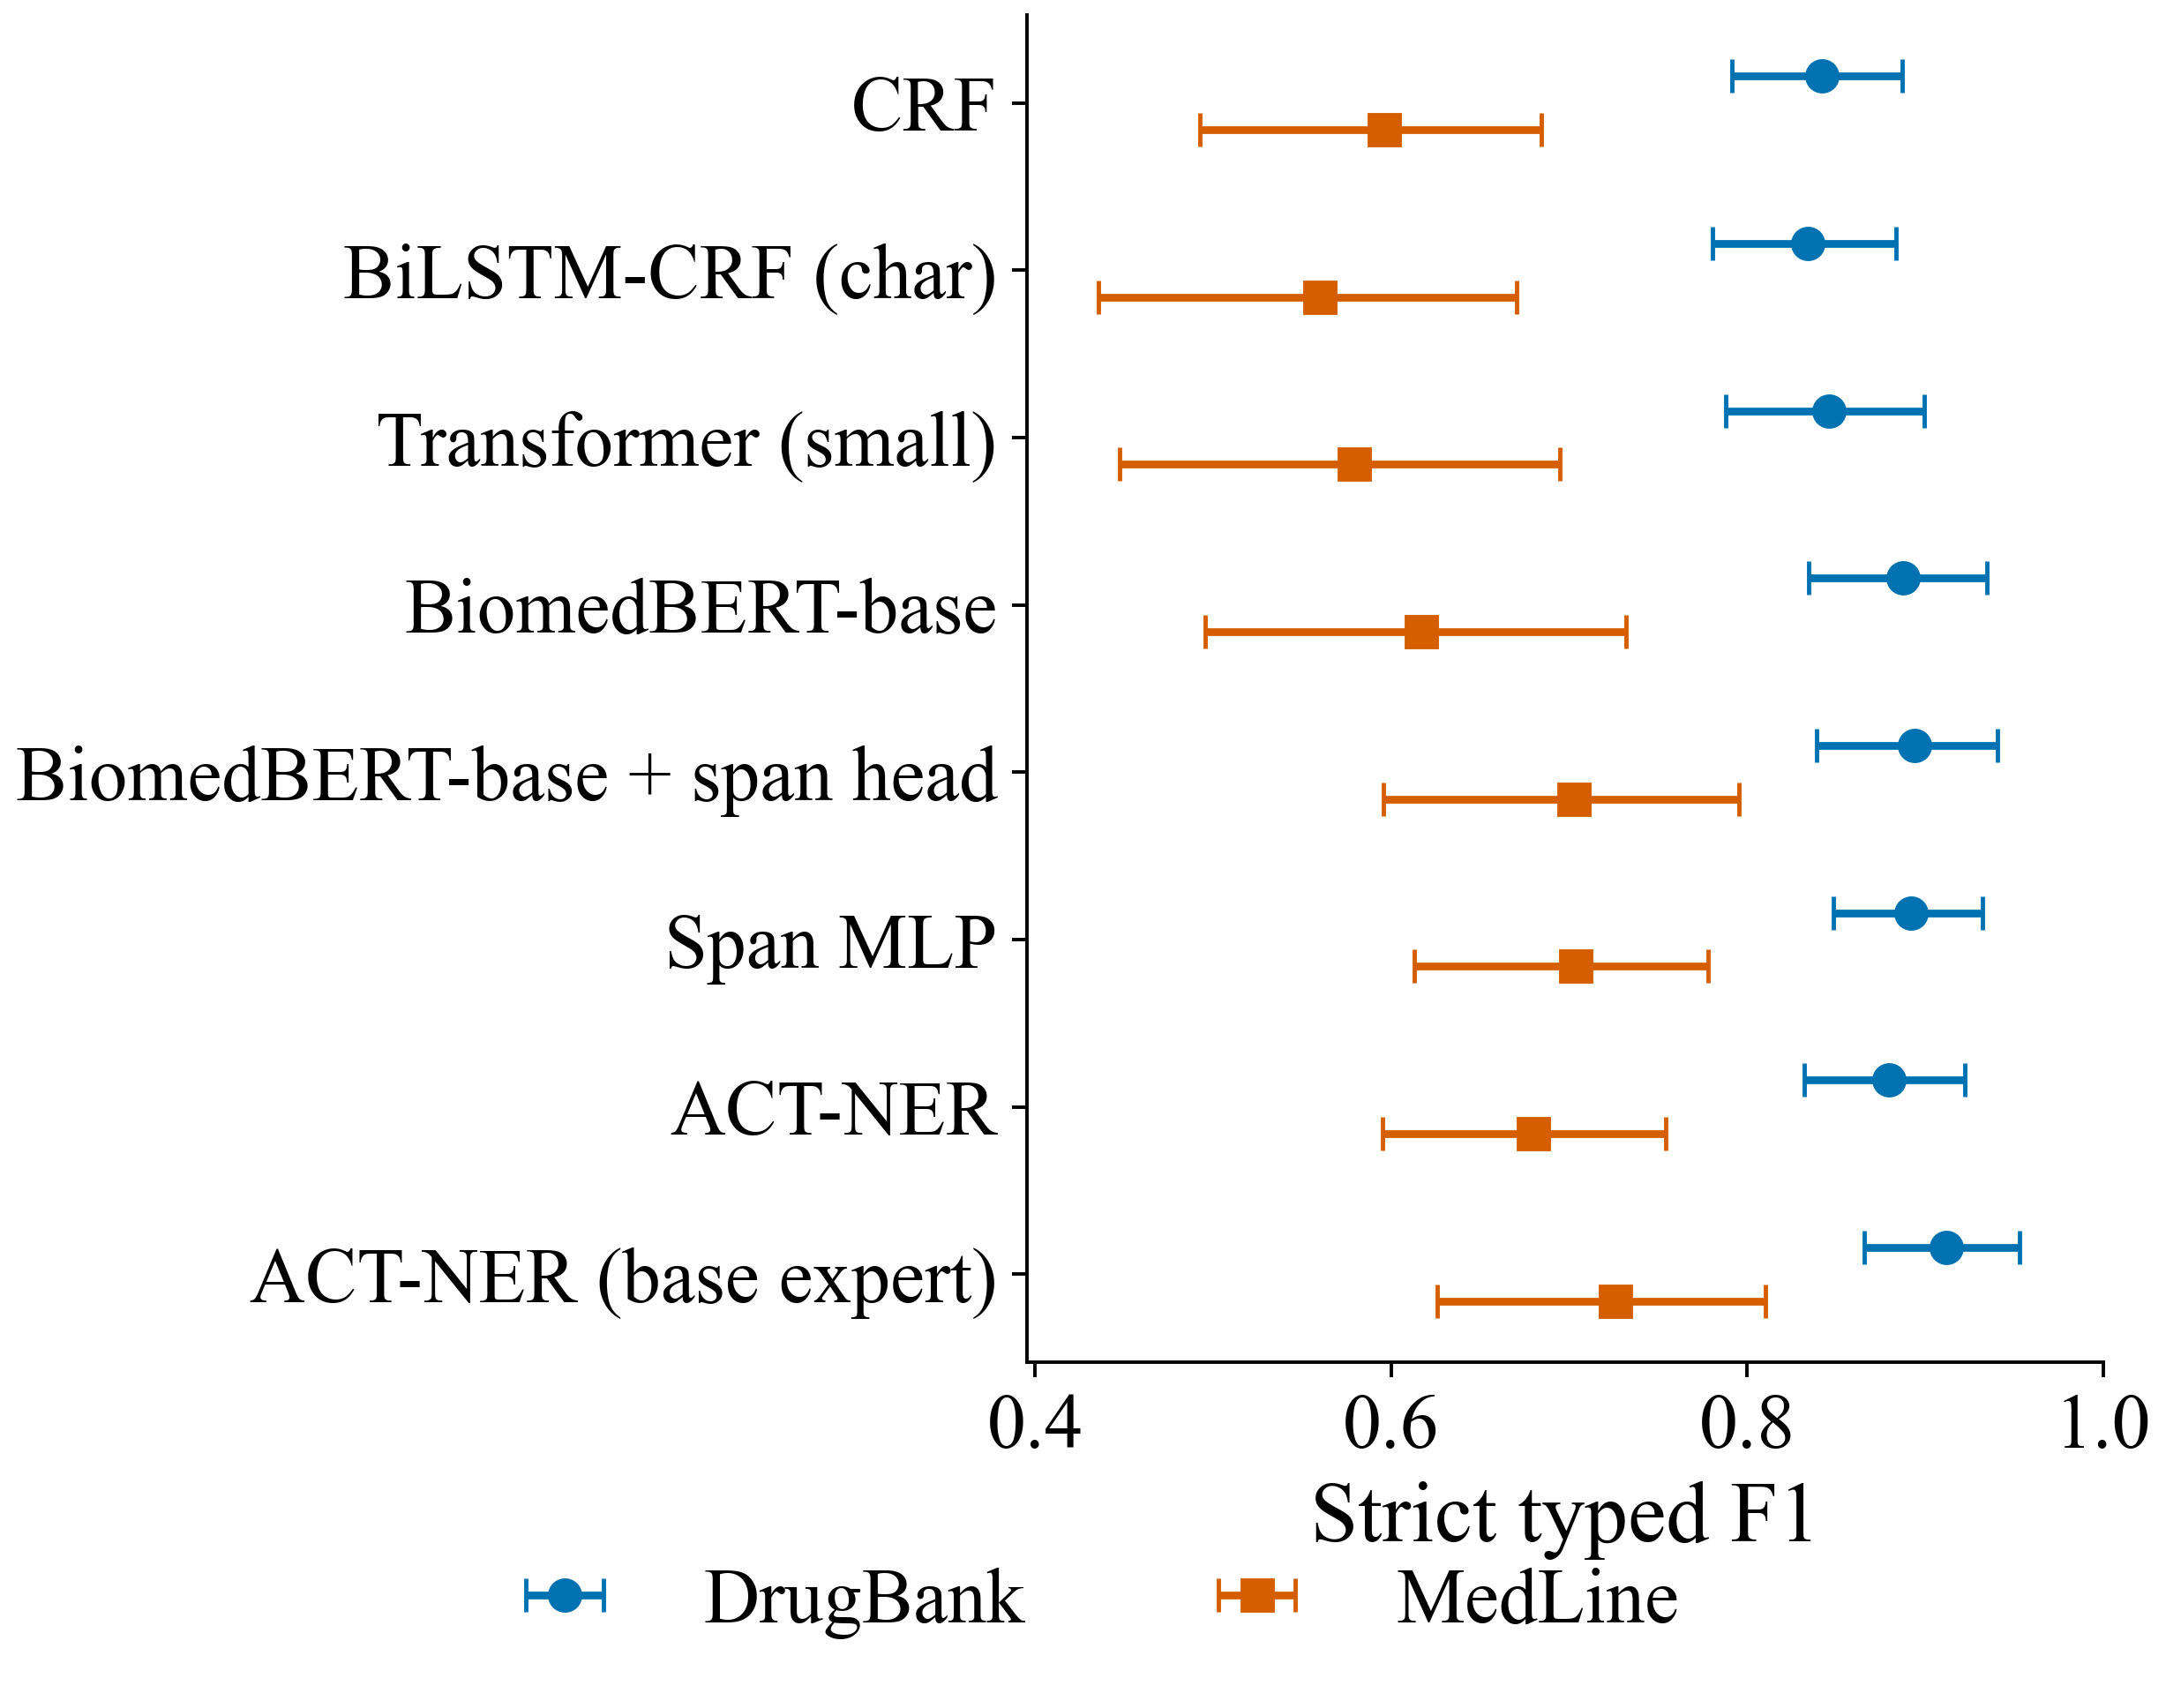

**Figure 7.3.** Strict typed F1 on the official DrugNER test set by source for the main systems of the stacking protocol (DrugBank: 54 documents, 303 gold entities; MedLine: 58 documents, 381 gold entities). Points are estimates (seed means for three-seed models) and bars 95 % cluster-bootstrap intervals.

In [105]:
FIGURE_MODELS = [(CRF_STACK, "CRF"), (CHAR_BILSTM, "BiLSTM-CRF (char)"), (TRANSFORMER_STACK, "Transformer (small)"),
                 (BASE, "BiomedBERT-base"), (SPAN_MODEL, "BiomedBERT-base + span head"), (STACKED_MLP, "Span MLP"),
                 (STACKED_ACT, "ACT-NER"), (BASE_ACT, "ACT-NER (base expert)")]
figure_source = stack_test_intervals.loc[stack_test_intervals.Metric.isin(["DrugBank typed F1", "MedLine typed F1"])
                                         & stack_test_intervals.Model.isin([name for name, _ in FIGURE_MODELS])]
save_table(figure_source, "figure_7_03_test_by_source_source")
fig, ax = plt.subplots(figsize=(7.0, 5.6))
positions = np.arange(len(FIGURE_MODELS))[::-1]
for (metric, label, marker, offset), color in zip((("DrugBank typed F1", "DrugBank", "o", 0.16),
                                                   ("MedLine typed F1", "MedLine", "s", -0.16)), OKABE_ITO):
    part = figure_source.loc[figure_source.Metric == metric].set_index("Model").loc[[name for name, _ in FIGURE_MODELS]]
    ax.errorbar(part.Estimate, positions + offset, xerr=np.vstack([part.Estimate - part["CI low"], part["CI high"] - part.Estimate]),
                fmt=marker, color=color, capsize=4, markersize=7, linewidth=1.8, label=label)
ax.set_yticks(positions, [label for _, label in FIGURE_MODELS])
ax.set_xlabel("Strict typed F1")
ax.set_xlim(max(0.0, float(figure_source["CI low"].min()) - 0.04), 1.0)
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
save_and_show(fig, "figure_7_03_test_by_source")
display(Markdown("**Figure 7.3.** Strict typed F1 on the official DrugNER test set by source for the main systems of the "
                 f"stacking protocol (DrugBank: {test_sizes['DrugBank'][0]} documents, {test_sizes['DrugBank'][1]} gold entities; "
                 f"MedLine: {test_sizes['MedLine'][0]} documents, {test_sizes['MedLine'][1]} gold entities). Points are estimates "
                 "(seed means for three-seed models) and bars 95 % cluster-bootstrap intervals."))

## B31 – External corpus BC5CDR: stability over optimizer seeds

**Question.** The external experiment above (section A37) used one optimizer seed. Is the result on the official BC5CDR test set stable over seeds?

**Method.** The two-type ACT-NER head is refitted for seeds 29 and 43 with a seed-parametrised copy of the frozen fitting routine (`external_model.fit_external_act`): the same out-of-fold Train candidates, selection documents, calibration documents, optimisation settings and frozen external experts. The copy is first checked against the stored seed-17 result. Each new head is scored once on the 500 official test documents; the stored seed-17 predictions are reused unchanged. Paired differences against the two external comparators average the three seeds inside every bootstrap replicate. The heads are fitted on BC5CDR labels, so this is an architecture-transfer experiment and not zero-shot transfer.

In [106]:
import copy

import external_model as external
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit

EXTERNAL_ACT = "ACT-NER architecture transfer"
external_directory = external._directory(PROJECT)
# The frozen protocol is read directly: its registered source paths refer to the earlier location of the project folder.
external_protocol = json.loads((external_directory / "protocol.json").read_text())
assert external_protocol["module_sha256"] == external._hash(Path(external.__file__))
external_settings = external_protocol["act"]
external_sets = external._sealed_package(external_directory / "candidate_sets.pt")["sets"]
external_frozen = external._sealed_package(PROJECT / "Predictions" / "Extended" / EXTENDED_RUN / "BC5CDR" / "frozen_evaluation.pt")["result"]
_, external_dev_gold = external._load_split(PROJECT, "validation", True)
external_selection_gold = external_dev_gold.loc[external_dev_gold.document_id.isin(external_protocol["roles"]["selection"])]


def fit_external_head(seed: int, progress=None):
    """Seed-parametrised copy of the frozen two-type head fit; nothing is written to the frozen run."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.set_num_threads(4)
    training, s = external_sets["train"], external_settings
    frame = training["frame"]
    model = external.ExternalACTNER(training["context"].shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=1e-4)
    positive = np.flatnonzero(frame.span_label.to_numpy() == 1)
    negative = np.flatnonzero(frame.span_label.to_numpy() == 0)
    hardness = (training["transformer"][:, 0] + training["crf"][:, 0]).numpy()
    negative = negative[np.argsort(-hardness[negative])[:s["hard_negative_ratio"] * len(positive)]]
    positions, rng = np.concatenate([positive, negative]), np.random.default_rng(seed)
    labels = torch.tensor(frame.type_label.to_numpy(), dtype=torch.long)
    span_target = torch.tensor(frame.span_label.to_numpy(), dtype=torch.float32)
    frequencies = torch.bincount(labels[positive], minlength=2).float()
    class_weights = frequencies.sum() / frequencies
    class_weights /= class_weights.mean()
    model.eval()
    with torch.no_grad():
        embeddings = F.normalize(model.prototype_encoder(model.context(training["context"][positive])), dim=-1)
        for label in range(2):
            model.prototypes[label].copy_(F.normalize(embeddings[labels[positive] == label].mean(0), dim=0))
    best, stale, state, chosen_threshold = -1.0, 0, None, None
    for epoch in range(1, s["epochs"] + 1):
        model.train()
        order = rng.permutation(positions)
        for start in range(0, len(order), s["batch_size"]):
            indices = order[start:start + s["batch_size"]]
            output = model(external._batch(training, indices))
            optimizer.zero_grad()
            loss = F.binary_cross_entropy_with_logits(output["span_logits"], span_target[indices])
            selected = labels[indices] >= 0
            if selected.any():
                y = labels[indices][selected]
                loss += F.cross_entropy(output["type_logits"][selected], y, weight=class_weights)
                loss += s["prototype_loss"] * (F.cross_entropy(output["prototype_logits"][selected], y)
                                               + external._contrastive(output["embedding"][selected], y))
            mean = output["dense_weights"].mean(0)
            entropy = -(output["dense_weights"] * output["dense_weights"].clamp_min(1e-8).log()).sum(-1).mean()
            loss += s["router_loss"] * (3 * mean.square().sum() - .1 * entropy)
            assert torch.isfinite(loss)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
        scores = external._score_external(model, external_sets["selection"])
        tuning = pd.DataFrame([{"threshold": threshold, **external.external_metrics(external_selection_gold, external.decode_external(scores, threshold))}
                               for threshold in external.BOUNDARY_GRID]).sort_values(
            ["Typed F1", "Boundary F1", "Typed recall", "threshold"], ascending=[False, False, False, True])
        metric = float(tuning.iloc[0]["Typed F1"])
        if progress is not None:
            progress({"seed": seed, "epoch": epoch, "selection_typed_f1": metric})
        if metric > best + 1e-6:
            best, stale, state, chosen_threshold = metric, 0, copy.deepcopy(model.state_dict()), float(tuning.iloc[0].threshold)
        else:
            stale += 1
        if stale >= s["patience"]:
            break
    model.load_state_dict(state)
    model.eval()
    calibration = external._score_external(model, external_sets["calibration"])
    target = np.array([int(label >= 0 and external.TYPES[int(label)] == predicted)
                       for label, predicted in zip(calibration.type_label, calibration.predicted_type)])
    raw = np.clip(calibration.entity_probability.to_numpy(), 1e-6, 1 - 1e-6)

    def objective(log_temperature):
        p = np.clip(expit(logit(raw) / np.exp(log_temperature)), 1e-8, 1 - 1e-8)
        return -np.mean(target * np.log(p) + (1 - target) * np.log(1 - p))

    temperature = float(np.exp(minimize_scalar(objective, bounds=(-3, 3), method="bounded").x))
    return model, chosen_threshold, temperature, best


def external_test_bundle() -> dict:
    """Candidate set of the official test documents from the sealed frozen features and the frozen external experts."""
    features = external._sealed_package(SHARED / "External" / EXTENDED_RUN / "BC5CDR" / "Features" / "test_frozen_ddi_context.pt")["documents"]
    experts = external_directory / "experts" / "full"
    pack = torch.load(experts / "contextual_head.pt", map_location="cpu", weights_only=False)
    head = nn.Linear(pack["dimension"], len(external.TAGS))
    head.load_state_dict(pack["state_dict"])
    head.eval()
    crf = joblib.load(experts / "crf.joblib")
    evidence = {}
    with torch.inference_mode():
        for key, feature in features.items():
            t = head(feature["hidden"].float()).softmax(-1).numpy()
            sequence = external._crf_features(feature["tokens"])
            tags = crf.predict_single(sequence)
            c = np.asarray([[row.get(tag, 0.) for tag in external.TAGS] for row in crf.predict_marginals_single(sequence)])
            evidence[key] = {"t": t, "c": c, "t_spans": external._tag_spans([external.TAGS[i] for i in t.argmax(-1)]),
                             "c_spans": external._tag_spans(tags),
                             "sequence_confidence": external._crf_sequence_confidence(crf, sequence, tags)}
    _, train_gold = external._load_split(PROJECT, "train", True)
    return external.build_external_candidates(features, evidence, train_gold)

In [107]:
EXTERNAL_OUTPUT = RUN_PREDICTIONS / "bc5cdr_seeds"
EXTERNAL_OUTPUT.mkdir(parents=True, exist_ok=True)
progress = display(Markdown("External corpus: preparing the frozen test candidates."), display_id=True)
external_gold, external_documents = external_frozen["entities"], external_frozen["documents"]
stored = external_frozen["predictions"][EXTERNAL_ACT]
stored_f1 = external.external_metrics(external_gold, stored)["Typed F1"]
missing = [seed for seed in SEEDS if not (EXTERNAL_OUTPUT / f"seed_{seed}.parquet").exists()]
if missing:
    test_bundle = external_test_bundle()
    # The rebuilt candidate set must reproduce the stored seed-17 predictions with the frozen seed-17 head.
    frozen_pack = torch.load(external_directory / "act_two_type.pt", map_location="cpu", weights_only=False)
    frozen_head = external.ExternalACTNER(frozen_pack["context_dimension"])
    frozen_head.load_state_dict(frozen_pack["state_dict"])
    replay = external.decode_external(external._score_external(frozen_head, test_bundle), frozen_pack["threshold"])
    replay_keys = set(replay[["document_id", "char_start", "char_end", "predicted_type"]].itertuples(index=False, name=None))
    assert replay_keys == set(stored[["document_id", "char_start", "char_end", "predicted_type"]].itertuples(index=False, name=None))
    for seed in missing:
        model, threshold, temperature, selection_f1 = fit_external_head(seed, lambda row: progress.update(Markdown(
            f"External corpus · two-type ACT-NER head, seed {row['seed']} · epoch {row['epoch']} · selection typed F1 "
            f"{row['selection_typed_f1']:.4f}")))
        prediction = external.decode_external(external._score_external(model, test_bundle), threshold)
        prediction["calibrated_confidence"] = expit(logit(np.clip(prediction.entity_probability, 1e-6, 1 - 1e-6)) / temperature)
        prediction.attrs = {}
        prediction.assign(threshold=threshold, temperature=temperature, selection_typed_f1=selection_f1).to_parquet(
            EXTERNAL_OUTPUT / f"seed_{seed}.parquet", index=False)
refit = {seed: pd.read_parquet(EXTERNAL_OUTPUT / f"seed_{seed}.parquet") for seed in SEEDS}
# The seed-parametrised copy must reproduce the stored seed-17 result before the new seeds are used.
assert abs(external.external_metrics(external_gold, refit[REFERENCE_SEED])["Typed F1"] - stored_f1) < 0.005
progress.update(Markdown("External corpus: heads of seeds 17, 29 and 43 scored on the official BC5CDR test set."))
external_predictions = {EXTERNAL_ACT: {REFERENCE_SEED: stored, **{seed: refit[seed] for seed in SEEDS if seed != REFERENCE_SEED}},
                        "Contextual BIOES": {0: external_frozen["predictions"]["Contextual BIOES"]},
                        "Linear-chain CRF": {0: external_frozen["predictions"]["Linear-chain CRF"]}}
seed_rows = []
for seed, frame in external_predictions[EXTERNAL_ACT].items():
    metrics = external.external_metrics(external_gold, frame)
    source = "stored frozen result" if seed == REFERENCE_SEED else "new fit"
    settings = refit[seed].iloc[0]
    seed_rows.append({"Seed": seed, "Origin": source, "Verifier threshold": float(settings.threshold),
                      "Temperature": float(settings.temperature), "Predicted entities": metrics["Predicted entities"],
                      "Typed F1": metrics["Typed F1"], "Boundary F1": metrics["Boundary F1"], "Macro-F1": metrics["Macro-F1"],
                      "Chemical F1": metrics["Chemical F1"], "Disease F1": metrics["Disease F1"]})
external_seed_table = pd.DataFrame(seed_rows).sort_values("Seed").reset_index(drop=True)

# Paired inference with the project procedure: document-level keys and exact-text clusters of the test documents.
groups = external._text_groups(external_documents)
bc_documents = pd.DataFrame({"document_id": external_documents.document_id.astype(str)})
bc_documents["dependency_group"] = bc_documents.document_id.map(groups)


def as_project_frame(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.assign(document_id=frame.document_id.astype(str), sentence_id=frame.document_id.astype(str))


bc_gold = as_project_frame(external_gold).assign(discontinuous=False, offset_valid=True)
bc_predictions = {name: {seed: as_project_frame(frame) for seed, frame in repeats.items()}
                  for name, repeats in external_predictions.items()}
bc_evidence = paired_evidence(bc_predictions, bc_documents, bc_gold, bc_documents,
                              [(EXTERNAL_ACT, "Contextual BIOES"), (EXTERNAL_ACT, "Linear-chain CRF")], replicates=N_RESAMPLES)
bc_paired = bc_evidence[["Comparison", "Clusters", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
    columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p", "Clusters": "Dependency clusters"})
save_table(external_seed_table, "table_7_57_bc5cdr_seed_results")
save_table(bc_paired, "table_7_58_bc5cdr_paired_three_seeds")
display_table(external_seed_table, f"Table 7.57. Official BC5CDR test set ({len(external_documents)} documents, "
              f"{len(external_gold)} gold Chemical and Disease mentions): two-type ACT-NER head for three optimizer seeds. Seed 17 "
              "is the stored frozen result of section A37; seeds 29 and 43 are new fits with identical data and settings.",
              index="Seed", digits=4)
display_table(bc_paired, "Table 7.58. Official BC5CDR test set: paired differences in strict typed F1 between the two-type "
              "ACT-NER head (mean of three seeds) and the two external comparators (95 % paired cluster-bootstrap interval; "
              "Holm-adjusted paired-randomization p, family of two).", index="Comparison", signed=("Δ typed F1",),
              pvalues=("Holm-adjusted p",))
values = external_seed_table["Typed F1"]
bc = bc_paired.set_index("Comparison")
note(f"**Interpretation.** Over three optimizer seeds the two-type ACT-NER head reaches a strict typed F1 of "
     f"{values.mean():.4f} ± {values.std(ddof=1):.4f} (SD) on the official BC5CDR test set (range {values.min():.4f}–"
     f"{values.max():.4f}). The paired differences are {fmt_signed(bc.iloc[0]['Δ typed F1'])} "
     f"[{fmt_num(bc.iloc[0]['CI low'])}, {fmt_num(bc.iloc[0]['CI high'])}] against the contextual BIOES head and "
     f"{fmt_signed(bc.iloc[1]['Δ typed F1'])} [{fmt_num(bc.iloc[1]['CI low'])}, {fmt_num(bc.iloc[1]['CI high'])}] against the "
     f"external CRF. The external result is therefore stable over seeds. Its scope remains limited: the comparators are the "
     f"two experts that feed the head (a frozen-encoder tagger and a CRF), not a fine-tuned base-size encoder, and the head is "
     f"fitted on BC5CDR labels.")

External corpus: heads of seeds 17, 29 and 43 scored on the official BC5CDR test set.

**Table 7.57. Official BC5CDR test set (500 documents, 9809 gold Chemical and Disease mentions): two-type ACT-NER head for three optimizer seeds. Seed 17 is the stored frozen result of section A37; seeds 29 and 43 are new fits with identical data and settings.**

,Origin,Verifier threshold,Temperature,Predicted entities,Typed F1,Boundary F1,Macro-F1,Chemical F1,Disease F1
Seed,,,,,,,,,
17,stored frozen result,0.5000,1.2204,9520,0.8483,0.8517,0.8410,0.9025,0.7794
29,new fit,0.7000,1.0198,9237,0.8432,0.8456,0.8372,0.8977,0.7768
43,new fit,0.5000,1.1749,9566,0.8502,0.8525,0.8446,0.8993,0.7898


**Table 7.58. Official BC5CDR test set: paired differences in strict typed F1 between the two-type ACT-NER head (mean of three seeds) and the two external comparators (95 % paired cluster-bootstrap interval; Holm-adjusted paired-randomization p, family of two).**

,Dependency clusters,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,,
ACT-NER architecture transfer − Contextual BIOES,499,+0.1640,0.1539,0.1742,< 0.001
ACT-NER architecture transfer − Linear-chain CRF,499,+0.0773,0.0653,0.0897,< 0.001


**Interpretation.** Over three optimizer seeds the two-type ACT-NER head reaches a strict typed F1 of 0.8472 ± 0.0036 (SD) on the official BC5CDR test set (range 0.8432–0.8502). The paired differences are +0.1640 [0.1539, 0.1742] against the contextual BIOES head and +0.0773 [0.0653, 0.0897] against the external CRF. The external result is therefore stable over seeds. Its scope remains limited: the comparators are the two experts that feed the head (a frozen-encoder tagger and a CRF), not a fine-tuned base-size encoder, and the head is fitted on BC5CDR labels.

# Part C – Subgroups, seed variation and data flow

## C01 – Validation subgroups under the stacking protocol

**Question.** Do the subgroup results (lexical novelty and mention length) hold when every model fits Train labels only?

**Method.** The subgroup definitions of the original analysis are kept: a mention is *seen* when its normalized surface form occurs in the Train annotations, and *multi-token* when it covers more than one WordPiece token. Gold and predicted mentions are restricted by the same flag. No model of the stacking protocol fits a Validation label, so the Train reference is the supervision reference of every model. Intervals are percentile 95 % cluster-bootstrap intervals (5000 draws); three-seed models are seed means. The differences on unseen mentions use the paired procedure of section B05. Results by source are in Table 7.31.

In [108]:
token_spans = {sentence_id: part[["char_start", "char_end"]].to_numpy()
               for sentence_id, part in validation.tokens.groupby("sentence_id")}


def subgroup_flags(frame: pd.DataFrame) -> pd.DataFrame:
    """Seen (Train reference) and multi-token flags, defined as in the original subgroup analysis."""
    seen = frame.entity_text.map(normalize_surface).isin(train_forms).to_numpy(bool)
    multi = np.array([int(((token_spans[s][:, 1] > a) & (token_spans[s][:, 0] < b)).sum()) > 1
                      for s, a, b in zip(frame.sentence_id, frame.char_start, frame.char_end)], dtype=bool)
    return frame.assign(seen=seen, multi_token=multi)


SUBGROUP_MODELS = (CRF_STACK, TRANSFORMER_STACK, BASE, SPANNER, STACKED_MLP, STACKED_ACT)
SUBGROUPS = (("Seen", "seen", True), ("Unseen", "seen", False),
             ("Single-token", "multi_token", False), ("Multi-token", "multi_token", True))
subgroup_gold = subgroup_flags(validation.gold)
subgroup_predictions = {name: {seed: subgroup_flags(frame) for seed, frame in stack_validation[name].items()}
                        for name in SUBGROUP_MODELS}

subgroup_long = []
for name in SUBGROUP_MODELS:
    for label, column, value in SUBGROUPS:
        gold_part = subgroup_gold.loc[subgroup_gold[column] == value]
        parts = {seed: frame.loc[frame[column] == value] for seed, frame in subgroup_predictions[name].items()}
        estimate, low, high = f1_with_interval(stacked_counts(validation, parts, gold_part), validation_weights)
        subgroup_long.append({"Model": name, "Subgroup": label, "Gold mentions": len(gold_part),
                              "Typed F1": estimate, "CI low": low, "CI high": high})
subgroup_long = pd.DataFrame(subgroup_long)
save_table(subgroup_long, "table_7_60_stacking_subgroups")
subgroup_wide = (subgroup_long.assign(cell=[fmt_interval(*values) for values in
                                            subgroup_long[["Typed F1", "CI low", "CI high"]].itertuples(index=False)])
                 .pivot(index="Model", columns="Subgroup", values="cell")
                 .reindex(index=SUBGROUP_MODELS, columns=[g[0] for g in SUBGROUPS]).reset_index())
subgroup_sizes = subgroup_long.drop_duplicates("Subgroup").set_index("Subgroup")["Gold mentions"]
display_table(subgroup_wide, "Table 7.60. Validation subgroups under the stacking protocol: strict typed F1 "
              "[95 % cluster-bootstrap interval] on mentions that are seen or unseen relative to the Train annotations "
              "and on single-token or multi-token mentions. Gold mentions per subgroup: "
              + "; ".join(f"{label} n = {int(subgroup_sizes[label])}" for label, _, _ in SUBGROUPS)
              + ". Every model fits Train labels only; three-seed models are seed means.", index="Model")

unseen_gold = subgroup_gold.loc[~subgroup_gold.seen]
unseen_parts = {name: {seed: frame.loc[~frame.seen] for seed, frame in repeats.items()}
                for name, repeats in subgroup_predictions.items()}
unseen_stack = paired_evidence(unseen_parts, validation.sentences, unseen_gold, validation.documents,
                               [(STACKED_ACT, name) for name in SUBGROUP_MODELS[:-1]], replicates=N_RESAMPLES)
unseen_stack = unseen_stack[["Comparison", "Micro-F1 difference", "CI low", "CI high", "Micro-F1 Holm p"]].rename(
    columns={"Micro-F1 difference": "Δ typed F1", "Micro-F1 Holm p": "Holm-adjusted p"})
save_table(unseen_stack, "table_7_61_stacking_unseen_paired")
display_table(unseen_stack, "Table 7.61. Paired differences in strict typed F1 on Validation mentions unseen relative "
              f"to the Train annotations (n = {len(unseen_gold)} gold mentions) under the stacking protocol: 95 % paired "
              f"cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of {len(unseen_stack)}).",
              index="Comparison", signed=("Δ typed F1",), pvalues=("Holm-adjusted p",))
cell = subgroup_long.set_index(["Model", "Subgroup"])["Typed F1"]
supported = unseen_stack.loc[(unseen_stack["CI low"] > 0) & (unseen_stack["Holm-adjusted p"] < 0.05), "Comparison"]
best = {label: cell.xs(label, level="Subgroup").idxmax() for label, _, _ in SUBGROUPS}
note(f"**Interpretation.** With Train labels only, ACT-NER reaches {cell[(STACKED_ACT, 'Unseen')]:.4f} on the "
     f"{int(subgroup_sizes['Unseen'])} unseen mentions, against {cell[(TRANSFORMER_STACK, 'Unseen')]:.4f} for the "
     f"Biomedical Transformer, {cell[(CRF_STACK, 'Unseen')]:.4f} for the CRF and {cell[(BASE, 'Unseen')]:.4f} for "
     f"BiomedBERT-base; on multi-token mentions the values are {cell[(STACKED_ACT, 'Multi-token')]:.4f}, "
     f"{cell[(TRANSFORMER_STACK, 'Multi-token')]:.4f}, {cell[(CRF_STACK, 'Multi-token')]:.4f} and "
     f"{cell[(BASE, 'Multi-token')]:.4f}. A positive ACT-NER difference on unseen mentions with an interval above zero "
     f"and Holm-adjusted p < 0.05 holds for {len(supported)} of {len(unseen_stack)} comparisons"
     + (f" ({'; '.join(supported)})." if len(supported) else ".")
     + " The highest point estimate belongs to "
     + "; ".join(f"{model} ({label})" for label, model in best.items()) + ".")

**Table 7.60. Validation subgroups under the stacking protocol: strict typed F1 [95 % cluster-bootstrap interval] on mentions that are seen or unseen relative to the Train annotations and on single-token or multi-token mentions. Gold mentions per subgroup: Seen n = 2208; Unseen n = 707; Single-token n = 1174; Multi-token n = 1741. Every model fits Train labels only; three-seed models are seed means.**

Subgroup,Seen,Unseen,Single-token,Multi-token
Model,,,,
"Linear-chain CRF (Train, internal selection)","0.9425 [0.9241, 0.9575]","0.6028 [0.5225, 0.6779]","0.8977 [0.8641, 0.9267]","0.8414 [0.7997, 0.8759]"
"Biomedical Transformer (Train, internal selection)","0.9271 [0.9033, 0.9489]","0.6784 [0.6013, 0.7435]","0.8637 [0.8223, 0.8973]","0.8608 [0.8299, 0.8890]"
BiomedBERT-base (full fine-tuning),"0.9519 [0.9325, 0.9671]","0.7716 [0.7017, 0.8326]","0.9117 [0.8792, 0.9392]","0.9033 [0.8737, 0.9277]"
SpanNER-style combiner (stacking),"0.9445 [0.9269, 0.9585]","0.7720 [0.6985, 0.8308]","0.9148 [0.8817, 0.9413]","0.8963 [0.8686, 0.9191]"
Parameter-matched span MLP (stacking),"0.9449 [0.9251, 0.9609]","0.7506 [0.6849, 0.8041]","0.9080 [0.8750, 0.9352]","0.8936 [0.8645, 0.9174]"
ACT-NER (stacking),"0.9453 [0.9266, 0.9607]","0.7679 [0.7025, 0.8200]","0.9124 [0.8809, 0.9378]","0.8970 [0.8685, 0.9197]"


**Table 7.61. Paired differences in strict typed F1 on Validation mentions unseen relative to the Train annotations (n = 707 gold mentions) under the stacking protocol: 95 % paired cluster-bootstrap interval and Holm-adjusted paired-randomization p (family of 5).**

,Δ typed F1,CI low,CI high,Holm-adjusted p
Comparison,,,,
"ACT-NER (stacking) − Linear-chain CRF (Train, internal selection)",+0.1651,0.0928,0.2353,0.002
"ACT-NER (stacking) − Biomedical Transformer (Train, internal selection)",+0.0894,0.0489,0.1322,< 0.001
ACT-NER (stacking) − BiomedBERT-base (full fine-tuning),−0.0038,−0.0570,0.0533,> 0.999
ACT-NER (stacking) − SpanNER-style combiner (stacking),−0.0041,−0.0332,0.0275,> 0.999
ACT-NER (stacking) − Parameter-matched span MLP (stacking),+0.0173,0.0004,0.0344,0.187


**Interpretation.** With Train labels only, ACT-NER reaches 0.7679 on the 707 unseen mentions, against 0.6784 for the Biomedical Transformer, 0.6028 for the CRF and 0.7716 for BiomedBERT-base; on multi-token mentions the values are 0.8970, 0.8608, 0.8414 and 0.9033. A positive ACT-NER difference on unseen mentions with an interval above zero and Holm-adjusted p < 0.05 holds for 2 of 5 comparisons (ACT-NER (stacking) − Linear-chain CRF (Train, internal selection); ACT-NER (stacking) − Biomedical Transformer (Train, internal selection)). The highest point estimate belongs to BiomedBERT-base (full fine-tuning) (Seen); SpanNER-style combiner (stacking) (Unseen); SpanNER-style combiner (stacking) (Single-token); BiomedBERT-base (full fine-tuning) (Multi-token).

## C02 – Variation over optimizer seeds for every model

**Question.** How much does strict typed F1 vary over the optimizer seeds of each baseline and of each stacked system?

**Method.** For every system fitted with seeds 17, 29 and 43, strict typed F1 is computed per seed on the official DrugNER test set, on the text-disjoint reserve and, for the systems scored there, on Validation. The mean, the sample standard deviation and the range over seeds are reported. The linear-chain CRF is deterministic and has a single fit, so it is not listed. The spread describes optimisation noise only; sampling uncertainty is given by the cluster-bootstrap intervals of the result tables.

In [109]:
def seed_spread(population: Population, repeats: dict[int, pd.DataFrame]) -> dict:
    """Mean, sample standard deviation and range of the strict typed F1 of the seeds of one model."""
    scores = f1_counts(stacked_counts(population, repeats).sum(axis=1))
    return {"Seeds": len(scores), "Mean typed F1": float(scores.mean()), "SD over seeds": float(scores.std(ddof=1)),
            "Minimum": float(scores.min()), "Maximum": float(scores.max())}


seed_sources = (("Official DrugNER test", test, stack_test),
                ("Reserve (text-disjoint)", reserve, {name: restrict(repeats, reserve) for name, repeats in stack_reserve.items()}),
                ("Validation", validation, {name: stack_validation[name] for name in SUBGROUP_MODELS}))
seed_rows = [{"Population": label, "Model": name, **seed_spread(population, repeats)}
             for label, population, predictions in seed_sources
             for name, repeats in predictions.items() if len(repeats) > 1]
seed_table = pd.DataFrame(seed_rows)
assert set(seed_table.Seeds) == {len(SEEDS)}
frozen_part = seed_table.loc[seed_table.Population != "Validation"]
validation_part = seed_table.loc[seed_table.Population == "Validation"].drop(columns="Population")
save_table(frozen_part, "table_7_62_seed_variation_test_reserve")
save_table(validation_part, "table_7_63_seed_variation_validation")
display_table(frozen_part, "Table 7.62. Variation of strict typed F1 over the three optimizer seeds (17, 29, 43) on the "
              "official DrugNER test set and on the text-disjoint reserve: mean, sample standard deviation and range. "
              "The deterministic linear-chain CRF has a single fit and is not listed.", index=["Population", "Model"])
display_table(validation_part, "Table 7.63. Variation of strict typed F1 over the three optimizer seeds on Validation "
              "(held-out folds; cross-fitted selection for the stacked systems).", index="Model")
largest = seed_table.loc[seed_table["SD over seeds"].idxmax()]
act_rows = seed_table.loc[seed_table.Model == STACKED_ACT].set_index("Population")["SD over seeds"]
note(f"**Interpretation.** The standard deviation over seeds lies between {seed_table['SD over seeds'].min():.4f} and "
     f"{seed_table['SD over seeds'].max():.4f}; the largest value belongs to {largest['Model']} on "
     f"{largest['Population']}. For the stacked ACT-NER it is {act_rows['Validation']:.4f} on Validation, "
     f"{act_rows['Official DrugNER test']:.4f} on the official test set and {act_rows['Reserve (text-disjoint)']:.4f} "
     f"on the reserve. Seed variation is larger on the official test set (112 documents) than on the reserve "
     f"(176 documents) for {int((frozen_part.pivot(index='Model', columns='Population', values='SD over seeds').pipe(lambda t: t['Official DrugNER test'] > t['Reserve (text-disjoint)'])).sum())} "
     f"of {frozen_part.Model.nunique()} systems, and it is small relative to the document-level intervals of the result "
     "tables in every case.")

**Table 7.62. Variation of strict typed F1 over the three optimizer seeds (17, 29, 43) on the official DrugNER test set and on the text-disjoint reserve: mean, sample standard deviation and range. The deterministic linear-chain CRF has a single fit and is not listed.**

Seeds  \
Population              Model                                                             
Official DrugNER test   BiLSTM-CRF with character features                            3   
                        Biomedical Transformer (Train, internal selection)            3   
                        BiomedBERT-base (full fine-tuning)                            3   
                        BiomedBERT-base + span head (full fine-tuning)                3   
                        SpanNER-style combiner (stacking)                             3   
                        Parameter-matched span MLP (stacking)                         3   
                        ACT-NER (stacking)                                            3   
                        SpanNER-style combiner, BiomedBERT-base expert (stacking)     3   
                        Span MLP, BiomedBERT-base expert (stacking)                   3   
                        ACT-NER, BiomedBERT-base expert (stacking)                    3   
Reserve (text-disjoint) BiLSTM-CRF with character features                            3   
                        Biomedical Transformer (Train, internal selection)            3   
                        BiomedBERT-base (full fine-tuning)                            3   
                        BiomedBERT-base + span head (full fine-tuning)                3   
                        SpanNER-style combiner (stacking)                             3   
                        Parameter-matched span MLP (stacking)                         3   
                        ACT-NER (stacking)                                            3   
                        SpanNER-style combiner, BiomedBERT-base expert (stacking)     3   
                        Span MLP, BiomedBERT-base expert (stacking)                   3   
                        ACT-NER, BiomedBERT-base expert (stacking)                    3   

                                                                                  Mean typed F1  \
Population              Model                                                                     
Official DrugNER test   BiLSTM-CRF with character features                               0.6775   
                        Biomedical Transformer (Train, internal selection)               0.6938   
                        BiomedBERT-base (full fine-tuning)                               0.7331   
                        BiomedBERT-base + span head (full fine-tuning)                   0.7874   
                        SpanNER-style combiner (stacking)                                0.7646   
                        Parameter-matched span MLP (stacking)                            0.7903   
                        ACT-NER (stacking)                                               0.7711   
                        SpanNER-style combiner, BiomedBERT-base expert (stacking)        0.7839   
                        Span MLP, BiomedBERT-base expert (stacking)                      0.7990   
                        ACT-NER, BiomedBERT-base expert (stacking)                       0.8075   
Reserve (text-disjoint) BiLSTM-CRF with character features                               0.8639   
                        Biomedical Transformer (Train, internal selection)               0.8540   
                        BiomedBERT-base (full fine-tuning)                               0.8833   
                        BiomedBERT-base + span head (full fine-tuning)                   0.9140   
                        SpanNER-style combiner (stacking)                                0.8929   
                        Parameter-matched span MLP (stacking)                            0.9006   
                        ACT-NER (stacking)                                               0.8925   
                        SpanNER-style combiner, BiomedBERT-base expert (stacking)        0.9182   
                        Span MLP, BiomedBERT-base expert (stacking)                      0.9186   


**Table 7.63. Variation of strict typed F1 over the three optimizer seeds on Validation (held-out folds; cross-fitted selection for the stacked systems).**

,Seeds,Mean typed F1,SD over seeds,Minimum,Maximum
Model,,,,,
"Biomedical Transformer (Train, internal selection)",3,0.8620,0.0050,0.8579,0.8676
BiomedBERT-base (full fine-tuning),3,0.9067,0.0025,0.9049,0.9096
SpanNER-style combiner (stacking),3,0.9037,0.0016,0.9021,0.9053
Parameter-matched span MLP (stacking),3,0.8994,0.0024,0.8974,0.9021
ACT-NER (stacking),3,0.9032,0.0052,0.9000,0.9092


**Interpretation.** The standard deviation over seeds lies between 0.0006 and 0.0132; the largest value belongs to BiLSTM-CRF with character features on Official DrugNER test. For the stacked ACT-NER it is 0.0052 on Validation, 0.0021 on the official test set and 0.0017 on the reserve. Seed variation is larger on the official test set (112 documents) than on the reserve (176 documents) for 9 of 10 systems, and it is small relative to the document-level intervals of the result tables in every case.

## C03 – Data flow of the stacking protocol

Show which documents each component fits, which documents are used only for selection and calibration, and which are only scored, with the document counts of Table 7.1.

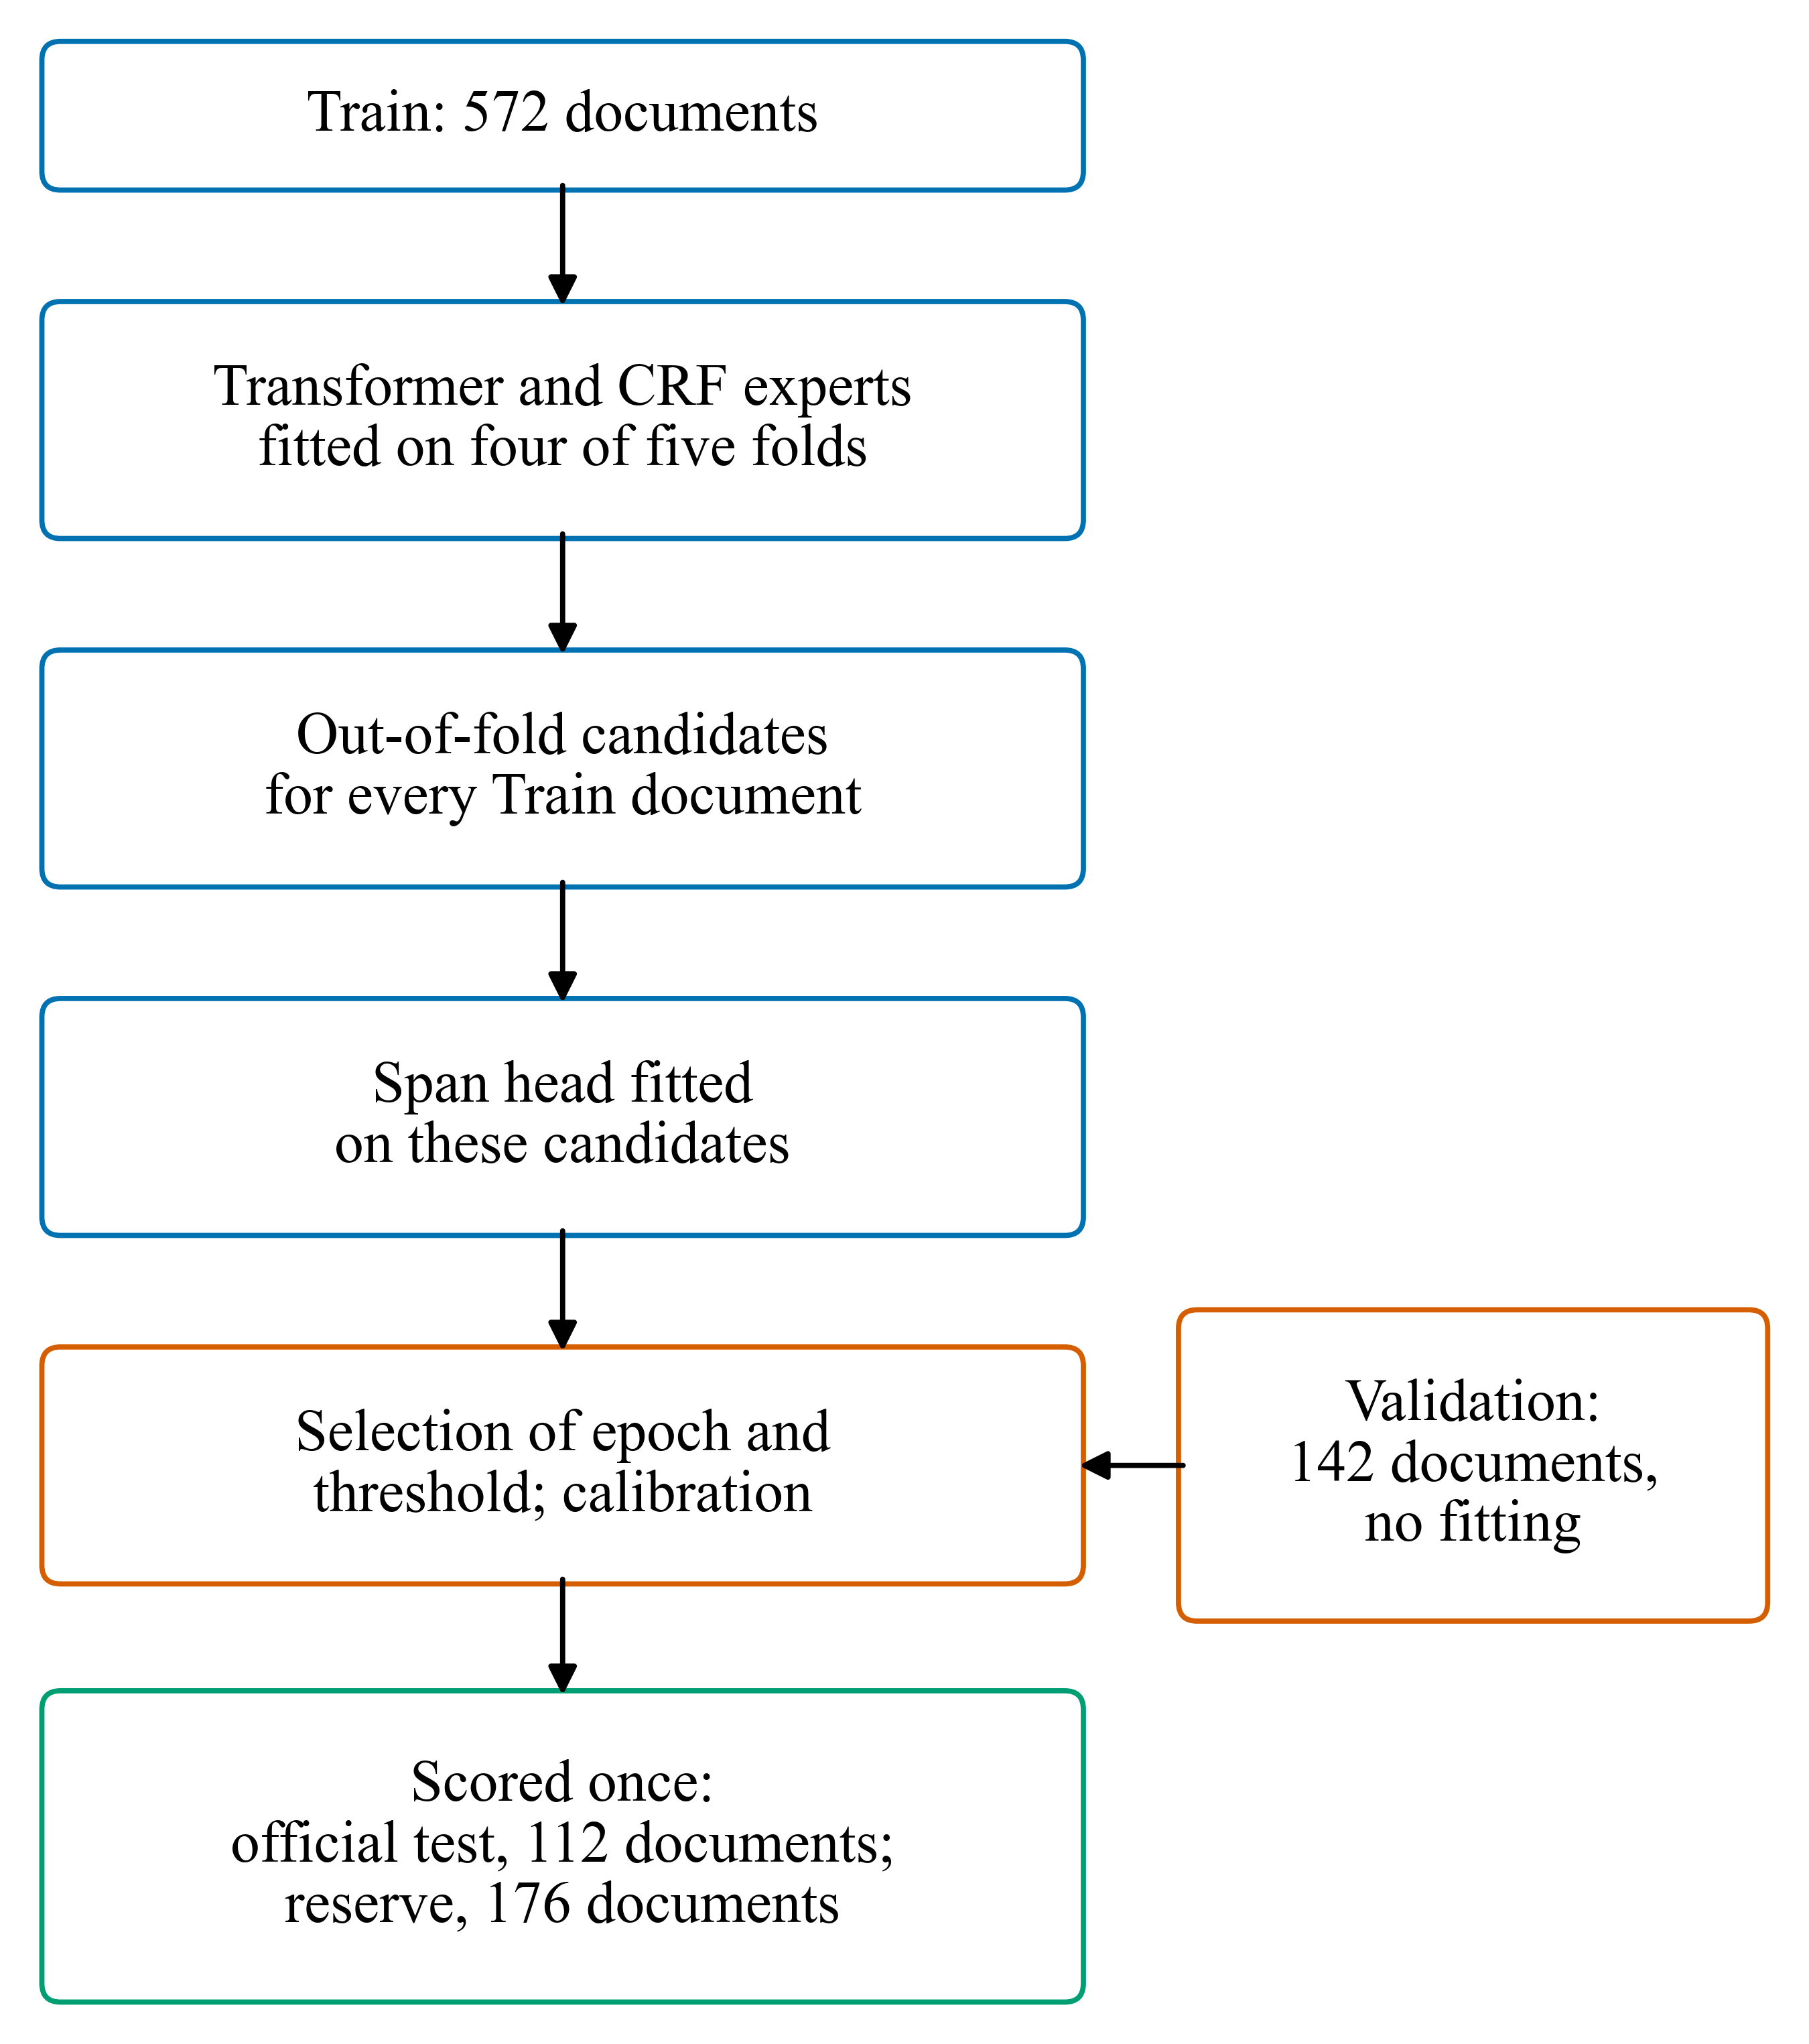

**Figure 7.4.** Data flow of the stacking protocol. Blue boxes use Train labels for fitting: the Transformer and CRF experts are fitted on four of five Train folds and produce candidates for the held-out fold, and the span head is fitted on these out-of-fold candidates. The 142 Validation documents (orange) are used only to select the epoch and the verifier threshold and to fit the post-hoc confidence map. The frozen model is then scored once on the official DrugNER test set (112 documents) and on the text-disjoint reserve (176 documents) (green). Baselines fit the same 572 Train documents.

In [110]:
from matplotlib.patches import FancyBboxPatch

n_train, n_validation = len(train.documents), len(validation.documents)
n_test, n_reserve = len(test.documents), len(reserve.documents)
fig, ax = plt.subplots(figsize=(7.7, 8.7))
ax.set_xlim(0, 7.7)
ax.set_ylim(0, 8.7)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
MAIN_X, MAIN_W, SIDE_X, SIDE_W = 0.15, 4.45, 5.05, 2.5


def box(x: float, y: float, width: float, height: float, text: str, colour: str) -> None:
    ax.add_patch(FancyBboxPatch((x, y), width, height, boxstyle="round,pad=0.02,rounding_size=0.08",
                                linewidth=1.6, edgecolor=colour, facecolor="white"))
    ax.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=FONT_MIN_PT, linespacing=1.15)


def arrow(start: tuple[float, float], end: tuple[float, float]) -> None:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", linewidth=1.6, color="black",
                                                           shrinkA=0, shrinkB=0, mutation_scale=18))


centre = MAIN_X + MAIN_W / 2
steps = [(7.95, 0.60, f"Train: {n_train} documents", OKABE_ITO[0]),
         (6.45, 0.98, "Transformer and CRF experts\nfitted on four of five folds", OKABE_ITO[0]),
         (4.95, 0.98, "Out-of-fold candidates\nfor every Train document", OKABE_ITO[0]),
         (3.45, 0.98, "Span head fitted\non these candidates", OKABE_ITO[0]),
         (1.95, 0.98, "Selection of epoch and\nthreshold; calibration", OKABE_ITO[1]),
         (0.15, 1.30, f"Scored once:\nofficial test, {n_test} documents;\nreserve, {n_reserve} documents", OKABE_ITO[2])]
for y, height, text, colour in steps:
    box(MAIN_X, y, MAIN_W, height, text, colour)
for (upper_y, _, _, _), (lower_y, lower_height, _, _) in zip(steps[:-1], steps[1:]):
    arrow((centre, upper_y), (centre, lower_y + lower_height))
selection_y, selection_height = steps[4][0], steps[4][1]
box(SIDE_X, selection_y - 0.16, SIDE_W, selection_height + 0.32, f"Validation:\n{n_validation} documents,\nno fitting", OKABE_ITO[1])
arrow((SIDE_X, selection_y + selection_height / 2), (MAIN_X + MAIN_W, selection_y + selection_height / 2))
save_and_show(fig, "figure_7_04_stacking_data_flow")
note("**Figure 7.4.** Data flow of the stacking protocol. Blue boxes use Train labels for fitting: the Transformer and "
     "CRF experts are fitted on four of five Train folds and produce candidates for the held-out fold, and the span head "
     f"is fitted on these out-of-fold candidates. The {n_validation} Validation documents (orange) are used only to "
     "select the epoch and the verifier threshold and to fit the post-hoc confidence map. The frozen model is then "
     f"scored once on the official DrugNER test set ({n_test} documents) and on the text-disjoint reserve "
     f"({n_reserve} documents) (green). Baselines fit the same {n_train} Train documents.")